# Roadkill · Evaluación global del frontend

Un solo cuaderno para calcular, contrastar y explicar los resultados de la aplicación:
Random Forest, MLP, LSTM, SimpleRNN, modelos clásicos, modelos de conteo y NLP.

**La unidad de clasificación es una celda y un mes.** Una probabilidad de presencia de
atropellos registrados no es la probabilidad de accidente de un viaje individual.

El cuaderno contiene código de evaluación y código de entrenamiento. Diferencia tres situaciones:

| Situación | Qué demuestra |
|---|---|
| Recalculado desde predicciones individuales | Reproduce la métrica del artefacto que usa el frontend. |
| Reentrenamiento con datos originales | Ejecuta el experimento disponible; informa de diferencias con la ejecución publicada. |
| Resultado histórico pendiente | Conserva la referencia y el código correspondiente, sin afirmar una comprobación que no se ha realizado. |

Las salidas incluidas en esta entrega corresponden a la evaluación de los CSV reales de la
aplicación. Los entrenamientos completos requieren acceso a los datasets de tu proyecto.
No se han sustituido esos datasets por datos sintéticos.

## 0 · Ejecución y configuración

1. Guarda este notebook en `notebooks/escocia/` de la copia del repositorio compartido.
   El cargador encuentra la raíz subiendo dos niveles; también funciona si el kernel arranca
   en la raíz del repositorio o en `notebooks/`. No hay rutas de usuario fijadas en el código.
2. No necesita una ruta de tu ordenador ni otro notebook. Busca los datasets en `Datos/`
   de esa raíz. Si no tiene los datasets locales,
   se descargarán del mismo servidor del proyecto y quedarán en una caché de su equipo.
3. El acceso conserva `cargar_dataset` / `cargar_archivo`: **local → servidor del proyecto → caché**.
   Mantiene los alias y el endpoint `/datasets/<nombre>` utilizados por los notebooks anteriores.
   Lee `scripts/pipeline/config.py` o las variables `IA_DATA_SERVER_URL` / `IA_DATA_API_TOKEN`
   cuando existen. Si falta la URL, la solicita al descargar el primer dataset.
   Si el servidor exige un token, lo solicita con entrada privada; no se guarda en el notebook.
4. Ejecuta las celdas en orden. Por defecto se ejecutan también los entrenamientos.
   Pon `REENTRENAR = False` para verificar solo los artefactos guardados, sin TensorFlow ni acceso remoto.
5. Las nuevas predicciones y el informe de concordancia se guardan en `artifacts/evaluacion_global_frontend/`.
   El cuaderno no sustituye automáticamente los resultados de la aplicación.

Dependencias para evaluación: `numpy pandas scikit-learn matplotlib nbformat pyproj astral`.
Para entrenamiento: añade `tensorflow statsmodels joblib xgboost requests`.
Para NLP: añade `nltk beautifulsoup4 pypdf wordcloud` (Crawl4AI y gensim son opcionales).
Instálalas en el **mismo kernel** con `%pip install ...` si faltan; reinícialo después.

El entrenamiento multimodelo puede tardar bastante. `QUICK_RUN=True` reduce epochs de las redes
y sirve para comprobar el flujo; sus resultados no prueban superioridad ni paridad histórica.

In [1]:
from __future__ import annotations
from pathlib import Path
from types import SimpleNamespace
from typing import Any
from time import perf_counter
import os, io, json, zipfile, base64, hashlib, platform, math
import importlib.metadata as mdpkg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, accuracy_score, balanced_accuracy_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    mean_absolute_error, mean_squared_error, r2_score, mean_poisson_deviance,
    silhouette_score, adjusted_rand_score
)

DATA_SERVER_URL_OVERRIDE = None  # Opcional: URL compartida del servidor, https://...; nunca una ruta personal.
FRONTEND_SOURCE_OVERRIDE_GLOBAL = None  # Opcional: carpeta data de la app o ZIP de la app.
MLP_PREDICTIONS_OVERRIDE = None  # CSV de la ejecución publicada del capítulo 8, si lo tienes.
COMMON_PREDICTIONS_OVERRIDE = None  # predicciones_comunes_2017.csv de la comparación reducida.
TEMPORAL_VALIDATION_OVERRIDE = None  # CSV de probabilidades originales de validation 2016.
TEMPORAL_HORIZON3_OVERRIDE = None  # CSV de probabilidades originales de test con horizonte 3 meses.
REENTRENAR = os.getenv('ROADKILL_REENTRENAR', '1') == '1'
QUICK_RUN_GLOBAL = False
EJECUTAR_RF = REENTRENAR
EJECUTAR_NEURONALES = REENTRENAR
EJECUTAR_COMPARACION = REENTRENAR
EJECUTAR_NLP = REENTRENAR
BOOTSTRAP_SAMPLES_GLOBAL = 250  # La petición del Laboratorio usa 250.
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
GLOBAL_CHECKS = []
GLOBAL_TABLES = {}
GLOBAL_TRAINING = {}
GLOBAL_CELL_DISPLAYS = {}
GLOBAL_CATALOG_RECALCULATED = {}
GLOBAL_DISPLAY = display
def global_capture_display(*args, **kwargs):
    for obj in args:
        if isinstance(obj, pd.DataFrame):
            GLOBAL_CELL_DISPLAYS.setdefault(GLOBAL_ACTIVE_ORIGIN, []).append(obj.copy())
    return GLOBAL_DISPLAY(*args, **kwargs)
print('Python:', platform.python_version())
print('Entrenamientos:', REENTRENAR, '| modo breve de redes:', QUICK_RUN_GLOBAL)
print('Evaluación de artefactos históricos: siempre activa.')

Python: 3.12.14
Entrenamientos: False | modo breve de redes: False
Evaluación de artefactos históricos: siempre activa.


## 1 · Acceso a los datasets originales

El cargador conserva el contrato de acceso de los cuadernos entregados y funciona sin
rutas personales. Desde `notebooks/escocia/` encuentra la raíz del repositorio y usa su
carpeta `Datos/`. Si el kernel empieza en la raíz, reconoce la carpeta `notebooks/escocia/`.
Fuera del repositorio mantiene la detección por datos/configuración y la caché portátil.
AADF y DVC son los datos de modelado;
las reclamaciones se utilizan en los cálculos económicos del experimento original.
El corpus documental se utiliza solo en la sección NLP.

In [2]:
"""Acceso portátil del proyecto: local -> API de datasets -> caché local.

Este código se integra en el notebook: no necesita este archivo al compartirlo.
"""
import os
import io
import sys
import urllib.request
import urllib.error
import importlib.util
import getpass
from pathlib import Path
from urllib.parse import urlparse, quote

try:
    import requests
except ImportError:
    requests = None


def _detectar_raiz_portatil():
    """Encuentra la raíz compartida desde notebooks/escocia o desde la raíz del repo."""
    cwd = Path.cwd().resolve()
    candidates = list(dict.fromkeys([cwd, *list(cwd.parents)[:4]]))
    # Si el kernel empieza en <repo>/notebooks/escocia, subir dos niveles.
    # También funciona desde notebooks o subcarpetas, aunque aún no haya Datos.
    # La estructura del repositorio tiene prioridad sobre una caché antigua junto al notebook.
    for base in candidates:
        if base.name.lower() == 'notebooks':
            return base.parent
        if (base / 'notebooks/escocia').is_dir():
            return base
    for base in candidates:
        if ((base / 'scripts/pipeline/config.py').is_file()
                or (base / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv').is_file()
                or (base / 'Datos/dvc/DVC_SCOTLAND.geojson').is_file()
                or (base / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip').is_file()):
            return base
    # Notebook compartido solo: la caché y los resultados se crean junto al directorio de ejecución.
    return cwd.parent if cwd.name.lower() == 'notebooks' else cwd


RAIZ = _detectar_raiz_portatil()
RAIZ_PROYECTO = RAIZ
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

_config_url = ''
_config_token = ''
_config_path = RAIZ / 'scripts/pipeline/config.py'
if _config_path.is_file():
    try:
        spec = importlib.util.spec_from_file_location('roadkill_config_portatil', _config_path)
        module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)
        _config_url = str(getattr(module, 'SERVER_URL', '') or '')
        _config_token = str(getattr(module, 'API_TOKEN', '') or '')
    except Exception as exc:
        print('No se pudo leer la configuración del proyecto:', type(exc).__name__)
        print('Se podrá indicar el servidor al descargar el primer dataset.')

# URL no personal, opcional en la primera celda; credencial solo fuera del código o entrada privada.
SERVER_URL = str(DATA_SERVER_URL_OVERRIDE or os.getenv('IA_DATA_SERVER_URL') or _config_url).strip().rstrip('/')
API_TOKEN = str(os.getenv('IA_DATA_API_TOKEN') or _config_token).strip()
LOADER_ORIGEN = 'Cargador portátil: local -> servidor del proyecto -> caché'
SOURCE_NOTEBOOK = None  # No exige compartir ni abrir un notebook adicional.
_TOKEN_PROMPTED = False


def _validar_url_servidor(value):
    parsed = urlparse(str(value).strip())
    if parsed.scheme not in {'http', 'https'} or not parsed.netloc:
        raise ValueError('Introduce la URL completa del servidor: https://...')
    if parsed.username or parsed.password:
        raise ValueError('La URL no debe incluir credenciales; el token se solicita por separado.')
    # El contrato del proyecto añade /datasets/<alias> al servidor base.
    url = str(value).strip().rstrip('/')
    return url[:-len('/datasets')] if url.endswith('/datasets') else url


def _configurar_servidor_si_falta():
    global SERVER_URL
    if not SERVER_URL:
        try:
            value = input('URL del servidor de datasets del proyecto (https://...): ').strip()
        except (EOFError, OSError) as exc:
            raise RuntimeError(
                'No hay servidor configurado y esta ejecución no admite preguntas. '
                'Define IA_DATA_SERVER_URL o DATA_SERVER_URL_OVERRIDE con la URL compartida '
                'del proyecto. No necesitas indicar ninguna ruta personal.'
            ) from exc
        if not value:
            raise ValueError('Falta la URL compartida del servidor de datasets.')
        SERVER_URL = _validar_url_servidor(value)
    else:
        SERVER_URL = _validar_url_servidor(SERVER_URL)


def _solicitar_token():
    global API_TOKEN, _TOKEN_PROMPTED
    _TOKEN_PROMPTED = True
    try:
        API_TOKEN = getpass.getpass('El servidor requiere acceso. Token del proyecto (entrada privada): ').strip()
    except (EOFError, OSError) as exc:
        raise PermissionError('Define IA_DATA_API_TOKEN antes de ejecutar. No lo escribas en una celda compartida.') from exc
    if not API_TOKEN:
        raise PermissionError('No se ha proporcionado el token requerido por el servidor.')


def _candidatos_dataset(nombre_dataset):
    alias = {
        'dft_aadf': ['aadf', 'trafico/aadf_data/dft_traffic_counts_aadf.csv', 'dft_traffic_counts_aadf.csv'],
        'deer_claims': ['deer_claims_uk_2021_2025', 'deer_claims_uk_2021_2025.csv', 'Datos/deer_claims_uk_2021_2025.csv'],
        'dvc_scotland': ['dvc_geojson', 'dvc_scotland_zip', 'dvc/DVC_SCOTLAND_GEOJSON_4326.zip', 'dvc/DVC_SCOTLAND.geojson'],
        'dvc_geojson': ['dvc_scotland', 'dvc_scotland_zip', 'dvc/DVC_SCOTLAND.geojson', 'dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson'],
        'corine_features': ['entorno/corine_features.csv', 'corine_features.csv'],
    }
    return list(dict.fromkeys([nombre_dataset, *alias.get(nombre_dataset, [])]))


def _solicitar_bytes(url):
    headers = {'Authorization': f'Bearer {API_TOKEN}'} if API_TOKEN else {}
    if requests is not None:
        response = requests.get(url, headers=headers, timeout=180)
        return response.status_code, response.content, response.headers.get('Content-Type', '')
    request = urllib.request.Request(url, headers=headers)
    try:
        with urllib.request.urlopen(request, timeout=180) as response:
            return response.status, response.read(), response.headers.get('Content-Type', '')
    except urllib.error.HTTPError as exc:
        return exc.code, b'', exc.headers.get('Content-Type', '')


def _descargar_de_servidor(nombre_dataset):
    _configurar_servidor_si_falta()
    for candidate in _candidatos_dataset(nombre_dataset):
        url = f'{SERVER_URL}/datasets/{quote(candidate, safe="/")}'
        try:
            status, content, content_type = _solicitar_bytes(url)
            if status in {401, 403} and not API_TOKEN and not _TOKEN_PROMPTED:
                _solicitar_token()
                status, content, content_type = _solicitar_bytes(url)
        except PermissionError:
            raise
        except Exception as exc:
            # Evitar revelar credenciales, URLs con query o detalles de requests en salidas guardadas.
            raise ConnectionError(
                f'No se ha podido contactar con el servidor de datasets ({type(exc).__name__}). '
                'Comprueba la URL compartida y que el servidor esté disponible.'
            ) from None
        if status == 200:
            if not content:
                raise ValueError(f'El servidor devolvió un archivo vacío para {nombre_dataset}.')
            if 'text/html' in content_type.lower() or content.lstrip().lower().startswith((b'<!doctype html', b'<html')):
                raise ValueError('El servidor devolvió una página HTML, no un dataset. Comprueba la URL de la API.')
            return content
        if status in {401, 403}:
            raise PermissionError(f'Acceso denegado por el servidor (HTTP {status}). Revisa el token y sus permisos.')
        if status not in {404, 422}:
            raise ConnectionError(f'El servidor respondió HTTP {status} al solicitar {nombre_dataset}.')
    raise FileNotFoundError(f'El servidor no publica {nombre_dataset} con los alias utilizados por el proyecto.')


def _resolver_ruta(ruta_local):
    path = Path(ruta_local)
    return path if path.is_absolute() else RAIZ / path


def cargar_dataset(nombre_dataset, ruta_local=None, **kwargs):
    path = _resolver_ruta(ruta_local or f'Datos/{nombre_dataset}.csv')
    if path.is_file():
        print(f'[Local/caché] {nombre_dataset}')
        return pd.read_parquet(path, **kwargs) if path.suffix.lower() in {'.parquet', '.pq'} else pd.read_csv(path, **kwargs)
    print(f'[Servidor] Descargando {nombre_dataset}')
    content = _descargar_de_servidor(nombre_dataset)
    table = pd.read_parquet(io.BytesIO(content), **kwargs) if path.suffix.lower() in {'.parquet', '.pq'} else pd.read_csv(io.BytesIO(content), **kwargs)
    try:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)
        print(f'[Caché] {nombre_dataset} guardado para próximas ejecuciones')
    except OSError:
        print('[Aviso] No se pudo guardar la caché; se utilizará la descarga en memoria.')
    return table


def cargar_archivo(nombre_dataset, ruta_local):
    path = _resolver_ruta(ruta_local)
    if path.is_file():
        print(f'[Local/caché] {nombre_dataset}')
        return path
    print(f'[Servidor] Descargando {nombre_dataset}')
    content = _descargar_de_servidor(nombre_dataset)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    print(f'[Caché] {nombre_dataset} guardado')
    return path


print('Acceso relativo preparado: raíz del repositorio desde notebooks/escocia o la carpeta del proyecto.')
print('Raíz detectada:', RAIZ)
print('Carpeta de datos:', RAIZ / 'Datos')
print('Datos locales AADF:', (RAIZ / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv').is_file())
print('Configuración del proyecto:', _config_path.is_file())
print('Servidor configurado:', bool(SERVER_URL))
print('Si faltan los datos y el servidor, se solicitará la URL al descargar el primer dataset.')

Acceso relativo preparado: raíz del repositorio desde notebooks/escocia o la carpeta del proyecto.
Raíz detectada: /workspace/scratch/a2c6a6f65b68
Carpeta de datos: /workspace/scratch/a2c6a6f65b68/Datos
Datos locales AADF: False
Configuración del proyecto: False
Servidor configurado: False
Si faltan los datos y el servidor, se solicitará la URL al descargar el primer dataset.


In [3]:
GLOBAL_PROJECT_ROOT = RAIZ
GLOBAL_OUTPUT = GLOBAL_PROJECT_ROOT / 'artifacts/evaluacion_global_frontend'
GLOBAL_OUTPUT.mkdir(parents=True, exist_ok=True)
print('Carpeta de resultados:', GLOBAL_OUTPUT)

Carpeta de resultados: /workspace/scratch/a2c6a6f65b68/artifacts/evaluacion_global_frontend


## 2 · Predicciones que realmente consume la aplicación

La copia de referencia incluida permite ejecutar la auditoría aunque el notebook se descargue
por separado. Contiene **CSV de predicciones y resúmenes de la aplicación**, no los datasets
brutos AADF/DVC. Puedes indicar otra versión en `FRONTEND_SOURCE_OVERRIDE_GLOBAL`.
Se registra el hash de cada archivo para identificar exactamente qué versión se evalúa.
La celda de datos comprimidos puede permanecer plegada.

In [4]:
GLOBAL_REFERENCE_B64 = '...'

In [5]:
def global_reference_bytes(name):
    if FRONTEND_SOURCE_OVERRIDE_GLOBAL:
        source = Path(FRONTEND_SOURCE_OVERRIDE_GLOBAL).expanduser().resolve()
        if source.is_dir():
            location = source / name if (source / name).is_file() else source / 'data' / name
            return location.read_bytes()
        with zipfile.ZipFile(source) as z:
            matches = [x for x in z.namelist() if x == name or x.endswith('/data/' + name) or x == 'data/' + name]
            if len(matches) != 1:
                raise ValueError(f'{name}: se requiere una única coincidencia en el ZIP.')
            return z.read(matches[0])
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(GLOBAL_REFERENCE_B64))) as z:
        return z.read(name)

def global_csv(name):
    return pd.read_csv(io.BytesIO(global_reference_bytes(name)))

def global_json(name):
    return json.loads(global_reference_bytes(name))

GLOBAL_DATA_DIR = GLOBAL_OUTPUT / 'referencia_frontend'
GLOBAL_DATA_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(GLOBAL_REFERENCE_B64))) as z:
    GLOBAL_REFERENCE_NAMES = z.namelist()
for name in GLOBAL_REFERENCE_NAMES:
    (GLOBAL_DATA_DIR / name).write_bytes(global_reference_bytes(name))

gpred = global_csv('predicciones_test_2017.csv')
gr9 = global_csv('predicciones_test_2017_reto9.csv')
gcoords = global_csv('cell_coordinates_reto06.csv')
gmlp_ref = global_json('reto08_mlp_metrics.json')
glstm_ref = global_json('reto09_lstm_metrics.json')
gnlp_ref = global_json('reto07_nlp_metrics.json')
gcatalog = global_json('model_comparison_catalog.json')
gthresholds = gpred['selected_threshold'].dropna().unique()
assert len(gthresholds) == 1, 'El artefacto principal debe tener un umbral único.'
GTHRESHOLD = float(gthresholds[0])
GKEYS = ['cell', 'year', 'month']
for label, frame, keys in [('Random Forest', gpred, GKEYS), ('LSTM', gr9, ['cell','target_year','target_month'])]:
    assert not frame.duplicated(keys).any(), f'Claves duplicadas en {label}'
    assert set(frame['target_presence'].unique()) == {0,1}
    counts = frame['dvc_count'] if 'dvc_count' in frame else frame['dvc_count_target']
    assert np.array_equal(frame.target_presence, (counts > 0).astype(int))
assert set(gpred.year) == {2017} and set(gr9.target_year) == {2017}
assert (pd.PeriodIndex(gr9.input_end_period.astype(str),freq='M') <
        pd.PeriodIndex(gr9.target_period.astype(str),freq='M')).all(), 'Las entradas temporales deben preceder al objetivo.'
GLOBAL_TABLES['huellas_referencia'] = pd.DataFrame([
    {'archivo': name, 'sha256': hashlib.sha256(global_reference_bytes(name)).hexdigest()}
    for name in GLOBAL_REFERENCE_NAMES
])
display(GLOBAL_TABLES['huellas_referencia'])
print('RF:', len(gpred), 'filas | LSTM:', len(gr9), '| umbral RF:', GTHRESHOLD)

RF: 6372 filas | LSTM: 6348 | umbral RF: 0.2425809815683556


,archivo,sha256
0,cell_coordinates_reto06.csv,ff386d83156d4d9551308dbbd573e5d072c514b7e85961...
1,clasificacion_test_2017.csv,45228e6915e0df9d5497885b63f2c1303d36a59a3ef746...
2,economic_reference_sources.json,7a4fcfda0d5d29f474564cb178ed6b32033889d328bdda...
3,metadata_reto5_temporal.json,366d28516ec6b5c29ae6b8e5fac88020bb3709fcb5027e...
4,metadata_reto9.json,b42e7885ff67f86fed7417b1a3da1025f0b4aeb96ed07d...
5,metricas_reto9.csv,f8308894abad72202e3ddd8dd37598046693fafa713e88...
6,model_comparison_catalog.json,8098e5d64eaf885bc8ec07e953bb2c60b302342d41a87c...
7,modulador_mensual_final_2008_2016.csv,196c3c7197cb0ceb34742edba8ffbdb935ebfa4023498d...
8,predicciones_test_2017.csv,ae3d663756f3d91098d78d808a9ccd4f4100d213bcd993...
9,predicciones_test_2017_reto9.csv,abe22ee6b9b990e4e9905c43e0ae617df0d1cc49186f47...


## 3 · Qué calcula cada métrica

| Métrica | Código y significado |
|---|---|
| ROC-AUC | `roc_auc_score`: ordenación de positivos frente a negativos; mayor es mejor. |
| AP / PR-AUC | `average_precision_score`: precisión media al recuperar positivos a distintos umbrales; no es accuracy. |
| Brier | Media de `(probabilidad − etiqueta)²`; menor es mejor. |
| Log-loss | Penalización logarítmica de probabilidades erróneas; menor es mejor. |
| Precision | TP / (TP + FP): proporción de alertas que corresponden a positivos. |
| Recall | TP / (TP + FN): proporción de positivos detectados. |
| F1 | Media armónica de precision y recall, con el umbral indicado. |
| Accuracy | (TP + TN) / total: proporción total de aciertos. |
| Especificidad / FPR / FNR | TN / negativos; FP / negativos; FN / positivos. |
| Lift top 1%, 5%, 10% | Tasa positiva del grupo con mayor score / prevalencia total; se redondea el tamaño con `ceil`. |
| ECE / MCE | Error medio ponderado / máximo de calibración por intervalos cuantílicos. |
| MAE / RMSE / R² | Error absoluto medio / raíz del error cuadrático / varianza explicada para conteos. |
| Deviance Poisson | Error de conteo bajo criterio Poisson; predicciones positivas. |
| AIC / BIC / logLik | Diagnóstico del ajuste del GLM; no son métricas de test. |
| Macro-F1 / weighted-F1 | F1 medio por clase / ponderado por número de ejemplos. |
| Silhouette / ARI | Cohesión de clústeres / concordancia con etiquetas documentales. |

La coincidencia exacta se exige solo cuando existen las predicciones originales. Las cifras
redondeadas se contrastan con su precisión publicada. No se elige un nuevo umbral con test.

In [6]:
def _classification_metrics(y: np.ndarray, score: np.ndarray, threshold: float) -> dict[str, float | int]:
    y = np.asarray(y, dtype=int)
    score = np.asarray(score, dtype=float)
    pred = (score >= threshold).astype(int)

    tp = int(np.sum((pred == 1) & (y == 1)))
    fp = int(np.sum((pred == 1) & (y == 0)))
    tn = int(np.sum((pred == 0) & (y == 0)))
    fn = int(np.sum((pred == 0) & (y == 1)))

    n = int(len(y))
    positives = int(np.sum(y == 1))
    negatives = int(np.sum(y == 0))
    alerts = int(np.sum(pred == 1))

    return {
        "roc_auc": float(roc_auc_score(y, score)),
        "pr_auc": float(average_precision_score(y, score)),
        "brier": float(brier_score_loss(y, score)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "accuracy": float((tp + tn) / n) if n else 0.0,
        "specificity": float(tn / negatives) if negatives else 0.0,
        "false_positive_rate": float(fp / negatives) if negatives else 0.0,
        "false_negative_rate": float(fn / positives) if positives else 0.0,
        "alert_rate": float(alerts / n) if n else 0.0,
        "alerts": alerts,
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn,
        "positives": positives,
        "negatives": negatives,
        "rows": n,
    }

def _threshold_sensitivity(
    y: np.ndarray,
    score: np.ndarray,
    selected_threshold: float,
) -> dict[str, Any]:
    """Describe the FP/FN trade-off on the untouched 2017 test.

    This is deliberately post-hoc and descriptive. It must not be used to
    retroactively choose a new production threshold from the 2017 test.
    """
    presets = [0.10, 0.15, 0.20, float(selected_threshold), 0.30, 0.40, 0.50]
    thresholds = sorted({round(float(t), 12) for t in presets})

    rows = []
    selected_row = None
    for threshold in thresholds:
        metrics = _classification_metrics(y, score, threshold)
        row = {
            "threshold": float(threshold),
            "is_selected_2016": bool(abs(threshold - selected_threshold) < 1e-10),
            **metrics,
        }
        rows.append(row)
        if row["is_selected_2016"]:
            selected_row = row

    if selected_row is None:
        raise RuntimeError("No se pudo localizar el umbral seleccionado de 2016 en el barrido.")

    for row in rows:
        row["delta_true_positives_vs_selected"] = int(
            row["true_positives"] - selected_row["true_positives"]
        )
        row["delta_false_positives_vs_selected"] = int(
            row["false_positives"] - selected_row["false_positives"]
        )
        row["delta_false_negatives_vs_selected"] = int(
            row["false_negatives"] - selected_row["false_negatives"]
        )
        row["delta_alerts_vs_selected"] = int(row["alerts"] - selected_row["alerts"])

    return {
        "status": "post_hoc_descriptive_test_2017",
        "warning": (
            "Este barrido muestra qué habría ocurrido en 2017 con distintos umbrales. "
            "No debe usarse para elegir retrospectivamente un nuevo umbral: el umbral válido "
            "del experimento sigue siendo 0,242581, elegido en validation 2016."
        ),
        "selected_threshold_from_2016": float(selected_threshold),
        "selected_row": selected_row,
        "rows": rows,
        "interpretation": (
            "Bajar el umbral reduce falsos negativos y aumenta el número de eventos detectados, "
            "pero genera más falsas alarmas. Subirlo hace lo contrario. Sin una función de coste "
            "de negocio no existe un umbral universalmente mejor."
        ),
    }

In [7]:
def global_compare(section, obtained, published, tolerance=1e-9):
    for key, expected in published.items():
        if isinstance(expected, (int, float)) and not isinstance(expected, bool) and key in obtained:
            actual = obtained[key]
            if actual is None or not np.isfinite(actual):
                status, delta = 'NO_VERIFICADO', None
            else:
                delta = float(actual) - float(expected)
                status = 'COINCIDE' if abs(delta) <= tolerance else 'DIFIERE'
            GLOBAL_CHECKS.append({'seccion':section, 'metrica':key,
                'calculado':actual, 'frontend':expected, 'diferencia':delta,
                'tolerancia':tolerance, 'estado':status})

def global_count_metrics(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    assert len(y) == len(p) and np.isfinite(p).all()
    return {'MAE':float(mean_absolute_error(y,p)),
            'RMSE':float(np.sqrt(mean_squared_error(y,p))),
            'R2':float(r2_score(y,p)),
            'PoissonDeviance':float(mean_poisson_deviance(y,np.clip(p,1e-9,None)))}

def global_pending(section, why):
    GLOBAL_CHECKS.append({'seccion':section, 'metrica':'resultado histórico',
        'calculado':None,'frontend':None,'diferencia':None,'tolerancia':None,
        'estado':'PENDIENTE', 'motivo':why})

## 4 · Random Forest del frontend: todas las métricas de clasificación

Se evalúan sus 6.372 observaciones de 2017, con el umbral almacenado en el propio CSV.
La salida final ya incluye Platt y el ajuste estacional. `p_level1` permite evaluar el efecto
de añadir la estacionalidad. El cálculo no vuelve a ajustar el Random Forest.

In [8]:
gy = gpred.target_presence.to_numpy(dtype=int)
global_rf_rows = []
for name, col in [('Random Forest + Platt','p_level1'), ('Random Forest + Platt + estacionalidad','p_final')]:
    result = _classification_metrics(gy, gpred[col].to_numpy(), GTHRESHOLD)
    global_rf_rows.append({'modelo':name, 'umbral':GTHRESHOLD, **result})
GLOBAL_TABLES['clasificacion_principal'] = pd.DataFrame(global_rf_rows)
display(GLOBAL_TABLES['clasificacion_principal'].T)

gsummary = global_csv('strict_test_2017_summary.csv')
for _, row in gsummary.iterrows():
    stage = str(row['stage']).lower()
    col = 'p_level1' if ('level1' in stage or 'nivel1' in stage) else 'p_final'
    global_compare('RF test · ' + str(row['stage']),
        _classification_metrics(gy,gpred[col].to_numpy(),GTHRESHOLD), row.to_dict())
gclassification = global_csv('clasificacion_test_2017.csv')
for _, row in gclassification.iterrows():
    col = 'p_level1' if str(row['model']).startswith('Nivel1') else 'p_final'
    score = gpred[col].to_numpy()
    # Los nombres *_050 son heredados: este CSV almacena el umbral seleccionado.
    calculated = _classification_metrics(gy, score, GTHRESHOLD)
    for key in ['precision','recall','f1']:
        calculated[key + '_050'] = calculated[key]
    global_compare('RF tabla cartera · ' + str(row['model']), calculated, row.to_dict())
GLOBAL_TABLES['columnas_050_heredadas'] = pd.DataFrame([
    {'modelo':row['model'],'nombre_columna':key+'_050','valor_archivado':row[key+'_050'],
     'calculado_umbral_seleccionado':_classification_metrics(gy,
         gpred['p_level1' if str(row['model']).startswith('Nivel1') else 'p_final'].to_numpy(),GTHRESHOLD)[key],
     'calculado_umbral_050':_classification_metrics(gy,
         gpred['p_level1' if str(row['model']).startswith('Nivel1') else 'p_final'].to_numpy(),.5)[key]}
    for _,row in gclassification.iterrows() for key in ['precision','recall','f1']])
display(GLOBAL_TABLES['columnas_050_heredadas'])
print('Los sufijos *_050 del CSV son nombres heredados: los valores guardados corresponden al umbral seleccionado, no a 0,50.')
GLOBAL_TABLES['conteo_poisson_guardado'] = pd.DataFrame([global_count_metrics(gpred.dvc_count, gpred.pred_count_final)])
display(GLOBAL_TABLES['conteo_poisson_guardado'])

Los sufijos *_050 del CSV son nombres heredados: los valores guardados corresponden al umbral seleccionado, no a 0,50.


,0,1
modelo,Random Forest + Platt,Random Forest + Platt + estacionalidad
umbral,0.242581,0.242581
roc_auc,0.846317,0.852175
pr_auc,0.598075,0.616802
brier,0.105321,0.103348
precision,0.49112,0.502107
recall,0.6274,0.623909
f1,0.550958,0.55642
accuracy,0.81607,0.821092
specificity,0.857444,0.864332


,modelo,nombre_columna,valor_archivado,calculado_umbral_seleccionado,calculado_umbral_050
0,Nivel1_test_2017,precision_050,0.491120,0.491120,0.754167
1,Nivel1_test_2017,recall_050,0.627400,0.627400,0.315881
2,Nivel1_test_2017,f1_050,0.550958,0.550958,0.445264
3,Nivel2_test_2017,precision_050,0.502107,0.502107,0.759519
4,Nivel2_test_2017,recall_050,0.623909,0.623909,0.330716
5,Nivel2_test_2017,f1_050,0.556420,0.556420,0.460790
6,Sistema_final_test_2017,precision_050,0.502107,0.502107,0.759519
7,Sistema_final_test_2017,recall_050,0.623909,0.623909,0.330716
8,Sistema_final_test_2017,f1_050,0.556420,0.556420,0.460790


,MAE,RMSE,R2,PoissonDeviance
0,0.34025,0.696553,0.34392,0.781316


,threshold,is_selected_2016,roc_auc,pr_auc,brier,precision,recall,f1,accuracy,specificity,false_positive_rate,false_negative_rate,alert_rate,alerts,true_positives,false_positives,true_negatives,false_negatives,positives,negatives,rows,delta_true_positives_vs_selected,delta_false_positives_vs_selected,delta_false_negatives_vs_selected,delta_alerts_vs_selected
0,0.100000,False,0.852175,0.616802,0.103348,0.323184,0.889180,0.474064,0.645166,0.591657,0.408343,0.110820,0.494821,3153,1019,2134,3092,127,1146,5226,6372,304,1425,-304,1729
1,0.150000,False,0.852175,0.616802,0.103348,0.375861,0.809773,0.513416,0.723949,0.705128,0.294872,0.190227,0.387476,2469,928,1541,3685,218,1146,5226,6372,213,832,-213,1045
2,0.200000,False,0.852175,0.616802,0.103348,0.448711,0.713787,0.551027,0.790804,0.807692,0.192308,0.286213,0.286095,1823,818,1005,4221,328,1146,5226,6372,103,296,-103,399
3,0.242581,True,0.852175,0.616802,0.103348,0.502107,0.623909,0.556420,0.821092,0.864332,0.135668,0.376091,0.223478,1424,715,709,4517,431,1146,5226,6372,0,0,0,0
4,0.300000,False,0.852175,0.616802,0.103348,0.575330,0.533159,0.553442,0.845261,0.913701,0.086299,0.466841,0.166667,1062,611,451,4775,535,1146,5226,6372,-104,-258,104,-362
5,0.400000,False,0.852175,0.616802,0.103348,0.704348,0.424084,0.529412,0.864407,0.960964,0.039036,0.575916,0.108286,690,486,204,5022,660,1146,5226,6372,-229,-505,229,-734
6,0.500000,False,0.852175,0.616802,0.103348,0.759519,0.330716,0.460790,0.860797,0.977038,0.022962,0.669284,0.078311,499,379,120,5106,767,1146,5226,6372,-336,-589,336,-925


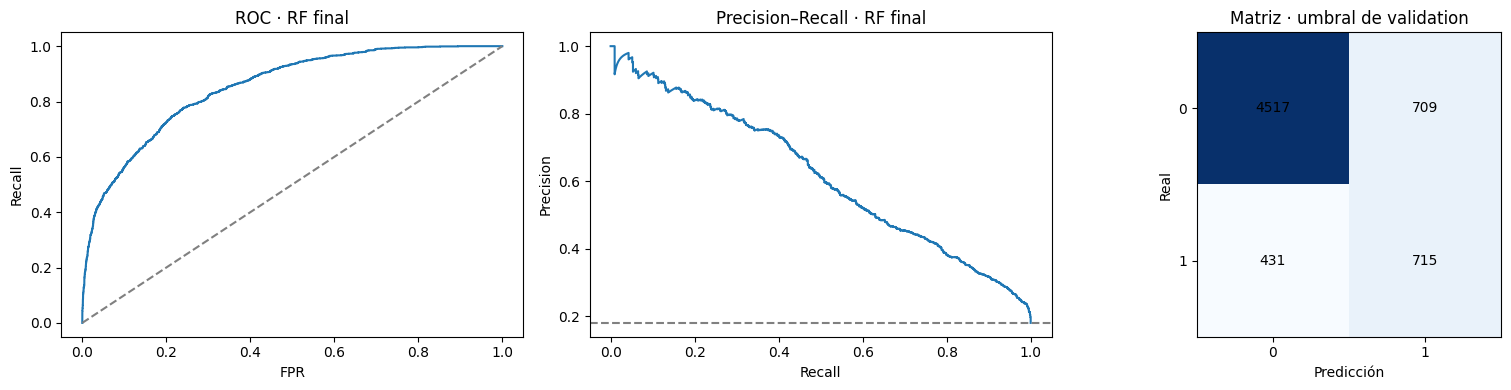

In [9]:
global_sweep = _threshold_sensitivity(gy, gpred.p_final.to_numpy(), GTHRESHOLD)
GLOBAL_TABLES['barrido_umbral_principal'] = pd.DataFrame(global_sweep['rows'])
display(GLOBAL_TABLES['barrido_umbral_principal'])
stored_sweep = global_csv('strict_threshold_sensitivity_2017.csv')
for (_, calculated), (_, expected) in zip(GLOBAL_TABLES['barrido_umbral_principal'].iterrows(), stored_sweep.iterrows()):
    assert abs(calculated.threshold - expected.threshold) < 1e-10
    global_compare('RF barrido · ' + str(expected.threshold), calculated.to_dict(), expected.to_dict())

fig, axes = plt.subplots(1,3,figsize=(16,4))
fpr,tpr,_ = roc_curve(gy,gpred.p_final)
axes[0].plot(fpr,tpr); axes[0].plot([0,1],[0,1],'--',color='grey')
axes[0].set(title='ROC · RF final', xlabel='FPR', ylabel='Recall')
precision,recall,_ = precision_recall_curve(gy,gpred.p_final)
axes[1].plot(recall,precision); axes[1].axhline(gy.mean(),linestyle='--',color='grey')
axes[1].set(title='Precision–Recall · RF final',xlabel='Recall',ylabel='Precision')
matrix = confusion_matrix(gy,gpred.p_final >= GTHRESHOLD)
axes[2].imshow(matrix,cmap='Blues')
for (i,j),v in np.ndenumerate(matrix):axes[2].text(j,i,str(v),ha='center',va='center')
axes[2].set(title='Matriz · umbral de validation',xlabel='Predicción',ylabel='Real',xticks=[0,1],yticks=[0,1])
plt.tight_layout(); plt.show()

## 5 · LSTM, SimpleRNN y regresión logística con retardos

Los CSV originales incluyen sus probabilidades individuales de test. Por ello se pueden
recalcular ROC-AUC, AP, Brier, log-loss, Lift y las métricas con sus umbrales originales.
Las probabilidades sin calibrar y calibradas permiten verificar la reducción del Brier.

**No se dispone del código de entrenamiento original de esta LSTM de presencia.**
Más adelante se incluye una reconstrucción explícita, que constituye otro experimento.
Tampoco están disponibles sus predicciones de validation ni las de horizonte t+3.
Los intervalos originales usaron 300 réplicas, pero no se documenta la semilla:
se recalculan intervalos nuevos con semilla declarada y no se presentan como idénticos.

In [10]:
from functools import lru_cache
from time import perf_counter
from typing import Any
import math

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score


def _safe_probability(values: np.ndarray) -> np.ndarray:
    return np.clip(np.asarray(values, dtype=float), 1e-12, 1 - 1e-12)


def _lift(y: np.ndarray, score: np.ndarray, fraction: float) -> float | None:
    base = float(np.mean(y))
    if base <= 0:
        return None
    n = max(1, int(math.ceil(len(score) * fraction)))
    idx = np.argsort(-score)[:n]
    return float(np.mean(y[idx]) / base)


def score_metrics(y: np.ndarray, score: np.ndarray) -> dict[str, float | None]:
    score = _safe_probability(score)
    return {
        "roc_auc": float(roc_auc_score(y, score)),
        "pr_auc": float(average_precision_score(y, score)),
        "brier": float(brier_score_loss(y, score)),
        "log_loss": float(log_loss(y, score)),
        "lift_top_1pct": _lift(y, score, 0.01),
        "lift_top_5pct": _lift(y, score, 0.05),
        "lift_top_10pct": _lift(y, score, 0.10),
    }


def _common_frame(store: Any) -> pd.DataFrame:
    base = store.pred[["cell", "year", "month", "target_presence", "dvc_count", "p_level1", "p_level2", "p_final"]].copy()
    lstm = store.r9[["cell", "target_year", "target_month", "target_presence", "dvc_count_target", "p_lstm_calibrated"]].rename(
        columns={"target_year": "year", "target_month": "month", "target_presence": "y_lstm", "dvc_count_target": "count_lstm"})
    keys = ["cell", "year", "month"]
    df = base.merge(lstm, on=keys, validate="one_to_one")
    if not (df.target_presence == df.y_lstm).all() or not (df.dvc_count == df.count_lstm).all():
        raise ValueError("Las etiquetas principal/LSTM no coinciden.")
    if not store.mlp.empty:
        mlp = store.mlp.rename(columns={"target_presence": "y_mlp", "dvc_count": "count_mlp"})
        df = df.merge(mlp, on=keys, validate="one_to_one")
        if not (df.target_presence == df.y_mlp).all() or not (df.dvc_count == df.count_mlp).all():
            raise ValueError("Las etiquetas principal/MLP no coinciden.")
        df["deep_mean"] = (df.p_mlp + df.p_lstm_calibrated) / 2
        df["ensemble_equal"] = (df.p_final + df.p_mlp + df.p_lstm_calibrated) / 3
        df["ensemble_balanced"] = .50 * df.p_final + .25 * df.p_mlp + .25 * df.p_lstm_calibrated
    return df


def _delta(candidate: dict[str, float | None], baseline: dict[str, float | None]) -> dict[str, float | None]:
    out: dict[str, float | None] = {}
    for key in baseline:
        if baseline[key] is None or candidate[key] is None:
            out[key] = None
        else:
            out[key] = float(candidate[key] - baseline[key])
    return out


def _cluster_bootstrap(
    df: pd.DataFrame,
    baseline_col: str,
    candidate_col: str,
    samples: int = 400,
    seed: int = 42,
) -> dict[str, Any]:
    cells = df["cell"].unique()
    cell_values = df["cell"].to_numpy()
    groups = {cell: np.flatnonzero(cell_values == cell) for cell in cells}
    y_all = df["target_presence"].to_numpy(dtype=int)
    base_all = df[baseline_col].to_numpy(dtype=float)
    cand_all = df[candidate_col].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    deltas: list[list[float]] = []

    for _ in range(samples):
        sampled_cells = rng.choice(cells, size=len(cells), replace=True)
        idx = np.concatenate([groups[cell] for cell in sampled_cells])
        y = y_all[idx]
        if y.min() == y.max():
            continue
        base = base_all[idx]
        cand = cand_all[idx]
        deltas.append([
            average_precision_score(y, cand) - average_precision_score(y, base),
            roc_auc_score(y, cand) - roc_auc_score(y, base),
            brier_score_loss(y, cand) - brier_score_loss(y, base),
        ])

    arr = np.asarray(deltas, dtype=float)
    names = ["pr_auc", "roc_auc", "brier"]
    result: dict[str, Any] = {"samples_requested": samples, "samples_used": int(len(arr)), "cluster": "cell", "seed": seed, "metrics": {}}
    for i, name in enumerate(names):
        vals = arr[:, i]
        result["metrics"][name] = {
            "mean_delta": float(np.mean(vals)),
            "ci95_low": float(np.quantile(vals, 0.025)),
            "ci95_high": float(np.quantile(vals, 0.975)),
        }
    return result


def _threshold_sweep(y: np.ndarray, score: np.ndarray) -> list[dict[str, float | int]]:
    out: list[dict[str, float | int]] = []
    for threshold in np.arange(0.05, 0.51, 0.05):
        pred = score >= threshold
        tp = int(np.sum((pred == 1) & (y == 1)))
        fp = int(np.sum((pred == 1) & (y == 0)))
        fn = int(np.sum((pred == 0) & (y == 1)))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if precision + recall else 0.0
        out.append({
            "threshold": float(round(threshold, 2)),
            "alerts": int(pred.sum()),
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1),
        })
    return out


def _runtime_microbenchmark(df: pd.DataFrame, iterations: int = 300) -> dict[str, float | int | str]:
    p = df["p_final"].to_numpy(dtype=float)
    d = df["p_mlp"].to_numpy(dtype=float)
    l = df["p_lstm_calibrated"].to_numpy(dtype=float)
    timings = []
    for _ in range(iterations):
        start = perf_counter()
        _ = 0.50 * p + 0.25 * d + 0.25 * l
        timings.append((perf_counter() - start) * 1000.0)
    return {
        "operation": "vectorized score fusion only; NOT end-to-end model inference",
        "rows": int(len(df)),
        "iterations": iterations,
        "median_ms": float(np.median(timings)),
        "p95_ms": float(np.quantile(timings, 0.95)),
        "per_row_median_us": float(np.median(timings) * 1000.0 / len(df)),
    }


def build_technology_benchmark(store: Any, bootstrap_samples: int = 400) -> dict[str, Any]:
    df = _common_frame(store)
    y = df["target_presence"].to_numpy(dtype=int)
    available = "p_mlp" in df
    variants = {
        "level1_no_seasonal": ("Nivel 1 sin modulador estacional", "p_level1"),
        "current_final": ("Random Forest + ajuste estacional", "p_final"),
        "lstm": ("LSTM calibrada", "p_lstm_calibrated"),
    }
    if available:
        variants.update({
            "mlp": ("MLP de presencia", "p_mlp"),
            "ensemble_equal": ("Ensemble exploratorio 1/3 + 1/3 + 1/3", "ensemble_equal"),
            "ensemble_balanced": ("Ensemble exploratorio 50% + 25% + 25%", "ensemble_balanced"),
        })
    metrics = {key: {"label": label, "metrics": score_metrics(y, df[col].to_numpy(dtype=float))}
               for key, (label, col) in variants.items()}
    baseline = metrics["current_final"]["metrics"]
    for value in metrics.values():
        value["delta_vs_current"] = _delta(value["metrics"], baseline)
    sweep = []
    if available:
        for alpha in np.linspace(0, 1, 11):
            score = alpha * df.p_final + (1-alpha) * df.deep_mean
            sweep.append({"current_weight": float(round(alpha, 1)), "deep_mean_weight": float(round(1-alpha, 1)), **score_metrics(y, score)})
    bootstrap = {"seasonal_layer_vs_level1": _cluster_bootstrap(df, "p_level1", "p_final", samples=bootstrap_samples, seed=43)}
    if available:
        bootstrap["ensemble_balanced_vs_current"] = _cluster_bootstrap(df, "p_final", "ensemble_balanced", samples=bootstrap_samples, seed=42)
    return {
        "scope": {"evaluation_year": 2017, "rows_common": len(df), "cells": int(df.cell.nunique()),
                  "prevalence": float(y.mean()), "mlp_predictions_available": available,
                  "warning": "Diagnóstico sobre test histórico. Los ensembles y barridos son exploratorios y requieren validación temporal independiente."},
        "models": metrics,
        "parameter_sweeps": {"ensemble_weight": sweep, "threshold_current": _threshold_sweep(y, df.p_final.to_numpy()),
                             "threshold_ensemble_balanced": _threshold_sweep(y, df.ensemble_balanced.to_numpy()) if available else []},
        "bootstrap": bootstrap,
        "runtime": _runtime_microbenchmark(df) if available else None,
        "interpretation": {
            "seasonal_layer": "Las diferencias de AP, ROC-AUC y Brier se recalculan desde las predicciones guardadas.",
            "mlp_lstm_alone": "La MLP se muestra con los resultados de los notebooks ejecutados. La tabla de muestra común identifica cada entrenamiento.",
            "ensemble": "Los resultados se recalculan con las predicciones reales de MLP; el barrido sigue siendo exploratorio." if available else "Pendiente de las predicciones por celda de la MLP. Se han retirado los resultados de la DNN anterior.",
            "lift": "El Lift se calcula únicamente para modelos con predicciones disponibles.",
        },
    }

In [11]:
G_TEMPORAL_COLUMNS = {'LSTM + Platt':'p_lstm_calibrated',
    'SimpleRNN + Platt':'p_simplernn_calibrated',
    'Lag Logistic Regression + Platt':'p_lag_logistic_regression_plus_platt'}
global_temporal_rows = []
for reference in glstm_ref['model_comparison']:
    col = G_TEMPORAL_COLUMNS[reference['model']]
    y, p = gr9.target_presence.to_numpy(), gr9[col].to_numpy()
    result = {**_classification_metrics(y,p,reference['threshold_from_val']), **score_metrics(y,p)}
    global_temporal_rows.append({'modelo':reference['model'],'umbral':reference['threshold_from_val'],**result})
    expected = {k[5:]:v for k,v in reference.items() if k.startswith('test_')}
    expected.update({k:v for k,v in reference.items() if k.startswith('lift_')})
    global_compare('Temporal · ' + reference['model'], result, expected)
GLOBAL_TABLES['clasificacion_temporal_original'] = pd.DataFrame(global_temporal_rows)
display(GLOBAL_TABLES['clasificacion_temporal_original'])
for key,col in [('raw_lstm','p_lstm_raw'),('calibrated_lstm','p_lstm_calibrated')]:
    result = {**score_metrics(gr9.target_presence.to_numpy(),gr9[col].to_numpy()),
              **_classification_metrics(gr9.target_presence.to_numpy(),gr9[col].to_numpy(),glstm_ref['selected_model']['threshold_from_validation'])}
    global_compare('LSTM ' + key, result, glstm_ref['test_2017'][key])

def global_cluster_intervals(frame, column, samples=300, seed=42):
    rng = np.random.default_rng(seed)
    groups = {c:np.flatnonzero(frame.cell.to_numpy()==c) for c in frame.cell.unique()}
    cluster_names = list(groups)
    replicas = []
    for _ in range(samples):
        idx = np.concatenate([groups[c] for c in rng.choice(cluster_names,len(groups),replace=True)])
        y,p = frame.target_presence.to_numpy()[idx], frame[column].to_numpy()[idx]
        if np.unique(y).size < 2:continue
        replicas.append([roc_auc_score(y,p),average_precision_score(y,p),brier_score_loss(y,p)])
    values=np.asarray(replicas)
    estimate=score_metrics(frame.target_presence.to_numpy(),frame[column].to_numpy())
    return pd.DataFrame([{'metrica':key,'estimate':estimate[key],
        'ci95_low':np.quantile(values[:,i],.025),'ci95_high':np.quantile(values[:,i],.975),
        'replicas':len(values),'semilla':seed}
        for i,key in enumerate(['roc_auc','pr_auc','brier'])])
GLOBAL_TABLES['bootstrap_lstm_nuevo'] = global_cluster_intervals(gr9,'p_lstm_calibrated')
display(GLOBAL_TABLES['bootstrap_lstm_nuevo'])
global_temporal_missing=['semilla y procedimiento exacto de los IC originales']
if not TEMPORAL_VALIDATION_OVERRIDE:global_temporal_missing.append('predicciones validation originales')
if not TEMPORAL_HORIZON3_OVERRIDE:global_temporal_missing.append('predicciones originales t+3')
global_pending('LSTM · resultados históricos adicionales',
    'Pendiente: '+', '.join(global_temporal_missing)+'. No se infiere del test t+1.')

def global_temporal_extra(path, expected_year, horizon):
    frame=pd.read_csv(path)
    year_col='target_year' if 'target_year' in frame else 'year'
    month_col='target_month' if 'target_month' in frame else 'month'
    assert set(frame[year_col])=={expected_year}
    assert frame[month_col].between(1,12).all()
    assert not frame.duplicated(['cell',year_col,month_col]).any()
    assert frame.target_presence.isin([0,1]).all()
    if 'horizon_months' in frame:assert set(frame.horizon_months)=={horizon}
    return frame

if TEMPORAL_VALIDATION_OVERRIDE:
    frame=global_temporal_extra(TEMPORAL_VALIDATION_OVERRIDE,2016,1)
    for reference in glstm_ref['model_comparison']:
        probability=frame[G_TEMPORAL_COLUMNS[reference['model']]].to_numpy()
        assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
        calculated=score_metrics(frame.target_presence.to_numpy(),probability)
        global_compare('Temporal validation original · '+reference['model'],calculated,
            {k[4:]:v for k,v in reference.items() if k.startswith('val_')})
    GLOBAL_TABLES['validation_temporal_adicional']=frame
if TEMPORAL_HORIZON3_OVERRIDE:
    frame=global_temporal_extra(TEMPORAL_HORIZON3_OVERRIDE,2017,3)
    for reference in glstm_ref['horizon_comparison']:
        if reference['horizon_months']!=3:continue
        col='p_lstm_calibrated' if reference['model']=='LSTM' else 'p_lag_logistic_regression_plus_platt'
        probability=frame[col].to_numpy()
        assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
        calculated=score_metrics(frame.target_presence.to_numpy(),probability)
        for key in ['roc_auc','pr_auc','brier']:
            expected=reference['test_'+key]
            digits=4 if (reference['model']=='LSTM' and key=='roc_auc') else 6
            global_compare('Temporal t+3 original · '+reference['model'],calculated,
                {key:expected},tolerance=.51*10**(-digits))
    GLOBAL_TABLES['horizonte3_temporal_adicional']=frame

,modelo,umbral,roc_auc,pr_auc,brier,precision,recall,f1,accuracy,specificity,false_positive_rate,false_negative_rate,alert_rate,alerts,true_positives,false_positives,true_negatives,false_negatives,positives,negatives,rows,log_loss,lift_top_1pct,lift_top_5pct,lift_top_10pct
0,LSTM + Platt,0.266325,0.846497,0.609213,0.103847,0.547923,0.598604,0.572143,0.838374,0.891196,0.108804,0.401396,0.197227,1252,686,566,4636,460,1146,5202,6348,0.338952,5.193063,4.476703,3.881849
1,SimpleRNN + Platt,0.297272,0.844788,0.604620,0.104343,0.569757,0.552356,0.560922,0.843888,0.908112,0.091888,0.447644,0.175016,1111,633,478,4724,513,1146,5202,6348,0.340641,5.193063,4.407027,3.899295
2,Lag Logistic Regression + Platt,0.235617,0.837912,0.590693,0.107186,0.530516,0.591623,0.559406,0.831758,0.884660,0.115340,0.408377,0.201323,1278,678,600,4602,468,1146,5202,6348,0.351030,4.933410,4.372189,3.751000


,metrica,estimate,ci95_low,ci95_high,replicas,semilla
0,roc_auc,0.846497,0.826545,0.862131,300,42
1,pr_auc,0.609213,0.556896,0.654737,300,42
2,brier,0.103847,0.096828,0.111731,300,42


## 6 · Nueva MLP: matriz publicada y predicciones opcionales

La ejecución publicada tiene 6.336 filas y un umbral de validation de 0,282222….
Sus probabilidades individuales no están incluidas en el ZIP recibido. La matriz publicada
permite comprobar precision, recall, accuracy y F1; **no permite calcular ROC-AUC, AP ni Brier**.
Si aportas el CSV del mismo entrenamiento, el bloque siguiente recalcula todas las métricas
y contrasta muestra, etiquetas, umbral y valores. Un reentrenamiento nuevo se evalúa por separado.

In [12]:
gmlp_metrics = gmlp_ref['test_metrics']
def global_confusion_derived(m):
    tp,fp,tn,fn = [int(m[k]) for k in ['tp','fp','tn','fn']]
    precision=tp/(tp+fp); recall=tp/(tp+fn)
    return {'precision':precision,'recall':recall,
        'f1':2*precision*recall/(precision+recall),'accuracy':(tp+tn)/(tp+fp+tn+fn),
        'alerts':tp+fp,'tp':tp,'fp':fp,'tn':tn,'fn':fn}
gmlp_from_matrix = global_confusion_derived(gmlp_ref['confusion'])
global_compare('MLP · cálculo desde matriz publicada',gmlp_from_matrix,gmlp_metrics,tolerance=.000051)
display(pd.DataFrame([{'prueba':'Derivado de matriz publicada',**gmlp_from_matrix}]))

def global_optional_file(override, relative_candidates):
    if override:
        path=Path(override).expanduser().resolve()
        if not path.is_file():raise FileNotFoundError(path)
        return path
    for path in relative_candidates:
        if path.is_file():return path
    return None

gmlp_path = global_optional_file(MLP_PREDICTIONS_OVERRIDE,[
    GLOBAL_PROJECT_ROOT/'artifacts/reto08_capitulo8_completo/predicciones_test_2017_cap8.csv',
    GLOBAL_DATA_DIR/'predicciones_test_2017_mlp.csv'])
gmlp = pd.DataFrame(columns=GKEYS+['target_presence','dvc_count','p_mlp'])
if gmlp_path:
    candidate=pd.read_csv(gmlp_path)
    required=GKEYS+['target_presence','dvc_count','p_mlp']
    assert set(required).issubset(candidate), 'El CSV MLP carece de columnas necesarias.'
    candidate=candidate[required].copy()
    assert not candidate.isna().any().any() and not candidate.duplicated(GKEYS).any()
    assert set(candidate.year)=={2017} and candidate.month.between(1,12).all()
    assert candidate.p_mlp.between(0,1).all()
    assert np.array_equal(candidate.target_presence,(candidate.dvc_count>0).astype(int))
    assert len(candidate)==gmlp_ref['scope']['test_rows']
    assert candidate.cell.nunique()==gmlp_ref['scope']['test_cells']
    assert candidate.target_presence.sum()==gmlp_ref['scope']['test_positives']
    mlp_result={**score_metrics(candidate.target_presence.to_numpy(),candidate.p_mlp.to_numpy()),
        **_classification_metrics(candidate.target_presence.to_numpy(),candidate.p_mlp.to_numpy(),gmlp_ref['threshold'])}
    global_compare('MLP · probabilidades individuales',mlp_result,gmlp_metrics,tolerance=.000051)
    # Solo se incorpora al benchmark de la ejecución publicada si reproduce sus métricas.
    gmlp_same_execution=all(abs(mlp_result[k]-gmlp_metrics[k]) <= .000051
                           for k in ['roc_auc','pr_auc','brier','f1'])
    if gmlp_same_execution:gmlp=candidate
    else:print('El CSV corresponde a otra ejecución. Se muestran diferencias; no se mezcla con la MLP publicada.')
    display(pd.DataFrame([mlp_result]))
else:
    global_pending('MLP · ROC-AUC / AP / Brier individuales',
        'Falta predicciones_test_2017_cap8.csv de la ejecución publicada.')
    print('Pendiente del CSV de la MLP. El código de entrenamiento y evaluación está en la sección 13.')

Pendiente del CSV de la MLP. El código de entrenamiento y evaluación está en la sección 13.


,prueba,precision,recall,f1,accuracy,alerts,tp,fp,tn,fn
0,Derivado de matriz publicada,0.525174,0.590592,0.555966,0.829072,1291,678,613,4575,470


## 7 · Benchmark común, Lift, diferencias y bootstrap del Laboratorio

Se intersectan claves celda/año/mes y se exige igualdad de etiquetas y conteos.
Los resultados en la muestra común pueden diferir de los obtenidos en la muestra completa.
La MLP y los ensembles solo se incluyen cuando hay predicciones de la misma ejecución verificadas.
Los pesos y barridos son diagnósticos sobre test; no prueban una selección independiente.

In [13]:
gstore = SimpleNamespace(pred=gpred, r9=gr9, mlp=gmlp)
gbenchmark = build_technology_benchmark(gstore, bootstrap_samples=BOOTSTRAP_SAMPLES_GLOBAL)
GLOBAL_TABLES['benchmark_comun'] = pd.DataFrame([
    {'modelo':value['label'],**value['metrics'],**{'delta_'+k:v for k,v in value['delta_vs_current'].items()}}
    for value in gbenchmark['models'].values()])
display(pd.Series(gbenchmark['scope']))
display(GLOBAL_TABLES['benchmark_comun'])
display(pd.json_normalize(gbenchmark['bootstrap']['seasonal_layer_vs_level1']['metrics'],sep='.'))
GLOBAL_TABLES['barrido_pesos_ensemble'] = pd.DataFrame(gbenchmark['parameter_sweeps']['ensemble_weight'])
if gbenchmark['runtime']:
    display(GLOBAL_TABLES['barrido_pesos_ensemble'])
    display(pd.Series(gbenchmark['runtime']))
else:
    print('Ensembles y microbenchmark de fusión: pendientes de las predicciones MLP.')
for _, row in gclassification.iterrows():
    col='p_level1' if str(row.model).startswith('Nivel1') else 'p_final'
    global_compare('Lift cartera · '+str(row.model),score_metrics(gy,gpred[col].to_numpy()),row.to_dict())

Ensembles y microbenchmark de fusión: pendientes de las predicciones MLP.


evaluation_year                                                           2017
rows_common                                                               6348
cells                                                                      529
prevalence                                                            0.180529
mlp_predictions_available                                                False
warning                      Diagnóstico sobre test histórico. Los ensemble...
dtype: object

,modelo,roc_auc,pr_auc,brier,log_loss,lift_top_1pct,lift_top_5pct,lift_top_10pct,delta_roc_auc,delta_pr_auc,delta_brier,delta_log_loss,delta_lift_top_1pct,delta_lift_top_5pct,delta_lift_top_10pct
0,Nivel 1 sin modulador estacional,0.845662,0.598087,0.105718,0.340583,5.106512,4.476703,3.881849,-0.005887,-0.018727,0.001981,0.005476,-0.173102,-0.121934,-0.157019
1,Random Forest + ajuste estacional,0.851549,0.616815,0.103738,0.335107,5.279614,4.598637,4.038867,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,LSTM calibrada,0.846497,0.609213,0.103847,0.338952,5.193063,4.476703,3.881849,-0.005052,-0.007601,0.000110,0.003845,-0.086551,-0.121934,-0.157019


,pr_auc.mean_delta,pr_auc.ci95_low,pr_auc.ci95_high,roc_auc.mean_delta,roc_auc.ci95_low,roc_auc.ci95_high,brier.mean_delta,brier.ci95_low,brier.ci95_high
0,0.020619,0.014591,0.027348,0.006088,0.003013,0.008741,-0.001993,-0.002726,-0.001301


## 8 · Calibración: Brier, ECE, MCE, curvas e intervalos

Se incluye el mismo algoritmo del backend: intervalos cuantílicos, bootstrap agrupado por
celda con semillas 102/103 y el diagnóstico cross-fit con cinco grupos y semilla 2026.
La calibración cross-fit sobre el test es un diagnóstico posterior; no sustituye el Platt
temporal entrenado antes de abrir 2017.

In [14]:
from typing import Any
import math

import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold


EPS = 1e-9


def _clip(values: np.ndarray) -> np.ndarray:
    return np.clip(np.asarray(values, dtype=float), EPS, 1.0 - EPS)


def _ece_and_bins(y: np.ndarray, score: np.ndarray, n_bins: int = 10) -> tuple[float, float, list[dict[str, float | int]]]:
    """Quantile-bin reliability diagnostic.

    Quantile bins are used because the project is imbalanced and most probabilities
    live close to zero. ECE/MCE here are descriptive calibration diagnostics, not
    replacements for the proper scoring rule (Brier/log-loss).
    """
    y = np.asarray(y, dtype=int)
    score = _clip(score)
    quantiles = np.linspace(0.0, 1.0, n_bins + 1)
    edges = np.unique(np.quantile(score, quantiles))
    if len(edges) < 3:
        edges = np.linspace(float(score.min()), float(score.max()) + EPS, n_bins + 1)
    bin_id = np.digitize(score, edges[1:-1], right=True)

    rows: list[dict[str, float | int]] = []
    ece = 0.0
    mce = 0.0
    for i in range(len(edges) - 1):
        mask = bin_id == i
        if not np.any(mask):
            continue
        mean_pred = float(np.mean(score[mask]))
        observed = float(np.mean(y[mask]))
        gap = abs(mean_pred - observed)
        weight = float(np.mean(mask))
        ece += weight * gap
        mce = max(mce, gap)
        rows.append({
            "bin": int(len(rows) + 1),
            "n": int(mask.sum()),
            "score_min": float(np.min(score[mask])),
            "score_max": float(np.max(score[mask])),
            "mean_predicted": mean_pred,
            "observed_rate": observed,
            "abs_gap": float(gap),
        })
    return float(ece), float(mce), rows


def calibration_metrics(y: np.ndarray, score: np.ndarray) -> dict[str, Any]:
    score = _clip(score)
    ece, mce, bins = _ece_and_bins(y, score)
    return {
        "brier": float(brier_score_loss(y, score)),
        "log_loss": float(log_loss(y, score)),
        "roc_auc": float(roc_auc_score(y, score)),
        "pr_auc": float(average_precision_score(y, score)),
        "ece_q10": ece,
        "mce_q10": mce,
        "reliability_bins": bins,
    }


def _cluster_bootstrap_brier_delta(
    df: pd.DataFrame,
    before_col: str,
    after_col: str,
    samples: int = 400,
    seed: int = 42,
) -> dict[str, Any]:
    cells = df["cell"].to_numpy()
    unique_cells = np.unique(cells)
    groups = {cell: np.flatnonzero(cells == cell) for cell in unique_cells}
    y = df["target_presence"].to_numpy(dtype=int)
    before = _clip(df[before_col].to_numpy(dtype=float))
    after = _clip(df[after_col].to_numpy(dtype=float))
    rng = np.random.default_rng(seed)
    deltas: list[float] = []

    for _ in range(samples):
        sampled = rng.choice(unique_cells, size=len(unique_cells), replace=True)
        idx = np.concatenate([groups[cell] for cell in sampled])
        deltas.append(brier_score_loss(y[idx], after[idx]) - brier_score_loss(y[idx], before[idx]))

    arr = np.asarray(deltas, dtype=float)
    return {
        "samples": int(len(arr)),
        "cluster": "cell",
        "mean_delta_brier": float(np.mean(arr)),
        "ci95_low": float(np.quantile(arr, 0.025)),
        "ci95_high": float(np.quantile(arr, 0.975)),
    }


def _existing_pair(
    df: pd.DataFrame,
    raw_col: str,
    calibrated_col: str,
    label: str,
    bootstrap_samples: int,
    seed: int,
) -> dict[str, Any]:
    y = df["target_presence"].to_numpy(dtype=int)
    before = calibration_metrics(y, df[raw_col].to_numpy(dtype=float))
    after = calibration_metrics(y, df[calibrated_col].to_numpy(dtype=float))
    reduction = (before["brier"] - after["brier"]) / before["brier"] if before["brier"] else 0.0
    return {
        "label": label,
        "rows": int(len(df)),
        "cells": int(df["cell"].nunique()),
        "prevalence": float(y.mean()),
        "raw_column": raw_col,
        "calibrated_column": calibrated_col,
        "before": before,
        "after": after,
        "brier_absolute_improvement": float(before["brier"] - after["brier"]),
        "brier_relative_reduction": float(reduction),
        "bootstrap": _cluster_bootstrap_brier_delta(df, raw_col, calibrated_col, samples=bootstrap_samples, seed=seed),
    }


def _crossfit_calibration(
    y: np.ndarray,
    score: np.ndarray,
    groups: np.ndarray,
    method: str,
    n_splits: int = 5,
    seed: int = 42,
) -> np.ndarray:
    y = np.asarray(y, dtype=int)
    score = _clip(score)
    groups = np.asarray(groups)
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    out = np.zeros(len(score), dtype=float)

    if method == "sigmoid_logit":
        x = np.log(score / (1.0 - score))
    else:
        x = score

    for train_idx, test_idx in cv.split(np.zeros(len(y)), y, groups=groups):
        if method in {"sigmoid_score", "sigmoid_logit"}:
            # Near-unregularized 1D logistic calibration. `sigmoid_score` is the
            # closest reproducible analogue to CalibratedClassifierCV(method='sigmoid')
            # when only probabilities (not the original estimator decision scores)
            # are available. `sigmoid_logit` is classic Platt-style log-odds remapping.
            model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000)
            model.fit(x[train_idx].reshape(-1, 1), y[train_idx])
            out[test_idx] = model.predict_proba(x[test_idx].reshape(-1, 1))[:, 1]
        elif method == "isotonic":
            model = IsotonicRegression(out_of_bounds="clip")
            model.fit(score[train_idx], y[train_idx])
            out[test_idx] = model.predict(score[test_idx])
        else:
            raise ValueError(f"Método de calibración desconocido: {method}")
    return _clip(out)


def _current_common_frame(store: Any) -> pd.DataFrame:
    return store.pred[["cell", "month", "target_presence", "p_final"]].copy()


def _crossfit_audit(df: pd.DataFrame, score_col: str, label: str) -> dict[str, Any]:
    y = df["target_presence"].to_numpy(dtype=int)
    groups = df["cell"].to_numpy()
    raw_score = df[score_col].to_numpy(dtype=float)
    baseline = calibration_metrics(y, raw_score)
    methods: dict[str, Any] = {}
    for method, method_label in [
        ("sigmoid_score", "Sigmoide sobre probabilidad (aprox. sklearn con artefactos disponibles)"),
        ("sigmoid_logit", "Platt sobre logit(probabilidad)"),
        ("isotonic", "Isotónica"),
    ]:
        calibrated = _crossfit_calibration(y, raw_score, groups, method=method)
        metrics = calibration_metrics(y, calibrated)
        methods[method] = {
            "label": method_label,
            "metrics": metrics,
            "delta_brier": float(metrics["brier"] - baseline["brier"]),
            "delta_log_loss": float(metrics["log_loss"] - baseline["log_loss"]),
            "delta_ece_q10": float(metrics["ece_q10"] - baseline["ece_q10"]),
        }
    return {
        "label": label,
        "rows": int(len(df)),
        "cells": int(df["cell"].nunique()),
        "protocol": "5-fold StratifiedGroupKFold por cell dentro de 2017; diagnóstico, no test temporal independiente",
        "baseline": baseline,
        "methods": methods,
    }

,modelo,Brier_raw,Brier_calibrado,reduccion_relativa,ECE_raw,ECE_calibrado,MCE_raw,MCE_calibrado,samples,cluster,mean_delta_brier,ci95_low,ci95_high
0,SimpleRNN,0.165357,0.104343,0.368986,0.220357,0.009720,0.358094,0.034047,250,cell,-0.061194,-0.066268,-0.055354
1,LSTM,0.165542,0.103847,0.372681,0.220564,0.011609,0.361829,0.045362,250,cell,-0.061626,-0.067360,-0.054811


,metodo,brier,log_loss,roc_auc,pr_auc,ece_q10,mce_q10,delta_brier
0,Sin recalibrar,0.103348,0.333914,0.852175,0.616802,0.018893,0.099169,NaN
1,Sigmoide sobre probabilidad (aprox. sklearn co...,0.103650,0.341258,0.851635,0.615411,0.029084,0.072179,0.000301
2,Platt sobre logit(probabilidad),0.102785,0.332472,0.851936,0.615599,0.016107,0.047674,-0.000563
3,Isotónica,0.103210,0.341264,0.847611,0.600408,0.007989,0.020674,-0.000139


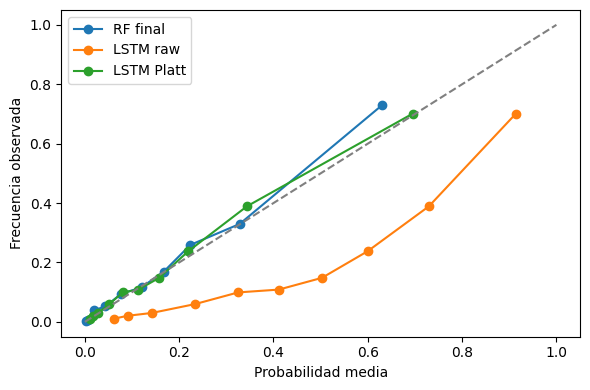

In [15]:
global_calibration_pairs = {}
global_calibration_rows = []
for model,raw,calibrated,seed in [
    ('SimpleRNN','p_simplernn_raw','p_simplernn_calibrated',102),
    ('LSTM','p_lstm_raw','p_lstm_calibrated',103)]:
    result=_existing_pair(gr9,raw,calibrated,model,BOOTSTRAP_SAMPLES_GLOBAL,seed)
    global_calibration_pairs[model]=result
    global_calibration_rows.append({'modelo':model,'Brier_raw':result['before']['brier'],
        'Brier_calibrado':result['after']['brier'],'reduccion_relativa':result['brier_relative_reduction'],
        'ECE_raw':result['before']['ece_q10'],'ECE_calibrado':result['after']['ece_q10'],
        'MCE_raw':result['before']['mce_q10'],'MCE_calibrado':result['after']['mce_q10'],
        **result['bootstrap']})
GLOBAL_TABLES['calibracion_profunda'] = pd.DataFrame(global_calibration_rows)
display(GLOBAL_TABLES['calibracion_profunda'])
lstm_pair=global_calibration_pairs['LSTM']
global_compare('LSTM · efecto calibración',{
    'absolute_brier_reduction':lstm_pair['brier_absolute_improvement'],
    'relative_brier_reduction':lstm_pair['brier_relative_reduction']},
    glstm_ref['test_2017']['calibration_effect'])
gcrossfit=_crossfit_audit(gpred,'p_final','Random Forest final')
GLOBAL_TABLES['calibracion_crossfit'] = pd.DataFrame([
    {'metodo':'Sin recalibrar',**{k:v for k,v in gcrossfit['baseline'].items() if k!='reliability_bins'}},
    *[{'metodo':v['label'],'delta_brier':v['delta_brier'],
       **{k:x for k,x in v['metrics'].items() if k!='reliability_bins'}}
      for v in gcrossfit['methods'].values()]])
display(GLOBAL_TABLES['calibracion_crossfit'])
fig, ax=plt.subplots(figsize=(6,4))
for label,score in [('RF final',gpred.p_final),('LSTM raw',gr9.p_lstm_raw),('LSTM Platt',gr9.p_lstm_calibrated)]:
    y=gpred.target_presence if label=='RF final' else gr9.target_presence
    _,_,bins=_ece_and_bins(y.to_numpy(),score.to_numpy())
    ax.plot([b['mean_predicted'] for b in bins],[b['observed_rate'] for b in bins],marker='o',label=label)
ax.plot([0,1],[0,1],'--',color='grey');ax.set(xlabel='Probabilidad media',ylabel='Frecuencia observada')
ax.legend();plt.tight_layout();plt.show()

## 9 · Cartera, mapa, riesgo relativo y valores de la demo

Observaciones, celdas, carreteras, prevalencia, DVC, alertas, agregados mensuales,
histograma y ranking por carretera se calculan con las mismas agrupaciones del frontend.
El Risk Response Score es un percentil relativo del score; no es otra probabilidad.
El selector de carreteras exige coordenadas y al menos cuatro celdas.

In [16]:
global_portfolio={'observations':len(gpred),'cells':int(gpred.cell.nunique()),
    'roads':int(gpred.road_name.nunique()),'base_rate':float(gpred.target_presence.mean()),
    'dvc_total':int(gpred.dvc_count.sum()),'alerts_at_threshold':int((gpred.p_final>=GTHRESHOLD).sum()),
    'threshold':GTHRESHOLD}
display(pd.Series(global_portfolio))
GLOBAL_TABLES['cartera_mensual'] = gpred.groupby('month').agg(
    predicted_risk=('p_final','mean'),observed_rate=('target_presence','mean'),
    dvc=('dvc_count','sum'),observations=('p_final','size')).reset_index()
groad_stats=gpred.groupby('road_name').agg(observations=('p_final','size'),cells=('cell','nunique'),
    mean_risk=('p_final','mean'),max_risk=('p_final','max'),
    observed_positive_rate=('target_presence','mean'),dvc_total=('dvc_count','sum')).reset_index()
GLOBAL_TABLES['carreteras_mayor_riesgo']=groad_stats[groad_stats.observations>=24].sort_values(
    ['mean_risk','max_risk'],ascending=False).head(15)
display(GLOBAL_TABLES['cartera_mensual']);display(GLOBAL_TABLES['carreteras_mayor_riesgo'])
counts,edges=np.histogram(gpred.p_final,bins=24,range=(0,1))
GLOBAL_TABLES['histograma_riesgo']=pd.DataFrame({'bin_start':edges[:-1],'bin_end':edges[1:],
    'bin_mid':(edges[:-1]+edges[1:])/2,'count':counts})
assert counts.sum()==len(gpred)
global_risk_percentiles=gpred.p_final.rank(method='average',pct=True)*100
def global_threshold_position(t):
    return float(np.mean(gpred.p_final.to_numpy()<=t)*100)
display(pd.DataFrame({'probabilidad':[GTHRESHOLD],
    'percentil_umbral':[global_threshold_position(GTHRESHOLD)]}))
global_month_rr=global_csv('modulador_mensual_final_2008_2016.csv')
display(global_month_rr)
with_coords=gpred.merge(gcoords[['cell','easting_mean','northing_mean']],on='cell',how='left',validate='many_to_one')
selector=with_coords.dropna(subset=['easting_mean','northing_mean']).groupby('road_name').cell.nunique()
print('Carreteras seleccionables (mínimo 4 celdas):',int((selector>=4).sum()))

def stopping_distance(speed_mph):
    v=speed_mph*.44704
    return v*1.2 + v*v/(2*9.81*.55)

def preventive_response(limit, percentile, probability, threshold, current_speed):
    if probability < threshold:
        return {'active':False,'intensity':0.,'reduction_mph':0.,'target_speed':limit,
                'applied_speed':min(current_speed,limit)}
    score=np.clip(percentile,0,100)
    intensity=np.clip((score-60)/40,0,1)
    reduction_mph=20*intensity
    target_speed=max(25,limit-reduction_mph)
    return {'active':True,'intensity':intensity,'reduction_mph':reduction_mph,
            'target_speed':target_speed,'applied_speed':min(current_speed,target_speed)}

gexample=gpred.sort_values('p_final',ascending=False).iloc[0]
gexample_percentile=float(global_risk_percentiles.loc[gexample.name])
gresponse=preventive_response(60,gexample_percentile,gexample.p_final,GTHRESHOLD,60)
display(pd.Series({'celda':gexample.cell,'mes':gexample.month,'probabilidad_RF':gexample.p_final,
    'DVC_esperados_Poisson':gexample.pred_count_final,'percentil':gexample_percentile,
    **gresponse,'distancia_parada_60mph_m':stopping_distance(60),
    'distancia_parada_objetivo_m':stopping_distance(gresponse['applied_speed'])}))
print('La reducción de velocidad es una regla de la demo, no una métrica de eficacia observada.')

Carreteras seleccionables (mínimo 4 celdas): 45
La reducción de velocidad es una regla de la demo, no una métrica de eficacia observada.


observations           6372.000000
cells                   531.000000
roads                   173.000000
base_rate                 0.179849
dvc_total              1897.000000
alerts_at_threshold    1424.000000
threshold                 0.242581
dtype: float64

,month,predicted_risk,observed_rate,dvc,observations
0,1,0.158073,0.158192,131,531
1,2,0.139151,0.118644,84,531
2,3,0.134644,0.133710,97,531
3,4,0.156380,0.177024,159,531
4,5,0.222668,0.276836,376,531
5,6,0.200228,0.199623,183,531
6,7,0.163353,0.218456,163,531
7,8,0.154983,0.184557,146,531
8,9,0.135170,0.128060,98,531
9,10,0.157767,0.182674,142,531


,road_name,observations,cells,mean_risk,max_risk,observed_positive_rate,dvc_total
29,A726,24,2,0.800378,0.891923,0.833333,56
44,A8,24,2,0.691661,0.903501,0.875000,53
109,A907,24,2,0.622193,0.748544,0.833333,27
45,A803,36,3,0.597266,0.900430,0.750000,93
3,A199,36,3,0.497035,0.772221,0.750000,54
118,A921,24,2,0.491775,0.835225,0.708333,37
72,A84,24,2,0.417632,0.775142,0.208333,6
119,A923,36,3,0.416072,0.704031,0.500000,43
16,A706,36,3,0.371139,0.659338,0.388889,24
111,A91,48,4,0.358136,0.575340,0.479167,38


,probabilidad,percentil_umbral
0,0.242581,77.652228


,month,relative_risk
0,1,0.945696
1,2,0.772811
2,3,0.734392
3,4,0.929442
4,5,1.697820
5,6,1.405246
6,7,0.997414
7,8,0.916143
8,9,0.738825
9,10,0.942741


celda                               5306
mes                                    5
probabilidad_RF                 0.971164
DVC_esperados_Poisson           6.582341
percentil                          100.0
active                              True
intensity                            1.0
reduction_mph                       20.0
target_speed                        40.0
applied_speed                       40.0
distancia_parada_60mph_m       98.857359
distancia_parada_objetivo_m    51.089244
dtype: object

## 10 · Simulador económico y contexto solar

Se reproduce la aritmética del simulador con sus presets guardados.
**La frecuencia anual de claims por vehículo no se obtiene de AP ni de la probabilidad
celda/mes.** La reducción del 10% es una entrada hipotética y el ahorro es un escenario.
Las referencias externas se conservan como estaban en la aplicación; no se presentan
como datos verificados de nuevo en esta ejecución.
El ocaso y su ventana contextual se calculan por separado del score histórico mensual.

In [17]:
def global_economics(vehicles, frequency_per_1000, cost_gbp, reduction_pct):
    expected=vehicles/1000*frequency_per_1000
    baseline=expected*cost_gbp
    avoided=expected*reduction_pct/100
    return {'vehiculos':vehicles,'frecuencia_por_1000':frequency_per_1000,'coste_medio_GBP':cost_gbp,
        'reduccion_hipotetica_pct':reduction_pct,'expectedClaims':expected,'baseline':baseline,
        'avoided':avoided,'savings':avoided*cost_gbp,'costPer1000Vehicles':frequency_per_1000*cost_gbp}

global_economic_presets={'UK Zurich + DfT':(32000*.61/40300000*1000,4317.24),
    'Fortis histórico':(428/1200000*1000,1320),'Personalizado inicial':(.48,4317.24)}
GLOBAL_TABLES['simulacion_economica']=pd.DataFrame([
    {'escenario':name,**global_economics(100000,frequency,cost,10)}
    for name,(frequency,cost) in global_economic_presets.items()])
assert abs(global_economic_presets['UK Zurich + DfT'][0]-.4843672456575682)<1e-12
display(GLOBAL_TABLES['simulacion_economica'])
assert global_economics(100000,.48,4317.24,0)['savings']==0
assert global_economics(100000,.48,4317.24,100)['savings']==global_economics(100000,.48,4317.24,100)['baseline']

,escenario,vehiculos,frecuencia_por_1000,coste_medio_GBP,reduccion_hipotetica_pct,expectedClaims,baseline,avoided,savings,costPer1000Vehicles
0,UK Zurich + DfT,100000,0.484367,4317.24,10,48.436725,209112.964764,4.843672,20911.296476,2091.129648
1,Fortis histórico,100000,0.356667,1320.00,10,35.666667,47080.000000,3.566667,4708.000000,470.800000
2,Personalizado inicial,100000,0.480000,4317.24,10,48.000000,207227.520000,4.800000,20722.752000,2072.275200


In [18]:
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
from typing import Any


def solar_context(lat: float, lon: float, timestamp_iso: str, timezone: str = "Europe/London") -> dict[str, Any]:
    """Calcula la ventana crepuscular del documento con astral.

    La ventana activa es [-60 min, +120 min] alrededor del ocaso. Se mantiene
    separada del score histórico porque los artefactos 2017 del ZIP no incluyen
    timestamps horarios por observación.
    """
    try:
        from astral import Observer
        from astral.sun import sun
    except Exception as exc:  # pragma: no cover - depende del entorno instalado
        raise RuntimeError("astral no está instalado; ejecuta pip install -r requirements.txt") from exc

    tz = ZoneInfo(timezone)
    ts = datetime.fromisoformat(timestamp_iso.replace("Z", "+00:00"))
    if ts.tzinfo is None:
        ts = ts.replace(tzinfo=tz)
    ts = ts.astimezone(tz)

    observer = Observer(latitude=float(lat), longitude=float(lon))
    values = sun(observer, date=ts.date(), tzinfo=tz)
    sunset = values["sunset"]
    start = sunset - timedelta(minutes=60)
    end = sunset + timedelta(minutes=120)
    delta_minutes = (ts - sunset).total_seconds() / 60.0
    return {
        "timestamp": ts.isoformat(),
        "sunset": sunset.isoformat(),
        "window_start": start.isoformat(),
        "window_end": end.isoformat(),
        "delta_to_sunset_minutes": float(delta_minutes),
        "active_twilight_window": bool(start <= ts <= end),
        "window_definition": "[-60 min, +120 min] respecto al ocaso astronómico",
        "timezone": timezone,
    }

In [19]:
try:
    global_sun=solar_context(56.8,-4.1,'2017-05-15T19:00:00','Europe/London')
    display(pd.Series(global_sun))
except RuntimeError as exc:
    print('Contexto solar pendiente: instala astral en este kernel.',str(exc))

timestamp                                          2017-05-15T19:00:00+01:00
sunset                                      2017-05-15T21:27:28.756065+01:00
window_start                                2017-05-15T20:27:28.756065+01:00
window_end                                  2017-05-15T23:27:28.756065+01:00
delta_to_sunset_minutes                                          -147.479268
active_twilight_window                                                 False
window_definition          [-60 min, +120 min] respecto al ocaso astronómico
timezone                                                       Europe/London
dtype: object

## 11 · Inventario de todos los resultados publicados

Esta tabla conserva cada grupo, modelo, fase, tamaño de muestra y métricas del catálogo.
Es una **referencia histórica**, no una salida de un nuevo entrenamiento. Las secciones 12–15
contienen el código que genera las tablas correspondientes. El inventario final indica
qué se ha podido verificar y qué archivos o ejecuciones faltan.

No se comparan MAE de conteos mensuales con AP de presencia ni Macro-F1 documental con F1 binario.

In [20]:
global_catalog_rows=[]
for group in gcatalog['groups']:
    for row in group['rows']:
        global_catalog_rows.append({'grupo':group['id'],'tarea':group['task'],'fase':group['phase'],
            'n':group.get('n'),'procedencia':'Resultado histórico del frontend',**row})
GLOBAL_TABLES['catalogo_historico']=pd.DataFrame(global_catalog_rows)
for group in gcatalog['groups']:
    display(Markdown('### '+group['title']+' · '+group['phase']))
    display(pd.DataFrame(group['rows']))
print('Grupos:',len(gcatalog['groups']),'| resultados:',len(global_catalog_rows))

Grupos: 17 | resultados: 66


<IPython.core.display.Markdown object>

,roc_auc,pr_auc,precision,recall,f1,lift_top_1pct,lift_top_10pct,brier,model,threshold
0,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.694510,0.159051,Random Forest,0.5
1,0.848825,0.546199,0.337481,0.846736,0.482610,4.898061,3.713408,0.173439,XGBoost,0.5
2,0.834703,0.531686,0.722222,0.270577,0.393668,4.803867,3.741754,0.105146,Gradient Boosting,0.5
3,0.834975,0.528118,0.351375,0.773888,0.483309,4.898061,3.760652,0.173170,Stacking temporal,0.5
4,0.834977,0.528094,0.484776,0.572375,0.524946,4.709674,3.741754,0.135319,Voting soft,0.5
5,0.830764,0.521151,0.311782,0.821192,0.451966,4.709674,3.713408,0.174460,Bagging,0.5
6,0.809988,0.505236,0.681548,0.216651,0.328787,4.521287,3.543328,0.108549,KNN,0.5
7,0.826020,0.496565,0.328150,0.778619,0.461711,4.709674,3.685061,0.177783,Árbol de decisión,0.5
8,0.812829,0.490953,0.323577,0.753075,0.452659,4.521287,3.486635,0.196082,Regresión logística L1,0.5
9,0.812752,0.490712,0.323577,0.753075,0.452659,4.615480,3.467737,0.196075,Regresión logística Elastic Net,0.5


<IPython.core.display.Markdown object>

,roc_auc,pr_auc,precision,recall,f1,lift_top_1pct,lift_top_10pct,brier,model,threshold
0,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.694510,0.159051,Random Forest sin calibrar,0.5
1,0.847381,0.546662,0.706019,0.288553,0.409671,5.086447,3.694510,0.102581,Random Forest + Platt,0.5
2,0.853665,0.571962,0.707048,0.303690,0.424884,5.369028,3.855141,0.100342,Random Forest + Platt + ajuste estacional,0.5


...

,model,accuracy,f1
0,Perceptrón,0.697917,0.451261


<IPython.core.display.Markdown object>

,model,roc_auc,pr_auc,brier,threshold
0,LSTM + Platt,0.847517,0.579545,0.099606,0.266325
1,SimpleRNN + Platt,0.843647,0.569590,0.100601,0.297272
2,Lag Logistic Regression + Platt,0.837376,0.550502,0.103978,0.235617


<IPython.core.display.Markdown object>

,model,roc_auc,pr_auc,brier,precision,recall,f1,lift_top_1pct,threshold
0,LSTM + Platt,0.846497,0.609213,0.103847,0.547923,0.598604,0.572143,5.193063,0.266325
1,SimpleRNN + Platt,0.844788,0.604620,0.104343,0.569757,0.552356,0.560922,5.193063,0.297272
2,Lag Logistic Regression + Platt,0.837912,0.590693,0.107186,0.530516,0.591623,0.559406,4.933410,0.235617


## 12 · Entrenamiento completo de Random Forest y modelos clásicos

Código integrado del notebook ejecutado de Random Forest: panel AADF/DVC, partición temporal,
preprocesamiento, VIF, clasificadores, búsquedas, ensembles, Platt OOF temporal, estacionalidad,
umbral, regresiones, Poisson/binomial negativa con offset y AIC/BIC.
Train 2008–2015, validation 2016, refit 2008–2016 y test 2017; 2018 queda excluido.

Se mantiene el código disponible y su semilla. Si cambian datos o versiones, el experimento
puede diferir del frontend. Las comprobaciones de selección originales detectan ese cambio.
El resultado de la nueva ejecución se guarda aparte del modelo principal archivado.

In [21]:
if not EJECUTAR_RF:
    print('Entrenamiento RF no ejecutado en esta pasada. Activa REENTRENAR o EJECUTAR_RF en la sección 0.')

Entrenamiento RF no ejecutado en esta pasada. Activa REENTRENAR o EJECUTAR_RF en la sección 0.


In [22]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 4)
    from pathlib import Path
    import json
    import zipfile
    import math
    import warnings
    import sys
    import io
    import ast
    import copy

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from sklearn.base import clone, BaseEstimator, ClassifierMixin
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.model_selection import (
        StratifiedKFold, GridSearchCV, RandomizedSearchCV,
        learning_curve, validation_curve, train_test_split
    )
    from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.naive_bayes import GaussianNB
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC, SVR
    from sklearn.ensemble import (
        VotingClassifier, BaggingClassifier, RandomForestClassifier,
        GradientBoostingClassifier, StackingClassifier
    )
    from sklearn.calibration import CalibratedClassifierCV, calibration_curve
    from sklearn.metrics import (
        roc_auc_score, average_precision_score,
        precision_score, recall_score, f1_score, accuracy_score,
        confusion_matrix, ConfusionMatrixDisplay,
        mean_absolute_error, mean_squared_error, r2_score,
        mean_poisson_deviance, brier_score_loss,
        precision_recall_curve, roc_curve
    )

    import statsmodels.api as sm
    from joblib import Memory
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    warnings.filterwarnings("ignore")
    pd.set_option("display.max_columns", 120)
    pd.set_option("display.width", 180)

    RANDOM_STATE = 42
    REDUCTION_ASSUMED = 0.20

    # Límites de coste computacional SOLO para modelos secundarios.
    MAX_ROWS_SLOW_CLASSIFIERS = 50_000
    MAX_ROWS_SVR = 30_000
    MAX_ROWS_GLM = 120_000

    RUN_CONDITIONAL_MODELS = True
    RUN_DIAGNOSTIC_CURVES = True
    RUN_STACKING = True
    RUN_XGBOOST_IF_AVAILABLE = True

    ARTIFACT_DIR = GLOBAL_OUTPUT / 'experimentos/random_forest'
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

    # Paralelismo conservador para evitar picos de RAM en Windows.
    # Cambia a -1 si tienes mucha memoria y quieres usar todos los núcleos.
    N_JOBS_CV = 2

    # Caché del preprocesamiento de sklearn.
    SKLEARN_CACHE_DIR = ARTIFACT_DIR / "sklearn_cache"
    MEMORY = Memory(location=SKLEARN_CACHE_DIR, verbose=0)
    print("Directorio de artefactos:", ARTIFACT_DIR.resolve())

    # ============================================================
    # PROTOCOLO TEMPORAL ESTRICTO · contrato con el dashboard V11
    # ============================================================
    SUBTRAIN_END_YEAR = 2015
    VALIDATION_YEAR = 2016
    TEST_YEAR = 2017
    EXCLUDED_MODEL_YEARS = (2018,)

    DASHBOARD_EXPECTED = {
        "threshold": 0.2425809815683556,
        "rows": 6372,
        "positives": 1146,
        "level1": {
            "roc_auc": 0.8463171456451131,
            "pr_auc": 0.59807521094528,
            "brier": 0.105321289494774,
        },
        "level2": {
            "roc_auc": 0.8521750557188551,
            "pr_auc": 0.6168015809402023,
            "brier": 0.10334811797516444,
            "precision": 0.5021067415730337,
            "recall": 0.6239092495636999,
            "f1": 0.556420233463035,
            "tp": 715, "fp": 709, "tn": 4517, "fn": 431,
        },
    }

    DASHBOARD_EXPECTED_VALIDATION = {
        "raw": {"roc_auc": 0.847381, "pr_auc": 0.5466616982427334, "brier": 0.15905102158391862},
        "level1": {"roc_auc": 0.847381, "pr_auc": 0.546662, "brier": 0.10269160831611107},
        "level2": {"roc_auc": 0.853704, "pr_auc": 0.572252, "brier": 0.100471},
        "oof_rows_used": 25404,
    }

    DASHBOARD_EXPECTED_MONTH_RR = {
        1: 0.945696, 2: 0.772811, 3: 0.734392, 4: 0.929442,
        5: 1.697820, 6: 1.405246, 7: 0.997414, 8: 0.916143,
        9: 0.738825, 10: 0.942741, 11: 1.024012, 12: 0.895456,
    }

In [23]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 8)
    # Rutas coherentes con el proyecto original.
    AADF_CSV = RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv"
    DVC_ZIP = RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip"
    DVC_GEOJSON = RAIZ / "Datos/dvc/DVC_SCOTLAND.geojson"
    DVC_GEOJSON_FOLDER = RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"
    CLAIMS_CSV = RAIZ / "Datos/deer_claims_uk_2021_2025.csv"

    aadf = cargar_dataset(
        "dft_aadf",
        AADF_CSV,
        usecols=[
            "count_point_id", "year", "region_name", "local_authority_name",
            "road_name", "road_category", "easting", "northing",
            "link_length_km", "all_motor_vehicles"
        ],
    )

    claims = cargar_dataset("deer_claims", CLAIMS_CSV)


    def _leer_geojson_desde_path(path: Path) -> dict:
        """
        Lee DVC independientemente de que llegue como:
          1) .geojson normal,
          2) ZIP real con un .geojson dentro,
          3) JSON/GeoJSON guardado por error con extensión .zip.

        Si no reconoce el contenido, lanza una excepción para activar el fallback.
        """
        path = Path(path)

        # Caso 1: archivo GeoJSON normal.
        if path.suffix.lower() in {".geojson", ".json"}:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)
            if not isinstance(data, dict) or "features" not in data:
                raise ValueError(f"{path.name} no contiene un FeatureCollection GeoJSON válido.")
            return data

        # Caso 2: ZIP real.
        if zipfile.is_zipfile(path):
            with zipfile.ZipFile(path) as z:
                geojson_names = [
                    n for n in z.namelist()
                    if n.lower().endswith((".geojson", ".json"))
                ]
                if not geojson_names:
                    raise FileNotFoundError(
                        f"El ZIP {path.name} no contiene ningún .geojson/.json."
                    )
                with z.open(geojson_names[0]) as f:
                    data = json.loads(f.read().decode("utf-8-sig"))
            if not isinstance(data, dict) or "features" not in data:
                raise ValueError(f"El GeoJSON dentro de {path.name} no es válido.")
            return data

        # Caso 3: a veces un endpoint/cache guarda JSON con extensión .zip.
        try:
            raw = path.read_bytes()
            text = raw.decode("utf-8-sig").lstrip()
            if text.startswith("{"):
                data = json.loads(text)
                if isinstance(data, dict) and "features" in data:
                    print(
                        f"[Aviso] {path.name} tiene extensión .zip, "
                        "pero su contenido es GeoJSON sin comprimir. Se leerá directamente."
                    )
                    return data
        except Exception:
            pass

        raise zipfile.BadZipFile(
            f"{path.name} no es un ZIP válido ni un GeoJSON reconocible."
        )


    # --------------------------------------------------------------------------
    # DVC: misma estrategia robusta que el MVP-B original.
    # Se prefieren los GeoJSON locales descomprimidos; después ZIP; por último
    # fallback a GeoJSON descargado mediante cargar_archivo().
    # --------------------------------------------------------------------------
    if DVC_GEOJSON.exists() and DVC_GEOJSON.is_file():
        print(f"[Local] Leyendo GeoJSON desde: {DVC_GEOJSON.name}")
        gj = _leer_geojson_desde_path(DVC_GEOJSON)

    elif DVC_GEOJSON_FOLDER.exists() and DVC_GEOJSON_FOLDER.is_file():
        print(f"[Local] Leyendo GeoJSON desde: {DVC_GEOJSON_FOLDER}")
        gj = _leer_geojson_desde_path(DVC_GEOJSON_FOLDER)

    else:
        try:
            dvc_file = cargar_archivo("dvc_scotland", DVC_ZIP)
            gj = _leer_geojson_desde_path(dvc_file)

        except Exception as ex:
            print(
                "[Aviso DVC] El archivo ZIP local no se ha podido usar:",
                repr(ex)
            )
            print("[Fallback DVC] Intentando obtener/leer DVC_SCOTLAND.geojson...")

            # Si no existe localmente, cargar_archivo utilizará el servidor
            # y lo guardará con extensión .geojson.
            dvc_file = cargar_archivo("dvc_geojson", DVC_GEOJSON)
            gj = _leer_geojson_desde_path(dvc_file)


    rows = []
    for feat in gj.get("features", []):
        p = feat.get("properties", {})
        try:
            e = float(p.get("OS_EASTING"))
            n = float(p.get("OS_NORTHIN"))
            month = int(p.get("MONTH"))
            year = int(p.get("YEAR"))
        except (TypeError, ValueError):
            continue

        rows.append({
            "easting": e,
            "northing": n,
            "month": month,
            "year": year,
            "deer_species": p.get("DEER_SPECI"),
            "road_no": p.get("ROAD_NO"),
            "local_authority_dvc": p.get("LOCALAUTHO"),
            "trunk": p.get("ONTRUNK_OR"),
        })

    dvc = pd.DataFrame(rows)

    if dvc.empty:
        raise ValueError(
            "El GeoJSON DVC se ha leído, pero no se han obtenido registros válidos. "
            "Revisa las propiedades OS_EASTING, OS_NORTHIN, MONTH y YEAR."
        )

    print("AADF:", aadf.shape)
    print("DVC :", dvc.shape)
    print("Claims:", claims.shape)
    global_capture_display(aadf.head(3))
    global_capture_display(dvc.head(3))
    global_capture_display(claims.head(3))

In [24]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 10)
    def audit_nan(df: pd.DataFrame, name: str) -> pd.DataFrame:
        out = pd.DataFrame({
            "dtype": df.dtypes.astype(str),
            "n_nan": df.isna().sum(),
            "pct_nan": 100 * df.isna().mean(),
            "n_unique": df.nunique(dropna=True),
        }).sort_values(["pct_nan", "n_unique"], ascending=[False, False])
        print(f"\n=== {name} ===")
        global_capture_display(out)
        return out

    nan_aadf = audit_nan(aadf, "AADF")
    nan_dvc = audit_nan(dvc, "DVC")
    nan_claims = audit_nan(claims, "CLAIMS")

In [25]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 12)
    CELL_M = 10_000
    EAST_MIN = 0
    NORTH_MIN = 0
    ECOLS = 80

    def cell_10km(easting, northing):
        e = np.asarray(easting, dtype=float)
        n = np.asarray(northing, dtype=float)
        col = np.floor((e - EAST_MIN) / CELL_M).astype(int)
        row = np.floor((n - NORTH_MIN) / CELL_M).astype(int)
        col = np.clip(col, 0, ECOLS - 1)
        row = np.clip(row, 0, (1_300_000 // CELL_M) - 1)
        return row * ECOLS + col

    def mode_or_nan(s: pd.Series):
        s = s.dropna()
        if s.empty:
            return np.nan
        m = s.mode()
        return m.iloc[0] if len(m) else s.iloc[0]

    aadf_scot = aadf[aadf["region_name"].eq("Scotland")].copy()
    aadf_scot["cell"] = cell_10km(aadf_scot["easting"], aadf_scot["northing"])

    dvc = dvc.copy()
    dvc["cell"] = cell_10km(dvc["easting"], dvc["northing"])

    # 2018 queda disponible solo como auditoría externa, nunca para modelado.
    dvc_excluded_audit = dvc[dvc["year"].isin(EXCLUDED_MODEL_YEARS)].copy()
    dvc_model = dvc[dvc["year"] <= TEST_YEAR].copy()

    dvc_year_min = int(dvc_model["year"].min())
    dvc_year_max = int(dvc_model["year"].max())
    assert dvc_year_max == TEST_YEAR, f"El modelado debe terminar en {TEST_YEAR}, no en {dvc_year_max}."

    aadf_scot = aadf_scot[aadf_scot["year"].between(dvc_year_min, TEST_YEAR)].copy()

    aadf_cell_year = (
        aadf_scot
        .groupby(["cell", "year"], as_index=False)
        .agg(
            traffic_mean=("all_motor_vehicles", "mean"),
            traffic_sum=("all_motor_vehicles", "sum"),
            link_length_km=("link_length_km", "sum"),
            count_points=("count_point_id", "nunique"),
            easting_mean=("easting", "mean"),
            northing_mean=("northing", "mean"),
            road_category=("road_category", mode_or_nan),
            local_authority_name=("local_authority_name", mode_or_nan),
            road_name=("road_name", mode_or_nan),
        )
    )

    months = pd.DataFrame({"month": np.arange(1, 13, dtype=int)})
    aadf_cell_year["_key"] = 1
    months["_key"] = 1
    model_df = aadf_cell_year.merge(months, on="_key", how="inner").drop(columns="_key")

    dvc_counts = (
        dvc_model.groupby(["cell", "year", "month"])
           .size()
           .rename("dvc_count")
           .reset_index()
    )

    model_df = model_df.merge(dvc_counts, on=["cell", "year", "month"], how="left")
    model_df["dvc_count"] = model_df["dvc_count"].fillna(0).astype(int)
    model_df["target_presence"] = (model_df["dvc_count"] > 0).astype(int)

    model_df["month_sin"] = np.sin(2 * np.pi * model_df["month"] / 12.0)
    model_df["month_cos"] = np.cos(2 * np.pi * model_df["month"] / 12.0)

    _periods = pd.PeriodIndex(
        model_df["year"].astype(str) + "-" + model_df["month"].astype(str).str.zfill(2),
        freq="M"
    )
    model_df["days_in_month"] = _periods.days_in_month
    model_df["exposure_vkm_proxy"] = (
        model_df["traffic_mean"].clip(lower=0)
        * model_df["link_length_km"].clip(lower=0)
        * model_df["days_in_month"]
    )
    model_df["log_exposure"] = np.log(model_df["exposure_vkm_proxy"].clip(lower=1.0))

    assert model_df["year"].max() == TEST_YEAR
    assert not model_df["year"].isin(EXCLUDED_MODEL_YEARS).any()

    print("Tabla de modelado:", model_df.shape)
    print("Años modelados:", sorted(model_df["year"].unique()))
    print("Filas 2018 excluidas de DVC para auditoría:", len(dvc_excluded_audit))
    print("Prevalencia positiva: {:.4%}".format(model_df["target_presence"].mean()))
    print("Conteo DVC medio:", model_df["dvc_count"].mean())
    global_capture_display(model_df.head())

In [26]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 13)
    def build_temporal_cv(meta: pd.DataFrame, y: pd.Series, max_splits: int = 4):
        """CV expanding: cada validación usa exclusivamente años posteriores a su train."""
        years = sorted(pd.Series(meta["year"]).dropna().astype(int).unique())
        if len(years) < 3:
            raise ValueError("Se necesitan al menos tres años para CV temporal expanding.")

        candidate_val_years = years[-min(max_splits, len(years) - 1):]
        splits = []
        fold_info = []
        for val_year in candidate_val_years:
            tr = np.flatnonzero(meta["year"].to_numpy() < val_year)
            va = np.flatnonzero(meta["year"].to_numpy() == val_year)
            if len(tr) == 0 or len(va) == 0:
                continue
            if y.iloc[tr].nunique() != 2 or y.iloc[va].nunique() != 2:
                continue
            splits.append((tr, va))
            fold_info.append((int(meta.iloc[tr]["year"].min()), int(meta.iloc[tr]["year"].max()), int(val_year), len(tr), len(va)))

        if not splits:
            raise ValueError("No se pudieron construir folds temporales válidos. No se permite fallback aleatorio.")
        return splits, fold_info

    required_years = {SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR}
    available_years = set(model_df["year"].astype(int).unique())
    missing = required_years - available_years
    if missing:
        raise ValueError(f"Faltan años obligatorios para el protocolo: {sorted(missing)}")

    subtrain_df = model_df[model_df["year"] <= SUBTRAIN_END_YEAR].copy().reset_index(drop=True)
    validation_df = model_df[model_df["year"] == VALIDATION_YEAR].copy().reset_index(drop=True)
    train_df = model_df[model_df["year"] <= VALIDATION_YEAR].copy().reset_index(drop=True)
    test_df = model_df[model_df["year"] == TEST_YEAR].copy().reset_index(drop=True)

    for name, frame in [("subtrain", subtrain_df), ("validation", validation_df), ("development", train_df), ("test", test_df)]:
        if frame.empty or frame["target_presence"].nunique() < 2:
            raise ValueError(f"{name} no contiene suficientes datos o ambas clases.")

    assert subtrain_df["year"].max() == SUBTRAIN_END_YEAR
    assert validation_df["year"].nunique() == 1 and int(validation_df["year"].iloc[0]) == VALIDATION_YEAR
    assert train_df["year"].max() == VALIDATION_YEAR
    assert test_df["year"].nunique() == 1 and int(test_df["year"].iloc[0]) == TEST_YEAR
    assert set(train_df["year"]).isdisjoint(set(test_df["year"]))

    y_subtrain = subtrain_df["target_presence"].copy()
    y_validation = validation_df["target_presence"].copy()
    y_train = train_df["target_presence"].copy()
    y_test = test_df["target_presence"].copy()

    cv_splits_subtrain, cv_info_subtrain = build_temporal_cv(subtrain_df, y_subtrain, max_splits=4)
    cv_splits_development, cv_info_development = build_temporal_cv(train_df, y_train, max_splits=4)
    CV_MODE = "expanding_temporal_only"

    print("PROTOCOLO TEMPORAL ESTRICTO")
    print("Subtrain   :", subtrain_df.shape, f"2008–{SUBTRAIN_END_YEAR}", "| tasa:", f"{y_subtrain.mean():.4%}")
    print("Validation :", validation_df.shape, VALIDATION_YEAR, "| tasa:", f"{y_validation.mean():.4%}")
    print("Development:", train_df.shape, f"2008–{VALIDATION_YEAR}", "| tasa:", f"{y_train.mean():.4%}")
    print("TEST FINAL :", test_df.shape, TEST_YEAR, "| positivos:", int(y_test.sum()), "| tasa:", f"{y_test.mean():.4%}")
    print("CV subtrain:", cv_info_subtrain)
    print("CV development:", cv_info_development)

In [27]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 15)
    BASE_NUMERIC = [
        "year", "traffic_mean", "traffic_sum", "link_length_km",
        "count_points", "easting_mean", "northing_mean",
    ]
    BASE_CATEGORICAL = ["road_category", "local_authority_name"]
    BASE_FEATURES = BASE_NUMERIC + BASE_CATEGORICAL

    X_subtrain = subtrain_df[BASE_FEATURES].copy()
    X_validation = validation_df[BASE_FEATURES].copy()
    X_train = train_df[BASE_FEATURES].copy()
    X_test = test_df[BASE_FEATURES].copy()

    def make_ohe(sparse=True):
        try:
            return OneHotEncoder(handle_unknown="ignore", sparse_output=sparse)
        except TypeError:
            return OneHotEncoder(handle_unknown="ignore", sparse=sparse)

    def make_preprocessor(numeric_features=BASE_NUMERIC, categorical_features=BASE_CATEGORICAL, sparse=True):
        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", make_ohe(sparse=sparse)),
        ])
        return ColumnTransformer(
            transformers=[
                ("num", numeric_pipe, list(numeric_features)),
                ("cat", categorical_pipe, list(categorical_features)),
            ],
            sparse_threshold=1.0 if sparse else 0.0,
        )

    preprocessor = make_preprocessor(sparse=True)
    preprocessor

In [28]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 16)
    # VIF sobre variables numéricas del train.
    # Se calcula después de imputar, pero no sobre todas las dummies para evitar una tabla artificialmente enorme.
    _num_imp = SimpleImputer(strategy="median")
    X_num_imp = _num_imp.fit_transform(train_df[BASE_NUMERIC])
    X_num_vif = pd.DataFrame(X_num_imp, columns=BASE_NUMERIC)

    # Evitar columnas constantes.
    _nonconstant = X_num_vif.columns[X_num_vif.nunique() > 1].tolist()
    X_num_vif = X_num_vif[_nonconstant].copy()

    vif_table = pd.DataFrame({
        "feature": X_num_vif.columns,
        "VIF": [
            variance_inflation_factor(X_num_vif.values, i)
            for i in range(X_num_vif.shape[1])
        ],
    }).sort_values("VIF", ascending=False)

    global_capture_display(vif_table)

In [29]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 19)
    def lift_at_fraction(y_true, p, fraction=0.01):
        y_arr = np.asarray(y_true, dtype=int)
        p_arr = np.asarray(p, dtype=float)
        base_rate = y_arr.mean()
        if base_rate <= 0 or len(y_arr) == 0:
            return np.nan
        n_top = max(1, int(np.ceil(len(y_arr) * fraction)))
        top_idx = np.argsort(p_arr)[-n_top:]
        return y_arr[top_idx].mean() / base_rate

    def evaluate_probabilities(name, y_eval, p, threshold=0.50):
        p = np.asarray(p, dtype=float)
        pred = (p >= threshold).astype(int)
        return {
            "model": name,
            "roc_auc": roc_auc_score(y_eval, p),
            "pr_auc": average_precision_score(y_eval, p),
            "precision_050": precision_score(y_eval, pred, zero_division=0),
            "recall_050": recall_score(y_eval, pred, zero_division=0),
            "f1_050": f1_score(y_eval, pred, zero_division=0),
            "lift_top_1pct": lift_at_fraction(y_eval, p, 0.01),
            "lift_top_10pct": lift_at_fraction(y_eval, p, 0.10),
            "brier": brier_score_loss(y_eval, p),
        }

    def evaluate_classifier(name, model, X_eval, y_eval, threshold=0.50):
        p = model.predict_proba(X_eval)[:, 1]
        return evaluate_probabilities(name, y_eval, p, threshold), p

    def capped_stratified_indices(y, max_rows, random_state=RANDOM_STATE):
        if len(y) <= max_rows:
            return np.arange(len(y))
        idx_all = np.arange(len(y))
        idx_keep, _ = train_test_split(idx_all, train_size=max_rows, stratify=y, random_state=random_state)
        return np.sort(idx_keep)

    classifiers = {
        "Logistic_L2": Pipeline([
            ("prep", make_preprocessor()),
            ("clf", LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
        ]),
        "Logistic_L1": Pipeline([
            ("prep", make_preprocessor()),
            ("clf", LogisticRegression(penalty="l1", C=1.0, solver="saga", class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
        ]),
        "Logistic_ElasticNet": Pipeline([
            ("prep", make_preprocessor()),
            ("clf", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga", class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
        ]),
        "DecisionTree": Pipeline([
            ("prep", make_preprocessor()),
            ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
    }

    classification_rows = []
    fitted_models = {}
    pred_store = {}

    for name, model in classifiers.items():
        print("Ajustando en subtrain:", name)
        model.fit(X_subtrain, y_subtrain)
        row, p = evaluate_classifier(name, model, X_validation, y_validation)
        classification_rows.append(row)
        fitted_models[name] = model
        pred_store[name] = p

    global_capture_display(pd.DataFrame(classification_rows).sort_values("pr_auc", ascending=False))

In [30]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 20)
    # ============================================================
    # MODELOS CONDICIONALES · versión optimizada
    # ============================================================

    if RUN_CONDITIONAL_MODELS:

        # Cada algoritmo tiene un coste computacional diferente.
        # No tiene sentido usar el mismo máximo para los tres.
        MAX_ROWS_GNB = 30_000
        MAX_ROWS_KNN = 15_000
        MAX_ROWS_SVC = 10_000


        conditional_specs = {

            "GaussianNB_conditional": {
                "max_rows": MAX_ROWS_GNB,

                # GaussianNB necesita matriz densa.
                "model": Pipeline([
                    ("prep", make_preprocessor(sparse=False)),
                    ("clf", GaussianNB()),
                ])
            },


            "KNN_conditional": {
                "max_rows": MAX_ROWS_KNN,

                "model": Pipeline([
                    ("prep", make_preprocessor(sparse=True)),

                    ("clf", KNeighborsClassifier(
                        n_neighbors=25,
                        weights="distance",

                        # Con matrices sparse sklearn utilizará
                        # normalmente búsqueda brute-force.
                        algorithm="brute",

                        # Paralelizar cálculo de distancias.
                        n_jobs=-1,
                    )),
                ])
            },


            "SVC_candidate": {
                "max_rows": MAX_ROWS_SVC,

                "model": Pipeline([
                    ("prep", make_preprocessor(sparse=True)),

                    ("clf", SVC(
                        C=1.0,
                        kernel="rbf",

                        # Necesario porque evaluate_classifier
                        # utiliza predict_proba().
                        probability=True,

                        class_weight="balanced",
                        random_state=RANDOM_STATE,

                        # Más memoria para el kernel si está disponible.
                        cache_size=1000,
                    )),
                ])
            },
        }


        for name, spec in conditional_specs.items():

            max_rows = spec["max_rows"]
            model = spec["model"]

            idx = capped_stratified_indices(
                y_subtrain,
                max_rows=max_rows,
                random_state=RANDOM_STATE,
            )

            X_sub = X_subtrain.iloc[idx]
            y_sub = y_subtrain.iloc[idx]

            print("\n" + "=" * 60)
            print(name)
            print(f"Subtrain completo: {len(X_subtrain):,}")
            print(f"Train utilizado: {len(X_sub):,}")
            print(f"Prevalencia muestra: {y_sub.mean():.4%}")
            print("=" * 60)

            model.fit(
                X_sub,
                y_sub
            )

            row, p = evaluate_classifier(
                name,
                model,
                X_validation,
                y_validation
            )

            classification_rows.append(row)
            fitted_models[name] = model
            pred_store[name] = p


    global_capture_display(
        pd.DataFrame(classification_rows)
        .sort_values("pr_auc", ascending=False)
    )

In [31]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 23)
    grid_lr = Pipeline([
        ("prep", make_preprocessor(sparse=True)),
        ("clf", LogisticRegression(
            penalty="l2", solver="lbfgs", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE,
        )),
    ], memory=MEMORY)

    grid = GridSearchCV(
        estimator=grid_lr,
        param_grid={"clf__C": np.logspace(-3, 2, 6)},
        scoring="average_precision",
        cv=cv_splits_subtrain,
        n_jobs=N_JOBS_CV,
        refit=True,
        verbose=2,
    )

    n_candidates = len(grid.param_grid["clf__C"])
    n_folds = len(cv_splits_subtrain)
    print(f"GridSearch temporal: {n_candidates} valores de C × {n_folds} folds = {n_candidates * n_folds} ajustes + refit")
    grid.fit(X_subtrain, y_subtrain)
    print("GridSearch LR best params:", grid.best_params_)
    print("GridSearch LR best CV PR-AUC:", grid.best_score_)

    row, p = evaluate_classifier("GridSearch_Logistic", grid.best_estimator_, X_validation, y_validation)
    classification_rows.append(row)
    fitted_models["GridSearch_Logistic"] = grid.best_estimator_
    pred_store["GridSearch_Logistic"] = p

In [32]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 24)
    # ============================================================
    # RANDOM FOREST · RandomizedSearch temporal
    # ============================================================
    RF_TUNING_MAX_ROWS = 50_000

    rf_tune_df = subtrain_df.copy().reset_index(drop=True)
    X_rf_tune = rf_tune_df[BASE_FEATURES].copy()
    y_rf_tune = rf_tune_df["target_presence"].copy()
    rf_cv_splits, rf_cv_info = build_temporal_cv(rf_tune_df, y_rf_tune, max_splits=4)

    print("Subtrain completo:", len(X_subtrain))
    print("Muestra para tuning RF:", len(X_rf_tune))
    print("Folds temporales RF:", rf_cv_info)

    rf_search_pipe = Pipeline([
        ("prep", make_preprocessor(sparse=True)),
        ("clf", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))
    ], memory=MEMORY)

    rf_param_dist = {
        "clf__n_estimators": [100, 150, 200, 250],
        "clf__max_depth": [6, 10, 14, 18],
        "clf__min_samples_leaf": [5, 10, 20],
        "clf__max_features": ["sqrt", 0.5],
        "clf__max_samples": [0.6, 0.8],
    }

    rf_search = RandomizedSearchCV(
        estimator=rf_search_pipe,
        param_distributions=rf_param_dist,
        n_iter=8,
        scoring="average_precision",
        cv=rf_cv_splits,
        random_state=RANDOM_STATE,
        n_jobs=1,
        refit=False,
        verbose=2,
    )
    rf_search.fit(X_rf_tune, y_rf_tune)
    print("Mejores hiperparámetros RF:", rf_search.best_params_)
    print("Mejor PR-AUC CV temporal:", rf_search.best_score_)

    best_params = {key.replace("clf__", ""): value for key, value in rf_search.best_params_.items()}

    def make_selected_rf_pipeline():
        return Pipeline([
            ("prep", make_preprocessor(sparse=True)),
            ("clf", RandomForestClassifier(
                **best_params,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ))
        ], memory=MEMORY)

    rf_final = make_selected_rf_pipeline()
    print("Reentrenando RF candidato sobre TODO el subtrain 2008–2015...")
    rf_final.fit(X_subtrain, y_subtrain)
    row, p = evaluate_classifier("RandomForest", rf_final, X_validation, y_validation)
    classification_rows.append(row)
    fitted_models["RandomForest"] = rf_final
    pred_store["RandomForest"] = p

    global_capture_display(pd.DataFrame([row]))

In [33]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 25)
    current_validation_rf = [r for r in classification_rows if r["model"] == "RandomForest"][-1]
    print("Prevalencia validation 2016:", y_validation.mean())
    print("Baseline PR-AUC:", y_validation.mean())
    print("PR-AUC RandomForest:", current_validation_rf["pr_auc"])
    print("Mejora relativa:", current_validation_rf["pr_auc"] / y_validation.mean())

In [34]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 26)
    if RUN_DIAGNOSTIC_CURVES:
        diag_model = Pipeline([
            ("prep", make_preprocessor()),
            ("clf", LogisticRegression(
                penalty="l2", solver="lbfgs", class_weight="balanced",
                max_iter=2000, random_state=RANDOM_STATE
            ))
        ])

        train_sizes, train_scores, val_scores = learning_curve(
            diag_model,
            X_subtrain,
            y_subtrain,
            cv=cv_splits_subtrain,
            scoring="average_precision",
            train_sizes=np.linspace(0.2, 1.0, 5),
            n_jobs=N_JOBS_CV,
            shuffle=False,
        )

        plt.figure(figsize=(8, 5))
        plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Train PR-AUC")
        plt.plot(train_sizes, val_scores.mean(axis=1), marker="o", label="Validation PR-AUC")
        plt.xlabel("Tamaño de entrenamiento")
        plt.ylabel("PR-AUC")
        plt.title("Learning curve · Logistic Regression L2")
        plt.legend()
        plt.tight_layout()
        plt.show()

In [35]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 27)
    if RUN_DIAGNOSTIC_CURVES:
        c_range = np.logspace(-3, 2, 6)
        val_model = Pipeline([
            ("prep", make_preprocessor()),
            ("clf", LogisticRegression(
                penalty="l2", solver="lbfgs", class_weight="balanced",
                max_iter=2000, random_state=RANDOM_STATE
            ))
        ])

        tr_scores, va_scores = validation_curve(
            val_model,
            X_subtrain,
            y_subtrain,
            param_name="clf__C",
            param_range=c_range,
            cv=cv_splits_subtrain,
            scoring="average_precision",
            n_jobs=N_JOBS_CV,
        )

        plt.figure(figsize=(8, 5))
        plt.semilogx(c_range, tr_scores.mean(axis=1), marker="o", label="Train PR-AUC")
        plt.semilogx(c_range, va_scores.mean(axis=1), marker="o", label="Validation PR-AUC")
        plt.xlabel("C")
        plt.ylabel("PR-AUC")
        plt.title("Validation curve · regularización Logistic Regression")
        plt.legend()
        plt.tight_layout()
        plt.show()

In [36]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 29)
    # ============================================================
    # U6 · ENSEMBLES evaluados en validation 2016
    # ============================================================
    try:
        bagging_clf = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
            n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1,
        )
    except TypeError:
        bagging_clf = BaggingClassifier(
            base_estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
            n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1,
        )

    lr_vote = LogisticRegression(C=grid.best_params_["clf__C"], penalty="l2", solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
    dt_vote = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)
    gb_vote = GradientBoostingClassifier(n_estimators=160, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)

    ensemble_models = {
        "Bagging": Pipeline([("prep", make_preprocessor(sparse=True)), ("clf", bagging_clf)]),
        "RandomForest": rf_final,
        "GradientBoosting": Pipeline([("prep", make_preprocessor(sparse=True)), ("clf", gb_vote)]),
        "Voting_soft": Pipeline([
            ("prep", make_preprocessor(sparse=True)),
            ("clf", VotingClassifier(
                estimators=[("lr", clone(lr_vote)), ("dt", clone(dt_vote)), ("gb", clone(gb_vote))],
                voting="soft", n_jobs=N_JOBS_CV,
            )),
        ]),
    }

    for name, model in ensemble_models.items():
        print("\n" + "=" * 70)
        print("MODELO:", name)
        if name == "RandomForest":
            fitted = model
        else:
            model.fit(X_subtrain, y_subtrain)
            fitted = model
        row, p = evaluate_classifier(name, fitted, X_validation, y_validation)
        classification_rows.append(row)
        fitted_models[name] = fitted
        pred_store[name] = p
        global_capture_display(pd.DataFrame([row]))

    # Stacking temporal manual: evita CV aleatoria dentro del meta-modelo.
    if RUN_STACKING:
        base_factories = {
            "lr": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(lr_vote))]),
            "dt": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(dt_vote))]),
            "gb": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(gb_vote))]),
        }
        oof_stack = np.full((len(subtrain_df), len(base_factories)), np.nan)
        for tr_idx, va_idx in cv_splits_subtrain:
            for j, factory in enumerate(base_factories.values()):
                m = factory()
                m.fit(X_subtrain.iloc[tr_idx], y_subtrain.iloc[tr_idx])
                oof_stack[va_idx, j] = m.predict_proba(X_subtrain.iloc[va_idx])[:, 1]
        stack_mask = np.isfinite(oof_stack).all(axis=1)
        meta_stack = LogisticRegression(penalty="l2", solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
        meta_stack.fit(oof_stack[stack_mask], y_subtrain.iloc[np.flatnonzero(stack_mask)])

        stack_val_features = []
        for factory in base_factories.values():
            m = factory()
            m.fit(X_subtrain, y_subtrain)
            stack_val_features.append(m.predict_proba(X_validation)[:, 1])
        p_stack = meta_stack.predict_proba(np.column_stack(stack_val_features))[:, 1]
        row_stack = evaluate_probabilities("Stacking_temporal", y_validation, p_stack)
        classification_rows.append(row_stack)
        pred_store["Stacking_temporal"] = p_stack
        global_capture_display(pd.DataFrame([row_stack]))

    classification_results = (
        pd.DataFrame(classification_rows)
        .drop_duplicates(subset="model", keep="last")
        .sort_values(["pr_auc", "lift_top_1pct"], ascending=False)
        .reset_index(drop=True)
    )
    print("\nCOMPARACIÓN GLOBAL · VALIDATION 2016")
    global_capture_display(classification_results)

In [37]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 30)
    if RUN_XGBOOST_IF_AVAILABLE:
        try:
            from xgboost import XGBClassifier
            n_pos = max(1, int(y_subtrain.sum()))
            n_neg = int(len(y_subtrain) - n_pos)
            scale_pos_weight = n_neg / n_pos

            xgb_model = Pipeline([
                ("prep", make_preprocessor()),
                ("clf", XGBClassifier(
                    n_estimators=300, max_depth=5, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                    scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1,
                )),
            ])
            xgb_model.fit(X_subtrain, y_subtrain)
            row, p = evaluate_classifier("XGBoost", xgb_model, X_validation, y_validation)
            classification_rows.append(row)
            fitted_models["XGBoost"] = xgb_model
            pred_store["XGBoost"] = p
            print("XGBoost ejecutado sobre subtrain y evaluado en validation 2016.")
        except Exception as ex:
            print("XGBoost omitido:", ex)

In [38]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 31)
    classification_results = (
        pd.DataFrame(classification_rows)
        .drop_duplicates(subset="model", keep="last")
        .sort_values(["pr_auc", "lift_top_1pct"], ascending=False)
        .reset_index(drop=True)
    )
    global_capture_display(classification_results)

    ranked_best = str(classification_results.iloc[0]["model"])
    print("Mejor candidato por PR-AUC en validation 2016:", ranked_best)

    # El experimento estricto que alimenta el dashboard seleccionó RandomForest.
    # No lo imponemos silenciosamente: exigimos que la selección de 2016 lo reproduzca.
    if ranked_best != "RandomForest":
        raise AssertionError(
            "La selección en validation 2016 no reproduce el modelo base del dashboard. "
            f"Se obtuvo {ranked_best!r} y se esperaba 'RandomForest'. "
            "Revisar datos, versiones o hiperparámetros antes de abrir 2017."
        )

    SELECTED_BASE_MODEL_NAME = ranked_best
    print("Modelo base congelado:", SELECTED_BASE_MODEL_NAME)

In [39]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 32)
    # ============================================================
    # CALIBRACIÓN PLATT TEMPORAL OOF · SIN TOCAR TEST 2017
    # ============================================================
    def _logit(p):
        p = np.clip(np.asarray(p, dtype=float), 1e-8, 1 - 1e-8)
        return np.log(p / (1 - p)).reshape(-1, 1)

    PLATT_OOF_YEARS = [2013, 2014, 2015, 2016]
    p_oof_raw = np.full(len(train_df), np.nan, dtype=float)
    platt_fold_rows = []

    for val_year in PLATT_OOF_YEARS:
        tr_idx = np.flatnonzero(train_df["year"].to_numpy() < val_year)
        va_idx = np.flatnonzero(train_df["year"].to_numpy() == val_year)
        if len(tr_idx) == 0 or len(va_idx) == 0:
            raise ValueError(f"No hay datos suficientes para el fold Platt {val_year}.")
        fold_model = make_selected_rf_pipeline()
        fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        p_oof_raw[va_idx] = fold_model.predict_proba(X_train.iloc[va_idx])[:, 1]
        platt_fold_rows.append({
            "train": f"{int(train_df.iloc[tr_idx]['year'].min())}-{int(train_df.iloc[tr_idx]['year'].max())}",
            "validation": val_year,
            "n_train": len(tr_idx),
            "n_validation": len(va_idx),
        })

    oof_mask = np.isfinite(p_oof_raw)
    OOF_ROWS_USED = int(oof_mask.sum())
    print("Folds Platt:")
    global_capture_display(pd.DataFrame(platt_fold_rows))
    print("Filas OOF usadas por Platt:", OOF_ROWS_USED)

    # Platt sobre logit(p), como documenta la auditoría temporal estricta.
    platt_model = LogisticRegression(C=1_000_000.0, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE)
    platt_model.fit(_logit(p_oof_raw[oof_mask]), y_train.iloc[np.flatnonzero(oof_mask)])
    p_oof_cal = np.full(len(train_df), np.nan, dtype=float)
    p_oof_cal[oof_mask] = platt_model.predict_proba(_logit(p_oof_raw[oof_mask]))[:, 1]

    val_mask_dev = train_df["year"].to_numpy() == VALIDATION_YEAR
    p_validation_raw = p_oof_raw[val_mask_dev]
    p_validation_level1 = p_oof_cal[val_mask_dev]

    raw_validation_metrics = evaluate_probabilities("RandomForest_raw_validation", y_validation, p_validation_raw)
    level1_validation_metrics = evaluate_probabilities("Nivel1_Platt_validation", y_validation, p_validation_level1)

    global_capture_display(pd.DataFrame([raw_validation_metrics, level1_validation_metrics]))
    print("Brier raw validation:", raw_validation_metrics["brier"])
    print("Brier Nivel 1 validation:", level1_validation_metrics["brier"])

In [40]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 34)
    # Parámetros realmente aprendidos por Platt
    platt_a = float(platt_model.coef_.ravel()[0])
    platt_b = float(platt_model.intercept_.ravel()[0])
    print("Coeficiente a:", platt_a)
    print("Intercepto b:", platt_b)
    print(f"Fórmula: sigmoid({platt_a:.8f} * logit(p_RF) + {platt_b:.8f})")

    platt_fold_detail = pd.DataFrame(platt_fold_rows)
    platt_fold_detail["acumulado_oof"] = platt_fold_detail["n_validation"].cumsum()
    global_capture_display(platt_fold_detail)
    print("OOF total calculado:", OOF_ROWS_USED)

In [41]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 36)
    train_season_selection = (
        subtrain_df.groupby("month")
        .agg(event_rate=("target_presence", "mean"), dvc_count=("dvc_count", "sum"), n=("target_presence", "size"))
    )
    overall_rate_subtrain = subtrain_df["target_presence"].mean()
    train_season_selection["relative_risk"] = train_season_selection["event_rate"] / max(overall_rate_subtrain, 1e-12)
    month_rr_selection = train_season_selection["relative_risk"].to_dict()

    global_capture_display(train_season_selection.sort_values("relative_risk", ascending=False))
    expected_bio_months = {5, 6, 10, 11, 12}
    top5_months = set(train_season_selection["relative_risk"].nlargest(5).index.astype(int))
    print("Top 5 meses por RR en subtrain:", sorted(top5_months))
    print("Solapamiento con ventanas biológicas del plan:", sorted(top5_months & expected_bio_months))

In [42]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 37)
    def apply_monthly_odds_modulator(p_base, months, rr_map):
        p = np.clip(np.asarray(p_base, dtype=float), 1e-8, 1 - 1e-8)
        odds = p / (1 - p)
        rr = np.asarray([rr_map.get(int(m), 1.0) for m in months], dtype=float)
        adjusted_odds = odds * rr
        return adjusted_odds / (1 + adjusted_odds)

    def best_f1_threshold(y_true, p):
        precision, recall, thresholds = precision_recall_curve(y_true, p)
        if len(thresholds) == 0:
            return 0.5
        f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
        return float(thresholds[int(np.nanargmax(f1))])

    # VALIDATION 2016
    p_validation_level2 = apply_monthly_odds_modulator(
        p_validation_level1,
        validation_df["month"].to_numpy(),
        month_rr_selection,
    )
    level2_validation_metrics = evaluate_probabilities("Nivel2_validation", y_validation, p_validation_level2)
    validation_summary = pd.DataFrame([
        raw_validation_metrics,
        level1_validation_metrics,
        level2_validation_metrics,
    ])
    global_capture_display(validation_summary)

    if (level2_validation_metrics["pr_auc"] >= level1_validation_metrics["pr_auc"]
            and level2_validation_metrics["brier"] <= level1_validation_metrics["brier"]):
        SELECTED_OUTPUT_MODE = "Nivel2_validation"
        p_validation_selected = p_validation_level2
    else:
        SELECTED_OUTPUT_MODE = "Nivel1_validation"
        p_validation_selected = p_validation_level1

    if SELECTED_OUTPUT_MODE != "Nivel2_validation":
        raise AssertionError(
            "Validation 2016 no reproduce la selección Nivel 2 documentada por el dashboard."
        )

    SELECTED_THRESHOLD = best_f1_threshold(y_validation, p_validation_selected)
    print("Salida seleccionada antes de abrir 2017:", SELECTED_OUTPUT_MODE)
    print("Umbral F1 congelado en validation 2016:", repr(SELECTED_THRESHOLD))

    # REFIT FINAL 2008–2016
    rf_final_development = make_selected_rf_pipeline()
    rf_final_development.fit(X_train, y_train)

    # TEST 2017: se abre una sola vez a partir de aquí.
    p_test_raw = rf_final_development.predict_proba(X_test)[:, 1]
    p_level1 = platt_model.predict_proba(_logit(p_test_raw))[:, 1]

    train_season_final = (
        train_df.groupby("month")
        .agg(event_rate=("target_presence", "mean"), dvc_count=("dvc_count", "sum"), n=("target_presence", "size"))
    )
    overall_rate_development = train_df["target_presence"].mean()
    train_season_final["relative_risk"] = train_season_final["event_rate"] / max(overall_rate_development, 1e-12)
    month_rr_final = train_season_final["relative_risk"].to_dict()

    p_level2 = apply_monthly_odds_modulator(p_level1, test_df["month"].to_numpy(), month_rr_final)
    p_final = p_level2.copy()

    level1_metrics = evaluate_probabilities("Nivel1_test_2017", y_test, p_level1, threshold=SELECTED_THRESHOLD)
    level2_metrics = evaluate_probabilities("Nivel2_test_2017", y_test, p_level2, threshold=SELECTED_THRESHOLD)
    global_capture_display(pd.DataFrame([level1_metrics, level2_metrics]))

In [43]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 39)
    def metricas_frontend_reto5(y_true, score, threshold):
        y_arr = np.asarray(y_true, dtype=int)
        s = np.asarray(score, dtype=float)
        pred = (s >= float(threshold)).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_arr, pred, labels=[0,1]).ravel()
        base_rate = float(y_arr.mean())

        def lift(frac):
            n_top = max(1, int(np.ceil(len(s) * frac)))
            idx = np.argsort(s)[-n_top:]
            return float(y_arr[idx].mean() / base_rate)

        return {
            "roc_auc": float(roc_auc_score(y_arr, s)),
            "pr_auc": float(average_precision_score(y_arr, s)),
            "brier": float(brier_score_loss(y_arr, s)),
            "lift_top_1pct": lift(0.01),
            "lift_top_10pct": lift(0.10),
            "threshold": float(threshold),
            "precision": float(precision_score(y_arr, pred, zero_division=0)),
            "recall": float(recall_score(y_arr, pred, zero_division=0)),
            "f1": float(f1_score(y_arr, pred, zero_division=0)),
            "accuracy": float((tp + tn) / len(y_arr)),
            "specificity": float(tn / (tn + fp)),
            "false_positive_rate": float(fp / (tn + fp)),
            "false_negative_rate": float(fn / (tp + fn)),
            "alerts": int(pred.sum()),
            "alert_rate": float(pred.mean()),
            "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
            "rows": int(len(y_arr)),
            "positives": int(y_arr.sum()),
            "negatives": int((y_arr == 0).sum()),
        }

    metricas_test_recalculadas = metricas_frontend_reto5(y_test, p_final, SELECTED_THRESHOLD)
    global_capture_display(pd.DataFrame([metricas_test_recalculadas]).T.rename(columns={0:"valor"}))

In [44]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 41)
    precision1, recall1, _ = precision_recall_curve(y_test, p_level1)
    precision2, recall2, _ = precision_recall_curve(y_test, p_level2)

    plt.figure(figsize=(8, 5))
    plt.plot(recall1, precision1, label=f"Nivel 1 · AP={average_precision_score(y_test, p_level1):.4f}")
    plt.plot(recall2, precision2, label=f"Nivel 2 · AP={average_precision_score(y_test, p_level2):.4f}")
    plt.axhline(y_test.mean(), linestyle="--", label=f"Base rate={y_test.mean():.4%}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision–Recall")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [45]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 42)
    fpr1, tpr1, _ = roc_curve(y_test, p_level1)
    fpr2, tpr2, _ = roc_curve(y_test, p_level2)

    plt.figure(figsize=(8, 5))
    plt.plot(fpr1, tpr1, label=f"Nivel 1 · AUC={roc_auc_score(y_test, p_level1):.4f}")
    plt.plot(fpr2, tpr2, label=f"Nivel 2 · AUC={roc_auc_score(y_test, p_level2):.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [46]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 43)
    pred_level2_selected = (p_level2 >= SELECTED_THRESHOLD).astype(int)
    cm = confusion_matrix(y_test, pred_level2_selected)

    plt.figure(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(cm)
    disp.plot(values_format="d")
    plt.title(f"Matriz de confusión · Nivel 2 · umbral {SELECTED_THRESHOLD:.6f}")
    plt.tight_layout()
    plt.show()

    TN, FP, FN, TP = cm.ravel()
    print({"TP": int(TP), "FP": int(FP), "TN": int(TN), "FN": int(FN)})

In [47]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 44)
    prob_true1, prob_pred1 = calibration_curve(y_test, p_level1, n_bins=10, strategy="quantile")
    prob_true2, prob_pred2 = calibration_curve(y_test, p_level2, n_bins=10, strategy="quantile")

    plt.figure(figsize=(7, 5))
    plt.plot(prob_pred1, prob_true1, marker="o", label="Nivel 1")
    plt.plot(prob_pred2, prob_true2, marker="o", label="Nivel 2")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración perfecta")
    plt.xlabel("Probabilidad predicha")
    plt.ylabel("Frecuencia observada")
    plt.title("Curva de calibración")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [48]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 46)
    COUNT_NUMERIC = ["year", "count_points", "easting_mean", "northing_mean", "month_sin", "month_cos"]
    COUNT_CATEGORICAL = ["road_category", "local_authority_name"]
    COUNT_FEATURES = COUNT_NUMERIC + COUNT_CATEGORICAL

    Xr_subtrain = subtrain_df[COUNT_FEATURES].copy()
    Xr_validation = validation_df[COUNT_FEATURES].copy()
    Xr_train = train_df[COUNT_FEATURES].copy()
    Xr_test = test_df[COUNT_FEATURES].copy()
    yr_subtrain = subtrain_df["dvc_count"].astype(float).copy()
    yr_validation = validation_df["dvc_count"].astype(float).copy()
    yr_train = train_df["dvc_count"].astype(float).copy()
    yr_test = test_df["dvc_count"].astype(float).copy()

    def make_count_preprocessor():
        return make_preprocessor(COUNT_NUMERIC, COUNT_CATEGORICAL, sparse=True)

    def eval_regression(name, y_true, pred):
        pred = np.asarray(pred, dtype=float)
        pred_nonneg = np.clip(pred, 1e-9, None)
        return {
            "model": name,
            "MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred),
            "PoissonDeviance": mean_poisson_deviance(y_true, pred_nonneg),
        }

    reg_models = {
        "LinearRegression": Pipeline([("prep", make_count_preprocessor()), ("reg", LinearRegression())]),
        "Ridge": Pipeline([("prep", make_count_preprocessor()), ("reg", Ridge(alpha=1.0))]),
        "Lasso": Pipeline([("prep", make_count_preprocessor()), ("reg", Lasso(alpha=0.001, max_iter=5000, random_state=RANDOM_STATE))]),
    }

    reg_rows = []
    reg_pred_validation = {}
    for name, model in reg_models.items():
        print("Ajustando en subtrain:", name)
        model.fit(Xr_subtrain, yr_subtrain)
        p = model.predict(Xr_validation)
        reg_rows.append(eval_regression(name, yr_validation, p))
        reg_pred_validation[name] = p

    svr_idx = capped_stratified_indices((yr_subtrain > 0).astype(int), MAX_ROWS_SVR)
    svr_model = Pipeline([("prep", make_count_preprocessor()), ("reg", SVR(C=5.0, epsilon=0.05, kernel="rbf"))])
    print("Ajustando SVR con", len(svr_idx), "filas de subtrain")
    svr_model.fit(Xr_subtrain.iloc[svr_idx], yr_subtrain.iloc[svr_idx])
    svr_p = svr_model.predict(Xr_validation)
    reg_rows.append(eval_regression("SVR_candidate", yr_validation, svr_p))
    reg_pred_validation["SVR_candidate"] = svr_p

    global_capture_display(pd.DataFrame(reg_rows).sort_values("MAE"))

In [49]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 48)
    def _fit_glm_robust(endog, exog, family, offset):
        clean_offset = np.nan_to_num(offset, nan=0.0, posinf=20.0, neginf=-20.0)
        clean_exog = np.clip(exog, -15.0, 15.0)
        for method in [None, "bfgs", "cg", "nm"]:
            try:
                model = sm.GLM(endog, clean_exog, family=family, offset=clean_offset)
                res = model.fit(maxiter=200) if method is None else model.fit(method=method, maxiter=200)
                if hasattr(res, "params") and np.all(np.isfinite(res.params)):
                    return res
            except Exception:
                continue
        return sm.GLM(endog, clean_exog, family=sm.families.Poisson(), offset=clean_offset).fit(maxiter=200)

    def fit_count_glm(train_frame, eval_frame, family):
        idx = np.arange(len(train_frame))
        if len(idx) > MAX_ROWS_GLM:
            idx = capped_stratified_indices((train_frame["dvc_count"] > 0).astype(int), MAX_ROWS_GLM)
        fit_df = train_frame.iloc[idx].copy()

        prep = make_preprocessor(COUNT_NUMERIC, COUNT_CATEGORICAL, sparse=False)
        X_fit_t = prep.fit_transform(fit_df[COUNT_FEATURES])
        X_eval_t = prep.transform(eval_frame[COUNT_FEATURES])
        X_fit_sm = sm.add_constant(X_fit_t, has_constant="add")
        X_eval_sm = sm.add_constant(X_eval_t, has_constant="add")

        result = _fit_glm_robust(
            fit_df["dvc_count"].astype(float).to_numpy(),
            X_fit_sm,
            family,
            fit_df["log_exposure"].astype(float).to_numpy(),
        )
        pred = result.predict(X_eval_sm, offset=eval_frame["log_exposure"].astype(float).to_numpy())
        return result, np.asarray(pred, dtype=float), prep

    def manual_bic(result):
        k = len(result.params)
        n = result.nobs
        return -2 * result.llf + k * np.log(n)

    # Selección en validation 2016.
    poisson_glm_val, poisson_pred_val, glm_prep_val = fit_count_glm(subtrain_df, validation_df, sm.families.Poisson())
    nb_glm_val, nb_pred_val, _ = fit_count_glm(subtrain_df, validation_df, sm.families.NegativeBinomial(alpha=1.0))
    reg_rows.append(eval_regression("Poisson_offset", yr_validation, poisson_pred_val))
    reg_rows.append(eval_regression("NegativeBinomial_offset", yr_validation, nb_pred_val))

    validation_reg_results = pd.DataFrame(reg_rows).drop_duplicates("model", keep="last").sort_values("PoissonDeviance")
    global_capture_display(validation_reg_results)

    aic_bic_validation = pd.DataFrame([
        {"model": "Poisson_offset", "AIC": poisson_glm_val.aic, "BIC": manual_bic(poisson_glm_val), "logLik": poisson_glm_val.llf, "nobs": poisson_glm_val.nobs},
        {"model": "NegativeBinomial_offset", "AIC": nb_glm_val.aic, "BIC": manual_bic(nb_glm_val), "logLik": nb_glm_val.llf, "nobs": nb_glm_val.nobs},
    ]).sort_values("AIC")
    global_capture_display(aic_bic_validation)

    SELECTED_COUNT_MODEL = str(validation_reg_results.iloc[0]["model"])
    if SELECTED_COUNT_MODEL != "Poisson_offset":
        raise AssertionError(
            "Validation 2016 no reproduce Poisson_offset como modelo de conteo seleccionado. "
            f"Se obtuvo {SELECTED_COUNT_MODEL}."
        )
    print("Modelo de conteo congelado antes de test:", SELECTED_COUNT_MODEL)

    # Refit 2008–2016 y evaluación final 2017.
    poisson_glm, poisson_pred, glm_prep = fit_count_glm(train_df, test_df, sm.families.Poisson())
    nb_glm, nb_pred, _ = fit_count_glm(train_df, test_df, sm.families.NegativeBinomial(alpha=1.0))
    reg_test_rows = [
        eval_regression("Poisson_offset_test_2017", yr_test, poisson_pred),
        eval_regression("NegativeBinomial_offset_test_2017_posthoc", yr_test, nb_pred),
    ]
    global_capture_display(pd.DataFrame(reg_test_rows))

    aic_bic = pd.DataFrame([
        {"model": "Poisson_offset_development", "AIC": poisson_glm.aic, "BIC": manual_bic(poisson_glm), "logLik": poisson_glm.llf, "nobs": poisson_glm.nobs},
        {"model": "NegativeBinomial_offset_development", "AIC": nb_glm.aic, "BIC": manual_bic(nb_glm), "logLik": nb_glm.llf, "nobs": nb_glm.nobs},
    ]).sort_values("AIC")
    global_capture_display(aic_bic)

In [50]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 50)
    pearson_resid_test = (
        yr_test.to_numpy() - poisson_pred
    ) / np.sqrt(np.clip(poisson_pred, 1e-9, None))

    plt.figure(figsize=(8, 5))
    plt.scatter(poisson_pred, pearson_resid_test, s=10, alpha=0.35)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Conteo predicho · Poisson")
    plt.ylabel("Residuo de Pearson")
    plt.title("Diagnóstico de residuos · Poisson con offset")
    plt.tight_layout()
    plt.show()

In [51]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 52)
    segment_df = test_df[
        ["cell", "year", "month", "road_category", "local_authority_name", "road_name",
         "target_presence", "dvc_count", "exposure_vkm_proxy"]
    ].copy()

    segment_df["p_level1"] = p_level1
    segment_df["p_level2"] = p_level2
    segment_df["p_final"] = p_final
    segment_df["pred_count_final"] = poisson_pred
    segment_df["selected_classifier"] = SELECTED_BASE_MODEL_NAME
    segment_df["selected_output_mode"] = SELECTED_OUTPUT_MODE
    segment_df["selected_threshold"] = SELECTED_THRESHOLD
    segment_df["selected_count_model"] = SELECTED_COUNT_MODEL
    segment_df["class_abs_error"] = np.abs(segment_df["target_presence"] - segment_df["p_final"])
    segment_df["count_abs_error"] = np.abs(segment_df["dvc_count"] - segment_df["pred_count_final"])

    def safe_ap(g):
        if g["target_presence"].nunique() < 2:
            return np.nan
        return average_precision_score(g["target_presence"], g["p_final"])

    error_by_road = (
        segment_df.groupby("road_category", dropna=False)
        .apply(lambda g: pd.Series({
            "n": len(g),
            "positive_rate": g["target_presence"].mean(),
            "PR_AUC": safe_ap(g),
            "mean_abs_prob_error": g["class_abs_error"].mean(),
            "MAE_count_poisson": g["count_abs_error"].mean(),
        }))
        .sort_values("mean_abs_prob_error", ascending=False)
    )
    global_capture_display(error_by_road)

In [52]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 54)
    segment_df["risk_percentile"] = segment_df["p_final"].rank(method="average", pct=True) * 100.0

    def empirical_threshold_percentile(scores, threshold):
        scores = np.asarray(scores, dtype=float)
        return float(np.mean(scores <= float(threshold)) * 100.0)

    threshold_risk_score = empirical_threshold_percentile(segment_df["p_final"], SELECTED_THRESHOLD)
    print("Umbral probabilístico:", SELECTED_THRESHOLD)
    print("Posición equivalente en Risk Response Score:", threshold_risk_score)

    global_capture_display(
        segment_df[["cell","month","p_final","risk_percentile"]]
        .sort_values("p_final")
        .iloc[[0, len(segment_df)//2, -1]]
    )

In [53]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 55)
    rf_fitted = rf_final_development
    prep_rf = rf_fitted.named_steps["prep"]
    clf_rf = rf_fitted.named_steps["clf"]
    feature_names_rf = prep_rf.get_feature_names_out()
    importance_df = (
        pd.DataFrame({"feature": feature_names_rf, "importance": clf_rf.feature_importances_})
        .sort_values("importance", ascending=False)
        .head(20)
    )
    global_capture_display(importance_df)

    plt.figure(figsize=(9, 6))
    plot_df = importance_df.sort_values("importance", ascending=True)
    plt.barh(plot_df["feature"], plot_df["importance"])
    plt.xlabel("Importancia predictiva")
    plt.title("Top 20 importancias · Random Forest final")
    plt.tight_layout()
    plt.show()

In [54]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 56)
    claims_obs = claims.copy()
    if "cost_observed" in claims_obs.columns:
        claims_obs = claims_obs[claims_obs["cost_observed"].eq(True)].copy()

    if {"year", "avg_claim_cost_gbp"}.issubset(claims_obs.columns) and len(claims_obs) >= 2:
        claims_obs = claims_obs.dropna(subset=["year", "avg_claim_cost_gbp"]).sort_values("year")
        x_year = claims_obs["year"].astype(float).to_numpy()
        y_cost = claims_obs["avg_claim_cost_gbp"].astype(float).to_numpy()
        slope, intercept = np.polyfit(x_year, np.log(y_cost), 1)
        TARGET_COST_YEAR = int(np.nanmax(x_year)) + 2
        AVG_CLAIM_COST_GBP = float(np.exp(intercept + slope * TARGET_COST_YEAR))
    elif "avg_claim_cost_gbp" in claims_obs.columns and len(claims_obs):
        TARGET_COST_YEAR = int(TEST_YEAR)
        AVG_CLAIM_COST_GBP = float(claims_obs["avg_claim_cost_gbp"].dropna().iloc[-1])
    else:
        TARGET_COST_YEAR = int(TEST_YEAR)
        AVG_CLAIM_COST_GBP = np.nan

    segment_df["expected_claim_cost_gbp"] = segment_df["p_final"] * AVG_CLAIM_COST_GBP
    segment_df["expected_savings_gbp"] = segment_df["expected_claim_cost_gbp"] * REDUCTION_ASSUMED
    segment_df["actual_presence"] = segment_df["target_presence"]
    segment_df["actual_count"] = segment_df["dvc_count"]

    EXPORT_CSV = ARTIFACT_DIR / "predicciones_test_2017.csv"
    segment_df.to_csv(EXPORT_CSV, index=False)

    # Resumen de clasificación compatible con el dashboard.
    classification_test_export = pd.DataFrame([
        {**level1_metrics, "evaluation_set": "test_2017", "selection_eligible": False},
        {**level2_metrics, "evaluation_set": "test_2017", "selection_eligible": False},
        {**level2_metrics, "model": "Sistema_final_test_2017", "evaluation_set": "test_2017", "selection_eligible": False},
    ])
    classification_test_export.to_csv(ARTIFACT_DIR / "clasificacion_test_2017.csv", index=False)

    train_season_final.reset_index()[["month", "event_rate", "dvc_count", "n", "relative_risk"]].to_csv(
        ARTIFACT_DIR / "modulador_mensual_final_2008_2016.csv", index=False
    )

    metadata_temporal = {
        "protocol": {
            "subtrain": "2008-2015", "validation": 2016, "development_refit": "2008-2016",
            "test": 2017, "excluded": [2018], "cv": "expanding_temporal_only",
        },
        "classification": {
            "selected_base_model": SELECTED_BASE_MODEL_NAME,
            "selected_output_mode": SELECTED_OUTPUT_MODE,
            "selected_threshold_from_validation": float(SELECTED_THRESHOLD),
        },
        "count": {"selected_model": SELECTED_COUNT_MODEL},
    }
    with open(ARTIFACT_DIR / "metadata_reto5_temporal.json", "w", encoding="utf-8") as f:
        json.dump(metadata_temporal, f, indent=2, ensure_ascii=False)

    print("CSV auditable:", EXPORT_CSV.resolve())
    print("Coste medio usado:", AVG_CLAIM_COST_GBP, "| año de referencia:", TARGET_COST_YEAR)
    global_capture_display(segment_df.sort_values("p_final", ascending=False).head(20))

In [55]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 57)
    try:
        import joblib
        MODEL_FILE = ARTIFACT_DIR / "modelo_reto5_estricto_2017.joblib"
        joblib.dump({
            "base_model": rf_final_development,
            "platt_model": platt_model,
            "month_rr": month_rr_final,
            "threshold": float(SELECTED_THRESHOLD),
            "selected_output_mode": SELECTED_OUTPUT_MODE,
            "test_year": TEST_YEAR,
        }, MODEL_FILE)
        print("Modelo exportado:", MODEL_FILE.resolve())
    except Exception as ex:
        print("No se pudo exportar el paquete con joblib:", ex)

In [56]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 59)
    def load_osm_service():
        # 1) Estructura normal del proyecto
        try:
            from scripts.pipeline.osm_scotland import osm_service as service
            return service
        except Exception:
            pass

        # 2) Fallback: osm_scotland.py junto al notebook o en el padre.
        candidates = [
            Path.cwd() / "osm_scotland.py",
            Path.cwd().parent / "osm_scotland.py",
        ]
        for p in candidates:
            if p.exists():
                import importlib.util
                spec = importlib.util.spec_from_file_location("osm_scotland_local", p)
                module = importlib.util.module_from_spec(spec)
                spec.loader.exec_module(module)
                return module.OSMScotlandService(
                    mode="offline",
                    cache_dir=ARTIFACT_DIR / "osm_cache",
                    verbose=False,
                )
        return None

    osm_service_reto5 = load_osm_service()
    print("OSM disponible:", osm_service_reto5 is not None)

In [57]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 60)
    def diagnostico_insurtech_desde_modelo(
        road_name: str,
        month: int,
        p_model_level2: float,
        hour: int = 18,
        current_speed_mph: float = 60.0,
    ):
        result = {
            "road": road_name,
            "month": int(month),
            "hour": int(hour),
            "p_model_level2": float(p_model_level2),
        }

        if osm_service_reto5 is None:
            result["warning"] = "Servicio OSM no disponible en esta ejecución."
            return result

        alert = osm_service_reto5.simulate_telematics_alert(
            road_name=str(road_name),
            month=int(month),
            hour=int(hour),
            current_speed_mph=float(current_speed_mph),
            base_collision_prob=float(np.clip(p_model_level2, 1e-6, 0.95)),
        )
        result["osm_telematics"] = alert
        return result

    demo_row = (
        segment_df
        .dropna(subset=["road_name"])
        .sort_values("p_level2", ascending=False)
        .head(1)
    )

    if len(demo_row):
        r = demo_row.iloc[0]
        demo = diagnostico_insurtech_desde_modelo(
            road_name=r["road_name"],
            month=int(r["month"]),
            p_model_level2=float(r["p_level2"]),
            hour=18,
            current_speed_mph=60,
        )
        print(json.dumps(demo, indent=2, ensure_ascii=False, default=str))
    else:
        print("No hay una carretera válida en test para la demo.")

In [58]:
if EJECUTAR_RF:
    GLOBAL_ACTIVE_ORIGIN = ('Reto5_Trazabilidad_Completa_Frontend_2017_REGENERADO(3).ipynb', 63)
    # ============================================================
    # AUDITORÍA DE CONCORDANCIA · NO FUERZA LA PARIDAD
    # ============================================================
    def metric_at_threshold(y_true, p, threshold):
        pred = (np.asarray(p) >= float(threshold)).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
        return {
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
        }

    actual_threshold_metrics = metric_at_threshold(y_test, p_level2, SELECTED_THRESHOLD)

    checks = [
        ("OOF Platt rows", OOF_ROWS_USED, DASHBOARD_EXPECTED_VALIDATION["oof_rows_used"]),
        ("VAL raw PR-AUC", raw_validation_metrics["pr_auc"], DASHBOARD_EXPECTED_VALIDATION["raw"]["pr_auc"]),
        ("VAL raw Brier", raw_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["raw"]["brier"]),
        ("VAL L1 Brier", level1_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["level1"]["brier"]),
        ("VAL L2 PR-AUC", level2_validation_metrics["pr_auc"], DASHBOARD_EXPECTED_VALIDATION["level2"]["pr_auc"]),
        ("VAL L2 Brier", level2_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["level2"]["brier"]),
        ("Umbral F1 validation 2016", SELECTED_THRESHOLD, DASHBOARD_EXPECTED["threshold"]),
        ("TEST filas", len(test_df), DASHBOARD_EXPECTED["rows"]),
        ("TEST positivos", int(y_test.sum()), DASHBOARD_EXPECTED["positives"]),
        ("TEST L1 ROC-AUC", level1_metrics["roc_auc"], DASHBOARD_EXPECTED["level1"]["roc_auc"]),
        ("TEST L1 PR-AUC", level1_metrics["pr_auc"], DASHBOARD_EXPECTED["level1"]["pr_auc"]),
        ("TEST L1 Brier", level1_metrics["brier"], DASHBOARD_EXPECTED["level1"]["brier"]),
        ("TEST L2 ROC-AUC", level2_metrics["roc_auc"], DASHBOARD_EXPECTED["level2"]["roc_auc"]),
        ("TEST L2 PR-AUC", level2_metrics["pr_auc"], DASHBOARD_EXPECTED["level2"]["pr_auc"]),
        ("TEST L2 Brier", level2_metrics["brier"], DASHBOARD_EXPECTED["level2"]["brier"]),
        ("TP al umbral calculado", actual_threshold_metrics["tp"], DASHBOARD_EXPECTED["level2"]["tp"]),
        ("FP al umbral calculado", actual_threshold_metrics["fp"], DASHBOARD_EXPECTED["level2"]["fp"]),
        ("TN al umbral calculado", actual_threshold_metrics["tn"], DASHBOARD_EXPECTED["level2"]["tn"]),
        ("FN al umbral calculado", actual_threshold_metrics["fn"], DASHBOARD_EXPECTED["level2"]["fn"]),
    ]

    audit_rows = []
    for name, obtained, frontend in checks:
        if isinstance(obtained, (int, np.integer)) and isinstance(frontend, (int, np.integer)):
            ok = int(obtained) == int(frontend)
            diff = int(obtained) - int(frontend)
        else:
            ok = bool(np.isclose(float(obtained), float(frontend), atol=1e-6, rtol=0))
            diff = float(obtained) - float(frontend)
        audit_rows.append({"elemento":name, "calculado_notebook":obtained,
                           "frontend_actual":frontend, "diferencia":diff, "coincide":ok})

    parity_df = pd.DataFrame(audit_rows)
    global_capture_display(parity_df)

    print("\nCoincidencias:", int(parity_df["coincide"].sum()), "/", len(parity_df))
    if parity_df["coincide"].all():
        print("PARIDAD TOTAL: PASS")
    else:
        print("PARIDAD TOTAL: NO. Las discrepancias quedan visibles para corregir la fuente correspondiente.")
        global_capture_display(parity_df.loc[~parity_df["coincide"]])

In [59]:
if EJECUTAR_RF:
    GLOBAL_TRAINING['random_forest']={'clasificadores_validation':classification_results.copy(),
        'regresion_validation':validation_reg_results.copy(),'regresion_test':pd.DataFrame(reg_test_rows),
        'aic_bic':aic_bic.copy(),'predicciones_test':segment_df.copy(),
        'validation_stages':{'raw':raw_validation_metrics.copy(),
            'platt':level1_validation_metrics.copy(),'seasonal':level2_validation_metrics.copy()},
        'umbral':float(SELECTED_THRESHOLD)}
    global_compare('RF reentrenado · final vs frontend',
        _classification_metrics(y_test,p_final,SELECTED_THRESHOLD),global_rf_rows[-1])
    for stage, refstage in [('raw','raw'),('platt','level1_temporal_platt'),('seasonal','level2_seasonal')]:
        # Referencias de la pantalla histórica; la nueva ejecución puede diferir de ellas.
        strict_ref=global_json('strict_temporal_audit.json')['validation_2016'][refstage]
        global_compare('RF validation reentrenado · '+stage,
            GLOBAL_TRAINING['random_forest']['validation_stages'][stage],strict_ref,tolerance=1e-6)

## 13 · MLP y baselines: presencia, conteos, intensidad y serie mensual LSTM

Se integra el código de las pruebas del notebook de redes: rejilla fija desde AADF 2008,
variables de tráfico del año anterior, train 2009–2015, validation 2016 y test 2017.
Incluye perceptrón, Ridge, Poisson sin offset, red lineal, MLP de conteos y selección de
arquitectura, multiclase de intensidad, Logistic/RF/MLP de presencia y serie agregada mensual
con persistencia, estacional, Ridge, MLP y LSTM.

La LSTM de serie mensual predice **número total de registros**, y es diferente de la LSTM
de presencia celda/mes de la sección 5. Se conserva la secuencia de inicializaciones de las
celdas de código del notebook original para respetar en lo posible su ejecución neuronal.
Las celdas auxiliares de TensorFlow no añaden modelos al catálogo de Roadkill.
La demostración de etiquetas aleatorias crea su propio `demo_random` antes de utilizarlo;
sus datos y resultados se mantienen separados de las pruebas con AADF y DVC.

In [60]:
if not EJECUTAR_NEURONALES:
    print('Entrenamientos neuronales no ejecutados en esta pasada. Código completo disponible debajo.')

Entrenamientos neuronales no ejecutados en esta pasada. Código completo disponible debajo.


In [61]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 4)
    import numpy as np
    import pandas as pd
    SEED = 42
    rng = np.random.default_rng(SEED)
    n = 1000
    demo_random = pd.DataFrame({
        'trafico_diario': rng.lognormal(8, 1, n),
        'longitud_km': rng.uniform(.5, 20, n),
        'puntos_conteo': rng.integers(1, 15, n),
        'mes_sin': np.sin(2*np.pi*rng.integers(1,13,n)/12),
        'mes_cos': np.cos(2*np.pi*rng.integers(1,13,n)/12),
    })
    demo_random['clase_aleatoria'] = rng.choice(5, size=n, p=[.2,.3,.3,.15,.05])
    global_capture_display(demo_random.head())
    print(demo_random['clase_aleatoria'].value_counts(normalize=True).sort_index())
    print('SIN señal: distribución de la clase más frecuente =',
          demo_random['clase_aleatoria'].value_counts(normalize=True).max())

In [62]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 8)
    import sys, platform, importlib.metadata as mdpkg

    packages = ['numpy','pandas','scikit-learn','matplotlib','tensorflow']
    print('Python:', sys.version.split()[0])
    print('Sistema:', platform.platform())
    for p in packages:
        try:
            print(f'{p:15s}:', mdpkg.version(p))
        except Exception:

            if p=='tensorflow':
                try: print(f'{p:15s}:', mdpkg.version('tensorflow-cpu'), '(CPU)')
                except mdpkg.PackageNotFoundError: print(f'{p:15s}: NO INSTALADO')
            else: print(f'{p:15s}: NO INSTALADO')

    print('\nSi TensorFlow no está instalado, instala una versión compatible con tu Python antes de continuar.')

In [63]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 10)
    from pathlib import Path
    import json, math, time, os, zipfile, hashlib
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.linear_model import Ridge, LogisticRegression, PoissonRegressor
    from sklearn.dummy import DummyClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import (
        mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
        precision_score, recall_score, f1_score, confusion_matrix, classification_report,
        roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
        brier_score_loss
    )
    import joblib
    try:
        import tensorflow as tf
    except ImportError as exc:
        raise ImportError('Instala TensorFlow en este kernel y reinícialo. Consulta 0.1.') from exc

    SEED = 42
    QUICK_RUN = QUICK_RUN_GLOBAL
    def epochs(full): return min(full, 3) if QUICK_RUN else full
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)
    tf.config.experimental.enable_op_determinism()
    # Limita hilos, útil en equipos pequeños. Debe ejecutarse antes de usar TensorFlow.
    try:
        tf.config.threading.set_intra_op_parallelism_threads(2)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print('TensorFlow ya estaba inicializado; conserva la configuración de hilos del kernel.')
    SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR = 2015, 2016, 2017
    CELL_M, ECOLS = 10_000, 80
    # Criterios exploratorios fijados antes de ver validation/test.
    MIN_REL_MAE_GAIN, MIN_F1_GAIN = .05, .01
    print('TensorFlow:', tf.__version__, '| modo breve:', QUICK_RUN)

    BATCH=64
    def dataset_tf(X,y=None,training=False,batch=BATCH):
        ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
        # map se ejecuta antes de cache; shuffle después de cache cambia el orden cada epoch.
        if y is not None:
            ds=ds.map(lambda x,t:(tf.cast(x,tf.float32),tf.cast(t,tf.float32)))
        else: ds=ds.map(lambda x:tf.cast(x,tf.float32))
        ds=ds.cache()
        if training: ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
        options=tf.data.Options()
        options.threading.private_threadpool_size=2
        return ds.batch(batch).with_options(options).prefetch(1)

In [64]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 14)
    AADF_CSV = RAIZ / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv'
    DVC_ZIP = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip'
    DVC_GEOJSON = RAIZ / 'Datos/dvc/DVC_SCOTLAND.geojson'
    DVC_FOLDER = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson'
    AADF_USECOLS = ['count_point_id','year','region_name','local_authority_name',
                   'road_name','road_category','easting','northing','link_length_km','all_motor_vehicles']
    aadf = cargar_dataset('dft_aadf', AADF_CSV, usecols=AADF_USECOLS)

    def leer_geojson(path):
        path = Path(path)
        if zipfile.is_zipfile(path):
            with zipfile.ZipFile(path) as archive:
                candidates = sorted(archive.namelist(), key=lambda s: (not s.lower().endswith('.geojson'), s))
                for name in candidates:
                    if name.lower().endswith(('.geojson','.json')):
                        data = json.loads(archive.read(name).decode('utf-8-sig'))
                        if isinstance(data,dict) and isinstance(data.get('features'),list): return data
            raise ValueError('El ZIP no contiene un GeoJSON con features.')
        data = json.loads(path.read_bytes().decode('utf-8-sig'))
        if not isinstance(data,dict) or not isinstance(data.get('features'),list):
            raise ValueError('DVC no contiene una FeatureCollection válida.')
        return data

    gj, dvc_file, errores_dvc = None, None, []
    # Primero archivos locales reconocidos; después el mismo servidor del proyecto.
    for path in [DVC_GEOJSON, DVC_FOLDER, DVC_ZIP]:
        if path.is_file():
            try: gj=leer_geojson(path); dvc_file=path; break
            except (ValueError, OSError, zipfile.BadZipFile) as exc:
                errores_dvc.append((path.name, type(exc).__name__))
    if gj is None:
        for name,path in [('dvc_scotland',DVC_ZIP),('dvc_geojson',DVC_GEOJSON),('dvc_geojson',DVC_FOLDER)]:
            try:
                dvc_file=cargar_archivo(name,path); gj=leer_geojson(dvc_file); break
            except Exception as exc: errores_dvc.append((name,type(exc).__name__))
    if gj is None:
        raise FileNotFoundError(f'No se pudo cargar DVC mediante el cargador del proyecto: {errores_dvc}')

    rows=[]
    for feat in gj['features']:
        p=feat.get('properties') or {}
        rows.append({
            'easting':p.get('OS_EASTING'), 'northing':p.get('OS_NORTHIN'),
            'year':p.get('YEAR'), 'month':p.get('MONTH')
        })
    dvc=pd.DataFrame(rows,columns=['easting','northing','year','month'])
    for c in ['easting','northing','year','month']: dvc[c]=pd.to_numeric(dvc[c],errors='coerce')
    for c in ['year','easting','northing','link_length_km','all_motor_vehicles']:
        aadf[c]=pd.to_numeric(aadf[c],errors='coerce')
    for name,frame in [('AADF',aadf),('DVC',dvc)]:
        print(name,frame.shape,'| duplicados exactos:',frame.duplicated().sum())
        global_capture_display(pd.DataFrame({'tipo':frame.dtypes.astype(str),'nulos':frame.isna().sum()}))
        global_capture_display(frame.head(3))
    DATA_SOURCE={'AADF':str(AADF_CSV),'DVC':str(dvc_file),'cargador':LOADER_ORIGEN}

In [65]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 16)
    def valid_bng(frame):
        return (np.isfinite(frame['easting']) & np.isfinite(frame['northing'])
                & frame['easting'].between(0,799999) & frame['northing'].between(0,1299999))
    def cell_10km(easting,northing):
        # Misma numeración que Reto 5/6. Se validan rangos antes, sin recortar valores erróneos.
        return (np.floor(np.asarray(northing)/CELL_M).astype(int)*ECOLS
                + np.floor(np.asarray(easting)/CELL_M).astype(int))
    def mode_or_unknown(s):
        s=s.dropna().astype(str).str.strip()
        return s.mode().iloc[0] if len(s) else 'desconocido'

    audit_input={'aadf_rows':len(aadf),'dvc_rows':len(dvc),
                 'aadf_invalid_bng':int((~valid_bng(aadf)).sum()),
                 'dvc_invalid_bng':int((~valid_bng(dvc)).sum())}
    aadf_scot=aadf.loc[aadf['region_name'].astype(str).str.strip().eq('Scotland')
        & valid_bng(aadf) & aadf['year'].between(2008,2017)].copy()
    dvc_valid=dvc.loc[valid_bng(dvc) & dvc['year'].between(2008,2017)
        & dvc['month'].between(1,12) & dvc['year'].mod(1).eq(0)
        & dvc['month'].mod(1).eq(0)].copy()
    if aadf_scot.empty or dvc_valid.empty: raise ValueError('AADF Scotland o DVC quedó vacío tras validar.')
    aadf_scot['year']=aadf_scot['year'].astype(int)
    dvc_valid[['year','month']]=dvc_valid[['year','month']].astype(int)
    aadf_scot['cell']=cell_10km(aadf_scot['easting'],aadf_scot['northing'])
    dvc_valid['cell']=cell_10km(dvc_valid['easting'],dvc_valid['northing'])
    missing_years=set(range(2008,2018))-set(dvc_valid['year'])
    if missing_years: raise ValueError(f'DVC no tiene registros en estos años: {sorted(missing_years)}. Revisa cobertura.')
    for c in ['all_motor_vehicles','link_length_km']:
        aadf_scot.loc[aadf_scot[c]<0,c]=np.nan
    study_cells=np.sort(aadf_scot.loc[aadf_scot['year'].eq(2008),'cell'].unique())
    if not len(study_cells): raise ValueError('Falta AADF Scotland de 2008 para fijar el ámbito espacial.')
    annual=(aadf_scot.groupby(['cell','year'],as_index=False).agg(
        traffic_mean=('all_motor_vehicles','mean'), traffic_sum=('all_motor_vehicles','sum'),
        link_length_km=('link_length_km',lambda s:s.sum(min_count=1)),
        count_points=('count_point_id','nunique'), easting_mean=('easting','mean'),
        northing_mean=('northing','mean'), road_category=('road_category',mode_or_unknown),
        local_authority_name=('local_authority_name',mode_or_unknown), road_name=('road_name',mode_or_unknown)))
    annual['source_year']=annual['year']
    annual['year']=annual['year']+1
    keys=pd.MultiIndex.from_product([study_cells,range(2009,2018),range(1,13)],
                                   names=['cell','year','month']).to_frame(index=False)
    df=keys.merge(annual,on=['cell','year'],how='left',validate='many_to_one')
    counts=(dvc_valid.groupby(['cell','year','month']).size().rename('dvc_count').reset_index())
    df=df.merge(counts,on=['cell','year','month'],how='left',validate='one_to_one')
    df['dvc_count']=df['dvc_count'].fillna(0).astype(int)
    df['target_presence']=df['dvc_count'].gt(0).astype(int)
    df['Date']=pd.to_datetime(dict(year=df['year'],month=df['month'],day=1))
    df['days_in_month']=df['Date'].dt.days_in_month
    df['month_sin']=np.sin(2*np.pi*df['month']/12)
    df['month_cos']=np.cos(2*np.pi*df['month']/12)
    df['exposure_vkm_proxy']=df['traffic_mean']*df['link_length_km']*df['days_in_month']
    log_raw=['traffic_mean','traffic_sum','link_length_km','count_points','exposure_vkm_proxy']
    log_cols=['log_'+c for c in log_raw]
    for c in log_raw: df['log_'+c]=np.log1p(df[c])
    cat_cols=['road_category','local_authority_name']
    for c in cat_cols+['road_name']: df[c]=df[c].fillna('desconocido').astype(str)
    df=df.sort_values(['Date','cell']).reset_index(drop=True)
    df_raw=df.copy()
    audit_input.update({'study_cells_2008':len(study_cells),
        'dvc_2018_excluded':int(dvc['year'].eq(2018).sum()),
        'dvc_outside_study_cells':int((~dvc_valid['cell'].isin(study_cells)).sum()),
        'rows_missing_previous_aadf':int(df['source_year'].isna().sum())})
    assert df['year'].max()==2017 and not df.duplicated(['cell','year','month']).any()
    assert (df.loc[df['source_year'].notna(),'source_year'] < df.loc[df['source_year'].notna(),'year']).all()
    global_capture_display(pd.Series(audit_input,name='auditoría'))
    global_capture_display(df.head())

In [66]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 18)
    eda=df.loc[df['year']<=SUBTRAIN_END_YEAR]
    global_capture_display(eda['dvc_count'].describe())
    global_capture_display(eda.groupby('road_category')['dvc_count'].agg(['mean','std','median','count']))
    plt.figure(figsize=(8,4)); plt.hist(eda['dvc_count'],bins=40)
    plt.xlabel('Registros DVC por celda y mes'); plt.ylabel('Filas'); plt.title('Conteos · solo train'); plt.show()
    count_by_date=eda.groupby('Date')['dvc_count'].sum()
    plt.figure(figsize=(10,4)); plt.plot(count_by_date.index,count_by_date.values)
    plt.ylabel('Registros DVC en ámbito fijo'); plt.title('Evolución mensual · solo train'); plt.show()

In [67]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 20)
    idx_train=np.flatnonzero(df['year'].to_numpy()<=SUBTRAIN_END_YEAR)
    idx_val=np.flatnonzero(df['year'].to_numpy()==VALIDATION_YEAR)
    idx_test=np.flatnonzero(df['year'].to_numpy()==TEST_YEAR)
    for name,ix in [('train',idx_train),('validation',idx_val),('test',idx_test)]:
        if not len(ix): raise ValueError(f'Partición vacía: {name}')
        if df.iloc[ix]['target_presence'].nunique()!=2: raise ValueError(f'{name} necesita ambas clases binarias.')
    summary_split=pd.DataFrame([
        {'split':name,'n':len(ix),'inicio':df.iloc[ix]['Date'].min(),'fin':df.iloc[ix]['Date'].max()}
        for name,ix in [('train',idx_train),('validation',idx_val),('test',idx_test)]])
    assert df.iloc[idx_train]['Date'].max()<df.iloc[idx_val]['Date'].min()<df.iloc[idx_test]['Date'].min()
    assert not set(idx_train)&set(idx_val) and not set(idx_val)&set(idx_test)
    global_capture_display(summary_split)
    print('TEST reservado para evaluación final de cada tarea, sin ajustar modelos después de verlo.')

In [68]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 22)
    positive_train=df.iloc[idx_train].loc[lambda d:d['dvc_count']>0,'dvc_count']
    q1=0
    q2=int(max(1,np.ceil(positive_train.quantile(2/3))))
    def count_class(values):
        values=np.asarray(values)
        return np.where(values<=0,0,np.where(values<=q2,1,2)).astype(int)
    ypc_train=count_class(df.iloc[idx_train]['dvc_count'])
    if len(np.unique(ypc_train))!=3:
        raise ValueError(f'No hay tres niveles distintos en train con corte {q2}; revisa la distribución de conteos.')
    print('Corte fijado solo con train:',q2,'| 0=sin registros, 1=1..corte, 2=>corte')
    global_capture_display(pd.Series(ypc_train).value_counts().sort_index().rename('n_train'))

In [69]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 26)
    def step01(z):
        return (np.asarray(z) >= 0).astype(int)

    def perceptron_predict(X, w, b):
        return step01(np.asarray(X) @ np.asarray(w) + b)

    X_logic=np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)

    # OR: x1 + x2 - 0.5
    y_or=perceptron_predict(X_logic,[1,1],-0.5)
    # AND: x1 + x2 - 1.5
    y_and=perceptron_predict(X_logic,[1,1],-1.5)

    print(pd.DataFrame({'x1':X_logic[:,0],'x2':X_logic[:,1],'OR':y_or,'AND':y_and}))

In [70]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 28)
    from sklearn.linear_model import Perceptron
    cols_2d=['log_traffic_mean','log_exposure_vkm_proxy']
    X2_train=df.iloc[idx_train][cols_2d].to_numpy()
    X2_val=df.iloc[idx_val][cols_2d].to_numpy()
    y2_train=df.iloc[idx_train]['target_presence'].to_numpy()
    y2_val=df.iloc[idx_val]['target_presence'].to_numpy()
    sc2=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]).fit(X2_train)
    X2_train_s=sc2.transform(X2_train); X2_val_s=sc2.transform(X2_val)
    perc=Perceptron(random_state=SEED,max_iter=2000,tol=1e-4).fit(X2_train_s,y2_train)
    print('Accuracy train:',accuracy_score(y2_train,perc.predict(X2_train_s)))
    print('Accuracy validation:',accuracy_score(y2_val,perc.predict(X2_val_s)))
    print('F1 validation:',f1_score(y2_val,perc.predict(X2_val_s),zero_division=0))
    print('Pesos:',perc.coef_,'bias:',perc.intercept_)

In [71]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 29)
    # Frontera lineal en validation
    x_min,x_max=X2_val_s[:,0].min()-1,X2_val_s[:,0].max()+1
    y_min,y_max=X2_val_s[:,1].min()-1,X2_val_s[:,1].max()+1
    xx,yy=np.meshgrid(np.linspace(x_min,x_max,250),np.linspace(y_min,y_max,250))
    zz=perc.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7,5))
    plt.contourf(xx,yy,zz,alpha=.2)
    plt.scatter(X2_val_s[:,0],X2_val_s[:,1],c=y2_val,s=8,alpha=.5)
    plt.xlabel('log tráfico previo estandarizado')
    plt.ylabel('log exposición previa estandarizada')
    plt.title('Perceptrón: una única frontera lineal')
    plt.show()

In [72]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 33)
    X_xor=np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
    y_xor=np.array([0,1,1,0])

    print(pd.DataFrame({'x1':X_xor[:,0],'x2':X_xor[:,1],'XOR':y_xor}))

    plt.figure(figsize=(5,4))
    plt.scatter(X_xor[:,0],X_xor[:,1],c=y_xor,s=120)
    for x,y,l in zip(X_xor[:,0],X_xor[:,1],y_xor):
        plt.text(x+.03,y+.03,str(l))
    plt.title('XOR: no existe una única recta separadora')
    plt.xlabel('x1'); plt.ylabel('x2'); plt.show()

In [73]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 35)
    if tf is not None:
        xor_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(2,)), tf.keras.layers.Dense(4, activation='tanh'), tf.keras.layers.Dense(1, activation='sigmoid')])
        xor_model.compile(optimizer=tf.keras.optimizers.Adam(0.03), loss='binary_crossentropy', metrics=['accuracy'])
        xor_model.fit(dataset_tf(X_xor, y_xor, training=True, batch=64), epochs=epochs(600), verbose=0)
        print(np.c_[X_xor, xor_model.predict(dataset_tf(X_xor), verbose=0).ravel()])
    else:
        print('Instala TensorFlow para ejecutar esta celda.')

In [74]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 38)
    sample=sc2.transform(df.iloc[[idx_train[0]]][cols_2d].to_numpy())[0]
    W1=np.array([[0.8,-0.4,0.5],[-0.3,0.9,0.2]])
    b1=np.array([0.1,-0.2,0.05])
    W2=np.array([[0.7],[-0.5],[0.4]])
    b2=np.array([0.02])

    z1=sample@W1+b1
    h1=np.maximum(0,z1)
    z2=h1@W2+b2
    sigmoid=lambda z:1/(1+np.exp(-z))
    yhat=sigmoid(z2)

    print('x =',sample)
    print('z1 =',z1)
    print('ReLU(z1) =',h1)
    print('z2 =',z2)
    print('sigmoid(z2) =',yhat)

In [75]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 43)
    # y_hat = w*x + b para un ejemplo sencillo
    x=2.0; y=3.0; w=0.4; b=0.1

    def loss_w(w_):
        yhat=w_*x+b
        return (y-yhat)**2

    # d/dw (y-(wx+b))^2 = -2*x*(y-yhat)
    yhat=w*x+b
    grad_analytic=-2*x*(y-yhat)

    eps=1e-6
    grad_numeric=(loss_w(w+eps)-loss_w(w-eps))/(2*eps)
    print('Gradiente analítico:',grad_analytic)
    print('Gradiente numérico :',grad_numeric)
    print('Diferencia:',abs(grad_analytic-grad_numeric))

In [76]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 45)
    xgd=X2_train_s[:,0].astype(float)
    ygd=df.iloc[idx_train]['dvc_count'].to_numpy(dtype=float)
    # Escalado manual usando SOLO train
    xm, xs=xgd.mean(), xgd.std()
    xn=(xgd-xm)/xs
    w=0.0; b=ygd.mean(); lr=0.01
    history_gd=[]
    for epoch in range(200):
        pred=w*xn+b
        err=pred-ygd
        loss=np.mean(err**2)
        dw=2*np.mean(err*xn)
        db=2*np.mean(err)
        w-=lr*dw; b-=lr*db
        history_gd.append(loss)

    print('w:',w,'b:',b,'MSE final train:',history_gd[-1])
    plt.figure(figsize=(7,4)); plt.plot(history_gd); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.title('Gradient descent manual'); plt.show()

In [77]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 47)
    z=np.linspace(-6,6,400)
    activations={
        'step':(z>=0).astype(float),
        'sigmoid':1/(1+np.exp(-z)),
        'tanh':np.tanh(z),
        'ReLU':np.maximum(0,z),
        'LeakyReLU':np.where(z>=0,z,0.1*z),
        'linear':z,
    }
    for name,a in activations.items():
        plt.figure(figsize=(6,3))
        plt.plot(z,a)
        plt.axhline(0,linewidth=.7); plt.axvline(0,linewidth=.7)
        plt.title(name); plt.xlabel('z'); plt.ylabel('f(z)'); plt.show()

In [78]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 50)
    logits_demo=np.array([1.,2.,-.5])
    exp_demo=np.exp(logits_demo-logits_demo.max())
    softmax_demo=exp_demo/exp_demo.sum()
    print('Probabilidades:',softmax_demo,'| suma:',softmax_demo.sum())
    assert np.isclose(softmax_demo.sum(),1)

In [79]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 53)
    # Funciones auxiliares que se utilizarán más adelante
    if tf is not None:
        def build_binary_mlp(n_features, hidden=(32,), dropout=0.0, l2=0.0, lr=1e-3):
            reg=tf.keras.regularizers.l2(l2) if l2>0 else None
            layers=[tf.keras.layers.Input(shape=(n_features,))]
            for units in hidden:
                layers.append(tf.keras.layers.Dense(units,activation='relu',kernel_regularizer=reg))
                if dropout>0: layers.append(tf.keras.layers.Dropout(dropout))
            layers.append(tf.keras.layers.Dense(1,activation='sigmoid'))
            m=tf.keras.Sequential(layers)
            m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='binary_crossentropy',metrics=['accuracy'])
            return m
    else:
        print('Definiremos los modelos al instalar TensorFlow.')

In [80]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 56)
    z=np.linspace(-10,10,500)
    sig=1/(1+np.exp(-z)); dsig=sig*(1-sig)
    plt.figure(figsize=(7,3)); plt.plot(z,sig,label='sigmoid'); plt.plot(z,dsig,label="sigmoid'"); plt.legend(); plt.title('Saturación y derivada pequeña'); plt.show()

In [81]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 62)
    if tf is not None:
        real_matrix=np.c_[X2_train_s[:5], df.iloc[idx_train[:5]]['year'].to_numpy()].astype('float32')
        t=tf.convert_to_tensor(real_matrix)
        print(t)
        print('rank:',tf.rank(t).numpy(),'shape:',t.shape,'dtype:',t.dtype)
    else:
        print('Instala TensorFlow.')

In [82]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 64)
    if tf is not None:
        scalar=tf.constant(1.33)
        vector=tf.constant([1.1,1.2,1.3])
        matrix=tf.constant([[1.,2.],[3.,4.]])
        cube=tf.ones((2,3,4))
        for name,obj in [('scalar',scalar),('vector',vector),('matrix',matrix),('rank3',cube)]:
            print(name,'rank=',tf.rank(obj).numpy(),'shape=',obj.shape)

In [83]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 66)
    if tf is not None:
        c=tf.constant(2.0)
        w=tf.Variable(2.0)
        print('constant:',c)
        print('variable:',w)
        w.assign_sub(0.25)
        print('variable actualizada:',w)

In [84]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 68)
    if tf is not None:
        a=tf.range(12)
        b=tf.reshape(a,(3,4))
        print('reshape:\n',b.numpy())
        print('transpose:\n',tf.transpose(b).numpy())
        print('cast dtype:',tf.cast(b,tf.float32).dtype)
        print('squeeze:',tf.squeeze(tf.zeros((1,3,1))).shape)

In [85]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 70)
    if tf is not None:
        A=tf.constant([[1.,2.],[3.,4.]])
        B=tf.constant([[2.,0.],[1.,2.]])
        print('multiply elemento a elemento:\n',tf.multiply(A,B).numpy())
        print('matmul:\n',tf.linalg.matmul(A,B).numpy())
        print('mean:',tf.reduce_mean(A).numpy())
        print('norm:',tf.linalg.norm(A).numpy())

In [86]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 72)
    if tf is not None:
        w=tf.Variable(0.4,dtype=tf.float32)
        x=tf.constant(2.0); y=tf.constant(3.0); b=tf.constant(0.1)
        with tf.GradientTape() as tape:
            pred=w*x+b
            loss=tf.square(y-pred)
        grad=tape.gradient(loss,w)
        print('loss:',loss.numpy(),'gradient:',grad.numpy())
        print('Comparar con la derivada analítica de U1.4.')

In [87]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 75)
    num_cols=log_cols+['year','month_sin','month_cos','easting_mean','northing_mean']
    num_pipeline=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                           ('scale',StandardScaler())])
    X_num_train=df.iloc[idx_train][num_cols].to_numpy(dtype=np.float32)
    X_num_val=df.iloc[idx_val][num_cols].to_numpy(dtype=np.float32)
    y_count_train=df.iloc[idx_train]['dvc_count'].to_numpy(dtype=np.float32)
    y_count_val=df.iloc[idx_val]['dvc_count'].to_numpy(dtype=np.float32)
    X_num_train_s=num_pipeline.fit_transform(X_num_train).astype('float32')
    X_num_val_s=num_pipeline.transform(X_num_val).astype('float32')
    assert np.isfinite(X_num_train_s).all() and np.isfinite(X_num_val_s).all()
    ds=tf.data.Dataset.from_tensor_slices((X_num_train_s,y_count_train))
    print(ds.element_spec)
    for xb,yb in ds.take(1):print('x shape:',xb.shape,'y:',yb.numpy())

In [88]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 77)
    if tf is not None:
        demo=tf.data.Dataset.from_tensor_slices(np.arange(8))
        print('Original :',list(demo.as_numpy_iterator()))
        print('Shuffle  :',list(demo.shuffle(8,seed=SEED,reshuffle_each_iteration=False).as_numpy_iterator()))
        print('Batches  :',[x.tolist() for x in demo.batch(3).as_numpy_iterator()])
        print('Repeat x2:',list(demo.repeat(2).as_numpy_iterator()))

In [89]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 82)
    BATCH=64
    def dataset_tf(X,y=None,training=False,batch=BATCH):
        ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
        # map se ejecuta antes de cache; shuffle después de cache cambia el orden cada epoch.
        if y is not None:
            ds=ds.map(lambda x,t:(tf.cast(x,tf.float32),tf.cast(t,tf.float32)))
        else: ds=ds.map(lambda x:tf.cast(x,tf.float32))
        ds=ds.cache()
        if training: ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
        options=tf.data.Options()
        options.threading.private_threadpool_size=2
        return ds.batch(batch).with_options(options).prefetch(1)
    train_ds=dataset_tf(X_num_train_s,y_count_train,training=True)
    val_ds=dataset_tf(X_num_val_s,y_count_val)
    print(train_ds.element_spec)

In [90]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 84)
    ir=np.arange(len(demo_random))
    ir_train,ir_tmp=train_test_split(ir,test_size=.3,random_state=SEED,stratify=demo_random['clase_aleatoria'])
    ir_val,ir_test=train_test_split(ir_tmp,test_size=.5,random_state=SEED,stratify=demo_random.iloc[ir_tmp]['clase_aleatoria'])
    random_scale=StandardScaler().fit(demo_random.iloc[ir_train,:-1])
    RX=random_scale.transform(demo_random.iloc[:,:-1]).astype('float32')
    Ry=demo_random['clase_aleatoria'].to_numpy()
    random_dummy=DummyClassifier(strategy='most_frequent').fit(RX[ir_train],Ry[ir_train])
    random_logit=LogisticRegression(max_iter=1000).fit(RX[ir_train],Ry[ir_train])
    random_mlp=tf.keras.Sequential([tf.keras.layers.Input((RX.shape[1],)),
        tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(64,activation='relu'),
        tf.keras.layers.Dense(5,activation='softmax')])
    random_mlp.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    random_h=random_mlp.fit(dataset_tf(RX[ir_train],Ry[ir_train],True),
        validation_data=dataset_tf(RX[ir_val],Ry[ir_val]),epochs=epochs(60),verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)])
    random_rows=[]
    for name,model in [('Mayoritaria',random_dummy),('Logistic',random_logit),('MLP',random_mlp)]:
        pred_tr=model.predict(RX[ir_train]) if name!='MLP' else model.predict(dataset_tf(RX[ir_train]),verbose=0).argmax(1)
        pred_te=model.predict(RX[ir_test]) if name!='MLP' else model.predict(dataset_tf(RX[ir_test]),verbose=0).argmax(1)
        random_rows.append([name,accuracy_score(Ry[ir_train],pred_tr),accuracy_score(Ry[ir_test],pred_te)])
    global_capture_display(pd.DataFrame(random_rows,columns=['modelo','accuracy_train','accuracy_test']))

In [91]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 87)
    if tf is not None:
        Xtf=tf.constant(X_num_train_s)
        ytf=tf.constant(y_count_train.reshape(-1,1))
        W=tf.Variable(tf.zeros((X_num_train_s.shape[1],1)))
        b=tf.Variable([[float(y_count_train.mean())]])
        opt=tf.keras.optimizers.SGD(learning_rate=0.02)
        losses=[]
        for epoch in range(120):
            with tf.GradientTape() as tape:
                pred=tf.matmul(Xtf,W)+b
                loss=tf.reduce_mean(tf.square(ytf-pred))
            grads=tape.gradient(loss,[W,b])
            opt.apply_gradients(zip(grads,[W,b]))
            losses.append(float(loss))
        print('MSE train final:',losses[-1])
        plt.figure(figsize=(7,3)); plt.plot(losses); plt.title('TensorFlow low-level · regresión'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.show()

In [92]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 89)
    if tf is not None:
        y_type_train=df.iloc[idx_train]['target_presence'].astype('float32').to_numpy().reshape(-1,1)
        Xtf=tf.constant(X_num_train_s)
        ytf=tf.constant(y_type_train)
        Wc=tf.Variable(tf.zeros((X_num_train_s.shape[1],1)))
        bc=tf.Variable([[0.0]])
        opt=tf.keras.optimizers.Adam(0.02)
        for epoch in range(100):
            with tf.GradientTape() as tape:
                logits=tf.matmul(Xtf,Wc)+bc
                loss=tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=ytf,logits=logits))
            grads=tape.gradient(loss,[Wc,bc])
            opt.apply_gradients(zip(grads,[Wc,bc]))
        probs=tf.sigmoid(tf.matmul(tf.constant(X_num_val_s),Wc)+bc).numpy().ravel()
        pred=(probs>=.5).astype(int)
        yv=df.iloc[idx_val]['target_presence'].astype(int).to_numpy()
        print('Validation accuracy:',accuracy_score(yv,pred),'F1:',f1_score(yv,pred))

In [93]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 94)
    if tf is not None:
        print('TensorFlow:',tf.__version__)
        print('Dispositivos físicos:',tf.config.list_physical_devices())
        print('GPUs:',tf.config.list_physical_devices('GPU'))
        print('Eager:',tf.executing_eagerly())

In [94]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 98)
    if tf is not None:
        demo_model=tf.keras.Sequential([
            tf.keras.layers.Input(shape=(X_num_train_s.shape[1],)),
            tf.keras.layers.Dense(16,activation='relu'),
            tf.keras.layers.Dense(1)
        ])
        demo_model.compile(optimizer='adam',loss='mse',metrics=['mae'])
        demo_model.summary()

In [95]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 100)
    LIVE_TRAINING_PLOTS = False

    if tf is not None:
        from IPython.display import clear_output
        class LiveHistory(tf.keras.callbacks.Callback):
            def on_train_begin(self, logs=None):
                self.losses=[]; self.val_losses=[]
            def on_epoch_end(self, epoch, logs=None):
                self.losses.append(logs.get('loss'))
                self.val_losses.append(logs.get('val_loss'))
                if LIVE_TRAINING_PLOTS:
                    clear_output(wait=True)
                    plt.figure(figsize=(7,3))
                    plt.plot(self.losses,label='train')
                    plt.plot(self.val_losses,label='validation')
                    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.show()

In [96]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 103)
    num_reg=num_cols
    cat_reg=cat_cols
    features_reg=num_reg+cat_reg
    assert not {'dvc_count','target_presence','p_final','pred_count_final'} & set(features_reg)
    X_reg=df[features_reg]
    y_reg=df['dvc_count'].to_numpy()
    def make_preprocessor():
        return ColumnTransformer([
            ('num',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                             ('scale',StandardScaler())]),num_reg),
            ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_reg)
        ])
    prep_reg=make_preprocessor()
    Xr_train=prep_reg.fit_transform(X_reg.iloc[idx_train]).astype('float32')
    Xr_val=prep_reg.transform(X_reg.iloc[idx_val]).astype('float32')
    Xr_test=prep_reg.transform(X_reg.iloc[idx_test]).astype('float32')
    yr_train=y_reg[idx_train].astype('float32'); yr_val=y_reg[idx_val].astype('float32'); yr_test=y_reg[idx_test].astype('float32')
    for matrix in [Xr_train,Xr_val,Xr_test]:assert np.isfinite(matrix).all()
    def clip_count(pred): return np.maximum(0,np.asarray(pred).ravel())
    print(Xr_train.shape,Xr_val.shape,Xr_test.shape)

In [97]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 106)
    val_mean_pred=np.full(len(yr_val),yr_train.mean())
    ridge=Ridge(alpha=1.).fit(Xr_train,yr_train)
    poisson=PoissonRegressor(alpha=1.,max_iter=1000).fit(Xr_train,yr_train)
    reg_classic={'Media':lambda X:np.full(len(X),yr_train.mean()),
                 'Ridge':ridge.predict,'Poisson':poisson.predict}
    reg_val_scores={name:mean_absolute_error(yr_val,clip_count(fn(Xr_val))) for name,fn in reg_classic.items()}
    baseline_reg_selected=min(reg_val_scores,key=reg_val_scores.get)
    global_capture_display(pd.Series(reg_val_scores,name='MAE_validation'))
    print('Referencia congelada con validation:',baseline_reg_selected)

In [98]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 107)
    if tf is not None:

        def build_regression(n_features, hidden=(), dropout=0.0, l2=0.0, lr=0.001):
            reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
            layers = [tf.keras.layers.Input(shape=(n_features,))]
            for u in hidden:
                layers.append(tf.keras.layers.Dense(u, activation='relu', kernel_regularizer=reg))
                if dropout > 0:
                    layers.append(tf.keras.layers.Dropout(dropout))
            layers.append(tf.keras.layers.Dense(1, activation='linear'))
            m = tf.keras.Sequential(layers)
            m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
            return m
        callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5, min_lr=1e-05)]
        reg_linear = build_regression(Xr_train.shape[1], hidden=())
        h_lin = reg_linear.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(150), verbose=0, callbacks=callbacks)
        reg_mlp = build_regression(Xr_train.shape[1], hidden=(64, 32), dropout=0.1, l2=1e-05)
        h_mlp = reg_mlp.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(200), verbose=0, callbacks=callbacks + [LiveHistory()])
        pred_lin_val = reg_linear.predict(dataset_tf(Xr_val), verbose=0).ravel()
        pred_mlp_val = reg_mlp.predict(dataset_tf(Xr_val), verbose=0).ravel()
        print('Keras lineal VAL MAE:', mean_absolute_error(yr_val, pred_lin_val))
        print('MLP VAL MAE:', mean_absolute_error(yr_val, pred_mlp_val))

In [99]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 108)
    if tf is not None:
        plt.figure(figsize=(7,3)); plt.plot(h_mlp.history['loss'],label='train'); plt.plot(h_mlp.history['val_loss'],label='validation'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.title('Regresión MLP: learning curve'); plt.legend(); plt.show()

In [100]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 111)
    if tf is not None:
        candidates = {'small': build_regression(Xr_train.shape[1], hidden=(16,)), 'large': build_regression(Xr_train.shape[1], hidden=(256, 128, 64)), 'regularized': build_regression(Xr_train.shape[1], hidden=(128, 64), dropout=0.25, l2=0.0001)}
        val_results = {}
        histories = {}
        for name, m in candidates.items():
            h = m.fit(dataset_tf(Xr_train, yr_train, training=True, batch=64), validation_data=dataset_tf(Xr_val, yr_val), epochs=epochs(120), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
            histories[name] = h
            pv = m.predict(dataset_tf(Xr_val), verbose=0).ravel()
            val_results[name] = mean_absolute_error(yr_val, pv)
        print('VAL MAE por arquitectura:', val_results)
        for name, h in histories.items():
            plt.figure(figsize=(6, 3))
            plt.plot(h.history['loss'], label='train')
            plt.plot(h.history['val_loss'], label='validation')
            plt.title(name)
            plt.legend()
            plt.show()
        neural_reg_candidates = {'MLP': reg_mlp, **candidates}
        neural_reg_val = {name: mean_absolute_error(yr_val, clip_count(model.predict(Xr_val, verbose=0).ravel())) for name, model in neural_reg_candidates.items()}
        selected_reg_arch = min(neural_reg_val, key=neural_reg_val.get)
        reg_mlp = neural_reg_candidates[selected_reg_arch]
        print('Red de regresión congelada:', selected_reg_arch, neural_reg_val)

In [101]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 113)
    regression_test_results = []
    regression_predictions = {}
    for name, fn in reg_classic.items():
        regression_predictions[name] = clip_count(fn(Xr_test))
    regression_predictions['Keras lineal'] = clip_count(reg_linear.predict(dataset_tf(Xr_test), verbose=0))
    regression_predictions['MLP'] = clip_count(reg_mlp.predict(dataset_tf(Xr_test), verbose=0))
    for name, p in regression_predictions.items():
        regression_test_results.append([name, mean_absolute_error(yr_test, p), mean_squared_error(yr_test, p) ** 0.5, r2_score(yr_test, p)])
    regression_test_df = pd.DataFrame(regression_test_results, columns=['modelo', 'MAE', 'RMSE', 'R2'])
    global_capture_display(regression_test_df.round(4))
    print('evaluate de la red seleccionada (MSE/MAE sin recorte):', reg_mlp.evaluate(dataset_tf(Xr_test, yr_test), verbose=0, return_dict=True))

In [102]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 116)
    features_count_cls=features_reg
    y_pc=count_class(df['dvc_count'])
    prep_pc=prep_reg
    Xpc_train,Xpc_val,Xpc_test=Xr_train,Xr_val,Xr_test
    ypc_train,ypc_val,ypc_test=y_pc[idx_train],y_pc[idx_val],y_pc[idx_test]
    logit_multi=LogisticRegression(max_iter=3000).fit(Xpc_train,ypc_train)
    dummy_multi=DummyClassifier(strategy='most_frequent').fit(Xpc_train,ypc_train)
    multi_val_f1={name:f1_score(ypc_val,model.predict(Xpc_val),labels=[0,1,2],average='macro',zero_division=0)
                  for name,model in [('Mayoritaria',dummy_multi),('Logistic',logit_multi)]}
    baseline_multi_selected=max(multi_val_f1,key=multi_val_f1.get)
    pred=logit_multi.predict(Xpc_val)
    print('Logistic VAL accuracy:',accuracy_score(ypc_val,pred),'macro-F1:',
          f1_score(ypc_val,pred,labels=[0,1,2],average='macro',zero_division=0))

In [103]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 117)
    if tf is not None:
        multi_mlp = tf.keras.Sequential([tf.keras.layers.Input(shape=(Xpc_train.shape[1],)), tf.keras.layers.Dense(96, activation='relu'), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(48, activation='relu'), tf.keras.layers.Dense(3, activation='softmax')])
        multi_mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        h_multi = multi_mlp.fit(dataset_tf(Xpc_train, ypc_train, training=True, batch=64), validation_data=dataset_tf(Xpc_val, ypc_val), epochs=epochs(150), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)])
        prob_val = multi_mlp.predict(dataset_tf(Xpc_val), verbose=0)
        pred_val = prob_val.argmax(axis=1)
        print('MLP VAL accuracy:', accuracy_score(ypc_val, pred_val), 'macro-F1:', f1_score(ypc_val, pred_val, average='macro'))

In [104]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 119)
    multi_test_rows = []
    for name, p in [('Mayoritaria', dummy_multi.predict(Xpc_test)), ('Logistic', logit_multi.predict(Xpc_test)), ('MLP softmax', multi_mlp.predict(dataset_tf(Xpc_test), verbose=0).argmax(axis=1))]:
        multi_test_rows.append([name, accuracy_score(ypc_test, p), f1_score(ypc_test, p, labels=[0, 1, 2], average='macro', zero_division=0)])
        print(name)
        print(classification_report(ypc_test, p, labels=[0, 1, 2], target_names=['SIN REGISTROS', 'MODERADO', 'ALTO'], zero_division=0))
        print(confusion_matrix(ypc_test, p, labels=[0, 1, 2]))
    multi_test_df = pd.DataFrame(multi_test_rows, columns=['modelo', 'accuracy', 'macro_f1'])
    global_capture_display(multi_test_df.round(4))

In [105]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 122)
    prep_type=prep_reg
    Xt_train,Xt_val,Xt_test=Xr_train,Xr_val,Xr_test
    yt=df['target_presence'].to_numpy()
    yt_train,yt_val,yt_test=yt[idx_train],yt[idx_val],yt[idx_test]
    logit_type=LogisticRegression(max_iter=3000).fit(Xt_train,yt_train)
    rf_type=RandomForestClassifier(n_estimators=200,min_samples_leaf=10,max_features='sqrt',
                                   n_jobs=2,random_state=SEED).fit(Xt_train,yt_train)
    prob_log_val=logit_type.predict_proba(Xt_val)[:,1]
    prob_rf_val=rf_type.predict_proba(Xt_val)[:,1]
    print('Logistic VAL ROC-AUC:',roc_auc_score(yt_val,prob_log_val),'AP:',average_precision_score(yt_val,prob_log_val))
    print('RandomForest VAL AP:',average_precision_score(yt_val,prob_rf_val))
    print('AP es average precision; no se usa el área trapezoidal de la curva PR.')

In [106]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 123)
    if tf is not None:
        type_mlp = build_binary_mlp(Xt_train.shape[1], hidden=(64, 32), dropout=0.15, l2=1e-05)
        h_type = type_mlp.fit(dataset_tf(Xt_train, yt_train, training=True, batch=64), validation_data=dataset_tf(Xt_val, yt_val), epochs=epochs(150), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
        prob_type_val = type_mlp.predict(dataset_tf(Xt_val), verbose=0).ravel()
        print('MLP VAL AUC:', roc_auc_score(yt_val, prob_type_val), 'AP:', average_precision_score(yt_val, prob_type_val))

In [107]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 125)
    def best_f1_threshold(y_true,prob):
        thresholds=np.linspace(.01,.99,199)
        scores=[f1_score(y_true,(prob>=t).astype(int),zero_division=0) for t in thresholds]
        i=int(np.argmax(scores))
        return float(thresholds[i]),float(scores[i])
    thr_log,f1_log=best_f1_threshold(yt_val,prob_log_val)
    thr_rf,f1_rf=best_f1_threshold(yt_val,prob_rf_val)
    thr_mlp,f1_mlp=best_f1_threshold(yt_val,prob_type_val)
    bin_val_f1={'Logistic':f1_log,'RandomForest':f1_rf}
    baseline_bin_selected=max(bin_val_f1,key=bin_val_f1.get)
    binary_thresholds={'Logistic':thr_log,'RandomForest':thr_rf,'MLP':thr_mlp,'Prevalencia':.5}
    global_capture_display(pd.DataFrame({'umbral':binary_thresholds,'F1_val':{**bin_val_f1,'MLP':f1_mlp}}))
    print('Referencia binaria congelada con validation:',baseline_bin_selected)

In [108]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 127)
    plt.figure(figsize=(6,4))
    fpr,tpr,_=roc_curve(yt_val,prob_log_val); plt.plot(fpr,tpr,label='Logistic')
    if tf is not None:
        fpr,tpr,_=roc_curve(yt_val,prob_type_val); plt.plot(fpr,tpr,label='MLP')
    plt.plot([0,1],[0,1],'--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC · validation'); plt.legend(); plt.show()

    plt.figure(figsize=(6,4))
    p,r,_=precision_recall_curve(yt_val,prob_log_val); plt.plot(r,p,label='Logistic')
    if tf is not None:
        p,r,_=precision_recall_curve(yt_val,prob_type_val); plt.plot(r,p,label='MLP')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–Recall · validation'); plt.legend(); plt.show()

In [109]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 129)
    binary_probs = {'Prevalencia': np.full(len(yt_test), yt_train.mean()), 'Logistic': logit_type.predict_proba(Xt_test)[:, 1], 'RandomForest': rf_type.predict_proba(Xt_test)[:, 1], 'MLP': type_mlp.predict(dataset_tf(Xt_test), verbose=0).ravel()}
    binary_test_rows = []
    for name, prob in binary_probs.items():
        pred = (prob >= binary_thresholds[name]).astype(int)
        binary_test_rows.append([name, accuracy_score(yt_test, pred), precision_score(yt_test, pred, zero_division=0), recall_score(yt_test, pred, zero_division=0), f1_score(yt_test, pred, zero_division=0), roc_auc_score(yt_test, prob), average_precision_score(yt_test, prob), brier_score_loss(yt_test, prob), int(pred.sum())])
    binary_test_df = pd.DataFrame(binary_test_rows, columns=['modelo', 'accuracy', 'precision', 'recall', 'F1', 'ROC_AUC', 'AP', 'Brier', 'alertas'])
    global_capture_display(binary_test_df.round(4))
    for name in ['Logistic', 'RandomForest', 'MLP']:
        pred = (binary_probs[name] >= binary_thresholds[name]).astype(int)
        print(name, classification_report(yt_test, pred, labels=[0, 1], target_names=['SIN REGISTROS', 'CON REGISTROS'], zero_division=0))
        print(confusion_matrix(yt_test, pred, labels=[0, 1]))

In [110]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 132)
    LIVE_BOUNDARY = False
    if tf is not None:
        from IPython.display import clear_output
        model2d = build_binary_mlp(2, hidden=(16, 16), lr=0.01)

        class BoundaryCallback(tf.keras.callbacks.Callback):

            def on_epoch_end(self, epoch, logs=None):
                if not LIVE_BOUNDARY or epoch % 2:
                    return
                clear_output(wait=True)
                gx, gy = np.meshgrid(np.linspace(X2_train_s[:, 0].min() - 1, X2_train_s[:, 0].max() + 1, 180), np.linspace(X2_train_s[:, 1].min() - 1, X2_train_s[:, 1].max() + 1, 180))
                grid = np.c_[gx.ravel(), gy.ravel()]
                z = self.model.predict(grid, verbose=0).reshape(gx.shape)
                plt.figure(figsize=(6, 5))
                plt.contourf(gx, gy, z, levels=np.linspace(0, 1, 11), alpha=0.3)
                plt.scatter(X2_val_s[:, 0], X2_val_s[:, 1], c=y2_val, s=7, alpha=0.45)
                plt.title(f"Epoch {epoch + 1} · val_loss={logs.get('val_loss'):.3f}")
                plt.show()
        model2d.fit(dataset_tf(X2_train_s, y2_train, training=True, batch=64), validation_data=dataset_tf(X2_val_s, y2_val), epochs=epochs(30), verbose=0, callbacks=[BoundaryCallback()])
        print('Pon LIVE_BOUNDARY=True para visualizar el aprendizaje.')

In [111]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 135)
    monthly_index=pd.date_range('2008-01-01','2017-12-01',freq='MS')
    fixed_dvc=dvc_valid.loc[dvc_valid['cell'].isin(study_cells)].copy()
    fixed_dvc['Date']=pd.to_datetime(dict(year=fixed_dvc['year'],month=fixed_dvc['month'],day=1))
    ts=(fixed_dvc.groupby('Date').size().reindex(monthly_index,fill_value=0)
        .rename('dvc_count').rename_axis('Date').reset_index())
    print('Serie mensual en ámbito fijo:',len(ts),'meses;',len(study_cells),'celdas')
    global_capture_display(ts.head())
    plt.figure(figsize=(10,4)); past=ts['Date'].dt.year<=2015
    plt.plot(ts.loc[past,'Date'],ts.loc[past,'dvc_count'])
    plt.title('Conteos mensuales · solo train'); plt.ylabel('Registros DVC'); plt.show()

In [112]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 137)
    WINDOW=12
    values=ts['dvc_count'].to_numpy(dtype='float32')
    dates=ts['Date'].to_numpy()
    train_raw=values[ts['Date'].dt.year.to_numpy()<=2015]
    mean_ts=float(train_raw.mean()); std_ts=float(train_raw.std())
    if std_ts<=0:raise ValueError('La serie de train es constante; no permite este experimento.')
    scaled=(values-mean_ts)/std_ts
    def make_windows(arr,window=12):
        idx=np.arange(window,len(arr))
        return np.stack([arr[i-window:i] for i in idx]).astype('float32'),arr[idx].astype('float32'),idx
    Xseq,yseq,iseq=make_windows(scaled,WINDOW)
    target_years=ts['Date'].iloc[iseq].dt.year.to_numpy()
    mask_train=target_years<=2015; mask_val=target_years==2016; mask_test=target_years==2017
    Xs_train,yseq_train=Xseq[mask_train],yseq[mask_train]
    Xs_val,yseq_val=Xseq[mask_val],yseq[mask_val]
    Xs_test,yseq_test=Xseq[mask_test],yseq[mask_test]
    assert mask_train.sum()>WINDOW and mask_val.sum()==12 and mask_test.sum()==12
    for i in iseq: assert dates[i-1]<dates[i]
    print('Ventanas train/validation/test:',Xs_train.shape,Xs_val.shape,Xs_test.shape)
    def inverse_ts(pred):return clip_count(np.asarray(pred)*std_ts+mean_ts)

In [113]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 139)
    naive_val=Xs_val[:,-1]
    seasonal_val=Xs_val[:,0] # mismo mes del año anterior con ventana de 12 meses
    print('Persistencia VAL MAE:',mean_absolute_error(inverse_ts(yseq_val),inverse_ts(naive_val)))
    print('Estacional VAL MAE:',mean_absolute_error(inverse_ts(yseq_val),inverse_ts(seasonal_val)))

In [114]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 141)
    ridge_ts=Ridge(alpha=1.0).fit(Xs_train,yseq_train)
    pr=ridge_ts.predict(Xs_val)
    print('Ridge VAL MAE:',mean_absolute_error(yseq_val*std_ts+mean_ts,pr*std_ts+mean_ts))

In [115]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 143)
    if tf is not None:
        mlp_ts = tf.keras.Sequential([tf.keras.layers.Input(shape=(WINDOW,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(1)])
        mlp_ts.compile(optimizer='adam', loss='mse', metrics=['mae'])
        mlp_ts.fit(dataset_tf(Xs_train, yseq_train, training=True, batch=64), validation_data=dataset_tf(Xs_val, yseq_val), epochs=epochs(200), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])
        p = mlp_ts.predict(dataset_tf(Xs_val), verbose=0).ravel()
        print('MLP VAL MAE:', mean_absolute_error(yseq_val * std_ts + mean_ts, p * std_ts + mean_ts))

In [116]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 145)
    if tf is not None:
        Xl_train = Xs_train[..., None]
        Xl_val = Xs_val[..., None]
        Xl_test = Xs_test[..., None]
        lstm = tf.keras.Sequential([tf.keras.layers.Input(shape=(WINDOW, 1)), tf.keras.layers.LSTM(32), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(1)])
        lstm.compile(optimizer='adam', loss='mse', metrics=['mae'])
        h_lstm = lstm.fit(dataset_tf(Xl_train, yseq_train, training=True, batch=16), validation_data=dataset_tf(Xl_val, yseq_val), epochs=epochs(250), verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)])
        p = lstm.predict(dataset_tf(Xl_val), verbose=0).ravel()
        print('LSTM VAL MAE:', mean_absolute_error(yseq_val * std_ts + mean_ts, p * std_ts + mean_ts))

In [117]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 148)
    ts_val_predictions = {'Naive': inverse_ts(Xs_val[:, -1]), 'Estacional': inverse_ts(Xs_val[:, 0]), 'Ridge-window': inverse_ts(ridge_ts.predict(Xs_val)), 'MLP-window': inverse_ts(mlp_ts.predict(dataset_tf(Xs_val), verbose=0).ravel()), 'LSTM': inverse_ts(lstm.predict(dataset_tf(Xl_val), verbose=0).ravel())}
    ts_val_mae = {name: mean_absolute_error(inverse_ts(yseq_val), p) for name, p in ts_val_predictions.items()}
    baseline_ts_selected = min(['Naive', 'Estacional', 'Ridge-window'], key=ts_val_mae.get)
    print('VAL MAE:', ts_val_mae, '| referencia congelada:', baseline_ts_selected)
    ytrue = inverse_ts(yseq_test)
    ts_test_predictions = {'Naive': inverse_ts(Xs_test[:, -1]), 'Estacional': inverse_ts(Xs_test[:, 0]), 'Ridge-window': inverse_ts(ridge_ts.predict(Xs_test)), 'MLP-window': inverse_ts(mlp_ts.predict(dataset_tf(Xs_test), verbose=0).ravel()), 'LSTM': inverse_ts(lstm.predict(dataset_tf(Xl_test), verbose=0).ravel())}
    p_lstm = ts_test_predictions['LSTM']
    ts_test_rows = [[name, mean_absolute_error(ytrue, p), mean_squared_error(ytrue, p) ** 0.5] for name, p in ts_test_predictions.items()]
    ts_test_df = pd.DataFrame(ts_test_rows, columns=['modelo', 'MAE', 'RMSE'])
    global_capture_display(ts_test_df.round(4))

In [118]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 149)
    # Visualización de test temporal
    idx_dates=iseq[mask_test]
    plt.figure(figsize=(10,4))
    plt.plot(ts['Date'].iloc[idx_dates],ytrue,label='Real')
    plt.plot(ts['Date'].iloc[idx_dates],ts_test_predictions['Naive'],label='Naive',alpha=.8)
    if tf is not None:
        plt.plot(ts['Date'].iloc[idx_dates],p_lstm,label='LSTM',alpha=.8)
    plt.title('Pronóstico mensual · test futuro')
    plt.ylabel('dvc_count'); plt.legend(); plt.show()

In [119]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 152)
    must_rows=[]
    def must_row(task,table,baseline,neural,metric,lower,required):
        b=float(table.set_index('modelo').loc[baseline,metric])
        n=float(table.set_index('modelo').loc[neural,metric])
        gain=b-n if lower else n-b
        assessed=gain/max(abs(b),1e-12) if lower else gain
        return [task,baseline,b,neural,n,gain,assessed,required,assessed>=required]
    must_rows.append(must_row('Conteo DVC',regression_test_df,baseline_reg_selected,'MLP','MAE',True,MIN_REL_MAE_GAIN))
    must_rows.append(must_row('Intensidad DVC',multi_test_df,baseline_multi_selected,'MLP softmax','macro_f1',False,MIN_F1_GAIN))
    must_rows.append(must_row('Presencia DVC',binary_test_df,baseline_bin_selected,'MLP','F1',False,MIN_F1_GAIN))
    must_rows.append(must_row('Pronóstico mensual',ts_test_df,baseline_ts_selected,'LSTM','MAE',True,MIN_REL_MAE_GAIN))
    must_df=pd.DataFrame(must_rows,columns=['tarea','baseline_val','baseline_test','red','red_test',
        'ganancia_absoluta','ganancia_evaluada','mínimo_exploratorio','supera_mínimo'])
    global_capture_display(must_df.round(4))
    for _,row in must_df.iterrows():
        verdict='supera el criterio exploratorio' if row['supera_mínimo'] else 'no demuestra la mejora mínima fijada'
        print(f"{row['tarea']}: {row['red']} {verdict} frente a {row['baseline_val']}.")
    print('En MAE se exige reducción relativa del 5%; en F1/macro-F1, +0.01 absoluto.')
    print('Estos límites son pedagógicos: no prueban significación estadística ni ahorro económico.')
    if QUICK_RUN: print('MODO BREVE: no interpretar como resultado final de aprendizaje.')

In [120]:
if EJECUTAR_NEURONALES:
    GLOBAL_ACTIVE_ORIGIN = ('RetoRoadkill_cap08_U1_U2_U3(3).ipynb', 155)
    OUTDIR = GLOBAL_OUTPUT / 'experimentos/mlp_lstm_baselines'
    OUTDIR.mkdir(parents=True, exist_ok=True)
    tables = {'metricas_regresion': regression_test_df, 'metricas_multiclase': multi_test_df, 'metricas_binaria': binary_test_df, 'metricas_serie_temporal': ts_test_df, 'MUST_comparacion_red_vs_baseline': must_df, 'particiones': summary_split}
    for name, table in tables.items():
        table.to_csv(OUTDIR / (name + '.csv'), index=False)
    test_export = df.iloc[idx_test][['cell', 'year', 'month', 'road_category', 'local_authority_name', 'dvc_count', 'target_presence']].copy()
    test_export['pred_count_mlp'] = regression_predictions['MLP']
    test_export['residual_count'] = yr_test - test_export['pred_count_mlp'].to_numpy()
    for name, prob in binary_probs.items():
        test_export['p_' + name.lower()] = prob
    test_export['class_true'] = ypc_test
    test_export['class_mlp'] = multi_mlp.predict(dataset_tf(Xpc_test), verbose=0).argmax(axis=1)
    test_export.to_csv(OUTDIR / 'predicciones_test_2017_cap8.csv', index=False)
    temporal_export = pd.DataFrame({'Date': ts['Date'].iloc[iseq[mask_test]].to_numpy(), 'count_real': ytrue})
    for name, p in ts_test_predictions.items():
        temporal_export[name] = p
    temporal_export.to_csv(OUTDIR / 'predicciones_mensuales_test_2017.csv', index=False)
    for name, model in [('roadkill_count_mlp', reg_mlp), ('roadkill_count_linear', reg_linear), ('roadkill_multiclass_mlp', multi_mlp), ('roadkill_presence_mlp', type_mlp), ('roadkill_monthly_mlp', mlp_ts), ('roadkill_monthly_lstm', lstm)]:
        model.save(OUTDIR / (name + '.keras'))
    joblib.dump({'preprocessor': prep_reg, 'ridge': ridge, 'poisson': poisson, 'logistic_binary': logit_type, 'rf_binary': rf_type, 'logistic_multi': logit_multi, 'ridge_window': ridge_ts, 'features': features_reg, 'study_cells': study_cells, 'binary_thresholds': binary_thresholds, 'class_cut': q2, 'ts_mean': mean_ts, 'ts_std': std_ts, 'window': WINDOW}, OUTDIR / 'preprocesamiento_y_baselines.joblib')

    def sha256_file(path):
        digest = hashlib.sha256()
        with Path(path).open('rb') as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b''):
                digest.update(block)
        return digest.hexdigest()
    config = {'seed': SEED, 'quick_run': QUICK_RUN, 'data_source': DATA_SOURCE, 'audit': audit_input, 'source_sha256': {Path(p).name: sha256_file(p) for p in [AADF_CSV, dvc_file] if Path(p).is_file()}, 'features': features_reg, 'annual_features_lag_years': 1, 'train': '2009-2015', 'validation': 2016, 'test': 2017, 'refit_after_validation': False, 'n_train': len(idx_train), 'n_validation': len(idx_val), 'n_test': len(idx_test), 'class_rule': {'zero': 0, 'positive_upper_cut': q2}, 'binary_thresholds': binary_thresholds, 'selected_reg_arch': selected_reg_arch, 'baseline_selection_on_validation': {'regression': baseline_reg_selected, 'binary': baseline_bin_selected, 'multiclass': baseline_multi_selected, 'temporal': baseline_ts_selected}, 'time_series': {'window': WINDOW, 'mean_train': mean_ts, 'std_train': std_ts, 'protocol': 'rolling_one_step'}, 'exploratory_gate': {'relative_MAE_gain': MIN_REL_MAE_GAIN, 'absolute_F1_gain': MIN_F1_GAIN}, 'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': mdpkg.version('scikit-learn'), 'tensorflow': tf.__version__}, 'must_rule': 'Demostrar mejora frente a baseline con selección en validation y test temporal.'}
    (OUTDIR / 'configuracion.json').write_text(json.dumps(config, indent=2, default=lambda o: int(o) if isinstance(o, np.integer) else str(o)), encoding='utf-8')
    print('Resultados, modelos y preprocesamiento exportados en:', OUTDIR.resolve())
    print(sorted((p.name for p in OUTDIR.iterdir())))

In [121]:
if EJECUTAR_NEURONALES:
    GLOBAL_TRAINING['neuronales']={'binary_test':binary_test_df.copy(),
        'regression_test':regression_test_df.copy(),'intensity_test':multi_test_df.copy(),
        'monthly_test':ts_test_df.copy(),'monthly_validation':pd.DataFrame([
            {'modelo':name,'MAE':value} for name,value in ts_val_mae.items()]),
        'predictions':test_export.copy(),'thresholds':dict(binary_thresholds)}
    mrow=binary_test_df[binary_test_df['modelo']=='MLP'].iloc[0]
    global_compare('MLP reentrenada · vs ejecución publicada',
        {'roc_auc':mrow['ROC_AUC'],'pr_auc':mrow['AP'],'brier':mrow['Brier'],'f1':mrow['F1'],
         'precision':mrow['precision'],'recall':mrow['recall'],'accuracy':mrow['accuracy']},
        gmlp_metrics,tolerance=.000051)
    GLOBAL_CATALOG_RECALCULATED['neural-binary-validation']=pd.DataFrame([
        {'model':name,'roc_auc':roc_auc_score(yt_val,p),
         'pr_auc':average_precision_score(yt_val,p),
         'f1':f1_score(yt_val,p>=binary_thresholds[name]),'threshold':binary_thresholds[name]}
        for name,p in [('Logistic',prob_log_val),('RandomForest',prob_rf_val),('MLP',prob_type_val)]])
    GLOBAL_CATALOG_RECALCULATED['monthly-validation']=pd.DataFrame([
        {'model':name,'MAE':value} for name,value in ts_val_mae.items()])
    GLOBAL_CATALOG_RECALCULATED['mlp-architecture']=pd.DataFrame([
        {'model':{'MLP':'MLP 64/32','small':'MLP 16','large':'MLP 256/128/64',
            'regularized':'MLP 128/64 regularizada'}[name],'MAE':value}
        for name,value in neural_reg_val.items()])
    GLOBAL_CATALOG_RECALCULATED['perceptron']=pd.DataFrame([
        {'model':'Perceptrón','accuracy':accuracy_score(y2_val,perc.predict(X2_val_s)),
         'f1':f1_score(y2_val,perc.predict(X2_val_s),zero_division=0)}])

## 14 · Comparación RF–MLP–LSTM sobre exactamente las mismas filas

Se integra el experimento comparativo reducido. Su MLP es un entrenamiento distinto del
de la sección anterior. La LSTM reconstruida está identificada como tal; no sustituye a
las predicciones originales archivadas. Cada muestra se une por celda/año/mes y se
comprueban etiquetas y conteos antes de calcular las diferencias.

Las cifras históricas de esta comparación proceden de otra ejecución. Si están disponibles
sus predicciones comunes, también se comprueban sin volver a entrenar.

In [122]:
gcommon_path=global_optional_file(COMMON_PREDICTIONS_OVERRIDE,[
    GLOBAL_PROJECT_ROOT/'artifacts/comparacion_frontend_mlp_lstm/predicciones_comunes_2017.csv'])
if gcommon_path:
    gcommon_original=pd.read_csv(gcommon_path)
    assert not gcommon_original.duplicated(GKEYS).any()
    expected_common=gmlp_ref['common_comparison']
    assert len(gcommon_original)==expected_common['n']
    assert set(gcommon_original.year)=={2017}
    check_common=gcommon_original.merge(gpred[GKEYS+['target_presence','dvc_count']],on=GKEYS,validate='one_to_one')
    assert len(check_common)==len(gcommon_original)
    assert check_common.y.eq(check_common.target_presence).all()
    assert check_common.count_true.eq(check_common.dvc_count).all()
    common_specs={'Principal frontend':'p_final','Nueva MLP reentrenada':'p_mlp',
        'LSTM original + Platt':'p_lstm_calibrated'}
    for row in expected_common['models']:
        result=_classification_metrics(gcommon_original.y.to_numpy(),
            gcommon_original[common_specs[row['model']]].to_numpy(),row['threshold'])
        global_compare('Comparación reducida histórica · '+row['model'],result,row,tolerance=1e-6)
else:
    global_pending('Comparación reducida histórica · muestra 6.312',
        'Falta predicciones_comunes_2017.csv de aquella ejecución; se incluye código para repetir el experimento.')
if not EJECUTAR_COMPARACION:print('Reentrenamiento comparativo omitido en esta pasada.')

Reentrenamiento comparativo omitido en esta pasada.


In [123]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 2)
    from pathlib import Path
    import os, io, json, zipfile, hashlib, platform, time
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import nbformat, joblib
    from IPython.display import display
    from sklearn.base import clone
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
        f1_score, precision_score, recall_score, accuracy_score, confusion_matrix,
        roc_curve, precision_recall_curve, classification_report)
    try:
        import tensorflow as tf
    except ImportError as exc:
        raise ImportError('Instala TensorFlow en el kernel de este Jupyter y reinícialo.') from exc

    SEED=42
    QUICK_RUN=QUICK_RUN_GLOBAL
    FRONTEND_SOURCE_OVERRIDE=GLOBAL_DATA_DIR
    SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR = 2015, 2016, 2017
    CELL_M, ECOLS = 10000, 80
    WINDOW=12
    KEYS=['cell','year','month']
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)
    tf.config.experimental.enable_op_determinism()
    try:
        tf.config.threading.set_intra_op_parallelism_threads(2)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print('El kernel ya inicializó TensorFlow; mantiene sus hilos actuales.')
    print('Python:',platform.python_version(),'| TensorFlow:',tf.__version__,'| breve:',QUICK_RUN)

    def dataset_tf(X,y=None,training=False,batch=64):
        ds=tf.data.Dataset.from_tensor_slices(X if y is None else (X,y))
        ds=ds.cache()
        if training:ds=ds.shuffle(len(X),seed=SEED,reshuffle_each_iteration=True)
        opts=tf.data.Options();opts.threading.private_threadpool_size=2
        return ds.batch(batch).with_options(opts).prefetch(1)
    def epochs(n):return min(n,3) if QUICK_RUN else n

In [124]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 6)
    AADF_CSV = RAIZ / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv'
    DVC_ZIP = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip'
    DVC_GEOJSON = RAIZ / 'Datos/dvc/DVC_SCOTLAND.geojson'
    DVC_FOLDER = RAIZ / 'Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson'
    AADF_USECOLS = ['count_point_id','year','region_name','local_authority_name',
                   'road_name','road_category','easting','northing','link_length_km','all_motor_vehicles']
    aadf = cargar_dataset('dft_aadf', AADF_CSV, usecols=AADF_USECOLS)

    def leer_geojson(path):
        path = Path(path)
        if zipfile.is_zipfile(path):
            with zipfile.ZipFile(path) as archive:
                candidates = sorted(archive.namelist(), key=lambda s: (not s.lower().endswith('.geojson'), s))
                for name in candidates:
                    if name.lower().endswith(('.geojson','.json')):
                        data = json.loads(archive.read(name).decode('utf-8-sig'))
                        if isinstance(data,dict) and isinstance(data.get('features'),list): return data
            raise ValueError('El ZIP no contiene un GeoJSON con features.')
        data = json.loads(path.read_bytes().decode('utf-8-sig'))
        if not isinstance(data,dict) or not isinstance(data.get('features'),list):
            raise ValueError('DVC no contiene una FeatureCollection válida.')
        return data

    gj, dvc_file, errores_dvc = None, None, []
    # Primero archivos locales reconocidos; después el mismo servidor del proyecto.
    for path in [DVC_GEOJSON, DVC_FOLDER, DVC_ZIP]:
        if path.is_file():
            try: gj=leer_geojson(path); dvc_file=path; break
            except (ValueError, OSError, zipfile.BadZipFile) as exc:
                errores_dvc.append((path.name, type(exc).__name__))
    if gj is None:
        for name,path in [('dvc_scotland',DVC_ZIP),('dvc_geojson',DVC_GEOJSON),('dvc_geojson',DVC_FOLDER)]:
            try:
                dvc_file=cargar_archivo(name,path); gj=leer_geojson(dvc_file); break
            except Exception as exc: errores_dvc.append((name,type(exc).__name__))
    if gj is None:
        raise FileNotFoundError(f'No se pudo cargar DVC mediante el cargador del proyecto: {errores_dvc}')

    rows=[]
    for feat in gj['features']:
        p=feat.get('properties') or {}
        rows.append({
            'easting':p.get('OS_EASTING'), 'northing':p.get('OS_NORTHIN'),
            'year':p.get('YEAR'), 'month':p.get('MONTH')
        })
    dvc=pd.DataFrame(rows,columns=['easting','northing','year','month'])
    for c in ['easting','northing','year','month']: dvc[c]=pd.to_numeric(dvc[c],errors='coerce')
    for c in ['year','easting','northing','link_length_km','all_motor_vehicles']:
        aadf[c]=pd.to_numeric(aadf[c],errors='coerce')
    for name,frame in [('AADF',aadf),('DVC',dvc)]:
        print(name,frame.shape,'| duplicados exactos:',frame.duplicated().sum())
        global_capture_display(pd.DataFrame({'tipo':frame.dtypes.astype(str),'nulos':frame.isna().sum()}))
        global_capture_display(frame.head(3))
    DATA_SOURCE={'AADF':str(AADF_CSV),'DVC':str(dvc_file),'cargador':LOADER_ORIGEN}

In [125]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 8)
    def valid_bng(frame):
        return (np.isfinite(frame['easting']) & np.isfinite(frame['northing'])
                & frame['easting'].between(0,799999) & frame['northing'].between(0,1299999))
    def cell_10km(easting,northing):
        # Misma numeración que Reto 5/6. Se validan rangos antes, sin recortar valores erróneos.
        return (np.floor(np.asarray(northing)/CELL_M).astype(int)*ECOLS
                + np.floor(np.asarray(easting)/CELL_M).astype(int))
    def mode_or_unknown(s):
        s=s.dropna().astype(str).str.strip()
        return s.mode().iloc[0] if len(s) else 'desconocido'

    audit_input={'aadf_rows':len(aadf),'dvc_rows':len(dvc),
                 'aadf_invalid_bng':int((~valid_bng(aadf)).sum()),
                 'dvc_invalid_bng':int((~valid_bng(dvc)).sum())}
    aadf_scot=aadf.loc[aadf['region_name'].astype(str).str.strip().eq('Scotland')
        & valid_bng(aadf) & aadf['year'].between(2008,2017)].copy()
    dvc_valid=dvc.loc[valid_bng(dvc) & dvc['year'].between(2008,2017)
        & dvc['month'].between(1,12) & dvc['year'].mod(1).eq(0)
        & dvc['month'].mod(1).eq(0)].copy()
    if aadf_scot.empty or dvc_valid.empty: raise ValueError('AADF Scotland o DVC quedó vacío tras validar.')
    aadf_scot['year']=aadf_scot['year'].astype(int)
    dvc_valid[['year','month']]=dvc_valid[['year','month']].astype(int)
    aadf_scot['cell']=cell_10km(aadf_scot['easting'],aadf_scot['northing'])
    dvc_valid['cell']=cell_10km(dvc_valid['easting'],dvc_valid['northing'])
    missing_years=set(range(2008,2018))-set(dvc_valid['year'])
    if missing_years: raise ValueError(f'DVC no tiene registros en estos años: {sorted(missing_years)}. Revisa cobertura.')
    for c in ['all_motor_vehicles','link_length_km']:
        aadf_scot.loc[aadf_scot[c]<0,c]=np.nan
    study_cells=np.sort(aadf_scot.loc[aadf_scot['year'].eq(2008),'cell'].unique())
    if not len(study_cells): raise ValueError('Falta AADF Scotland de 2008 para fijar el ámbito espacial.')
    annual=(aadf_scot.groupby(['cell','year'],as_index=False).agg(
        traffic_mean=('all_motor_vehicles','mean'), traffic_sum=('all_motor_vehicles','sum'),
        link_length_km=('link_length_km',lambda s:s.sum(min_count=1)),
        count_points=('count_point_id','nunique'), easting_mean=('easting','mean'),
        northing_mean=('northing','mean'), road_category=('road_category',mode_or_unknown),
        local_authority_name=('local_authority_name',mode_or_unknown), road_name=('road_name',mode_or_unknown)))
    annual['source_year']=annual['year']
    annual['year']=annual['year']+1
    keys=pd.MultiIndex.from_product([study_cells,range(2009,2018),range(1,13)],
                                   names=['cell','year','month']).to_frame(index=False)
    df=keys.merge(annual,on=['cell','year'],how='left',validate='many_to_one')
    counts=(dvc_valid.groupby(['cell','year','month']).size().rename('dvc_count').reset_index())
    df=df.merge(counts,on=['cell','year','month'],how='left',validate='one_to_one')
    df['dvc_count']=df['dvc_count'].fillna(0).astype(int)
    df['target_presence']=df['dvc_count'].gt(0).astype(int)
    df['Date']=pd.to_datetime(dict(year=df['year'],month=df['month'],day=1))
    df['days_in_month']=df['Date'].dt.days_in_month
    df['month_sin']=np.sin(2*np.pi*df['month']/12)
    df['month_cos']=np.cos(2*np.pi*df['month']/12)
    df['exposure_vkm_proxy']=df['traffic_mean']*df['link_length_km']*df['days_in_month']
    log_raw=['traffic_mean','traffic_sum','link_length_km','count_points','exposure_vkm_proxy']
    log_cols=['log_'+c for c in log_raw]
    for c in log_raw: df['log_'+c]=np.log1p(df[c])
    cat_cols=['road_category','local_authority_name']
    for c in cat_cols+['road_name']: df[c]=df[c].fillna('desconocido').astype(str)
    df=df.sort_values(['Date','cell']).reset_index(drop=True)
    df_raw=df.copy()
    audit_input.update({'study_cells_2008':len(study_cells),
        'dvc_2018_excluded':int(dvc['year'].eq(2018).sum()),
        'dvc_outside_study_cells':int((~dvc_valid['cell'].isin(study_cells)).sum()),
        'rows_missing_previous_aadf':int(df['source_year'].isna().sum())})
    assert df['year'].max()==2017 and not df.duplicated(['cell','year','month']).any()
    assert (df.loc[df['source_year'].notna(),'source_year'] < df.loc[df['source_year'].notna(),'year']).all()
    global_capture_display(pd.Series(audit_input,name='auditoría'))
    global_capture_display(df.head())

In [126]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 9)
    def original_cell_10km(easting,northing):
        col=np.clip(np.floor(np.asarray(easting,dtype=float)/CELL_M).astype(int),0,ECOLS-1)
        row=np.clip(np.floor(np.asarray(northing,dtype=float)/CELL_M).astype(int),0,129)
        return row*ECOLS+col

    # Panel del Reto 5: conserva el año actual y todas las celdas AADF presentes ese año.
    aadf_rf=aadf.loc[aadf['region_name'].eq('Scotland') & aadf['year'].between(2008,2017)
                     & valid_bng(aadf)].copy()
    aadf_rf['year']=aadf_rf['year'].astype(int)
    aadf_rf['cell']=original_cell_10km(aadf_rf['easting'],aadf_rf['northing'])
    def mode_or_nan(s):
        v=s.dropna();return v.mode().iloc[0] if len(v) else np.nan
    rf_annual=(aadf_rf.groupby(['cell','year'],as_index=False).agg(
        traffic_mean=('all_motor_vehicles','mean'),traffic_sum=('all_motor_vehicles','sum'),
        link_length_km=('link_length_km','sum'),count_points=('count_point_id','nunique'),
        easting_mean=('easting','mean'),northing_mean=('northing','mean'),
        road_category=('road_category',mode_or_nan),local_authority_name=('local_authority_name',mode_or_nan)))
    rf_panel=rf_annual.merge(pd.DataFrame({'month':range(1,13)}),how='cross')
    rf_panel=rf_panel.merge(counts,on=KEYS,how='left',validate='one_to_one')
    rf_panel['dvc_count']=rf_panel['dvc_count'].fillna(0).astype(int)
    rf_panel['target_presence']=rf_panel['dvc_count'].gt(0).astype(int)
    rf_panel=rf_panel.sort_values(KEYS).reset_index(drop=True)
    BASE_NUMERIC=['year','traffic_mean','traffic_sum','link_length_km','count_points','easting_mean','northing_mean']
    BASE_CATEGORICAL=['road_category','local_authority_name']
    BASE_FEATURES=BASE_NUMERIC+BASE_CATEGORICAL
    num_mlp=log_cols+['year','month_sin','month_cos','easting_mean','northing_mean']
    cat_mlp=['road_category','local_authority_name']
    MLP_FEATURES=num_mlp+cat_mlp

    def split_indices(frame):
        masks=[frame['year']<=2015,frame['year']==2016,frame['year']==2017]
        parts=[np.flatnonzero(mask) for mask in masks]
        for name,ix in zip(['train','validation','test'],parts):
            if not len(ix) or frame.iloc[ix]['target_presence'].nunique()!=2:
                raise ValueError(f'{name} necesita filas y las dos clases binarias.')
        return parts
    rf_tr,rf_va,rf_te=split_indices(rf_panel)
    mlp_tr,mlp_va,mlp_te=split_indices(df)
    partition_rows=[]
    for name,frame,parts in [('RF',rf_panel,[rf_tr,rf_va,rf_te]),('MLP / LSTM',df,[mlp_tr,mlp_va,mlp_te])]:
        for split,ix in zip(['train','validation','test'],parts):
            partition_rows.append({'panel':name,'split':split,'filas':len(ix),
                'años':f"{frame.iloc[ix]['year'].min()}–{frame.iloc[ix]['year'].max()}"})
    partition_table=pd.DataFrame(partition_rows)
    global_capture_display(partition_table)
    assert not {'dvc_count','target_presence','p_final'} & set(MLP_FEATURES)

In [127]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 11)
    REFERENCE_FILES=['predicciones_test_2017.csv','predicciones_test_2017_reto9.csv','reto09_lstm_metrics.json']
    def resolve_reference_source():
        if FRONTEND_SOURCE_OVERRIDE:
            path=Path(FRONTEND_SOURCE_OVERRIDE).expanduser().resolve()
            if not path.exists():raise FileNotFoundError(f'No existe la fuente indicada: {path}')
            return path
        bases=list(dict.fromkeys([Path.cwd(),RAIZ,RAIZ.parent,Path.cwd().parent]))
        candidates=[]
        for base in bases:
            for p in [base/'data',base/'evidencias_frontend_reto5']:
                if all((p/f).is_file() for f in REFERENCE_FILES):candidates.append(p)
            for pattern in ['ROADKILL_V11*.zip','ROADKILL_INSURANCE_WEBAPP_REACT_FASTAPI_V11*.zip']:
                candidates.extend(p for p in sorted(base.glob(pattern)) if p.is_file())
        candidates=list(dict.fromkeys(candidates))
        if not candidates:
            raise FileNotFoundError('Coloca el ZIP V11 junto al cuaderno o define FRONTEND_SOURCE_OVERRIDE con su ruta.')
        if len(candidates)>1:
            raise ValueError('Varias fuentes V11: define FRONTEND_SOURCE_OVERRIDE. Candidatas: '+str(candidates))
        return candidates[0]

    REFERENCE_SOURCE=resolve_reference_source()
    def reference_bytes(name):
        if REFERENCE_SOURCE.is_dir():
            base=REFERENCE_SOURCE if (REFERENCE_SOURCE/name).is_file() else REFERENCE_SOURCE/'data'
            return (base/name).read_bytes()
        with zipfile.ZipFile(REFERENCE_SOURCE) as archive:
            hits=[n for n in archive.namelist() if n==name or n.endswith('/'+name)]
            if len(hits)!=1:raise ValueError(f'{name}: se esperaba un archivo único, encontrados {len(hits)}.')
            return archive.read(hits[0])

    front_original=pd.read_csv(io.BytesIO(reference_bytes(REFERENCE_FILES[0])))
    lstm_original=pd.read_csv(io.BytesIO(reference_bytes(REFERENCE_FILES[1]))).rename(
        columns={'target_year':'year','target_month':'month','dvc_count_target':'dvc_count'})
    original_lstm_metadata=json.loads(reference_bytes(REFERENCE_FILES[2]))
    frontend_thresholds=front_original['selected_threshold'].dropna().unique()
    if len(frontend_thresholds)!=1:raise ValueError('El frontend debe tener un único umbral congelado.')
    THR_FRONT_ORIGINAL=float(frontend_thresholds[0])
    THR_LSTM_ORIGINAL=float(original_lstm_metadata['selected_model']['threshold_from_validation'])
    for name,frame in [('Frontend',front_original),('LSTM original',lstm_original)]:
        if frame.duplicated(KEYS).any():raise ValueError(f'Claves duplicadas en {name}')
        if set(frame['year'].unique())!={2017}:raise ValueError(f'{name} no contiene exclusivamente test 2017')
    print('Fuente V11:',REFERENCE_SOURCE)
    print('Umbral frontend:',THR_FRONT_ORIGINAL,'| umbral LSTM original:',THR_LSTM_ORIGINAL)

In [128]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 13)
    def validate_probabilities(y,p):
        y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float).ravel()
        if len(y)!=len(p) or not np.isfinite(p).all() or ((p<0)|(p>1)).any():
            raise ValueError('Probabilidades o longitudes inválidas.')
        if set(np.unique(y))!={0,1}:raise ValueError('La evaluación requiere ambas clases.')
        return y,p
    def evaluate(name,y,p,threshold,origin):
        y,p=validate_probabilities(y,p);pred=(p>=threshold).astype(int)
        return {'modelo':name,'procedencia':origin,'n':len(y),'positivos':int(y.sum()),
            'umbral':float(threshold),'ROC_AUC':roc_auc_score(y,p),'AP':average_precision_score(y,p),
            'Brier':brier_score_loss(y,p),'F1':f1_score(y,pred,zero_division=0),
            'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),
            'accuracy':accuracy_score(y,pred)}
    def logit(p):
        p=np.clip(np.asarray(p,dtype=float),1e-8,1-1e-8)
        return np.log(p/(1-p)).reshape(-1,1)
    def threshold_pr_f1(y,p):
        precision,recall,thresholds=precision_recall_curve(y,p)
        score=2*precision[:-1]*recall[:-1]/np.clip(precision[:-1]+recall[:-1],1e-12,None)
        return float(thresholds[np.argmax(score)]) if len(thresholds) else .5
    def threshold_grid_f1(y,p):
        # Exactamente el barrido del capítulo 8 reducido a la prueba binaria.
        candidates=np.linspace(.01,.99,199)
        scores=[f1_score(y,np.asarray(p)>=t,zero_division=0) for t in candidates]
        return float(candidates[np.argmax(scores)])
    historical_verified=pd.DataFrame([
        evaluate('Frontend original',front_original['target_presence'],front_original['p_final'],
                 THR_FRONT_ORIGINAL,'predicciones originales del ZIP'),
        evaluate('LSTM original + Platt',lstm_original['target_presence'],lstm_original['p_lstm_calibrated'],
                 THR_LSTM_ORIGINAL,'predicciones originales del ZIP')])
    global_capture_display(historical_verified.round(6))

In [129]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 15)
    RF_PARAMS=dict(n_estimators=150,max_depth=14,min_samples_leaf=10,
                   max_features='sqrt',max_samples=.8)
    if QUICK_RUN:RF_PARAMS.update(n_estimators=12,max_depth=6)
    def make_rf():
        prep=ColumnTransformer([
            ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),BASE_NUMERIC),
            ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                            ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=True))]),BASE_CATEGORICAL)
        ],sparse_threshold=1.)
        return Pipeline([('prep',prep),('clf',RandomForestClassifier(**RF_PARAMS,
                         class_weight='balanced_subsample',n_jobs=2,random_state=SEED))])
    rf_dev=rf_panel.loc[rf_panel['year']<=2016].reset_index(drop=True)
    X_dev=rf_dev[BASE_FEATURES];y_dev=rf_dev['target_presence'].to_numpy()
    oof_raw=np.full(len(rf_dev),np.nan);fold_rows=[]
    for year in [2013,2014,2015,2016]:
        tr=np.flatnonzero(rf_dev['year'].to_numpy()<year)
        va=np.flatnonzero(rf_dev['year'].to_numpy()==year)
        if not len(tr) or not len(va):raise ValueError(f'Fold OOF vacío: {year}')
        fitted=make_rf().fit(X_dev.iloc[tr],y_dev[tr])
        oof_raw[va]=fitted.predict_proba(X_dev.iloc[va])[:,1]
        fold_rows.append({'train_hasta':year-1,'validacion':year,'n_train':len(tr),'n_oof':len(va)})
        print('OOF RF terminado:',year)
    good=np.isfinite(oof_raw)
    rf_platt=LogisticRegression(C=1e6,max_iter=2000,solver='lbfgs',random_state=SEED)
    rf_platt.fit(logit(oof_raw[good]),y_dev[good])
    val_mask=rf_dev['year'].to_numpy()==2016
    rf_pval_level1=rf_platt.predict_proba(logit(oof_raw[val_mask]))[:,1]
    def month_rr(frame):
        return (frame.groupby('month')['target_presence'].mean()/max(frame['target_presence'].mean(),1e-12)).to_dict()
    def apply_rr(p,months,rr):
        p=np.clip(np.asarray(p),1e-8,1-1e-8);odds=p/(1-p)
        mod=odds*np.asarray([rr.get(int(m),1.) for m in months])
        return mod/(1+mod)
    rr_selection=month_rr(rf_panel.iloc[rf_tr])
    rf_pval_level2=apply_rr(rf_pval_level1,rf_dev.loc[val_mask,'month'],rr_selection)
    rf_yval=y_dev[val_mask]
    rf_use_season=(average_precision_score(rf_yval,rf_pval_level2)>=average_precision_score(rf_yval,rf_pval_level1)
                   and brier_score_loss(rf_yval,rf_pval_level2)<=brier_score_loss(rf_yval,rf_pval_level1))
    rf_pval_selected=rf_pval_level2 if rf_use_season else rf_pval_level1
    THR_RF_RETRAINED=threshold_pr_f1(rf_yval,rf_pval_selected)
    rf_final=make_rf().fit(X_dev,y_dev)
    rr_final=month_rr(rf_dev)
    rf_test_frame=rf_panel.iloc[rf_te].copy()
    rf_test_raw=rf_final.predict_proba(rf_test_frame[BASE_FEATURES])[:,1]
    rf_test_level1=rf_platt.predict_proba(logit(rf_test_raw))[:,1]
    rf_test_frame['p_rf_retrained']=apply_rr(rf_test_level1,rf_test_frame['month'],rr_final) if rf_use_season else rf_test_level1
    global_capture_display(pd.DataFrame(fold_rows))
    print('Platt:',rf_platt.coef_.ravel(),rf_platt.intercept_)
    print('Nivel estacional seleccionado:',rf_use_season,'| umbral validation:',THR_RF_RETRAINED)

In [130]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 17)
    mlp_prep=ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                         ('scale',StandardScaler())]),num_mlp),
        ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_mlp)])
    Xm_train=mlp_prep.fit_transform(df.iloc[mlp_tr][MLP_FEATURES]).astype('float32')
    Xm_val=mlp_prep.transform(df.iloc[mlp_va][MLP_FEATURES]).astype('float32')
    Xm_test=mlp_prep.transform(df.iloc[mlp_te][MLP_FEATURES]).astype('float32')
    ym_train=df.iloc[mlp_tr]['target_presence'].to_numpy(dtype='float32')
    ym_val=df.iloc[mlp_va]['target_presence'].to_numpy(dtype='float32')
    for matrix in [Xm_train,Xm_val,Xm_test]:assert np.isfinite(matrix).all()
    tf.keras.utils.set_random_seed(SEED)
    reg=tf.keras.regularizers.l2(1e-5)
    mlp=tf.keras.Sequential([
        tf.keras.layers.Input((Xm_train.shape[1],)),
        tf.keras.layers.Dense(64,activation='relu',kernel_regularizer=reg),tf.keras.layers.Dropout(.15),
        tf.keras.layers.Dense(32,activation='relu',kernel_regularizer=reg),tf.keras.layers.Dropout(.15),
        tf.keras.layers.Dense(1,activation='sigmoid')])
    mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy',metrics=['accuracy'])
    h_mlp=mlp.fit(dataset_tf(Xm_train,ym_train,True),validation_data=dataset_tf(Xm_val,ym_val),
        epochs=epochs(150),verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)])
    mlp_pval=mlp.predict(dataset_tf(Xm_val),verbose=0).ravel()
    THR_MLP=threshold_grid_f1(ym_val,mlp_pval)
    mlp_test_frame=df.iloc[mlp_te][KEYS+['target_presence','dvc_count']].copy()
    mlp_test_frame['p_mlp']=mlp.predict(dataset_tf(Xm_test),verbose=0).ravel()
    print('MLP epochs:',len(h_mlp.history['loss']),'| umbral validation:',THR_MLP)
    global_capture_display(pd.DataFrame([evaluate('MLP',ym_val,mlp_pval,THR_MLP,'validation 2016')]).round(6))

In [131]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 19)
    seq_features=['traffic_mean','traffic_sum','link_length_km','count_points',
                  'log_exposure','month_sin','month_cos','hist_presence','hist_log_dvc_count']
    sequence_panel=df.copy().sort_values(['cell','Date']).reset_index(drop=True)
    sequence_panel['period_no']=sequence_panel['year']*12+sequence_panel['month']
    sequence_panel['log_exposure']=np.log(sequence_panel['exposure_vkm_proxy'].clip(lower=1.))
    sequence_panel['hist_presence']=sequence_panel['target_presence'].astype(float)
    sequence_panel['hist_log_dvc_count']=np.log1p(sequence_panel['dvc_count'])
    windows=[];target_rows=[]
    for cell,group in sequence_panel.groupby('cell',sort=True):
        idx=group.index.to_numpy();period=group['period_no'].to_numpy()
        for pos in range(WINDOW,len(group)):
            block=idx[pos-WINDOW:pos]
            if not np.all(np.diff(period[pos-WINDOW:pos+1])==1):continue
            assert sequence_panel.loc[block,'Date'].max()<sequence_panel.loc[idx[pos],'Date']
            windows.append(block);target_rows.append(idx[pos])
    if not windows:raise ValueError('No se han construido secuencias de 12 meses consecutivos.')
    window_rows=np.asarray(windows,dtype=int);target_rows=np.asarray(target_rows,dtype=int)
    seq_meta=sequence_panel.loc[target_rows,KEYS+['Date','target_presence','dvc_count']].reset_index(drop=True)
    seq_tr,seq_va,seq_te=split_indices(seq_meta)
    used_train_rows=np.unique(window_rows[seq_tr].ravel())
    seq_prep=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())])
    seq_prep.fit(sequence_panel.loc[used_train_rows,seq_features])
    seq_scaled=seq_prep.transform(sequence_panel[seq_features]).astype('float32')
    assert np.isfinite(seq_scaled).all()
    Xseq=seq_scaled[window_rows]
    yseq=seq_meta['target_presence'].to_numpy(dtype='float32')
    Xl_train,Xl_val,Xl_test=Xseq[seq_tr],Xseq[seq_va],Xseq[seq_te]
    yl_train,yl_val,yl_test=yseq[seq_tr],yseq[seq_va],yseq[seq_te]
    print('Secuencias train/validation/test:',Xl_train.shape,Xl_val.shape,Xl_test.shape)
    class ExactValidationAP(tf.keras.callbacks.Callback):
        def on_epoch_end(self,epoch,logs=None):
            prob=self.model.predict(dataset_tf(Xl_val),verbose=0).ravel()
            logs['val_ap_exact']=float(average_precision_score(yl_val,prob))
    tf.keras.utils.set_random_seed(SEED)
    lstm=tf.keras.Sequential([
        tf.keras.layers.Input((WINDOW,len(seq_features))),tf.keras.layers.LSTM(32),
        tf.keras.layers.Dropout(.2),tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dense(1,activation='sigmoid')])
    lstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy')
    train_class_counts=np.bincount(yl_train.astype(int),minlength=2)
    class_weight={i:float(len(yl_train)/(2*train_class_counts[i])) for i in range(2)}
    h_lstm=lstm.fit(dataset_tf(Xl_train,yl_train,True),validation_data=dataset_tf(Xl_val,yl_val),
        epochs=epochs(100),verbose=0,class_weight=class_weight,
        callbacks=[ExactValidationAP(),tf.keras.callbacks.EarlyStopping(
            monitor='val_ap_exact',mode='max',patience=8,restore_best_weights=True)])
    lstm_raw_val=lstm.predict(dataset_tf(Xl_val),verbose=0).ravel()
    lstm_platt=LogisticRegression(C=1e6,max_iter=2000,solver='lbfgs',random_state=SEED)
    lstm_platt.fit(logit(lstm_raw_val),yl_val.astype(int))
    lstm_pval=lstm_platt.predict_proba(logit(lstm_raw_val))[:,1]
    THR_LSTM_RETRAINED=threshold_pr_f1(yl_val,lstm_pval)
    lstm_raw_test=lstm.predict(dataset_tf(Xl_test),verbose=0).ravel()
    lstm_test_frame=seq_meta.iloc[seq_te][KEYS+['target_presence','dvc_count']].copy()
    lstm_test_frame['p_lstm_retrained']=lstm_platt.predict_proba(logit(lstm_raw_test))[:,1]
    print('LSTM epochs:',len(h_lstm.history['loss']),'| umbral validation:',THR_LSTM_RETRAINED)
    print('Platt LSTM: a=',lstm_platt.coef_.ravel()[0],'b=',lstm_platt.intercept_[0])

In [132]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 21)
    sources={
        'Frontend original':front_original[KEYS+['target_presence','dvc_count','p_final']],
        'LSTM original':lstm_original[KEYS+['target_presence','dvc_count','p_lstm_calibrated']],
        'RF reentrenado':rf_test_frame[KEYS+['target_presence','dvc_count','p_rf_retrained']],
        'MLP':mlp_test_frame,
        'LSTM reconstruida':lstm_test_frame}
    common=sources['Frontend original'].rename(columns={'target_presence':'y','dvc_count':'count_true'}).copy()
    for name,frame in sources.items():
        if name=='Frontend original':continue
        if frame.duplicated(KEYS).any():raise ValueError(f'Claves duplicadas en {name}')
        common=common.merge(frame,on=KEYS,how='inner',validate='one_to_one')
        if not common['y'].eq(common['target_presence']).all() or not common['count_true'].eq(common['dvc_count']).all():
            raise ValueError(f'Las etiquetas/conteos de {name} difieren del frontend en filas comunes. Revisa fuentes y rejilla.')
        common=common.drop(columns=['target_presence','dvc_count'])
    if common.empty:raise ValueError('No hay observaciones comunes.')
    common=common.sort_values(KEYS).reset_index(drop=True)
    coverage=pd.DataFrame([{'fuente':name,'filas_originales':len(frame),
        'filas_comunes':len(common),'descartadas':len(frame)-len(common)} for name,frame in sources.items()])
    global_capture_display(coverage)
    print('Mismo test para todos:',len(common),'filas,',common['cell'].nunique(),'celdas;',int(common['y'].sum()),'positivos')
    assert len(common)==common[KEYS].drop_duplicates().shape[0]

In [133]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 23)
    y_common=common['y'].to_numpy(dtype=int)
    main_specs=[
        ('Principal frontend','p_final',THR_FRONT_ORIGINAL,'ZIP V11: modelo realmente desplegado'),
        ('Nueva MLP','p_mlp',THR_MLP,'entrenamiento de este cuaderno'),
        ('LSTM original + Platt','p_lstm_calibrated',THR_LSTM_ORIGINAL,'ZIP V11: Reto 9 original')]
    retrained_specs=[
        (('RF + Platt + estacionalidad' if rf_use_season else 'RF + Platt sin ajuste estacional'),'p_rf_retrained',THR_RF_RETRAINED,'réplica del Reto 5'),
        ('Nueva MLP','p_mlp',THR_MLP,'misma prueba binaria del capítulo 8'),
        ('LSTM reconstruida + Platt','p_lstm_retrained',THR_LSTM_RETRAINED,'arquitectura declarada; no es el Reto 9 original')]
    def table_for(specs):
        return pd.DataFrame([evaluate(name,y_common,common[col],thr,origin) for name,col,thr,origin in specs])
    comparison_original=table_for(main_specs)
    comparison_retrained=table_for(retrained_specs)
    metric_columns=['modelo','n','umbral','ROC_AUC','AP','Brier','F1','precision','recall']
    print('COMPARACIÓN CON EL FRONTEND ORIGINAL')
    global_capture_display(comparison_original[metric_columns].round(6))
    print('COMPARACIÓN DE REENTRENAMIENTOS')
    global_capture_display(comparison_retrained[metric_columns].round(6))
    assert comparison_original['n'].nunique()==comparison_retrained['n'].nunique()==1
    baseline=comparison_original.iloc[0]
    delta_rows=[]
    for table in [comparison_original.iloc[1:],comparison_retrained.iloc[[0,2]]]:
        for _,row in table.iterrows():
            delta_rows.append({'modelo':row['modelo'],'Δ_ROC_AUC':row['ROC_AUC']-baseline['ROC_AUC'],
                'Δ_AP':row['AP']-baseline['AP'],'Δ_Brier':row['Brier']-baseline['Brier'],
                'Δ_F1':row['F1']-baseline['F1']})
    deltas=pd.DataFrame(delta_rows)
    global_capture_display(deltas.round(6))
    print('Δ positivos mejoran ROC-AUC/AP/F1; Δ negativo mejora Brier.')
    if QUICK_RUN:print('MODO BREVE: los reentrenamientos no sirven para concluir superioridad.')

In [134]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 25)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name,col,thr,origin in main_specs:
        fpr,tpr,_=roc_curve(y_common,common[col]);axes[0].plot(fpr,tpr,label=name)
        precision,recall,_=precision_recall_curve(y_common,common[col]);axes[1].plot(recall,precision,label=name)
    axes[0].plot([0,1],[0,1],'--',color='grey');axes[0].set(xlabel='Falsos positivos',ylabel='Recall',title='ROC · test común 2017')
    axes[1].axhline(y_common.mean(),ls='--',color='grey');axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall · test común 2017')
    for ax in axes:ax.legend()
    plt.tight_layout();plt.show()
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    for ax,(name,col,thr,origin) in zip(axes,main_specs):
        cm=confusion_matrix(y_common,common[col]>=thr,labels=[0,1]);ax.imshow(cm,cmap='Blues')
        for (r,c),value in np.ndenumerate(cm):ax.text(c,r,str(value),ha='center',va='center')
        ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicho',ylabel='Real',title=name)
    plt.tight_layout();plt.show()
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    axes[0].plot(h_mlp.history['loss'],label='train');axes[0].plot(h_mlp.history['val_loss'],label='validation')
    axes[0].set(title='MLP: pérdida',xlabel='Época');axes[0].legend()
    axes[1].plot(h_lstm.history['val_ap_exact']);axes[1].set(title='LSTM reconstruida: AP validation',xlabel='Época')
    plt.tight_layout();plt.show()

In [135]:
if EJECUTAR_COMPARACION:
    GLOBAL_ACTIVE_ORIGIN = ('Roadkill_Comparacion_Frontend_MLP_LSTM(1).ipynb', 27)
    OUTDIR=GLOBAL_OUTPUT/'experimentos/comparacion_comun'
    OUTDIR.mkdir(parents=True,exist_ok=True)
    tables={'comparacion_frontend_original':comparison_original,'comparacion_reentrenamientos':comparison_retrained,
        'diferencias_vs_frontend':deltas,'auditoria_metricas_originales':historical_verified,
        'cobertura_muestra_comun':coverage,'particiones':partition_table,'predicciones_comunes_2017':common}
    for name,table in tables.items():table.to_csv(OUTDIR/(name+'.csv'),index=False)
    mlp.save(OUTDIR/'mlp_presencia.keras');lstm.save(OUTDIR/'lstm_presencia_reconstruida.keras')
    joblib.dump({'rf':rf_final,'rf_platt':rf_platt,'rf_rr':rr_final,'rf_season_selected':rf_use_season,
        'mlp_prep':mlp_prep,'lstm_prep':seq_prep,'lstm_platt':lstm_platt,
        'mlp_features':MLP_FEATURES,'lstm_features':seq_features,'window':WINDOW,
        'thresholds':{'frontend_original':THR_FRONT_ORIGINAL,'lstm_original':THR_LSTM_ORIGINAL,
            'rf_retrained':THR_RF_RETRAINED,'mlp':THR_MLP,'lstm_retrained':THR_LSTM_RETRAINED}},
        OUTDIR/'modelos_y_preprocesamiento.joblib')
    config={'seed':SEED,'quick_run':QUICK_RUN,'reference_source':str(REFERENCE_SOURCE),
        'raw_data':DATA_SOURCE,'raw_audit':audit_input,
        'reference_sha256':{name:hashlib.sha256(reference_bytes(name)).hexdigest() for name in REFERENCE_FILES},
        'test_rows_common':len(common),'test_cells_common':int(common['cell'].nunique()),
        'mlp_training':'2009-2015; early stopping y umbral en 2016',
        'rf_training':'OOF 2013-2016; refit 2008-2016; datos AADF contemporáneos del Reto 5',
        'lstm_training':'reconstrucción; ventanas 12; train 2010-2015, validación/calibración 2016',
        'lstm_original_code_available':False,'rf_params':RF_PARAMS,
        'mlp_epochs':len(h_mlp.history['loss']),'lstm_epochs':len(h_lstm.history['loss']),
        'versions':{'numpy':np.__version__,'pandas':pd.__version__,'tensorflow':tf.__version__,
                    'scikit-learn':__import__('sklearn').__version__}}
    (OUTDIR/'configuracion.json').write_text(json.dumps(config,indent=2,default=lambda x:int(x) if isinstance(x,np.integer) else str(x)),encoding='utf-8')
    print('Archivos exportados en:',OUTDIR.resolve())

In [136]:
if EJECUTAR_COMPARACION:
    GLOBAL_TRAINING['comparacion']={'original_vs_mlp':comparison_original.copy(),
        'reentrenamientos':comparison_retrained.copy(),'predicciones_comunes':common.copy()}

## 15 · Clasificación documental y clustering NLP

Código del notebook NLP entregado: corpus de documentos del proyecto y fuentes públicas,
normalización, chunking, tokens, TF-IDF, clustering, separación por documento padre,
MultinomialNB, LogisticRegression, LinearSVC, Dummy, LSTM y CNN1D–LSTM.
Las métricas son accuracy, balanced accuracy, Macro-F1, weighted-F1, informe por clase,
silhouette y ARI. No son probabilidades de atropello.

El corpus exacto no viene en el ZIP. Para repetir los valores históricos es necesario
conservar la misma caché documental, recursos lingüísticos y particiones. Descargar páginas
actualizadas puede generar otro corpus y otras métricas; se registran diferencias.
Si existe `artifacts/nlp_text_mining/web_corpus_cache_v3.csv`, se reutiliza la caché en la nueva
carpeta de ejecución. No se cambia el código de selección del modelo.

In [137]:
if EJECUTAR_NLP:
    import shutil
    nlp_run_dir=GLOBAL_OUTPUT/'experimentos/nlp'
    nlp_run_dir.mkdir(parents=True,exist_ok=True)
    original_cache=GLOBAL_PROJECT_ROOT/'artifacts/nlp_text_mining/web_corpus_cache_v3.csv'
    if original_cache.is_file():shutil.copy2(original_cache,nlp_run_dir/original_cache.name)
else:
    global_pending('NLP · entrenamiento y clustering históricos',
        'Faltan corpus/caché y predicciones individuales exactas. Se incluye el código original completo.')
    print('Entrenamiento NLP no ejecutado en esta pasada.')

Entrenamiento NLP no ejecutado en esta pasada.


In [138]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 2)
    from pathlib import Path
    from collections import Counter, defaultdict
    from dataclasses import dataclass
    from urllib.parse import urlparse
    import json
    import hashlib
    import asyncio
    import importlib.util
    import math
    import os
    import random
    import re
    import time
    import unicodedata
    import warnings

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    import joblib
    import nbformat

    from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
    from sklearn.metrics.pairwise import linear_kernel
    from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
    from sklearn.preprocessing import Normalizer, LabelEncoder
    from sklearn.pipeline import make_pipeline
    from sklearn.cluster import KMeans
    from sklearn.metrics import (
        silhouette_score,
        adjusted_rand_score,
        accuracy_score,
        f1_score,
        classification_report,
        confusion_matrix,
        ConfusionMatrixDisplay,
    )
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import LinearSVC

    warnings.filterwarnings("ignore")
    pd.set_option("display.max_columns", 120)
    pd.set_option("display.width", 180)

    RANDOM_STATE = 42
    random.seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)

    ARTIFACT_DIR = GLOBAL_OUTPUT/'experimentos/nlp'
    FIG_DIR = ARTIFACT_DIR / "figuras"
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    FIG_DIR.mkdir(parents=True, exist_ok=True)

    print("Artefactos:", ARTIFACT_DIR.resolve())

In [139]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 6)
    AADF_CSV = RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv"
    DVC_ZIP = RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip"
    DVC_GEOJSON = RAIZ / "Datos/dvc/DVC_SCOTLAND.geojson"
    DVC_GEOJSON_FOLDER = (
        RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"
    )

    AADF_USECOLS = [
        "count_point_id",
        "year",
        "region_name",
        "local_authority_name",
        "road_name",
        "road_category",
        "easting",
        "northing",
        "link_length_km",
        "all_motor_vehicles",
    ]

    aadf = cargar_dataset(
        "dft_aadf",
        AADF_CSV,
        usecols=AADF_USECOLS,
    )

    try:
        dvc_file = cargar_archivo("dvc_scotland", DVC_ZIP)
    except Exception:
        try:
            dvc_file = cargar_archivo("dvc_geojson", DVC_GEOJSON)
        except Exception:
            dvc_file = cargar_archivo("dvc_geojson", DVC_GEOJSON_FOLDER)

    # ------------------------------------------------------------------
    # Política temporal revisada: el apoyo estructurado llega hasta 2017.
    # Conservamos una copia completa únicamente para auditoría.
    # ------------------------------------------------------------------
    aadf_all = aadf.copy()

    if "year" in aadf.columns:
        aadf["year"] = pd.to_numeric(
            aadf["year"],
            errors="coerce",
        )

        aadf = (
            aadf[
                aadf["year"].le(2017)
            ]
            .copy()
            .reset_index(drop=True)
        )

    print("AADF completo (auditoría):", aadf_all.shape)
    print("AADF usado en NLP (<=2017):", aadf.shape)

    if "year" in aadf.columns:
        print(
            "Rango AADF usado:",
            int(aadf["year"].min()),
            "→",
            int(aadf["year"].max()),
        )

    print("DVC resuelto:", dvc_file)

In [140]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 7)
    import zipfile

    def leer_geojson_desde_path(path: Path) -> dict:
        path = Path(path)

        if path.suffix.lower() in {".geojson", ".json"}:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)
            if isinstance(data, dict) and "features" in data:
                return data

        if zipfile.is_zipfile(path):
            with zipfile.ZipFile(path) as z:
                names = [n for n in z.namelist() if n.lower().endswith((".geojson", ".json"))]
                if not names:
                    raise FileNotFoundError("El ZIP DVC no contiene GeoJSON/JSON.")
                with z.open(names[0]) as f:
                    data = json.loads(f.read().decode("utf-8-sig"))
            if isinstance(data, dict) and "features" in data:
                return data

        try:
            data = json.loads(path.read_bytes().decode("utf-8-sig"))
            if isinstance(data, dict) and "features" in data:
                return data
        except Exception:
            pass

        raise ValueError(f"No se reconoce el formato de DVC: {path}")

    gj = leer_geojson_desde_path(dvc_file)

    dvc_rows = []
    for feat in gj.get("features", []):
        p = feat.get("properties", {}) or {}
        dvc_rows.append({
            "year": p.get("YEAR"),
            "month": p.get("MONTH"),
            "deer_species": p.get("DEER_SPECI"),
            "road_no": p.get("ROAD_NO"),
            "local_authority_dvc": p.get("LOCALAUTHO"),
            "trunk": p.get("ONTRUNK_OR"),
        })

    dvc = pd.DataFrame(dvc_rows)

    # ------------------------------------------------------------------
    # Política temporal revisada.
    # 2018 se conserva únicamente en dvc_all para auditoría.
    # ------------------------------------------------------------------
    dvc["year"] = pd.to_numeric(
        dvc["year"],
        errors="coerce",
    )

    dvc["month"] = pd.to_numeric(
        dvc["month"],
        errors="coerce",
    )

    dvc_all = dvc.copy()

    dvc = (
        dvc[
            dvc["year"].le(2017)
        ]
        .copy()
        .reset_index(drop=True)
    )

    print("DVC completo (auditoría):", dvc_all.shape)
    print("DVC usado en NLP (<=2017):", dvc.shape)

    if not dvc.empty:
        print(
            "Rango DVC usado:",
            int(dvc["year"].min()),
            "→",
            int(dvc["year"].max()),
        )

    global_capture_display(dvc.head())

In [141]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 9)
    audit_rows = []

    if "year" in aadf_all.columns:
        _aadf_all_year = pd.to_numeric(
            aadf_all["year"],
            errors="coerce",
        )

        audit_rows.append({
            "dataset": "AADF completo",
            "rows": len(aadf_all),
            "min_year": int(_aadf_all_year.min()),
            "max_year": int(_aadf_all_year.max()),
            "used_for_structured_cross_reference": False,
        })

    audit_rows.append({
        "dataset": "AADF <= 2017",
        "rows": len(aadf),
        "min_year": int(aadf["year"].min()),
        "max_year": int(aadf["year"].max()),
        "used_for_structured_cross_reference": True,
    })

    audit_rows.append({
        "dataset": "DVC completo",
        "rows": len(dvc_all),
        "min_year": int(dvc_all["year"].min()),
        "max_year": int(dvc_all["year"].max()),
        "used_for_structured_cross_reference": False,
    })

    audit_rows.append({
        "dataset": "DVC <= 2017",
        "rows": len(dvc),
        "min_year": int(dvc["year"].min()),
        "max_year": int(dvc["year"].max()),
        "used_for_structured_cross_reference": True,
    })

    structured_time_audit = pd.DataFrame(audit_rows)

    global_capture_display(structured_time_audit)

    assert int(aadf["year"].max()) <= 2017
    assert int(dvc["year"].max()) <= 2017
    assert not dvc["year"].eq(2018).any()

    print("PASS · Los datasets estructurados utilizados por el módulo NLP terminan en 2017.")

    # Auditoría informativa de DVC 2018, si existe en la copia original.
    dvc_2018_audit = (
        dvc_all[
            dvc_all["year"].eq(2018)
        ]
        .groupby("month")
        .size()
        .rename("dvc_records")
        .reset_index()
    )

    if not dvc_2018_audit.empty:
        print("\n2018 permanece únicamente como evidencia de auditoría:")
        global_capture_display(dvc_2018_audit)

In [142]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 11)
    TEXT_CORPUS_CSV = RAIZ / "Datos/nlp/roadkill_text_corpus.csv"

    corpus_project = None

    if TEXT_CORPUS_CSV.exists():
        try:
            corpus_project = cargar_dataset(
                "roadkill_text_corpus",
                TEXT_CORPUS_CSV
            )

            print(
                "Corpus textual del proyecto cargado:",
                corpus_project.shape
            )

        except Exception as e:
            print(
                "No se pudo cargar el corpus textual local:",
                type(e).__name__,
                str(e)[:180]
            )

    else:
        print(
            "No existe un corpus NLP CSV específico del proyecto."
        )
        print(
            "Se construirá el corpus a partir de documentos "
            "PDF/MD/TXT y fuentes públicas."
        )

In [143]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 12)
    def normalizar_columnas_corpus(df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        aliases = {
            "document_id": "doc_id",
            "document": "text",
            "content": "text",
            "category": "label",
            "domain": "label",
            "source_name": "source",
            "publisher": "source_org",
        }
        df = df.rename(columns={c: aliases.get(c, c) for c in df.columns})

        if "text" not in df.columns:
            raise ValueError("El corpus necesita una columna 'text'.")

        if "doc_id" not in df.columns:
            df["doc_id"] = [f"project_{i:05d}" for i in range(len(df))]
        if "source" not in df.columns:
            df["source"] = "project"
        if "source_org" not in df.columns:
            df["source_org"] = "RoadkillUK_Project"
        if "label" not in df.columns:
            df["label"] = "project"
        if "url" not in df.columns:
            df["url"] = ""
        if "date" not in df.columns:
            df["date"] = pd.NaT

        keep = ["doc_id", "text", "source", "source_org", "label", "date", "url"]
        out = df[keep].dropna(subset=["text"]).copy()
        out["text"] = out["text"].astype(str)
        out = out[out["text"].str.len() >= 80].reset_index(drop=True)
        return out

    project_docs = pd.DataFrame(
        columns=["doc_id", "text", "source", "source_org", "label", "date", "url"]
    )

    if corpus_project is not None and len(corpus_project):
        project_docs = normalizar_columnas_corpus(corpus_project)

    print("Documentos válidos del corpus del proyecto:", len(project_docs))

In [144]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 13)
    def extraer_texto_pdf(path: Path) -> str:
        try:
            from pypdf import PdfReader
        except Exception:
            return ""

        try:
            reader = PdfReader(str(path))
            parts = []
            for page in reader.pages:
                parts.append(page.extract_text() or "")
            return "\n".join(parts)
        except Exception:
            return ""

    def cargar_documentos_locales(raiz: Path, max_files: int = 80) -> pd.DataFrame:
        bases = [
            raiz / "Datos/nlp",
            raiz / "Documentos",
            raiz / "documentos",
            raiz / "Informes",
            raiz / "informes",
        ]
        rows = []
        seen = set()

        for base in bases:
            if not base.exists():
                continue
            for ext in ("*.txt", "*.md", "*.pdf"):
                for p in sorted(base.rglob(ext)):
                    rp = p.resolve()
                    if rp in seen:
                        continue
                    seen.add(rp)
                    if len(rows) >= max_files:
                        break

                    try:
                        if p.stat().st_size > 20 * 1024 * 1024:
                            continue
                        if p.suffix.lower() == ".pdf":
                            text = extraer_texto_pdf(p)
                        else:
                            text = p.read_text(encoding="utf-8", errors="ignore")
                    except Exception:
                        continue

                    text = text.strip()
                    if len(text) < 300:
                        continue

                    rows.append({
                        "doc_id": f"local_{len(rows):04d}",
                        "text": text,
                        "source": p.name,
                        "source_org": "RoadkillUK_Project",
                        "label": "project_local",
                        "date": pd.NaT,
                        "url": "",
                    })

        return pd.DataFrame(rows)

    local_docs = cargar_documentos_locales(RAIZ)
    print("Documentos locales detectados:", len(local_docs))

In [145]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 15)
    PUBLIC_SOURCES = [
        # -----------------------------------------------------------------
        # ECOLOGY / DEER-VEHICLE COLLISIONS
        # -----------------------------------------------------------------
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Report 1400 - DVC Analysis 2022-2024",
         "url":"https://www.nature.scot/doc/naturescot-research-report-1400-deer-vehicle-collision-analysis-2022-2024"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Report 1329 - DVC Analysis 2019-2021",
         "url":"https://www.nature.scot/doc/naturescot-research-report-1329-deer-vehicle-collision-analysis-2019-2021"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Report 1354 - DVC mitigation review",
         "url":"https://www.nature.scot/doc/naturescot-research-report-1354-deer-vehicle-collisions-review-mitigation-measures-and-their"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Report 1381 - Site-specific DVC mitigation",
         "url":"https://www.nature.scot/doc/naturescot-research-report-1381-deer-vehicle-collisions-review-mitigation-measures-and-their"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Report 1409 - Lewis and Harris DVC mitigation",
         "url":"https://www.nature.scot/doc/naturescot-research-report-1409-deer-vehicle-collisions-review-mitigation-measures-and-their"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot Commissioned Report 950 - DVC to 2015",
         "url":"https://www.nature.scot/doc/naturescot-commissioned-report-950-deer-vehicle-collisions-scotland-data-collection-and-collation"},
        {"label":"ecology","source_org":"NatureScot","source":"NatureScot - Deer vehicle collisions",
         "url":"https://www.nature.scot/professional-advice/land-and-sea-management/managing-wildlife/deer-scotland/deer-vehicle-collisions"},
        {"label":"ecology","source_org":"PLOS ONE","source":"Temporal patterns of wildlife roadkill in the UK",
         "url":"https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0258083"},
        {"label":"ecology","source_org":"ScienceDirect","source":"Mapping risk - deer-vehicle collisions on major roads in England",
         "url":"https://www.sciencedirect.com/science/article/pii/S1616504717303944"},
        {"label":"ecology","source_org":"Scottish Government","source":"Deer Working Group - Section 15 Public Safety",
         "url":"https://www.gov.scot/publications/management-wild-deer-scotland/pages/20/"},
        {"label":"ecology","source_org":"Transport Scotland","source":"Landscape and biodiversity - deer management and road hotspots",
         "url":"https://www.transport.gov.scot/our-approach/environment/landscape-and-biodiversity/"},
        {"label":"ecology","source_org":"Scottish Forestry","source":"Managing deer - public safety and deer collisions",
         "url":"https://www.forestry.gov.scot/managing-deer"},

        # -----------------------------------------------------------------
        # INSURANCE
        # -----------------------------------------------------------------
        {"label":"insurance","source_org":"FCA","source":"FCA - Motor insurance claims analysis",
         "url":"https://www.fca.org.uk/publications/multi-firm-reviews/motor-insurance-claims-analysis"},
        {"label":"insurance","source_org":"FCA","source":"FCA - Roadmap for retail insurance",
         "url":"https://www.fca.org.uk/publications/corporate-documents/roadmap-retail-insurance"},
        {"label":"insurance","source_org":"FCA","source":"FCA - General insurance value measures 2025",
         "url":"https://www.fca.org.uk/data/general-insurance-value-measures-data-2025"},
        {"label":"insurance","source_org":"FCA","source":"FCA - Insurers valuation of vehicles review",
         "url":"https://www.fca.org.uk/publications/multi-firm-reviews/findings-multi-firm-review-insurers-valuation-vehicles"},
        {"label":"insurance","source_org":"FCA","source":"FCA - General insurance cost of living good and poor practice",
         "url":"https://www.fca.org.uk/publications/good-and-poor-practice/cost-living-good-and-poor-practice-general-insurance-market"},
        {"label":"insurance","source_org":"FCA","source":"FCA - Insurance outcomes monitoring under Consumer Duty",
         "url":"https://www.fca.org.uk/publications/multi-firm-reviews/insurance-multi-firm-review-outcomes-monitoring-under-consumer-duty"},
        {"label":"insurance","source_org":"FCA","source":"FCA - Price and Value Outcome good and poor practice",
         "url":"https://www.fca.org.uk/publications/good-and-poor-practice/price-value-outcome-good-poor-practice-update"},
        {"label":"insurance","source_org":"ABI","source":"ABI - Understanding the rising cost of motor insurance",
         "url":"https://www.abi.org.uk/products-and-issues/choosing-the-right-insurance/motor-insurance/insurance-pricing-faqs/"},
        {"label":"insurance","source_org":"ABI","source":"ABI - Motor insurance",
         "url":"https://www.abi.org.uk/policy-and-guidance/general-insurance/personal-insurance/motor-insurance"},
        {"label":"insurance","source_org":"ABI","source":"ABI - Reducing the cost of motor insurance",
         "url":"https://www.abi.org.uk/policy-and-guidance/general-insurance/personal-insurance/motor-insurance/reducing-the-cost-of-motor-insurance"},
        {"label":"insurance","source_org":"ABI","source":"ABI - 11.9 billion paid out in motor claims in 2025",
         "url":"https://www.abi.org.uk/media-hub/news-post/119-billion-paid-out-in-2025-to-support-motorists-across-25-million-claims"},
        {"label":"insurance","source_org":"Bank of England","source":"Bank of England - Machine learning in UK financial services",
         "url":"https://www.bankofengland.co.uk/report/2022/machine-learning-in-uk-financial-services"},

        # -----------------------------------------------------------------
        # COMPLIANCE / PRIVACY / GOVERNANCE
        # -----------------------------------------------------------------
        {"label":"compliance","source_org":"ICO","source":"ICO - When do we need to do a DPIA?",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/accountability-and-governance/data-protection-impact-assessments-dpias/when-do-we-need-to-do-a-dpia/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Accountability and governance implications of AI",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/guidance-on-ai-and-data-protection/what-are-the-accountability-and-governance-implications-of-ai/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - What goes into an AI explanation?",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/explaining-decisions-made-with-artificial-intelligence/part-1-the-basics-of-explaining-ai/what-goes-into-an-explanation/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Security and data minimisation in AI",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/guidance-on-ai-and-data-protection/how-should-we-assess-security-and-data-minimisation-in-ai/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Fairness in AI",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/guidance-on-ai-and-data-protection/how-do-we-ensure-fairness-in-ai/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Accuracy and statistical accuracy in AI",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/guidance-on-ai-and-data-protection/what-do-we-need-to-know-about-accuracy-and-statistical-accuracy/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Explaining AI legal framework",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/explaining-decisions-made-with-artificial-intelligence/part-1-the-basics-of-explaining-ai/legal-framework/"},
        {"label":"compliance","source_org":"ICO","source":"ICO - Principles to follow when explaining AI",
         "url":"https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/artificial-intelligence/explaining-decisions-made-with-artificial-intelligence/part-1-the-basics-of-explaining-ai/the-principles-to-follow/"},
        {"label":"compliance","source_org":"GOV.UK","source":"GOV.UK - Data Use and Access Act 2025 privacy changes",
         "url":"https://www.gov.uk/guidance/data-use-and-access-act-2025-data-protection-and-privacy-changes"},
        {"label":"compliance","source_org":"UK Legislation","source":"DUAA 2025 explanatory notes - automated decision-making",
         "url":"https://www.legislation.gov.uk/ukpga/2025/18/notes/division/10/index.htm"},
        {"label":"compliance","source_org":"GBIF","source":"GBIF - Terms of use and data licences",
         "url":"https://www.gbif.org/terms"},
        {"label":"compliance","source_org":"GBIF","source":"GBIF - Publishing data and Creative Commons licences",
         "url":"https://www.gbif.org/publishing-data"},

        # -----------------------------------------------------------------
        # ROAD / VEHICLE SAFETY
        # -----------------------------------------------------------------
        {"label":"safety","source_org":"GOV.UK","source":"Highway Code - Rules 103-158",
         "url":"https://www.gov.uk/guidance/the-highway-code/general-rules-techniques-and-advice-for-all-drivers-and-riders-103-to-158"},
        {"label":"safety","source_org":"GOV.UK","source":"Highway Code - Introduction and self-driving vehicles",
         "url":"https://www.gov.uk/guidance/the-highway-code/introduction"},
        {"label":"safety","source_org":"GOV.UK/DfT","source":"GB type approval R155/R156 - government response",
         "url":"https://www.gov.uk/government/consultations/gb-type-approval-scheme-cyber-security-and-software-update-requirements/outcome/gb-type-approval-scheme-cyber-security-and-software-update-requirements-government-response"},
        {"label":"safety","source_org":"VCA","source":"VCA - Cyber Security and Software Updating",
         "url":"https://www.vehicle-certification-agency.gov.uk/connected-and-automated-vehicles/cyber-security-and-software-updating/"},
        {"label":"safety","source_org":"GOV.UK/DfT","source":"Automated vehicle trialling code of practice",
         "url":"https://www.gov.uk/government/publications/trialling-automated-vehicle-technologies-in-public/code-of-practice-automated-vehicle-trialling"},
        {"label":"safety","source_org":"GOV.UK/DfT","source":"Automated vehicles - statement of safety principles",
         "url":"https://www.gov.uk/government/consultations/automated-vehicles-statement-of-safety-principles/automated-vehicles-statement-of-safety-principles-consultation"},
        {"label":"safety","source_org":"GOV.UK/DfT","source":"Next Generation eCall in cars and light commercial vehicles",
         "url":"https://www.gov.uk/government/publications/next-generation-ecall-in-cars-and-light-commercial-vehicles/next-generation-ecall-in-cars-and-light-commercial-vehicles"},
        {"label":"safety","source_org":"NHTSA","source":"NHTSA - Driver Assistance Technologies",
         "url":"https://www.nhtsa.gov/vehicle-safety/driver-assistance-technologies"},
        {"label":"safety","source_org":"NHTSA","source":"NHTSA - Automated Vehicle Safety",
         "url":"https://www.nhtsa.gov/vehicle-safety/automated-vehicle-safety"},
        {"label":"safety","source_org":"NHTSA","source":"NHTSA - Human Factors Program Areas",
         "url":"https://www.nhtsa.gov/human-factors/human-factors-program-areas"},
        {"label":"safety","source_org":"NHTSA","source":"NHTSA - Crash Warning System Interfaces",
         "url":"https://www.nhtsa.gov/document/crash-warning-system-interfaces-human-factors-insights-and-lessons-learned-0"},
        {"label":"safety","source_org":"NHTSA","source":"NHTSA - Distracted driving emerging issues",
         "url":"https://www.nhtsa.gov/book/countermeasures-that-work/distracted-driving/emerging-issues"},
    ]

    source_manifest = pd.DataFrame(PUBLIC_SOURCES)
    print("Fuentes candidatas:", len(source_manifest))
    global_capture_display(pd.crosstab(source_manifest["label"], source_manifest["source_org"]))
    global_capture_display(source_manifest.groupby("label").size().to_frame("parent_docs_candidate"))

In [146]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 17)
    WEB_CACHE_CSV = ARTIFACT_DIR / "web_corpus_cache_v3.csv"

    def markdown_a_texto(md: str) -> str:
        """Convierte Markdown de Crawl4AI a texto razonablemente limpio."""
        if not md:
            return ""
        x = str(md)
        x = re.sub(r"!\[[^\]]*\]\([^)]+\)", " ", x)
        x = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", x)
        x = re.sub(r"https?://\S+", " ", x)
        x = re.sub(r"^[#>*+\-]{1,6}\s*", "", x, flags=re.M)
        x = re.sub(r"[`*_~|]", " ", x)
        x = re.sub(r"\s+", " ", x).strip()
        return x

    def pagina_valida(text: str, min_chars: int = 900) -> bool:
        if not isinstance(text, str) or len(text) < min_chars:
            return False
        low = text.lower()
        bad = [
            "access denied",
            "captcha",
            "enable javascript to continue",
            "temporarily unavailable",
            "page not found",
        ]
        return not any(x in low[:2500] for x in bad)

    def descargar_html_texto(url: str, timeout: int = 30) -> str:
        import requests
        from bs4 import BeautifulSoup

        headers = {
            "User-Agent": "RoadkillUK-Academic-NLP/2.0 (+educational text-mining notebook)"
        }
        r = requests.get(url, headers=headers, timeout=timeout)
        r.raise_for_status()

        soup = BeautifulSoup(r.text, "html.parser")
        for tag in soup(["script", "style", "noscript", "svg", "nav", "footer", "form", "aside"]):
            tag.decompose()

        container = soup.find("main") or soup.find("article") or soup.body or soup
        pieces = []
        for node in container.find_all(["h1", "h2", "h3", "h4", "p", "li"]):
            txt = " ".join(node.get_text(" ", strip=True).split())
            if len(txt) >= 30:
                pieces.append(txt)

        return "\n".join(pieces)

    CRAWL4AI_AVAILABLE = importlib.util.find_spec("crawl4ai") is not None

    if CRAWL4AI_AVAILABLE:
        print("Crawl4AI detectado: se utilizará como crawler principal.")
    else:
        print("Crawl4AI no está instalado.")
        print("Instala con: pip install -U crawl4ai nest_asyncio")
        print("Después ejecuta: crawl4ai-setup")
        print("Esta ejecución utilizará requests + BeautifulSoup como fallback.")

    async def crawl_fuentes_crawl4ai(items):
        from crawl4ai import AsyncWebCrawler, BrowserConfig, CrawlerRunConfig, CacheMode
        from crawl4ai.markdown_generation_strategy import DefaultMarkdownGenerator
        from crawl4ai.content_filter_strategy import PruningContentFilter

        browser_config = BrowserConfig(
            headless=True,
            text_mode=True,
            verbose=False,
        )

        run_config = CrawlerRunConfig(
            cache_mode=CacheMode.ENABLED,
            word_count_threshold=20,
            excluded_tags=["nav", "footer", "aside", "script", "style", "form"],
            exclude_external_links=True,
            remove_overlay_elements=True,
            markdown_generator=DefaultMarkdownGenerator(
                content_filter=PruningContentFilter(
                    threshold=0.45,
                    threshold_type="fixed",
                    min_word_threshold=0,
                ),
                options={"ignore_links": True},
            ),
        )

        out = {}
        async with AsyncWebCrawler(config=browser_config) as crawler:
            for pos, item in enumerate(items, start=1):
                url = item["url"]
                try:
                    result = await crawler.arun(url=url, config=run_config)
                    if not result.success:
                        out[url] = ("", "crawl4ai_failed", getattr(result, "error_message", ""))
                        continue

                    md_obj = result.markdown
                    if hasattr(md_obj, "fit_markdown"):
                        md = md_obj.fit_markdown or md_obj.raw_markdown
                    else:
                        md = str(md_obj)

                    text = markdown_a_texto(md)
                    if pagina_valida(text):
                        out[url] = (text, "crawl4ai", "")
                    else:
                        out[url] = ("", "crawl4ai_low_content", "")
                except Exception as e:
                    out[url] = ("", "crawl4ai_exception", f"{type(e).__name__}: {e}")

                if pos % 8 == 0 or pos == len(items):
                    print(f"Crawl4AI: {pos}/{len(items)} fuentes procesadas")
                await asyncio.sleep(0.15)

        return out

    def ejecutar_async_compatible(coro):
        """Permite lanzar el crawler desde Jupyter, donde ya suele existir un event loop."""
        try:
            loop = asyncio.get_event_loop()
            if loop.is_running():
                import nest_asyncio
                nest_asyncio.apply()
                return loop.run_until_complete(coro)
        except RuntimeError:
            pass
        return asyncio.run(coro)

    # --------------------------
    # 1) Recuperar caché previa
    # --------------------------
    cache = {}
    if WEB_CACHE_CSV.exists():
        try:
            old = pd.read_csv(WEB_CACHE_CSV)
            for _, r in old.iterrows():
                txt = str(r.get("text", ""))
                if pagina_valida(txt):
                    cache[str(r["url"])] = {
                        "text": txt,
                        "method": str(r.get("method", "cache")),
                    }
            print("Entradas válidas recuperadas de caché:", len(cache))
        except Exception as e:
            print("No se pudo leer la caché previa:", type(e).__name__)

    missing = [x for x in PUBLIC_SOURCES if x["url"] not in cache]

    # --------------------------
    # 2) Crawl4AI
    # --------------------------
    crawl_results = {}
    if missing and CRAWL4AI_AVAILABLE:
        try:
            crawl_results = ejecutar_async_compatible(
                crawl_fuentes_crawl4ai(missing)
            )
        except Exception as e:
            print("Crawl4AI no pudo iniciarse:", type(e).__name__, str(e)[:180])
            crawl_results = {}

    # --------------------------
    # 3) Fallback Requests
    # --------------------------
    web_rows = []
    status_rows = []

    for i, item in enumerate(PUBLIC_SOURCES):
        url = item["url"]
        text = ""
        method = ""
        error = ""

        if url in cache:
            text = cache[url]["text"]
            method = "cache"
        elif url in crawl_results and pagina_valida(crawl_results[url][0]):
            text = crawl_results[url][0]
            method = "crawl4ai"
        else:
            try:
                text = descargar_html_texto(url)
                method = "requests_bs4"
                if not pagina_valida(text):
                    error = "contenido insuficiente tras fallback"
                    text = ""
            except Exception as e:
                error = f"{type(e).__name__}: {str(e)[:160]}"
                text = ""

        ok = pagina_valida(text)
        sha = hashlib.sha256(text.encode("utf-8")).hexdigest() if ok else ""

        status_rows.append({
            **item,
            "ok": ok,
            "method": method if ok else "failed",
            "n_chars": len(text),
            "sha256": sha,
            "error": error,
        })

        if ok:
            web_rows.append({
                "doc_id": f"web_{i:03d}",
                "text": text,
                "source": item["source"],
                "source_org": item["source_org"],
                "label": item["label"],
                "date": pd.NaT,
                "url": url,
                "sha256": sha,
                "fetch_method": method,
            })

    source_fetch_status = pd.DataFrame(status_rows)
    web_docs = pd.DataFrame(web_rows)

    print("\nRESULTADO DE ADQUISICIÓN")
    global_capture_display(pd.crosstab(source_fetch_status["label"], source_fetch_status["ok"]))
    global_capture_display(pd.crosstab(
        source_fetch_status.loc[source_fetch_status["ok"], "label"],
        source_fetch_status.loc[source_fetch_status["ok"], "method"],
    ))

    if len(web_docs):
        cache_export = web_docs[[
            "url", "source", "source_org", "label", "text", "sha256", "fetch_method"
        ]].rename(columns={"fetch_method": "method"})
        cache_export.to_csv(WEB_CACHE_CSV, index=False)

    source_fetch_status.to_csv(ARTIFACT_DIR / "public_source_fetch_status.csv", index=False)
    source_manifest.to_csv(ARTIFACT_DIR / "public_source_manifest.csv", index=False)

In [147]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 18)
    raw_docs = pd.concat(
        [project_docs, local_docs, web_docs],
        ignore_index=True,
        sort=False,
    )

    # Evita documentos exactamente repetidos.
    if "sha256" not in raw_docs.columns:
        raw_docs["sha256"] = ""

    raw_docs["text_hash"] = raw_docs["text"].astype(str).map(
        lambda x: hashlib.sha256(re.sub(r"\s+", " ", x.strip().lower()).encode("utf-8")).hexdigest()
    )
    raw_docs = raw_docs.drop_duplicates(subset=["text_hash"]).reset_index(drop=True)

    if raw_docs.empty:
        raise RuntimeError(
            "No se pudo construir el corpus. Revisa conexión web, Crawl4AI "
            "o añade documentos en Datos/nlp."
        )

    print("Documentos padre totales:", len(raw_docs))
    print("\nDocumentos padre por clase:")
    global_capture_display(raw_docs.groupby("label")["doc_id"].nunique().to_frame("parent_docs"))

    if "source_org" in raw_docs:
        print("\nDiversidad de organizaciones por clase:")
        global_capture_display(
            raw_docs.groupby("label")["source_org"].nunique()
            .to_frame("source_orgs")
        )

    raw_docs.to_csv(ARTIFACT_DIR / "raw_documents.csv", index=False)
    print("[Cache] raw_documents.csv guardado en caché de artefactos.")

In [148]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 20)
    MAX_CHUNKS_PER_DOC = 8

    def chunk_words(text: str, chunk_size: int = 220, overlap: int = 40,
                    max_chunks: int = MAX_CHUNKS_PER_DOC):
        words = str(text).split()

        if len(words) <= chunk_size:
            return [str(text)]

        step = max(1, chunk_size - overlap)
        all_chunks = []

        for start in range(0, len(words), step):
            piece = words[start:start + chunk_size]
            if len(piece) < 80:
                break
            all_chunks.append(" ".join(piece))

        if len(all_chunks) <= max_chunks:
            return all_chunks

        # Selección uniforme: no quedarse únicamente con la introducción.
        idx = np.linspace(0, len(all_chunks) - 1, num=max_chunks)
        idx = sorted(set(int(round(i)) for i in idx))
        return [all_chunks[i] for i in idx]

    chunk_rows = []

    if 'raw_docs' not in globals() or raw_docs is None:
        _raw_path = ARTIFACT_DIR / 'raw_documents.csv'
        _web_path = ARTIFACT_DIR / 'web_corpus_cache_v3.csv'
        if _raw_path.exists():
            raw_docs = pd.read_csv(_raw_path)
            print(f"[Auto-recovered] 'raw_docs' cargado automáticamente desde {_raw_path.name} ({len(raw_docs)} docs).")
        elif _web_path.exists():
            raw_docs = pd.read_csv(_web_path)
            print(f"[Auto-recovered] 'raw_docs' cargado automáticamente desde {_web_path.name} ({len(raw_docs)} docs).")
        else:
            raise NameError("La variable 'raw_docs' no existe en memoria y no hay caché previa. Por favor, ejecuta primero las Celdas 9 y 10 para descargar/construir el corpus.")

    for _, row in raw_docs.iterrows():
        chunks = chunk_words(row["text"])

        for j, txt in enumerate(chunks):
            chunk_rows.append({
                "chunk_id": f"{row['doc_id']}_c{j:03d}",
                "parent_doc_id": row["doc_id"],
                "text": txt,
                "source": row["source"],
                "source_org": row.get("source_org", "unknown"),
                "label": row["label"],
                "url": row.get("url", ""),
            })

    corpus = pd.DataFrame(chunk_rows)
    corpus = corpus[
        corpus["text"].str.split().str.len() >= 80
    ].reset_index(drop=True)

    print("Chunks:", len(corpus))
    print("Documentos padre:", corpus["parent_doc_id"].nunique())

    audit_corpus = (
        corpus.groupby("label")
        .agg(
            parent_docs=("parent_doc_id", "nunique"),
            chunks=("chunk_id", "count"),
            organisations=("source_org", "nunique"),
        )
        .sort_index()
    )

    global_capture_display(audit_corpus)

    TARGET_LABELS = ["ecology", "insurance", "compliance", "safety"]
    available = audit_corpus.reindex(TARGET_LABELS).fillna(0)

    if (available["parent_docs"] < 3).any():
        raise RuntimeError(
            "Alguna clase tiene menos de 3 documentos padre válidos. "
            "No es posible construir train/validation/test sin leakage."
        )

    if (available["parent_docs"] < 6).any():
        print("ADVERTENCIA: alguna clase tiene menos de 6 documentos padre.")
        print("La prueba podrá ejecutarse, pero debe considerarse todavía exploratoria.")

In [149]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 22)
    corpus["n_chars"] = corpus["text"].str.len()
    corpus["n_words_raw"] = corpus["text"].str.split().str.len()

    global_capture_display(corpus[["n_chars", "n_words_raw"]].describe())

    fig, ax = plt.subplots(figsize=(8, 4))
    corpus["n_words_raw"].hist(bins=30, ax=ax)
    ax.set_title("Distribución de longitud de los chunks")
    ax.set_xlabel("Número de palabras")
    ax.set_ylabel("Frecuencia")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "eda_longitud_chunks.png", dpi=160)
    plt.show()

In [150]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 24)
    ROAD_RE = re.compile(r"\b(?:A|M|B)\d{1,4}\b", flags=re.I)
    PERCENT_RE = re.compile(r"\b\d+(?:[.,]\d+)?\s*%")
    MONEY_RE = re.compile(r"(?:£|\$|€)\s?\d[\d,]*(?:\.\d+)?")
    YEAR_RE = re.compile(r"\b(?:19|20)\d{2}\b")
    REG_RE = re.compile(r"\bR\.?\s?(?:155|156)\b", flags=re.I)
    DVC_RE = re.compile(r"\b(?:DVC|deer[- ]vehicle collision(?:s)?)\b", flags=re.I)

    def clean_text(text: str) -> str:
        x = unicodedata.normalize("NFKC", str(text))
        x = re.sub(r"https?://\S+|www\.\S+", " ", x)
        x = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", " ", x)
        x = x.lower()
        x = re.sub(r"[^a-z0-9£%\-_/.'\s]", " ", x)
        x = re.sub(r"\s+", " ", x).strip()
        return x

    corpus["text_clean"] = corpus["text"].map(clean_text)

    def extract_patterns(text: str):
        return {
            "roads": sorted(set(m.upper() for m in ROAD_RE.findall(text))),
            "percentages": PERCENT_RE.findall(text),
            "money": MONEY_RE.findall(text),
            "years": YEAR_RE.findall(text),
            "regulations": sorted(set(m.upper().replace(" ", "") for m in REG_RE.findall(text))),
            "n_dvc_mentions": len(DVC_RE.findall(text)),
        }

    pattern_df = corpus["text"].map(extract_patterns).apply(pd.Series)
    corpus = pd.concat([corpus, pattern_df], axis=1)

    global_capture_display(
        corpus.loc[
            corpus["roads"].map(bool) | (corpus["n_dvc_mentions"] > 0),
            ["source", "label", "roads", "percentages", "money", "years", "regulations", "n_dvc_mentions"]
        ].head(20)
    )

In [151]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 26)
    roads_text = Counter(r for roads in corpus["roads"] for r in roads)

    aadf_roads = set(
        aadf["road_name"].dropna().astype(str).str.upper().str.strip()
    ) if "road_name" in aadf.columns else set()

    dvc_roads = set(
        dvc["road_no"].dropna().astype(str).str.upper().str.strip()
    ) if "road_no" in dvc.columns else set()

    road_cross = pd.DataFrame([
        {
            "road": road,
            "text_mentions": n,
            "in_aadf": road in aadf_roads,
            "in_dvc": road in dvc_roads,
        }
        for road, n in roads_text.most_common()
    ])

    global_capture_display(road_cross.head(30))
    road_cross.to_csv(ARTIFACT_DIR / "road_mentions_cross_reference.csv", index=False)

In [152]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 28)
    import nltk

    NLTK_PACKAGES = [
        "punkt",
        "punkt_tab",
        "stopwords",
        "wordnet",
        "omw-1.4",
        "averaged_perceptron_tagger",
        "averaged_perceptron_tagger_eng",
    ]

    for pkg in NLTK_PACKAGES:
        try:
            nltk.download(pkg, quiet=True)
        except Exception:
            pass

    from nltk.corpus import stopwords
    from nltk.tokenize import word_tokenize
    from nltk.stem import PorterStemmer, WordNetLemmatizer

    EN_STOP = set(stopwords.words("english"))
    DOMAIN_STOP = {
        "page", "section", "figure", "table", "also", "may", "use", "using",
        "one", "two", "new", "including", "within", "based",
    }
    STOP = EN_STOP | DOMAIN_STOP

    stemmer = PorterStemmer()
    lemmatizer = WordNetLemmatizer()

    def tokenize_basic(text: str):
        try:
            toks = word_tokenize(text)
        except Exception:
            toks = re.findall(r"[a-z][a-z0-9_-]+", text.lower())
        return [t for t in toks if re.fullmatch(r"[a-z][a-z0-9_-]*", t)]

    def preprocess_tokens(text: str):
        toks = tokenize_basic(clean_text(text))
        toks = [t for t in toks if t not in STOP and len(t) > 2]
        lemmas = [lemmatizer.lemmatize(t) for t in toks]
        return lemmas

    sample_text = corpus.iloc[0]["text"]
    tokens = tokenize_basic(sample_text)
    filtered = [t for t in tokens if t not in STOP and len(t) > 2]

    print("TOKENS:", tokens[:25])
    print("SIN STOPWORDS:", filtered[:25])
    print("STEMMING:", [stemmer.stem(t) for t in filtered[:15]])
    print("LEMMAS:", [lemmatizer.lemmatize(t) for t in filtered[:15]])

    try:
        tagged = nltk.pos_tag(filtered[:35])
        print("\nPOS TAGGING:")
        print(tagged)
    except Exception as e:
        print("POS tagging no disponible:", type(e).__name__)

In [153]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 29)
    corpus["tokens"] = corpus["text_clean"].map(preprocess_tokens)
    corpus["text_nlp"] = corpus["tokens"].map(lambda xs: " ".join(xs))
    corpus["n_tokens"] = corpus["tokens"].map(len)

    print("Tokens totales:", int(corpus["n_tokens"].sum()))
    print("Vocabulario:", len(set(t for xs in corpus["tokens"] for t in xs)))
    global_capture_display(corpus[["source", "label", "n_tokens", "text_nlp"]].head())

In [154]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 31)
    all_tokens = [t for xs in corpus["tokens"] for t in xs]
    freq = Counter(all_tokens)

    top_words = pd.DataFrame(freq.most_common(30), columns=["term", "count"])
    global_capture_display(top_words)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(top_words["term"][:20], top_words["count"][:20])
    ax.tick_params(axis="x", rotation=65)
    ax.set_title("Top 20 términos del corpus")
    ax.set_ylabel("Frecuencia")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "top_terms_frequency.png", dpi=160)
    plt.show()

    try:
        from wordcloud import WordCloud
        wc = WordCloud(width=1200, height=600, background_color="white").generate_from_frequencies(freq)
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        ax.set_title("Word Cloud · Roadkill UK NLP corpus")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "wordcloud.png", dpi=160)
        plt.show()
    except Exception as e:
        print("WordCloud omitida:", type(e).__name__)

In [155]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 33)
    from nltk.util import ngrams

    bigram_counts = Counter()
    trigram_counts = Counter()

    for toks in corpus["tokens"]:
        bigram_counts.update(ngrams(toks, 2))
        trigram_counts.update(ngrams(toks, 3))

    print("Top bigrams:")
    global_capture_display(pd.DataFrame(
        [(" ".join(k), v) for k, v in bigram_counts.most_common(20)],
        columns=["bigram", "count"]
    ))

    print("\nTop trigrams:")
    global_capture_display(pd.DataFrame(
        [(" ".join(k), v) for k, v in trigram_counts.most_common(20)],
        columns=["trigram", "count"]
    ))

    next_word = defaultdict(Counter)
    for toks in corpus["tokens"]:
        for a, b in zip(toks[:-1], toks[1:]):
            next_word[a][b] += 1

    for seed in ["deer", "risk", "insurance", "driver", "data"]:
        if seed in next_word:
            print(seed, "→", next_word[seed].most_common(8))

In [156]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 35)
    TF_AVAILABLE = False

    try:
        import tensorflow as tf
        from tensorflow.keras.preprocessing.text import Tokenizer
        from tensorflow.keras.preprocessing.sequence import pad_sequences
        from tensorflow.keras.utils import to_categorical

        TF_AVAILABLE = True
        print("TensorFlow:", tf.__version__)

        tokenizer = Tokenizer(num_words=12000, oov_token="<OOV>")
        tokenizer.fit_on_texts(corpus["text_nlp"])

        sequences = tokenizer.texts_to_sequences(corpus["text_nlp"])
        seq_lengths = np.array([len(s) for s in sequences])

        MAX_LEN = int(np.clip(np.percentile(seq_lengths, 95), 80, 260))
        padded = pad_sequences(sequences, maxlen=MAX_LEN, padding="post", truncating="post")

        print("Vocabulario Keras:", len(tokenizer.word_index))
        print("MAX_LEN (p95):", MAX_LEN)
        print("Padding shape:", padded.shape)

        demo_ids = [i for i in sequences[0][:5] if i < 100]
        if demo_ids:
            demo_ohe = to_categorical(demo_ids, num_classes=max(demo_ids) + 1)
            print("One-hot demo shape:", demo_ohe.shape)
    except Exception as e:
        print("Bloque Keras omitido:", type(e).__name__, str(e)[:180])

In [157]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 37)
    bow_vectorizer = CountVectorizer(
        max_features=7000,
        ngram_range=(1, 2),
        min_df=2 if len(corpus) >= 30 else 1,
    )

    X_bow = bow_vectorizer.fit_transform(corpus["text_nlp"])
    bow_terms = np.array(bow_vectorizer.get_feature_names_out())

    print("DTM shape:", X_bow.shape)
    print("Densidad:", X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1]))

    dtm_preview = pd.DataFrame(
        X_bow[:8, :min(20, X_bow.shape[1])].toarray(),
        columns=bow_terms[:min(20, X_bow.shape[1])]
    )
    global_capture_display(dtm_preview)

In [158]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 39)
    tfidf_vectorizer = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2 if len(corpus) >= 30 else 1,
        max_df=0.95,
        sublinear_tf=True,
    )

    X_tfidf = tfidf_vectorizer.fit_transform(corpus["text_nlp"])
    tfidf_terms = np.array(tfidf_vectorizer.get_feature_names_out())

    print("TF-IDF shape:", X_tfidf.shape)

    def top_terms_for_mask(mask, n=15):
        sub = X_tfidf[mask]
        mean_scores = np.asarray(sub.mean(axis=0)).ravel()
        idx = mean_scores.argsort()[::-1][:n]
        return pd.DataFrame({"term": tfidf_terms[idx], "mean_tfidf": mean_scores[idx]})

    for label in sorted(corpus["label"].dropna().unique()):
        mask = (corpus["label"].values == label)
        if mask.sum() == 0:
            continue
        print("\nDOMINIO:", label)
        global_capture_display(top_terms_for_mask(mask, 12))

In [159]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 41)
    cosine_sim = linear_kernel(X_tfidf, X_tfidf)

    def documentos_similares(row_idx: int, top_k: int = 6, excluir_misma_fuente=True):
        sims = cosine_sim[row_idx].copy()
        order = np.argsort(sims)[::-1]
        rows = []
        parent = corpus.iloc[row_idx]["parent_doc_id"]

        for j in order:
            if j == row_idx:
                continue
            if excluir_misma_fuente and corpus.iloc[j]["parent_doc_id"] == parent:
                continue
            rows.append({
                "similarity": float(sims[j]),
                "label": corpus.iloc[j]["label"],
                "source": corpus.iloc[j]["source"],
                "chunk_id": corpus.iloc[j]["chunk_id"],
                "preview": corpus.iloc[j]["text"][:220].replace("\n", " "),
            })
            if len(rows) >= top_k:
                break
        return pd.DataFrame(rows)

    global_capture_display(documentos_similares(0))

In [160]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 42)
    def buscar_documentos(query: str, top_k: int = 8):
        q = tfidf_vectorizer.transform([" ".join(preprocess_tokens(query))])
        scores = linear_kernel(q, X_tfidf).ravel()
        idx = scores.argsort()[::-1][:top_k]
        return pd.DataFrame({
            "score": scores[idx],
            "label": corpus.iloc[idx]["label"].values,
            "source": corpus.iloc[idx]["source"].values,
            "chunk_id": corpus.iloc[idx]["chunk_id"].values,
            "preview": [corpus.iloc[i]["text"][:240].replace("\n", " ") for i in idx],
        })

    global_capture_display(buscar_documentos(
        "deer collision risk at dusk near roads and traffic",
        top_k=8
    ))

In [161]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 44)
    n_lsa = max(2, min(8, X_tfidf.shape[0] - 1, X_tfidf.shape[1] - 1))

    lsa = TruncatedSVD(n_components=n_lsa, random_state=RANDOM_STATE)
    lsa_pipe = make_pipeline(lsa, Normalizer(copy=False))
    X_lsa = lsa_pipe.fit_transform(X_tfidf)

    print("Componentes LSA:", n_lsa)
    print("Varianza explicada acumulada:", round(float(lsa.explained_variance_ratio_.sum()), 4))

    for topic_idx, comp in enumerate(lsa.components_):
        top_idx = comp.argsort()[::-1][:12]
        print(f"LSA {topic_idx+1}:", ", ".join(tfidf_terms[top_idx]))

    if X_lsa.shape[1] >= 2:
        fig, ax = plt.subplots(figsize=(9, 6))
        for label in sorted(corpus["label"].unique()):
            mask = corpus["label"].values == label
            ax.scatter(X_lsa[mask, 0], X_lsa[mask, 1], label=label, alpha=0.7)
        ax.set_xlabel("LSA 1")
        ax.set_ylabel("LSA 2")
        ax.set_title("Proyección documental LSA")
        ax.legend()
        plt.tight_layout()
        plt.savefig(FIG_DIR / "lsa_projection.png", dpi=160)
        plt.show()

In [162]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 46)
    max_k = min(6, max(2, len(corpus) - 1))
    cluster_scores = []

    for k in range(2, max_k + 1):
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
        labels_k = km.fit_predict(X_lsa)
        if len(set(labels_k)) < 2:
            continue
        sil = silhouette_score(X_lsa, labels_k)
        cluster_scores.append((k, sil))

    cluster_scores_df = pd.DataFrame(cluster_scores, columns=["k", "silhouette"])
    global_capture_display(cluster_scores_df)

    BEST_K = int(cluster_scores_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
    kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=30)
    corpus["cluster"] = kmeans.fit_predict(X_lsa)

    true_codes = pd.factorize(corpus["label"])[0]
    ari = adjusted_rand_score(true_codes, corpus["cluster"])
    print("BEST_K:", BEST_K)
    print("ARI vs dominio documental:", round(float(ari), 4))

    global_capture_display(pd.crosstab(corpus["label"], corpus["cluster"]))

In [163]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 48)
    n_topics = max(2, min(5, len(corpus["label"].unique()) + 1))

    lda = LatentDirichletAllocation(
        n_components=n_topics,
        learning_method="batch",
        max_iter=30,
        random_state=RANDOM_STATE,
    )
    X_lda = lda.fit_transform(X_bow)

    for topic_idx, comp in enumerate(lda.components_):
        top_idx = comp.argsort()[::-1][:14]
        print(f"LDA topic {topic_idx+1}:", ", ".join(bow_terms[top_idx]))

    corpus["lda_topic"] = X_lda.argmax(axis=1)
    corpus["lda_confidence"] = X_lda.max(axis=1)

    global_capture_display(pd.crosstab(corpus["label"], corpus["lda_topic"]))

In [164]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 50)
    from sklearn.dummy import DummyClassifier
    from sklearn.metrics import balanced_accuracy_score

    CLASS_LABELS = ["ecology", "insurance", "compliance", "safety"]

    eligible = corpus["label"].isin(CLASS_LABELS)
    clf_df = corpus.loc[eligible].reset_index(drop=True).copy()

    # En clasificación se enmascaran algunas firmas obvias del editor.
    # Queremos reconocer el tema, no aprender que "FCA" siempre significa insurance
    # o que "ICO" siempre significa compliance.
    SOURCE_SIGNATURE_TERMS = {
        "naturescot", "fca", "ico", "nhtsa", "abi", "gbif",
    }

    def mask_source_signatures(text: str) -> str:
        toks = str(text).split()
        return " ".join(t for t in toks if t.lower() not in SOURCE_SIGNATURE_TERMS)

    clf_df["text_clf"] = clf_df["text_nlp"].map(mask_source_signatures)

    parent_table = (
        clf_df[["parent_doc_id", "label", "source", "source_org"]]
        .drop_duplicates("parent_doc_id")
        .reset_index(drop=True)
    )

    parent_counts = parent_table.groupby("label")["parent_doc_id"].nunique()
    print("Documentos padre disponibles por clase:")
    global_capture_display(parent_counts.to_frame("parent_docs"))

    if set(parent_counts.index) != set(CLASS_LABELS) or parent_counts.min() < 3:
        raise RuntimeError(
            "Se necesitan al menos 3 documentos padre válidos por clase."
        )

    rng = np.random.default_rng(RANDOM_STATE)
    split_rows = []

    for label in CLASS_LABELS:
        ids = parent_table.loc[
            parent_table["label"] == label, "parent_doc_id"
        ].to_numpy().copy()

        rng.shuffle(ids)
        n = len(ids)

        n_test = max(1, int(round(n * 0.20)))
        n_val = max(1, int(round(n * 0.20)))

        # Garantiza al menos un documento de entrenamiento.
        while n_test + n_val >= n:
            if n_val > 1:
                n_val -= 1
            elif n_test > 1:
                n_test -= 1
            else:
                break

        test_ids = ids[:n_test]
        val_ids = ids[n_test:n_test + n_val]
        train_ids = ids[n_test + n_val:]

        for x in train_ids:
            split_rows.append((x, label, "train"))
        for x in val_ids:
            split_rows.append((x, label, "validation"))
        for x in test_ids:
            split_rows.append((x, label, "test"))

    split_manifest = pd.DataFrame(
        split_rows,
        columns=["parent_doc_id", "label", "split"],
    )

    clf_df = clf_df.merge(
        split_manifest[["parent_doc_id", "split"]],
        on="parent_doc_id",
        how="left",
    )

    print("\nDOCUMENTOS PADRE POR SPLIT")
    global_capture_display(pd.crosstab(split_manifest["label"], split_manifest["split"]))

    print("\nCHUNKS POR SPLIT")
    global_capture_display(pd.crosstab(clf_df["label"], clf_df["split"]))

    # Auditoría leakage
    split_sets = {
        s: set(split_manifest.loc[split_manifest["split"] == s, "parent_doc_id"])
        for s in ["train", "validation", "test"]
    }
    assert split_sets["train"].isdisjoint(split_sets["validation"])
    assert split_sets["train"].isdisjoint(split_sets["test"])
    assert split_sets["validation"].isdisjoint(split_sets["test"])

    for s in ["train", "validation", "test"]:
        present = set(clf_df.loc[clf_df["split"] == s, "label"])
        if present != set(CLASS_LABELS):
            raise RuntimeError(
                f"El split '{s}' no contiene las cuatro clases: {sorted(present)}"
            )

    # Balanceo solo del TRAIN. Validation y test permanecen intactos.
    train_df = clf_df[clf_df["split"] == "train"].copy()
    val_df = clf_df[clf_df["split"] == "validation"].copy()
    test_df = clf_df[clf_df["split"] == "test"].copy()

    min_train_chunks = int(train_df["label"].value_counts().min())

    train_balanced = (
        train_df.groupby("label", group_keys=False)
        .sample(
            n=min_train_chunks,
            random_state=RANDOM_STATE,
        )
        .sample(frac=1, random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )

    X_train_text = train_balanced["text_clf"]
    X_val_text = val_df["text_clf"]
    X_test_text = test_df["text_clf"]

    y_train = train_balanced["label"].to_numpy()
    y_val = val_df["label"].to_numpy()
    y_test = test_df["label"].to_numpy()

    print("\nTRAIN balanceado:")
    global_capture_display(pd.Series(y_train).value_counts().sort_index().to_frame("chunks"))
    print("Validation:", len(y_val), "| Test:", len(y_test))

    split_manifest.to_csv(
        ARTIFACT_DIR / "classification_split_manifest.csv",
        index=False,
    )

In [165]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 51)
    clf_vectorizer = TfidfVectorizer(
        max_features=12000,
        ngram_range=(1, 2),
        min_df=2 if len(y_train) >= 30 else 1,
        max_df=0.97,
        sublinear_tf=True,
    )

    X_train = clf_vectorizer.fit_transform(X_train_text)
    X_val = clf_vectorizer.transform(X_val_text)
    X_test = clf_vectorizer.transform(X_test_text)

    models = {
        "DummyMostFrequent": DummyClassifier(strategy="most_frequent"),
        "MultinomialNB": MultinomialNB(alpha=0.6),
        "LogisticRegression": LogisticRegression(
            max_iter=2500,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "LinearSVC": LinearSVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    }

    rows = []
    predictions = {}

    for name, model in models.items():
        model.fit(X_train, y_train)

        pred_val = model.predict(X_val)
        pred_test = model.predict(X_test)

        predictions[name] = {
            "validation": pred_val,
            "test": pred_test,
        }

        rows.append({
            "model": name,
            "val_accuracy": accuracy_score(y_val, pred_val),
            "val_balanced_accuracy": balanced_accuracy_score(y_val, pred_val),
            "val_macro_f1": f1_score(y_val, pred_val, average="macro", zero_division=0),
            "test_accuracy": accuracy_score(y_test, pred_test),
            "test_balanced_accuracy": balanced_accuracy_score(y_test, pred_test),
            "test_macro_f1": f1_score(y_test, pred_test, average="macro", zero_division=0),
            "test_weighted_f1": f1_score(y_test, pred_test, average="weighted", zero_division=0),
        })

    classification_metrics = pd.DataFrame(rows)

    # Selección SOLO con validation y excluyendo los dummies.
    selection = classification_metrics[
        ~classification_metrics["model"].str.startswith("Dummy")
    ].sort_values(
        ["val_macro_f1", "val_balanced_accuracy"],
        ascending=False,
    )

    BEST_CLASSIFIER_NAME = selection.iloc[0]["model"]
    best_classifier = models[BEST_CLASSIFIER_NAME]
    best_pred = predictions[BEST_CLASSIFIER_NAME]["test"]

    global_capture_display(
        classification_metrics.sort_values(
            "val_macro_f1", ascending=False
        )
    )

    print("\nModelo seleccionado usando VALIDATION:", BEST_CLASSIFIER_NAME)
    print("\nRESULTADOS FINALES EN TEST:")
    print(classification_report(
        y_test,
        best_pred,
        labels=CLASS_LABELS,
        zero_division=0,
    ))

    dummy_test = classification_metrics.loc[
        classification_metrics["model"] == "DummyMostFrequent",
        "test_macro_f1",
    ].iloc[0]

    best_test = classification_metrics.loc[
        classification_metrics["model"] == BEST_CLASSIFIER_NAME,
        "test_macro_f1",
    ].iloc[0]

    print(
        f"Macro-F1 test: modelo={best_test:.3f} | "
        f"dummy={dummy_test:.3f} | "
        f"mejora={best_test-dummy_test:+.3f}"
    )

In [166]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 52)
    labels_order = CLASS_LABELS
    cm = confusion_matrix(y_test, best_pred, labels=labels_order)

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(
        cm,
        display_labels=labels_order,
    ).plot(
        ax=ax,
        cmap=None,
        colorbar=False,
    )

    ax.set_title(f"Confusion Matrix · {BEST_CLASSIFIER_NAME}")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / "classification_confusion_matrix.png",
        dpi=160,
    )
    plt.show()

    print("Una matriz saludable debería concentrar buena parte de los casos en la diagonal.")
    print("Si vuelve a aparecer una sola columna dominante, el problema no se considerará resuelto.")

In [167]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 54)
    W2V_AVAILABLE = False

    try:
        from gensim.models import Word2Vec

        sentences = [xs for xs in corpus["tokens"] if len(xs) >= 5]
        w2v = Word2Vec(
            sentences=sentences,
            vector_size=100,
            window=5,
            min_count=2,
            workers=1,
            sg=1,
            epochs=40,
            seed=RANDOM_STATE,
        )
        W2V_AVAILABLE = True

        for term in ["deer", "collision", "risk", "insurance", "driver", "privacy"]:
            if term in w2v.wv:
                print("\n", term, "→")
                print(w2v.wv.most_similar(term, topn=8))
            else:
                print(term, "no está en vocabulario Word2Vec.")
    except Exception as e:
        print("Word2Vec omitido:", type(e).__name__, str(e)[:180])

In [168]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 56)
    deep_metrics = []

    if TF_AVAILABLE:
        from tensorflow.keras import Sequential
        from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
        from tensorflow.keras.callbacks import EarlyStopping
        from sklearn.utils.class_weight import compute_class_weight

        tf.keras.utils.set_random_seed(RANDOM_STATE)

        le = LabelEncoder()
        le.fit(CLASS_LABELS)

        deep_tokenizer = Tokenizer(
            num_words=12000,
            oov_token="<OOV>",
        )
        deep_tokenizer.fit_on_texts(X_train_text)

        train_seq = deep_tokenizer.texts_to_sequences(X_train_text)
        val_seq = deep_tokenizer.texts_to_sequences(X_val_text)
        test_seq = deep_tokenizer.texts_to_sequences(X_test_text)

        train_lens = np.array([len(s) for s in train_seq])
        DEEP_MAX_LEN = int(
            np.clip(np.percentile(train_lens, 95), 80, 260)
        )

        X_train_deep = pad_sequences(
            train_seq,
            maxlen=DEEP_MAX_LEN,
            padding="post",
            truncating="post",
        )
        X_val_deep = pad_sequences(
            val_seq,
            maxlen=DEEP_MAX_LEN,
            padding="post",
            truncating="post",
        )
        X_test_deep = pad_sequences(
            test_seq,
            maxlen=DEEP_MAX_LEN,
            padding="post",
            truncating="post",
        )

        y_train_deep = le.transform(y_train)
        y_val_deep = le.transform(y_val)
        y_test_deep = le.transform(y_test)

        vocab_size = min(
            12000,
            len(deep_tokenizer.word_index) + 1,
        )
        n_classes = len(le.classes_)

        classes_int = np.unique(y_train_deep)
        weights = compute_class_weight(
            class_weight="balanced",
            classes=classes_int,
            y=y_train_deep,
        )
        class_weight_deep = {
            int(c): float(w)
            for c, w in zip(classes_int, weights)
        }

        lstm_model = Sequential([
            Embedding(vocab_size, 96),
            LSTM(64, return_sequences=False),
            Dropout(0.40),
            Dense(48, activation="relu"),
            Dropout(0.30),
            Dense(n_classes, activation="softmax"),
        ])

        lstm_model.compile(
            optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )

        es = EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        )

        history_lstm = lstm_model.fit(
            X_train_deep,
            y_train_deep,
            validation_data=(X_val_deep, y_val_deep),
            epochs=25,
            batch_size=32,
            callbacks=[es],
            class_weight=class_weight_deep,
            verbose=1,
        )

        pred_val_lstm = lstm_model.predict(
            X_val_deep, verbose=0
        ).argmax(axis=1)

        pred_test_lstm = lstm_model.predict(
            X_test_deep, verbose=0
        ).argmax(axis=1)

        deep_metrics.append({
            "model": "LSTM",
            "val_accuracy": accuracy_score(y_val_deep, pred_val_lstm),
            "val_macro_f1": f1_score(
                y_val_deep, pred_val_lstm, average="macro", zero_division=0
            ),
            "test_accuracy": accuracy_score(y_test_deep, pred_test_lstm),
            "test_macro_f1": f1_score(
                y_test_deep, pred_test_lstm, average="macro", zero_division=0
            ),
        })

        print(pd.DataFrame(deep_metrics).tail(1))
    else:
        print("TensorFlow no disponible: LSTM omitida.")

In [169]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 57)
    if TF_AVAILABLE and "history_lstm" in globals():
        hist = pd.DataFrame(history_lstm.history)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(hist.index + 1, hist["loss"], label="train loss")
        ax.plot(hist.index + 1, hist["val_loss"], label="validation loss")
        ax.set_xlabel("Época")
        ax.set_ylabel("Loss")
        ax.set_title("LSTM · Curvas de aprendizaje")
        ax.legend()
        plt.tight_layout()
        plt.savefig(FIG_DIR / "lstm_learning_curve.png", dpi=160)
        plt.show()

In [170]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 59)
    if TF_AVAILABLE and "X_train_deep" in globals():
        from tensorflow.keras.layers import Conv1D, MaxPooling1D

        tf.keras.utils.set_random_seed(RANDOM_STATE)

        cnn_lstm_model = Sequential([
            Embedding(vocab_size, 96),
            Conv1D(
                filters=96,
                kernel_size=5,
                activation="relu",
            ),
            MaxPooling1D(pool_size=2),
            LSTM(64, return_sequences=False),
            Dropout(0.40),
            Dense(48, activation="relu"),
            Dropout(0.30),
            Dense(n_classes, activation="softmax"),
        ])

        cnn_lstm_model.compile(
            optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )

        es2 = EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        )

        history_cnn_lstm = cnn_lstm_model.fit(
            X_train_deep,
            y_train_deep,
            validation_data=(X_val_deep, y_val_deep),
            epochs=25,
            batch_size=32,
            callbacks=[es2],
            class_weight=class_weight_deep,
            verbose=1,
        )

        pred_val_cnn = cnn_lstm_model.predict(
            X_val_deep, verbose=0
        ).argmax(axis=1)

        pred_test_cnn = cnn_lstm_model.predict(
            X_test_deep, verbose=0
        ).argmax(axis=1)

        deep_metrics.append({
            "model": "CNN1D_LSTM",
            "val_accuracy": accuracy_score(y_val_deep, pred_val_cnn),
            "val_macro_f1": f1_score(
                y_val_deep, pred_val_cnn, average="macro", zero_division=0
            ),
            "test_accuracy": accuracy_score(y_test_deep, pred_test_cnn),
            "test_macro_f1": f1_score(
                y_test_deep, pred_test_cnn, average="macro", zero_division=0
            ),
        })

        print(pd.DataFrame(deep_metrics).tail(1))
    else:
        print("CNN+LSTM omitida.")

In [171]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 61)
    classic_compare = classification_metrics[[
        "model",
        "val_accuracy",
        "val_macro_f1",
        "test_accuracy",
        "test_macro_f1",
    ]].copy()

    deep_compare = pd.DataFrame(deep_metrics)

    model_comparison = pd.concat(
        [classic_compare, deep_compare],
        ignore_index=True,
        sort=False,
    ).sort_values(
        "test_macro_f1",
        ascending=False,
    )

    global_capture_display(model_comparison)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(
        model_comparison["model"],
        model_comparison["test_macro_f1"],
    )
    ax.set_ylim(0, 1)
    ax.set_ylabel("Macro-F1 en TEST")
    ax.set_title(
        "Clasificación documental · Comparación final sin leakage"
    )
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / "model_comparison_macro_f1.png",
        dpi=160,
    )
    plt.show()

In [172]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 63)
    document_index = corpus[[
        "chunk_id",
        "parent_doc_id",
        "source",
        "source_org",
        "url",
        "label",
        "cluster",
        "lda_topic",
        "lda_confidence",
        "roads",
        "percentages",
        "money",
        "years",
        "regulations",
        "n_dvc_mentions",
    ]].copy()

    for c in [
        "roads",
        "percentages",
        "money",
        "years",
        "regulations",
    ]:
        document_index[c] = document_index[c].map(
            lambda x: json.dumps(x, ensure_ascii=False)
        )

    global_capture_display(document_index.head(15))

In [173]:
if EJECUTAR_NLP:
    GLOBAL_ACTIVE_ORIGIN = ('07_NLP_Text_Mining_Escocia(4).ipynb', 65)
    raw_docs.to_csv(
        ARTIFACT_DIR / "raw_documents.csv",
        index=False,
    )

    corpus_export = corpus.drop(
        columns=["tokens"],
        errors="ignore",
    ).copy()

    for c in [
        "roads",
        "percentages",
        "money",
        "years",
        "regulations",
    ]:
        if c in corpus_export.columns:
            corpus_export[c] = corpus_export[c].map(
                lambda x: json.dumps(x, ensure_ascii=False)
            )

    corpus_export.to_csv(
        ARTIFACT_DIR / "corpus_chunks_clean.csv",
        index=False,
    )

    document_index.to_csv(
        ARTIFACT_DIR / "document_index.csv",
        index=False,
    )

    classification_metrics.to_csv(
        ARTIFACT_DIR / "classification_metrics.csv",
        index=False,
    )

    model_comparison.to_csv(
        ARTIFACT_DIR / "model_comparison.csv",
        index=False,
    )

    source_manifest.to_csv(
        ARTIFACT_DIR / "public_source_manifest.csv",
        index=False,
    )

    source_fetch_status.to_csv(
        ARTIFACT_DIR / "public_source_fetch_status.csv",
        index=False,
    )

    split_manifest.to_csv(
        ARTIFACT_DIR / "classification_split_manifest.csv",
        index=False,
    )

    joblib.dump(
        bow_vectorizer,
        ARTIFACT_DIR / "bow_vectorizer.joblib",
    )
    joblib.dump(
        tfidf_vectorizer,
        ARTIFACT_DIR / "tfidf_vectorizer.joblib",
    )
    joblib.dump(
        lsa_pipe,
        ARTIFACT_DIR / "lsa_pipeline.joblib",
    )
    joblib.dump(
        lda,
        ARTIFACT_DIR / "lda_model.joblib",
    )
    joblib.dump(
        kmeans,
        ARTIFACT_DIR / "kmeans_documents.joblib",
    )
    joblib.dump(
        clf_vectorizer,
        ARTIFACT_DIR / "classifier_tfidf_vectorizer.joblib",
    )
    joblib.dump(
        best_classifier,
        ARTIFACT_DIR / "best_classic_classifier.joblib",
    )

    if W2V_AVAILABLE:
        w2v.save(
            str(ARTIFACT_DIR / "word2vec.model")
        )

    if TF_AVAILABLE and "lstm_model" in globals():
        lstm_model.save(
            ARTIFACT_DIR / "lstm_document_classifier.keras"
        )

    if TF_AVAILABLE and "cnn_lstm_model" in globals():
        cnn_lstm_model.save(
            ARTIFACT_DIR / "cnn_lstm_document_classifier.keras"
        )

    best_row = classification_metrics.loc[
        classification_metrics["model"] == BEST_CLASSIFIER_NAME
    ].iloc[0]

    metadata = {
        "module": "Roadkill UK NLP & Text Mining V3",
        "random_state": RANDOM_STATE,
        "data_access": "local/project loader + Crawl4AI + requests fallback",
        "crawl4ai_available": bool(CRAWL4AI_AVAILABLE),
        "n_public_sources_candidate": int(len(source_manifest)),
        "n_public_sources_loaded": int(source_fetch_status["ok"].sum()),
        "public_loaded_by_class": {
            str(k): int(v)
            for k, v in web_docs.groupby("label")["doc_id"].nunique().items()
        },
        "n_parent_documents_total": int(corpus["parent_doc_id"].nunique()),
        "n_chunks": int(len(corpus)),
        "max_chunks_per_parent_doc": int(MAX_CHUNKS_PER_DOC),
        "tfidf_features": int(X_tfidf.shape[1]),
        "bow_features": int(X_bow.shape[1]),
        "lsa_components": int(n_lsa),
        "lda_topics": int(n_topics),
        "kmeans_k": int(BEST_K),
        "kmeans_silhouette": float(
            cluster_scores_df.loc[
                cluster_scores_df["k"] == BEST_K,
                "silhouette",
            ].iloc[0]
        ),
        "best_classic_classifier": BEST_CLASSIFIER_NAME,
        "selection_metric": "validation macro-F1",
        "best_validation_macro_f1": float(best_row["val_macro_f1"]),
        "best_test_macro_f1": float(best_row["test_macro_f1"]),
        "best_test_accuracy": float(best_row["test_accuracy"]),
        "tensorflow_available": bool(TF_AVAILABLE),
        "word2vec_available": bool(W2V_AVAILABLE),
        "anti_leakage_split": (
            "parent-document train/validation/test, "
            "all four classes enforced"
        ),
    }

    (ARTIFACT_DIR / "metadata_nlp.json").write_text(
        json.dumps(
            metadata,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    print(
        "Artefactos guardados en:",
        ARTIFACT_DIR.resolve(),
    )

In [174]:
if EJECUTAR_NLP:
    GLOBAL_TRAINING['nlp']={'comparacion':model_comparison.copy(),
        'clasificadores':classification_metrics.copy(),'clustering':cluster_scores_df.copy()}
    global_nlp_model_alias={'validation_accuracy':'val_accuracy','validation_macro_f1':'val_macro_f1'}
    for reference in gnlp_ref['model_comparison']:
        hit=model_comparison.loc[model_comparison.model==reference['model']]
        if hit.empty:
            global_pending('NLP · '+reference['model'],'Modelo no disponible en esta ejecución.')
            continue
        obtained=hit.iloc[0].to_dict()
        obtained.update({a:obtained[b] for a,b in global_nlp_model_alias.items() if b in obtained})
        global_compare('NLP reentrenado · '+reference['model'],obtained,reference,tolerance=.000001)
    selected_metrics={'test_accuracy':accuracy_score(y_test,best_pred),
        'test_balanced_accuracy':balanced_accuracy_score(y_test,best_pred),
        'test_macro_f1':f1_score(y_test,best_pred,average='macro'),
        'test_weighted_f1':f1_score(y_test,best_pred,average='weighted')}
    global_compare('NLP seleccionado · detalle',selected_metrics,gnlp_ref['selected_model'],tolerance=.000001)
    global_nlp_cluster={'selected_k':BEST_K,
        'silhouette':float(cluster_scores_df.loc[cluster_scores_df.k==BEST_K,'silhouette'].iloc[0]),
        'ari_vs_document_domain':float(adjusted_rand_score(corpus.label,corpus.cluster))}
    global_compare('NLP clustering',global_nlp_cluster,gnlp_ref['clustering'],tolerance=.000001)

## 16 · Cobertura y concordancia final

Cada grupo del catálogo queda vinculado a su prueba en este notebook. «Código incluido»
no equivale a «resultado histórico verificado»: las filas pendientes permanecen visibles.
Las comprobaciones hechas con CSV originales y la comparación de nuevos entrenamientos
tienen distinta finalidad; una diferencia no se corrige sustituyendo un número a mano.

In [175]:
GLOBAL_SOURCE_MODEL_NAMES = {'RandomForest': 'Random Forest', 'XGBoost': 'XGBoost', 'GradientBoosting': 'Gradient Boosting', 'Stacking_temporal': 'Stacking temporal', 'Voting_soft': 'Voting soft', 'DecisionTree': 'Árbol de decisión', 'KNN_conditional': 'KNN', 'GaussianNB_conditional': 'Gaussian Naive Bayes', 'SVC_candidate': 'SVC', 'Logistic_L1': 'Regresión logística L1', 'Logistic_L2': 'Regresión logística L2', 'Logistic_ElasticNet': 'Regresión logística Elastic Net', 'GridSearch_Logistic': 'Regresión logística optimizada', 'RandomForest_raw_validation': 'Random Forest sin calibrar', 'Nivel1_Platt_validation': 'Random Forest + Platt', 'Nivel2_validation': 'Random Forest + Platt + ajuste estacional', 'Nivel1_test_2017': 'Random Forest + Platt', 'Nivel2_test_2017': 'Random Forest + Platt + ajuste estacional', 'LinearRegression': 'Regresión lineal', 'SVR_candidate': 'SVR', 'Poisson_offset': 'Poisson con offset', 'NegativeBinomial_offset': 'Binomial negativa con offset', 'Poisson_offset_development': 'Poisson con offset', 'NegativeBinomial_offset_development': 'Binomial negativa con offset', 'Poisson_offset_test_2017': 'Poisson con offset', 'NegativeBinomial_offset_test_2017_posthoc': 'Binomial negativa con offset · exploratorio', 'Media': 'Media de entrenamiento', 'Poisson': 'Regresión Poisson sin offset', 'Keras lineal': 'Red neuronal lineal', 'MLP': 'MLP', 'Mayoritaria': 'Clase mayoritaria', 'Logistic': 'Regresión logística', 'Prevalencia': 'Prevalencia de entrenamiento', 'Naive': 'Persistencia', 'Estacional': 'Naive estacional', 'Ridge-window': 'Ridge con ventana', 'MLP-window': 'MLP con ventana'}

In [176]:
GLOBAL_CATALOG_RECALCULATED['rf-deployed']=pd.DataFrame([
    {'model':gcatalog['groups'][3]['rows'][0]['model'],
     **global_rf_rows[-1], 'threshold':GTHRESHOLD}])
GLOBAL_CATALOG_RECALCULATED['temporal-presence-test']=GLOBAL_TABLES['clasificacion_temporal_original'].rename(
    columns={'modelo':'model','umbral':'threshold'})
if TEMPORAL_VALIDATION_OVERRIDE:
    frame=GLOBAL_TABLES['validation_temporal_adicional']
    GLOBAL_CATALOG_RECALCULATED['temporal-presence-validation']=pd.DataFrame([
        {'model':r['model'],'threshold':r['threshold_from_val'],
         **score_metrics(frame.target_presence.to_numpy(),frame[G_TEMPORAL_COLUMNS[r['model']]].to_numpy())}
        for r in glstm_ref['model_comparison']])
aliases={'modelo':'model','ROC_AUC':'roc_auc','AP':'pr_auc','Brier':'brier','F1':'f1',
    'precision_050':'precision','recall_050':'recall','f1_050':'f1','alertas':'alerts'}
for group in gcatalog['groups']:
    gid=group['id']; actual=GLOBAL_CATALOG_RECALCULATED.get(gid)
    if actual is None:
        source=group.get('source',{})
        captured=GLOBAL_CELL_DISPLAYS.get((source.get('file'),source.get('cell')),[])
        index=source.get('table',0)
        if len(captured)>index:actual=captured[index]
    if actual is None:
        global_pending('Catálogo · '+gid,'Esta prueba necesita ejecutar su entrenamiento o aportar las predicciones originales indicadas.')
        continue
    actual=actual.rename(columns={k:v for k,v in aliases.items() if v not in actual.columns}).copy()
    actual['model']=actual['model'].map(lambda name:GLOBAL_SOURCE_MODEL_NAMES.get(name,name))
    for expected in group['rows']:
        match=actual[actual.model==expected['model']]
        if match.empty:
            global_pending('Catálogo · '+gid+' · '+expected['model'],'No existe una fila calculada de este modelo en la ejecución actual.')
            continue
        obtained=match.iloc[0].to_dict()
        if 'threshold' in expected and 'threshold' not in obtained:
            if gid in ['classical-validation','rf-validation-stages']:obtained['threshold']=.5
            elif gid=='rf-test-stages':obtained['threshold']=GLOBAL_TRAINING['random_forest']['umbral']
            elif gid=='neural-binary-test':
                inverse={GLOBAL_SOURCE_MODEL_NAMES.get(k,k):v for k,v in GLOBAL_TRAINING['neuronales']['thresholds'].items()}
                obtained['threshold']=inverse[expected['model']]
        # Tolerancia determinada por los decimales publicados en cada tabla.
        tolerance=.51*10**(-group.get('digits',6))
        global_compare('Catálogo · '+gid+' · '+expected['model'],obtained,expected,tolerance=tolerance)

In [177]:
global_coverage=[]
for group in gcatalog['groups']:
    gid=group['id']
    if gid=='rf-deployed':
        section,ran,status=4,True,'Recalculado desde CSV original'
    elif gid.startswith('temporal-presence'):
        section,ran=5,(gid.endswith('test') or bool(TEMPORAL_VALIDATION_OVERRIDE))
        status='Recalculado desde CSV original' if ran else 'Pendiente de validation original; test verificado'
    elif gid.startswith(('classical','rf-','count-')):
        section,ran,status=12,EJECUTAR_RF,('Reentrenamiento disponible; ver diferencias' if EJECUTAR_RF else 'Código incluido; entrenamiento no ejecutado en esta pasada')
    else:
        section,ran,status=13,EJECUTAR_NEURONALES,('Reentrenamiento disponible; ver diferencias' if EJECUTAR_NEURONALES else 'Código incluido; entrenamiento no ejecutado en esta pasada')
    global_coverage.append({'grupo':gid,'titulo':group['title'],'fase':group['phase'],
        'modelos':len(group['rows']),'seccion':section,'prueba_ejecutada':bool(ran),'estado':status})
GLOBAL_TABLES['cobertura_catalogo']=pd.DataFrame(global_coverage)
GLOBAL_TABLES['concordancia']=pd.DataFrame(GLOBAL_CHECKS)
display(GLOBAL_TABLES['cobertura_catalogo'])
display(GLOBAL_TABLES['concordancia'].groupby('estado').size().rename('comprobaciones'))
display(GLOBAL_TABLES['concordancia'][GLOBAL_TABLES['concordancia'].estado!='COINCIDE'])

,grupo,titulo,fase,modelos,seccion,prueba_ejecutada,estado
0,classical-validation,Clasificadores tabulares · selección de modelos,validation,14,12,False,Código incluido; entrenamiento no ejecutado en...
1,rf-validation-stages,Random Forest · calibración y estacionalidad,validation,3,12,False,Código incluido; entrenamiento no ejecutado en...
2,rf-test-stages,Random Forest · evaluación final del notebook,test,2,12,False,Código incluido; entrenamiento no ejecutado en...
3,rf-deployed,Random Forest · ejecución usada en la demo,test,1,4,True,Recalculado desde CSV original
4,count-validation,Regresión y modelos de recuento · selección,validation,6,12,False,Código incluido; entrenamiento no ejecutado en...
5,count-test,Poisson y binomial negativa · evaluación final,test,2,12,False,Código incluido; entrenamiento no ejecutado en...
6,count-fit,Poisson y binomial negativa · ajuste estadístico,fit,2,12,False,Código incluido; entrenamiento no ejecutado en...
7,neural-binary-test,"MLP, Random Forest y regresión logística · pre...",test,4,13,False,Código incluido; entrenamiento no ejecutado en...
8,neural-binary-validation,MLP y baselines · selección del umbral,validation,3,13,False,Código incluido; entrenamiento no ejecutado en...
9,neural-count-test,Redes neuronales y baselines · recuentos por c...,test,5,13,False,Código incluido; entrenamiento no ejecutado en...


estado
COINCIDE     332
PENDIENTE     19
Name: comprobaciones, dtype: int64

,seccion,metrica,calculado,frontend,diferencia,tolerancia,estado,motivo
278,LSTM · resultados históricos adicionales,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Pendiente: semilla y procedimiento exacto de l...
284,MLP · ROC-AUC / AP / Brier individuales,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Falta predicciones_test_2017_cap8.csv de la ej...
302,Comparación reducida histórica · muestra 6.312,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Falta predicciones_comunes_2017.csv de aquella...
303,NLP · entrenamiento y clustering históricos,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Faltan corpus/caché y predicciones individuale...
304,Catálogo · classical-validation,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...
305,Catálogo · rf-validation-stages,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...
306,Catálogo · rf-test-stages,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...
315,Catálogo · count-validation,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...
316,Catálogo · count-test,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...
317,Catálogo · count-fit,resultado histórico,NaN,NaN,NaN,NaN,PENDIENTE,Esta prueba necesita ejecutar su entrenamiento...


In [178]:
for name,table in GLOBAL_TABLES.items():
    table.to_csv(GLOBAL_OUTPUT/(name+'.csv'),index=False)
for experiment,results in GLOBAL_TRAINING.items():
    destination=GLOBAL_OUTPUT/'resumenes'/experiment
    destination.mkdir(parents=True,exist_ok=True)
    for name,result in results.items():
        if isinstance(result,pd.DataFrame):result.to_csv(destination/(name+'.csv'),index=False)

global_execution={'python':platform.python_version(),'datasets_root':str(GLOBAL_PROJECT_ROOT),
    'reference_override':str(FRONTEND_SOURCE_OVERRIDE_GLOBAL),
    'raw_data_access':'Cargador portátil: local → servidor del proyecto → caché; sin rutas personales',
    'training_flags':{'rf':EJECUTAR_RF,'neuronales':EJECUTAR_NEURONALES,
        'comparacion':EJECUTAR_COMPARACION,'nlp':EJECUTAR_NLP},
    'quick_run':QUICK_RUN_GLOBAL,'bootstrap_samples_benchmark':BOOTSTRAP_SAMPLES_GLOBAL,
    'reference_sha256':dict(zip(GLOBAL_TABLES['huellas_referencia'].archivo,GLOBAL_TABLES['huellas_referencia'].sha256)),
    'versions':{package:mdpkg.version(package) for package in ['numpy','pandas','scikit-learn','matplotlib']},
    'check_counts':GLOBAL_TABLES['concordancia'].estado.value_counts().to_dict(),
    'limitations':'No se afirma reentrenamiento exacto de la LSTM original ni comprobación de resultados sin sus predicciones.'}
(GLOBAL_OUTPUT/'configuracion_ejecucion.json').write_text(json.dumps(global_execution,indent=2,ensure_ascii=False),encoding='utf-8')
print('Informe y resultados guardados en:',GLOBAL_OUTPUT)
print('Las métricas pendientes están identificadas en concordancia.csv; no se han rellenado con resultados inventados.')

Informe y resultados guardados en: /workspace/scratch/a2c6a6f65b68/artifacts/evaluacion_global_frontend
Las métricas pendientes están identificadas en concordancia.csv; no se han rellenado con resultados inventados.


### Cómo interpretar la entrega

Las probabilidades y métricas del principal y de los modelos temporales disponibles pueden
verificarse con los CSV que usa la aplicación. Los entrenamientos integrados permiten repetir
los demás experimentos usando el acceso habitual a los datasets. Si una nueva ejecución cambia
una cifra, se conserva el resultado obtenido y su protocolo; no se mezcla con la referencia.

La MLP necesita su CSV original para demostrar sus métricas probabilísticas históricas.
Las validaciones antiguas de LSTM, los horizontes t+3 y la semilla de sus IC siguen pendientes
de sus archivos originales. El NLP necesita su corpus exacto. Todo ello figura en el informe.

## Método previo por vehículos-km (comparación histórica V17)

Cada punto representa una **celda BNG de 10 × 10 km**, no un círculo de radio 10 km. Se recorta la polilínea de la demo por los límites exactos de la cuadrícula. Solo se calcula riesgo para los kilómetros dentro de celdas de la ruta con DVC esperados y exposición válidos. **No se interpola a través de huecos y no se asigna riesgo cero a zonas sin información.**

En cada celda conocida: `r_i = DVC_esperados_i / vehiculos_km_i`. En sus kilómetros representados: `H_datos = Σ km_i × r_i`. La probabilidad experimental para esas zonas es `p_datos = 1 − exp(−H_datos)`. Si hay distancia sin datos, `full_route_probability` queda en `None`: no tenemos una probabilidad para la ruta completa. Se informa de kilómetros cubiertos, kilómetros sin evaluar y porcentaje de cobertura.

Este código se usa también en el backend. Las comprobaciones verifican la aritmética, la delimitación y los artefactos; no validan el riesgo real de un conductor. Se asumen tasas homogéneas dentro de la celda y el mes, tráfico representativo y un proceso Poisson. No se corrige subregistro ni los sesgos de exposición. La cobertura corresponde a las líneas aproximadas de la demo y no al asfalto real. La fecha selecciona el mes histórico de 2017 y no incorpora información diaria.

Fuentes metodológicas: [FHWA: tasas y exposición](https://www.fhwa.dot.gov/publications/research/safety/17106/005.cfm), [NIST: distribución de Poisson](https://www.itl.nist.gov/div898/handbook/eda/section3/eda366j.htm). La combinación con los datos del proyecto es un modelo de escenario propio; estas fuentes no lo validan.


**Desde V19, la tarjeta principal usa acumulado / días / afluencia diaria común de la ruta.** Esta sección conserva la comprobación del método previo por vehículos-km como comparación histórica. El nuevo cálculo está en la última sección y en `Roadkill_Riesgo_Diario_Ruta.ipynb`.


In [ ]:
"""Experimental DVC risk restricted to observed 10 x 10 km BNG cells.

The synthetic polyline is clipped to the available cells. Unknown stretches
receive no rate and no probability; they never receive an assumed zero rate.
"""
from __future__ import annotations

from datetime import date
import math
from typing import Any

CELL_M = 10_000
GRID_COLUMNS = 80


def cell_for_xy(x: float, y: float) -> int:
    return math.floor(y / CELL_M) * GRID_COLUMNS + math.floor(x / CELL_M)


def segment_cell_lengths(a: tuple[float, float], b: tuple[float, float]) -> list[tuple[int, float]]:
    """Split a straight BNG segment at grid borders; return (cell, km)."""
    length_km = math.hypot(b[0] - a[0], b[1] - a[1]) / 1000
    if length_km == 0:
        return []
    cuts = {0.0, 1.0}
    for start, end in zip(a, b):
        if end == start:
            continue
        first = math.floor(min(start, end) / CELL_M) + 1
        last = math.ceil(max(start, end) / CELL_M)
        for border_index in range(first, last):
            fraction = (border_index * CELL_M - start) / (end - start)
            if 0 < fraction < 1:
                cuts.add(fraction)
    cuts = sorted(cuts)
    pieces = []
    for begin, end in zip(cuts, cuts[1:]):
        midpoint = (begin + end) / 2
        x = a[0] + midpoint * (b[0] - a[0])
        y = a[1] + midpoint * (b[1] - a[1])
        pieces.append((cell_for_xy(x, y), length_km * (end - begin)))
    return pieces


def estimate_trip_risk(
    points: list[dict[str, Any]],
    month: int,
    travel_date: str | None = None,
    distance_km: float | None = None,
) -> dict[str, Any]:
    selected_date = date.fromisoformat(travel_date) if travel_date else date(2017, month, 15)
    if selected_date.year != 2017 or selected_date.month != month:
        raise ValueError("La fecha debe pertenecer al mes seleccionado de 2017; no hay predicciones para otros años.")
    if distance_km is not None and (not math.isfinite(distance_km) or distance_km <= 0):
        raise ValueError("La distancia debe ser un número finito mayor que cero.")

    result: dict[str, Any] = {
        "status": "unavailable", "experimental": True,
        "travel_date": selected_date.isoformat(), "reference_year": 2017,
        "reference_month": month, "probability": None, "scope": "covered_cells_only",
        "full_route_probability": None, "expected_events_per_trip": None,
        "expected_events_covered": None, "distance_km": None,
        "covered_distance_km": None, "uncovered_distance_km": None,
        "coverage_fraction": None, "unknown_cells": [],
        "demo_distance_km": None,
        "distance_source": "user_scenario" if distance_km is not None else "demo_polyline",
        "nonadjacent_segments": 0,
        "method": "Monthly count / vehicle-km proxy; clip polyline to known BNG cells; 1-exp(-covered hazard)",
        "temporal_resolution": "monthly", "target": "recorded_deer_vehicle_collision",
        "formula": "r_i = DVC_esperados_i / vehiculos_km_i; H_datos = sum(km_dentro_celda_i * r_i); p_datos = 1-exp(-H_datos)",
        "assumptions": [
            "Cada punto representa una celda BNG de 10 x 10 km, no un radio de 10 km.",
            "Solo se aplica una tasa a la distancia dentro de celdas disponibles con recuento y exposición válidos.",
            "Las zonas sin datos quedan sin evaluar; no se interpola ni se asigna riesgo cero a los huecos.",
            "Conductor representativo; tasas homogéneas en cada celda y mes; sin validación individual.",
            "La polilínea une puntos con líneas rectas y no representa el asfalto real; la cobertura es de esa geometría.",
            "La acumulación usa Poisson. No se corrige subregistro ni el carácter aproximado de la exposición.",
            "Una distancia introducida escala la polilínea conservando su reparto entre zonas cubiertas y desconocidas.",
        ],
    }
    if len(points) < 2:
        result["reason"] = "Se necesitan al menos dos puntos para representar la geometría de un trayecto."
        return result

    locations: list[tuple[float, float]] = []
    rates: dict[int, float] = {}
    cells: list[int] = []
    for point in points:
        try:
            x, y = float(point["easting"]), float(point["northing"])
            cell = int(point["cell"])
        except (KeyError, TypeError, ValueError, OverflowError):
            result["reason"] = "Faltan coordenadas o identificadores válidos para delimitar las zonas."
            return result
        if not all(math.isfinite(v) for v in (x, y)) or not (0 <= x < 800_000 and 0 <= y < 1_300_000):
            result["reason"] = "Hay coordenadas fuera de la cuadrícula; no se puede delimitar la cobertura."
            return result
        if cell_for_xy(x, y) != cell or cell in cells:
            result["reason"] = "Hay celdas duplicadas o coordenadas incompatibles con su celda BNG."
            return result
        locations.append((x, y))
        cells.append(cell)
        try:
            count = float(point["pred_count_final"])
            exposure = float(point["exposure_vkm_proxy"])
        except (KeyError, TypeError, ValueError, OverflowError):
            continue  # Geometry exists, but its rate is unknown.
        if math.isfinite(count) and math.isfinite(exposure) and count >= 0 and exposure > 0:
            rate = count / exposure
            if math.isfinite(rate):
                rates[cell] = rate

    pieces = [piece for a, b in zip(locations, locations[1:]) for piece in segment_cell_lengths(a, b)]
    demo_distance = math.fsum(length for _, length in pieces)
    if not math.isfinite(demo_distance) or demo_distance <= 0:
        result["reason"] = "Los puntos no representan un trayecto de longitud positiva."
        return result
    used_distance = demo_distance if distance_km is None else distance_km
    scale = used_distance / demo_distance
    covered = math.fsum(length * scale for cell, length in pieces if cell in rates)
    unknown = math.fsum(length * scale for cell, length in pieces if cell not in rates)
    hazard = math.fsum(length * scale * rates[cell] for cell, length in pieces if cell in rates)
    if not math.isfinite(hazard):
        result["reason"] = "La combinación de recuentos y exposición no produce una tasa finita."
        return result
    complete = unknown <= max(1e-10, used_distance * 1e-12)
    probability = -math.expm1(-hazard) if covered > 0 else None
    result.update({
        "status": ("estimated" if complete else "partial") if covered > 0 else "unavailable",
        "probability": probability,
        "full_route_probability": probability if complete else None,
        "expected_events_per_trip": hazard if complete else None,
        "expected_events_covered": hazard if covered > 0 else None,
        "distance_km": used_distance, "demo_distance_km": demo_distance,
        "covered_distance_km": covered, "uncovered_distance_km": unknown,
        "coverage_fraction": covered / used_distance,
        "unknown_cells": sorted({cell for cell, _ in pieces if cell not in rates}),
        "points_used": len(points),
        "nonadjacent_segments": sum(
            max(abs(a % GRID_COLUMNS - b % GRID_COLUMNS), abs(a // GRID_COLUMNS - b // GRID_COLUMNS)) > 1
            for a, b in zip(cells, cells[1:])
        ),
    })
    if not complete:
        result["reason"] = "El porcentaje solo corresponde a zonas con datos. La probabilidad de toda la ruta queda sin estimar."
    return result


In [ ]:
# Escenarios restringidos a celdas disponibles; no requiere reentrenar.
import numpy as np
import pandas as pd

gtrip_base = gpred.merge(
    gcoords[["cell", "easting_mean", "northing_mean"]], on="cell", how="left", validate="many_to_one"
).dropna(subset=["easting_mean", "northing_mean"])
gtrip_roads = gtrip_base.groupby("road_name")["cell"].nunique()
gtrip_roads = gtrip_roads[gtrip_roads >= 4].index

def global_trip_points(road, month):
    d = gtrip_base[gtrip_base["road_name"].eq(road) & gtrip_base["month"].eq(month)].copy()
    xy = d[["easting_mean", "northing_mean"]].to_numpy(float)
    if len(d) > 1:
        centered = xy - xy.mean(axis=0)
        _, _, vt = np.linalg.svd(centered, full_matrices=False)
        d["route_axis"] = centered @ vt[0]
    else:
        d["route_axis"] = 0.0
    return d.sort_values("route_axis").rename(columns={"easting_mean": "easting", "northing_mean": "northing"}).to_dict("records")

# Ejemplo inventado: falta la celda intermedia entre dos puntos a 20 km.
# Hay 5 km dentro de cada celda extrema, y 10 km sin datos en medio.
fixture = [
    {"cell": 1, "easting": 15000, "northing": 5000, "pred_count_final": 2, "exposure_vkm_proxy": 100000},
    {"cell": 3, "easting": 35000, "northing": 5000, "pred_count_final": 2, "exposure_vkm_proxy": 100000},
]
check = estimate_trip_risk(fixture, 5)
assert check["covered_distance_km"] == 10
assert check["uncovered_distance_km"] == 10
assert check["unknown_cells"] == [2]
assert check["full_route_probability"] is None
assert np.isclose(check["expected_events_covered"], 0.0002)

gtrip_rows = []
for road in sorted(gtrip_roads):
    for month in range(1, 13):
        points = global_trip_points(road, month)
        report = estimate_trip_risk(points, month)
        backward = estimate_trip_risk(points[::-1], month)
        if report["probability"] is not None:
            assert np.isclose(report["probability"], backward["probability"], rtol=1e-12, atol=1e-18)
            assert np.isclose(report["covered_distance_km"] + report["uncovered_distance_km"], report["distance_km"])
            if report["status"] == "partial":
                assert report["full_route_probability"] is None
                assert report["uncovered_distance_km"] > 0
            last_day = __import__("calendar").monthrange(2017, month)[1]
            end_month = estimate_trip_risk(points, month, f"2017-{month:02d}-{last_day:02d}")
            assert report["probability"] == end_month["probability"]
        gtrip_rows.append({
            "road_name": road, "month": month, "status": report["status"],
            "demo_distance_km": report["demo_distance_km"],
            "covered_distance_km": report["covered_distance_km"],
            "uncovered_distance_km": report["uncovered_distance_km"],
            "coverage_fraction": report["coverage_fraction"],
            "expected_events_covered": report["expected_events_covered"],
            "probability_covered_only": report["probability"],
            "full_route_probability": report["full_route_probability"], "experimental": True,
        })
gtrip_results = pd.DataFrame(gtrip_rows)
gtrip_results.to_csv(GLOBAL_OUTPUT / "estimacion_trayectos_experimental.csv", index=False)
print("Escenarios históricos comprobados:", len(gtrip_results))
print("Estado:", gtrip_results["status"].value_counts().to_dict())
print("Ejemplo A82 en mayo de 2017:")
print(gtrip_results.query("road_name == 'A82' and month == 5").to_string(index=False))
print("Los porcentajes solo cubren zonas con datos; los huecos no tienen riesgo conocido.")


Escenarios históricos comprobados: 540
Estado: {'partial': 528, 'unavailable': 12}
Ejemplo A82 en mayo de 2017:
road_name  month  status  demo_distance_km  covered_distance_km  uncovered_distance_km  coverage_fraction  expected_events_covered  probability_covered_only full_route_probability  experimental
      A82      5 partial         215.66307           153.930111              61.732959           0.713753                 0.000022                  0.000022                   None          True
Los porcentajes solo cubren zonas con datos; los huecos no tienen riesgo conocido.


## Auditoría reproducible del AADF y nuevo experimento Poisson

La auditoría se ejecuta también de forma independiente con `Roadkill_Auditoria_Trafico_Poisson.ipynb`. Necesita los originales locales AADF y DVC; si faltan, este bloque informa de ello. No cambia las predicciones históricas ni los CSV del frontend. El cálculo candidato es `sum(AADF_i * longitud_i) * días`, retirando duplicados exactos. Sigue pendiente el recorte de geometrías y la cobertura de vías menores. Compara dos nuevos ajustes en muestra común con validación 2016 y test 2017; no es una reproducción de las métricas históricas.

In [ ]:
"""Reproducible traffic audit and paired Poisson exposure experiment.

Candidate exposure uses sum(AADF_i * link_km_i), after exact deduplication.
Whole links are still assigned to their count-point cell. This does NOT verify
road geometry, coverage of minor roads, or individual collision probabilities.
"""
from __future__ import annotations

from pathlib import Path
import calendar
import hashlib
import json
import math
import warnings
import zipfile

import numpy as np
import pandas as pd

REQUIRED = ["count_point_id", "year", "region_name", "local_authority_name", "road_name",
            "road_category", "easting", "northing", "link_length_km", "all_motor_vehicles"]
OPTIONAL = ["direction_of_travel", "direction", "estimation_method", "estimation_method_detailed"]
NUMERIC_FEATURES = ["year", "count_points", "easting_mean", "northing_mean", "month_sin", "month_cos"]
CATEGORICAL_FEATURES = ["road_category", "local_authority_name"]


def detect_project_root(start: Path) -> Path:
    start = start.resolve()
    for root in [start, *start.parents]:
        if (root / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv").is_file():
            return root
    raise FileNotFoundError(
        "Falta el CSV original de tráfico. Coloca el notebook en IA/notebooks/escocia "
        "y el CSV en IA/Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv. "
        "No se descargan datos ni se usan datos sintéticos automáticamente."
    )


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_traffic(path: Path, start_year: int = 2008, end_year: int = 2017) -> pd.DataFrame:
    header = pd.read_csv(path, nrows=0).columns
    missing = sorted(set(REQUIRED) - set(header))
    if missing:
        raise ValueError(f"Faltan columnas del AADF: {missing}")
    parts = []
    for chunk in pd.read_csv(path, usecols=[c for c in REQUIRED + OPTIONAL if c in header],
                             dtype={"count_point_id": "string"}, chunksize=100000):
        years = pd.to_numeric(chunk["year"], errors="coerce")
        keep = chunk["region_name"].astype(str).str.strip().eq("Scotland") & years.between(start_year, end_year)
        if keep.any():
            parts.append(chunk.loc[keep].copy())
    if not parts:
        raise ValueError("No hay registros de Scotland en los años solicitados.")
    return pd.concat(parts, ignore_index=True)


def mode_or_missing(series):
    values = series.dropna().mode()
    return values.iloc[0] if len(values) else np.nan


def audit_traffic(raw: pd.DataFrame) -> dict:
    missing = set(REQUIRED) - set(raw.columns)
    if missing:
        raise ValueError(f"Faltan columnas: {sorted(missing)}")
    frame = raw.copy()
    frame["source_row"] = np.arange(len(frame))
    for col in ["year", "easting", "northing", "link_length_km", "all_motor_vehicles"]:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    point_ids = pd.to_numeric(frame["count_point_id"], errors="coerce")
    valid_id = (point_ids.notna() & np.isfinite(point_ids) & point_ids.ge(0)
                & point_ids.lt(2**63) & point_ids.eq(np.floor(point_ids)))
    frame["count_point_id"] = point_ids.where(valid_id).astype("Int64")
    valid_xy = (np.isfinite(frame["easting"]) & np.isfinite(frame["northing"])
                & frame["easting"].between(0, 799999.999) & frame["northing"].between(0, 1299999.999))
    frame["cell"] = pd.Series(pd.NA, index=frame.index, dtype="Int64")
    frame.loc[valid_xy, "cell"] = (
        np.floor(frame.loc[valid_xy, "northing"] / 10000).astype(int) * 80
        + np.floor(frame.loc[valid_xy, "easting"] / 10000).astype(int)
    ).astype("int64")
    good_year = frame["year"].notna() & np.isfinite(frame["year"]) & frame["year"].eq(np.floor(frame["year"]))
    frame["valid_key"] = valid_id & good_year & valid_xy
    frame["valid_exposure"] = (np.isfinite(frame["all_motor_vehicles"]) & frame["all_motor_vehicles"].ge(0)
                                & np.isfinite(frame["link_length_km"]) & frame["link_length_km"].gt(0))
    direction_columns = [c for c in ["direction_of_travel", "direction"] if c in frame]
    directional = pd.Series(False, index=frame.index)
    for col in direction_columns:
        directional |= frame[col].notna() & frame[col].astype(str).str.strip().ne("")
    frame["directional_format"] = directional
    # A duplicate is exact only when the statistical fields and direction agree.
    fingerprint = REQUIRED + direction_columns
    exact_rows = frame.duplicated(fingerprint, keep="first")
    deduplicated = frame.loc[~exact_rows].copy()
    valid = deduplicated[deduplicated["valid_key"]].copy()
    group_sizes = valid.groupby(["count_point_id", "year"], dropna=False)["source_row"].transform("size")
    conflict_indices = valid.index[group_sizes > 1]
    frame["conflicting_key"] = False
    conflict_keys = valid.loc[conflict_indices, ["count_point_id", "year"]].drop_duplicates()
    if len(conflict_keys):
        keyed = pd.MultiIndex.from_frame(frame[["count_point_id", "year"]])
        frame["conflicting_key"] = keyed.isin(pd.MultiIndex.from_frame(conflict_keys))
    frame["blocked_row"] = ~frame["valid_key"] | ~frame["valid_exposure"] | frame["conflicting_key"] | directional
    clean = deduplicated.loc[~frame.loc[deduplicated.index, "blocked_row"]].copy()
    grouped = frame.dropna(subset=["cell", "year"]).groupby(["cell", "year"], as_index=False).agg(
        traffic_mean=("all_motor_vehicles", "mean"), link_length_km=("link_length_km", "sum"),
        count_points=("count_point_id", "nunique"), easting_mean=("easting", "mean"), northing_mean=("northing", "mean"),
        road_category=("road_category", mode_or_missing), local_authority_name=("local_authority_name", mode_or_missing),
        road_name=("road_name", mode_or_missing), raw_rows=("source_row", "size"), blocked_rows=("blocked_row", "sum"),
    )
    grouped["legacy_daily_vkm"] = grouped["traffic_mean"].clip(lower=0) * grouped["link_length_km"].clip(lower=0)
    clean["daily_vkm"] = clean["all_motor_vehicles"] * clean["link_length_km"]
    candidate = clean.groupby(["cell", "year"], as_index=False).agg(
        candidate_daily_vkm=("daily_vkm", "sum"), unique_rows=("source_row", "size"),
    )
    comparison = grouped.merge(candidate, on=["cell", "year"], how="left", validate="one_to_one")
    comparison["eligible"] = comparison["blocked_rows"].eq(0) & comparison["candidate_daily_vkm"].gt(0) & comparison["legacy_daily_vkm"].gt(0)
    # Partial known totals must not masquerade as a complete cell denominator.
    comparison.loc[~comparison["eligible"], "candidate_daily_vkm"] = np.nan
    comparison["candidate_over_legacy"] = comparison["candidate_daily_vkm"] / comparison["legacy_daily_vkm"].replace(0, np.nan)
    comparison["change_percent"] = (comparison["candidate_over_legacy"] - 1) * 100
    ratio = comparison.loc[comparison["eligible"], "candidate_over_legacy"]
    metadata = {
        "status": "audit_calculated_geometry_pending", "raw_rows": len(frame),
        "exact_duplicate_rows": int(exact_rows.sum()), "conflicting_keys": len(conflict_keys),
        "invalid_key_or_coordinates_rows": int((~frame["valid_key"]).sum()),
        "invalid_exposure_rows": int((~frame["valid_exposure"]).sum()), "directional_rows": int(directional.sum()),
        "cell_years": len(comparison), "eligible_cell_years": int(comparison["eligible"].sum()),
        "excluded_cell_years": int((~comparison["eligible"]).sum()),
        "candidate_over_legacy_median": float(ratio.median()) if len(ratio) else None,
        "geographic_coverage_verified": False, "individual_probability_validated": False, "adopted_in_frontend": False,
        "limitations": [
            "Las longitudes completas siguen asignadas a la celda del punto de conteo: falta recortar la geometría vial por celda.",
            "AADF cubre la red principal y una muestra de vías menores; los DVC pueden abarcar otras vías de la celda.",
            "Las duplicidades por tramo con identificadores diferentes requieren geometría o identificadores de enlace; no quedan descartadas por esta auditoría.",
            "Los datos anuales se distribuyen según días del mes; no se observa tráfico diario individual.",
            "Las celdas con datos incompletos o contradictorios se excluyen del experimento, no se convierten en riesgo cero.",
        ],
    }
    quality = frame.groupby("estimation_method", dropna=False).size().rename("rows").reset_index() if "estimation_method" in frame else pd.DataFrame(columns=["estimation_method", "rows"])
    issues = frame.loc[frame["blocked_row"] | exact_rows].copy()
    issues["exact_duplicate"] = exact_rows.loc[issues.index]
    return {"summary": metadata, "comparison": comparison, "issues": issues, "quality": quality, "clean": clean}


def save_audit(report: dict, output: Path, source_path: Path | None = None):
    output.mkdir(parents=True, exist_ok=True)
    meta = dict(report["summary"])
    if source_path:
        meta["source_filename"] = source_path.name
        meta["source_sha256"] = sha256_file(source_path)
    for key, name in [("comparison", "comparacion_exposicion_celda_anio.csv"), ("issues", "filas_a_revisar.csv"), ("quality", "calidad_estimaciones_trafico.csv")]:
        report[key].to_csv(output / name, index=False)
    (output / "resumen_auditoria.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")


def read_dvc_local(root: Path) -> tuple[pd.DataFrame, dict]:
    candidates = [root / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson",
                  root / "Datos/dvc/DVC_SCOTLAND.geojson", root / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip"]
    path = next((p for p in candidates if p.is_file()), None)
    if path is None:
        raise FileNotFoundError("La auditoría del tráfico ya está guardada. Para reentrenar falta el GeoJSON/ZIP original de DVC en Datos/dvc/.")
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            names = [n for n in archive.namelist() if n.lower().endswith('.geojson')]
            if len(names) != 1:
                raise ValueError("Se requiere un único GeoJSON en el ZIP DVC.")
            content = json.loads(archive.read(names[0]))
    else:
        content = json.loads(path.read_text(encoding='utf-8-sig'))
    records = []
    rejected = 0
    for feature in content.get('features', []):
        p = feature.get('properties') or {}
        try:
            x, y = float(p['OS_EASTING']), float(p['OS_NORTHIN'])
            raw_year, raw_month = float(p['YEAR']), float(p['MONTH'])
            year, month = int(raw_year), int(raw_month)
            if year != raw_year or month != raw_month:
                raise ValueError()
            if not (math.isfinite(x) and math.isfinite(y) and 0 <= x < 800000 and 0 <= y < 1300000 and 1 <= month <= 12):
                raise ValueError()
        except (KeyError, TypeError, ValueError, OverflowError):
            rejected += 1
            continue
        if 2008 <= year <= 2017:
            records.append({'cell': math.floor(y / 10000) * 80 + math.floor(x / 10000), 'year': year, 'month': month})
    if not records:
        raise ValueError("No hay DVC válidos en 2008–2017.")
    counts = pd.DataFrame(records).groupby(['cell', 'year', 'month']).size().rename('dvc_count').reset_index()
    return counts, {'source_sha256': sha256_file(path), 'rejected_dvc_records': rejected,
                    'deduplication': 'No se deduplican accidentes por coordenada/mes: pueden ser eventos distintos.'}


def build_count_panel(comparison: pd.DataFrame, dvc_counts: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    eligible = comparison.loc[comparison['eligible']].copy()
    if eligible.empty:
        raise ValueError('No hay celdas/años con denominadores válidos para comparar.')
    months = pd.DataFrame({'month': range(1, 13)})
    panel = eligible.merge(months, how='cross').merge(dvc_counts, on=['cell', 'year', 'month'], how='left', validate='one_to_one')
    panel['dvc_count'] = panel['dvc_count'].fillna(0).astype(int)  # No registro, no ausencia comprobada.
    panel['days_in_month'] = [calendar.monthrange(int(y), int(m))[1] for y, m in zip(panel.year, panel.month)]
    panel['legacy_exposure_vkm'] = panel['legacy_daily_vkm'] * panel['days_in_month']
    panel['candidate_exposure_vkm'] = panel['candidate_daily_vkm'] * panel['days_in_month']
    panel['month_sin'] = np.sin(2 * np.pi * panel['month'] / 12)
    panel['month_cos'] = np.cos(2 * np.pi * panel['month'] / 12)
    all_keys = pd.MultiIndex.from_frame(dvc_counts[['cell', 'year', 'month']])
    eligible_keys = pd.MultiIndex.from_frame(panel[['cell', 'year', 'month']])
    excluded = dvc_counts.loc[~all_keys.isin(eligible_keys), 'dvc_count'].sum()
    return panel, {'included_dvc_records': int(panel.dvc_count.sum()), 'outside_eligible_cell_years_dvc_records': int(excluded),
                   'negative_label': 'Sin DVC registrado; no significa ausencia verificada.'}


def paired_poisson_experiment(panel: pd.DataFrame, model_directory: Path | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.linear_model import PoissonRegressor
    from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance, r2_score
    from sklearn.exceptions import ConvergenceWarning
    metrics, predictions = [], []
    panel = panel.copy()
    for column in CATEGORICAL_FEATURES:
        panel[column] = panel[column].fillna('__missing__').astype(str)
    for evaluation, end_year, target_year in [('validation_2016', 2015, 2016), ('test_2017', 2016, 2017)]:
        train = panel[panel.year <= end_year].copy()
        test = panel[panel.year.eq(target_year)].copy()
        if train.empty or test.empty or train.dvc_count.sum() == 0:
            raise ValueError(f'Faltan datos para {evaluation}: no se cambia a una partición aleatoria.')
        if train.year.max() > end_year or test.year.nunique() != 1:
            raise AssertionError('Partición temporal inválida.')
        for label, exposure_col in [('legacy_mean_times_lengths', 'legacy_exposure_vkm'), ('candidate_sum_link_products', 'candidate_exposure_vkm')]:
            prep = ColumnTransformer([
                ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), NUMERIC_FEATURES),
                ('category', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))]), CATEGORICAL_FEATURES),
            ])
            x_train = prep.fit_transform(train[NUMERIC_FEATURES + CATEGORICAL_FEATURES])
            x_test = prep.transform(test[NUMERIC_FEATURES + CATEGORICAL_FEATURES])
            exposure = train[exposure_col].to_numpy(float)
            frequency = train.dvc_count.to_numpy(float) / exposure
            # Scaling the target avoids a tiny numerical optimization scale.
            # alpha=0 makes this exactly a reparameterized unpenalized Poisson offset objective.
            scale = exposure.sum() / train.dvc_count.sum()
            model = PoissonRegressor(alpha=0, max_iter=5000, tol=1e-9)
            with warnings.catch_warnings():
                warnings.simplefilter('error', ConvergenceWarning)
                model.fit(x_train, frequency * scale, sample_weight=exposure / exposure.mean())
            if model_directory is not None:
                import joblib
                model_directory.mkdir(parents=True, exist_ok=True)
                joblib.dump({'preprocessor': prep, 'model': model, 'target_scale': scale,
                             'exposure_column': exposure_col, 'train_end_year': end_year,
                             'numeric_features': NUMERIC_FEATURES, 'categorical_features': CATEGORICAL_FEATURES,
                             'adopted_in_frontend': False}, model_directory / f'{evaluation}_{label}.joblib')
            rate = model.predict(x_test) / scale
            predicted = rate * test[exposure_col].to_numpy(float)
            if not np.isfinite(predicted).all() or (predicted <= 0).any():
                raise ValueError('Predicciones Poisson inválidas.')
            y = test.dvc_count.to_numpy(float)
            metrics.append({'model': label, 'evaluation': evaluation, 'train_end_year': end_year,
                            'target_year': target_year, 'rows': len(test), 'train_rows': len(train),
                            'MAE': float(mean_absolute_error(y, predicted)),
                            'RMSE': float(np.sqrt(mean_squared_error(y, predicted))), 'R2': float(r2_score(y, predicted)),
                            'PoissonDeviance': float(mean_poisson_deviance(y, predicted)),
                            'observed_dvc': float(y.sum()), 'predicted_dvc': float(predicted.sum()),
                            'observed_over_predicted': float(y.sum() / predicted.sum()),
                            'experiment': 'Paired retraining on common eligible sample; not historical reproduction',
                            'adopted_in_frontend': False})
            out = test[['cell', 'year', 'month', 'dvc_count', exposure_col]].copy()
            out['evaluation'] = evaluation
            out['model'] = label
            out['pred_count_experiment'] = predicted
            out['rate_per_vehicle_km_experiment'] = rate
            predictions.append(out)
    return pd.DataFrame(metrics), pd.concat(predictions, ignore_index=True)


In [ ]:
from pathlib import Path
from datetime import datetime, timezone

# Normalmente no hace falta cambiarlo. Si el kernel arranca fuera del repositorio,
# indica aquí la carpeta que contiene Datos/. No escribas credenciales.
ROOT_OVERRIDE = None
AUDITAR_TRAFICO_Y_REENTRENAR_POISSON = True
REENTRENAR_POISSON = True

if AUDITAR_TRAFICO_Y_REENTRENAR_POISSON:
    try:
        audit_root_available = detect_project_root(Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else Path.cwd())
    except FileNotFoundError as error:
        print("Auditoría de los originales pendiente:", error)
    else:
        root = detect_project_root(Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else Path.cwd())
        source_path = root / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv"
        output = root / "artifacts/auditoria_exposicion" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
        raw_traffic = read_traffic(source_path)
        traffic_report = audit_traffic(raw_traffic)
        save_audit(traffic_report, output, source_path)
        print("Raíz del proyecto:", root)
        print("Resultados:", output)
        print(json.dumps(traffic_report["summary"], ensure_ascii=False, indent=2))
        comparison = traffic_report["comparison"]
        display(comparison.loc[comparison["eligible"], ["cell", "year", "legacy_daily_vkm", "candidate_daily_vkm", "change_percent"]]
                .assign(cambio_absoluto=lambda x: x.change_percent.abs())
                .sort_values("cambio_absoluto", ascending=False).head(20))
        
        summary_path = output / "resumen_auditoria.json"
        run_summary = json.loads(summary_path.read_text(encoding="utf-8"))
        run_summary["poisson_status"] = "disabled" if not REENTRENAR_POISSON else "pending"
        summary_path.write_text(json.dumps(run_summary, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
        if REENTRENAR_POISSON:
            try:
                dvc_counts, dvc_metadata = read_dvc_local(root)
            except FileNotFoundError as error:
                run_summary["poisson_status"] = "pending_missing_dvc"
                run_summary["poisson_message"] = str(error)
                print(error)
            else:
                try:
                    count_panel, panel_metadata = build_count_panel(comparison, dvc_counts)
                    metrics, predictions = paired_poisson_experiment(count_panel, output / "modelos")
                    metrics.to_csv(output / "metricas_poisson.csv", index=False)
                    predictions.to_csv(output / "predicciones_poisson_experimento.csv", index=False)
                    run_summary.update(poisson_status="completed", dvc_source=dvc_metadata, panel=panel_metadata,
                                       experiment="Dos nuevos ajustes sobre muestra común; no reproducción histórica")
                    display(metrics)
                    print("Modelos y comparación guardados en:", output)
                except Exception as error:
                    run_summary.update(poisson_status="failed", poisson_message=f"{type(error).__name__}: {error}")
                    summary_path.write_text(json.dumps(run_summary, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
                    raise
        summary_path.write_text(json.dumps(run_summary, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")


## Leer los resultados

- `resumen_auditoria.json`: estado de la ejecución, duplicados/conflictos, exclusiones, hashes de los originales y limitaciones.
- `comparacion_exposicion_celda_anio.csv`: comparación de denominadores y elegibilidad. Un valor ausente no significa cero.
- `filas_a_revisar.csv`: duplicados exactos y registros bloqueados; `source_row` es el índice, desde cero, de las filas filtradas de Scotland.
- `calidad_estimaciones_trafico.csv`: conteos según el método del DfT, si está disponible.
- `metricas_poisson.csv`: MAE, RMSE, R² y devianza Poisson; menores errores/devianza indican mejor ajuste de conteos en esta muestra. `observed_over_predicted` compara los totales; cerca de 1 no prueba calibración individual.
- `predicciones_poisson_experimento.csv`: conteos esperados y tasas de ambos experimentos, con las exposiciones de evaluación.
- `modelos/*.joblib`: cuatro modelos con sus preprocesadores y escalados. Para predecir un conteo: `model.predict(preprocessor.transform(X)) / target_scale * exposición`.

La revisión geométrica y la correspondencia entre incidentes y vías siguen pendientes aunque el Poisson termine. No se promueve automáticamente ningún resultado al frontend. Para valorar el porcentaje por trayecto se necesitan, además, tramos reales, cobertura consistente y evaluación del modelo de riesgo individual. El tráfico anual tampoco permite distinguir dos días concretos del mismo mes.


# Riesgo aproximado: acumulado / días / media de tráfico de los puntos

$$\overline F_{ruta}=\frac{1}{N}\sum_iF_i,\qquad Riesgo_{aprox}(\%)=100\frac{\sum_iDVC_{i,mes}}{d_{mes}\overline F_{ruta}}.$$

El modo **automático** usa los aforos AADF 2017 de la carretera cuando existe su exportación. Si falta esa exportación, la demo usa el **perfil histórico de tráfico por celda incluido en el proyecto**, sin necesitar datos brutos. El origen aparece en la pantalla y en el informe.

El perfil histórico se obtiene con `expm1(log_traffic_mean)`: el notebook original de clustering aplica `log1p` al promedio de tráfico de los años disponibles entre **2008 y 2017**. Es una media de **todas las vías de cada celda**, no un aforo de la A82 en 2017 ni el tráfico observado en mayo. El escenario combina los conteos esperados de 2017 con esta afluencia histórica aproximada. Se usa la media aritmética de los valores de los puntos del mapa, con igual peso por celda.

La referencia comprimida contiene los conteos, las coordenadas y el perfil histórico publicados en el proyecto. Estos valores no son datos sintéticos. No se inventan aforos de 2017 ni se reconstruyen a partir de vehículos-km. Para usar aforos específicos de 2017, prepara `data/route_traffic_2017.csv` desde el AADF original.

Los DVC de una celda pueden pertenecer a otras carreteras. La media de tráfico no identifica vehículos que completan toda la ruta. El cociente aproxima una probabilidad para eventos raros y no está validado a nivel individual. Los huecos quedan sin evaluar. Los días del mismo mes comparten la estimación.

Se necesita `numpy` y `pandas`. Ejecuta las celdas en orden. En `AFLUENCIA` puedes elegir `auto`, `aadf_2017` o `historical_profile`. El modo estricto `aadf_2017` conserva el porcentaje pendiente si falta su fuente o el aforo de algún punto; no sustituye registros contradictorios por medias históricas.


In [ ]:
CARRETERA = "A82"
FECHA = "2017-05-15"
INVERTIR_SENTIDO = False
CARPETA_APP_OVERRIDE = None  # Solo si la aplicación no está en el directorio del notebook o sus carpetas superiores.
AADF_CSV_OVERRIDE = None     # Solo si el AADF original está fuera de esas carpetas.

AFLUENCIA = "auto"  # auto / aadf_2017 / historical_profile


In [ ]:
import base64, gzip, hashlib, io, json
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

REFERENCE_TABLES = {'conteos': {'sha256': '1bcafa0016c07637fc133d3384faf6bc2059226ff54b07413dc2948e88362e23', 'gzip_base64': '...'}, 'coordenadas': {'sha256': '683743adde78914e71364592ce23c2412810b2c32f36260651252f7982a10cab', 'gzip_base64': 'H4sIAAAAAAACA22d664ky22l/+tZCoW4B+NphDOG7BEgy4AsDDBv7/WRjNxVW+6Wje7dzMwIBi+Ltzj/9pe//e31lz/++59//ft//Pk///LH319//69//PP/Pn/723/9x5//+Y8//v3f//pv8YP//5c//vHff/7j//3x17/98X/+9pc/jbbGq41eSnmX1+wn/rDerZRd6zm96d+szFctfxp91FerdfcJ8egriY/N2hvPlj6sJW1/td5HvFi0M2jXmae1Wc1q32ckrS9i1vKeop2xiP2ufem3rbPbHrmG0cqrlXlOfTcRT733vPueL3uX03ctw5adaSepY8WxCn3Z/2DvpS1V22eONebpSdterVVL2jHm9FXYbmPrs2MvXp607G4eK+8h2m2jvZd2V3rXinbrta1V910y29PrnW1TjzXtUy/Wzvpq54yiPd8Xz1ebyYE525mxYL2zHK13TdNP74LXS5+xVt/9+cXKy7afnww4U0rV1vaxtuYa+fR+tV1qfmnN+yVO3kTdGztMWns1fWfGDsbKAxpi0tAbxqh7Ja2e1wGxrXevOqHVyt4sx8+odw66LFvwMx9wXrZWvraxJB7bV1QkaPBzlVVaisws8FSi2H891Jdk7PnFfs6RHJ6i09Ah7HyavWsX8x1LXLW+Z2OBYrkWOCTGc2y75Gxf7BvvsqHva/T3glz608vs1uvikSQ/r3a2ZAxurXGSW72Z6FoX+8S45FatL7HpbL1PtIs/+DqQIv1cEqLdr3xxba/eSgrH2pJ2/eG8i82ig52cRB2WtP3Ve60LWRPt2ZydHtDzQ6zQKUoPSyjrNM7MQjvmnvqIr/i0ebSx0dsUi06uwjgvS8HZ5WprQw1MnJyS8XppEee74l1PWoF+MAN7tyV96UmKNEvTzttEKZETB/TMHmu+8+9VRkUy0fXTKraeKmXIhzlQO/mdUdMyzaLXD1gpsXs+xGmiY07bZVqci1Uif45JGKRn/b7Xj1JW5d1l23TEW2I+92paJjpTZRzq4AyOvrLF0V2lYsnWU156bOtpiauekt162yjxq/KUmNm75Lqu0vPgDhKhxw4Ht2X/+MN5r13EMDN9b8LWoEUgZLZlea7I75dLznjvHwtw3mehdej27m2l7B1ERExb/iUZqNC3NqWeS2d59pC8Ou1aGMeextEX4QzWoiaLNZOW1pG0nGTT33mv1VXbe2PwtM+919YqZHX7SWI3Qykhdi3fW1qy9PG2MFmph1IPnca4i8iH7C1zb1hV6ZrMTpBuWK+/+t7E8x2kUqmKtIivOqyVtHBcmhKvhWWf5lPMMxQctZCZq5YPwby1wiRaL/b1kKz7qV12VDIqC1DvqsZLHlIn7g/taVd1dApDsmdbfKxOu93Z6ii/LZw06PyycBIo8a0vk2CcXJ5O84V6L//SaTWVVEcg9S92sMNnJS1KetmK7Kf7bXWgErW4f09ajktmYeD4juSsw+C3RENGRt5MitpS0fZwRZNiyJPfX4sv1FKl5PqEONCr7JDJJkqK8jFO+UqEPrHi6DaWR98WJJH7lUqIdHLKO0HGWTMFoh8shI5fvr+s5OfklEuLUz49aGUQxYmGuWxjtZn+fU8OSnDGT1cwaAVLtO9tXWo4cSmhhOa4QWcqLjzH0l9Y7b7ehi2vhrzIlkuzdj6EEW0l1Ehe5eTKm3PidEnpsJG0+DpLBFXmPcsuQwvuOk1oZrakhedrtnjvmHmWS1pYdaBbBCWNm4RW3JOmf0mY1t2+fajsD75QrxLnd7N8GHa2hIBS6LS4sltFtkYSUmTdL4u6s3Mmcb/4YbYtxyy3J2+HLQva9eprf61h6yGr9ZeGyf4KaFQZBOlnyWUd8Vc2XZBDeKyi7G5OllYlGAnG1NnGIZ/CwaUjE1pbI1GNNMGk8wfT2kfScl4o8HvYD6+qeNhkXD94JaiiH4JuhC3vhzjAZu6CV8VRh90SDtjSQkG7ko4MocKOfVv0BVw+7/Gt9RJulikXLGHPp93yJp+limn1hpC841E81rMjNDnhrkz0pdXKjx0tV2hfS0haVFJSHRuQdw+XKYcvcCVDJtzb8/zEcp11Im2t4RppGdhiMhJturFK2vmSrMjN6J/vLz0kSvn8kb+m70CyNvRpnbgl0hQ0kaTMe34PuBfQFtIyk4+pLWX9bOSipLi2xx7K9psc5dZmQexBawFI5Xhl7g9HKfu94FB7x98cvOqfu9RCzypmkdLlnozDlq/41CGJiizXt4uQRTt6dMruyckTJMTjCIDcSS5UBjUwnqzJke3RE9fPHkdMGdwsLNBFbYKBRScrZRX2SFq32xneCcuvK+sbWykkjE23pHW0f3l17nv/d1okQ+7/A6PJrQoflR4yQrAnhZdn08mn8TgOjE7KKdAsjIfMKg5P7DUZ85QnxzjjrrydG6HadishGCn3upMW2QPxK8K7nJ7sV/8TpHiOTuIoEC+rLIAloH4ZehDH8jCppPGU3MjlHGdfuTtA9oTTdKR8QO6vKFJEVDdxZnPYP2qYe8FQxO9G173tx1pKLeTj5LDkd0fQLsC4PJUw56cFlLm3D0+KBQQGm/hQKsBk5eNhqdbAAkqM5VlkPfI3QFLaKwGT6zWwaj4UEbigto7FHvsm9ZpATwCohHwB6Bfu734LYc1IR8R6Nhi2FEHh9BSLtgB6szgq1DuEp6A9T3itUxwETauWc5fjyEHQ+csH4PnH21yozANJbUPKexfjRioNT08YI4O2wDAyHSZiq0Eb8HCHRVakWeVOPJybG1oFczXgiEgdHZYQ0b7bTU6ADsT/KR+wQhtE63g8zKM+6/wEALiwE+oIUJUUCQeQ104qCkmYgykRPCtHEFsBbtIi14rhquxPvT5g+fff88cf2VsYUFKssF7/z3pycyPW4JE3lip+c7iyXjK8n7IhFC3ew+cCSTyNpBsGSYLeFe7KErhSVMyTDKV2VlN0ZWWJp05/jxvmFBY6JGnvFfG/pFXRv75e2+WavQSwE0HI7Y7EQgVUvYtiYjm6kCKJ/6v2nZZDG7mB3pFKHcyBaAN1iFbPKJrHjov2CEcRZL/l13XwE76cBJ2zOl4W/MOwyM8opJfzXvjnJsP3/EQs6iQ7jATXTAQ9aya7hLrsA0nJprsAyHpLIac/RmLgPoTOSS7JBL08yl7v4WhLnk7KTq6mRPwlYrRnJwaUcqVwb6y+trEF8fMQqkN0rbbw2TxuHZ3grdBme86bvRjbkveeWKTkWqB2llX5kiyu1E3E0hYB4Q1eO4mTRezmv4pGB7RIZ2xSKjhsHbNChw7unLkyh+syDd/QbhCJfkM7lg+CFK9Xhml62hVxXBasGgZEIELfl4MhX7JzE9OdRk8x2f1GipI1bXmKtWLHTlqUC/DvtMJaP0oru92JX8+zA1Rp2hW/lseAuRBuxp7qTSlS013EXQOc9LQfOQlyBVtf7CPFeqI4Nf0D+bV8r9ybzIt04oxid72uLk3xhuIUpKwNQkg89EJfZKEbFj2W0Vrk44JtCoUjAJLGyKyTFxNkXtuSNlKgwYowGZ4aEc40UEkB8Vxa9zMSpDeJTm1c4u2uQmw+RyBSwZ7QzKhJHtJeFC/Wn7PXN6SV9iMNMmGKZYg0Kiexdz7tIaokSe5VFkhskW3gcR0NbtIIthcre2M1hpyB5OYQcMfz7nykciT46s/XW20/JnW/SM8MgcMNYC4tIIieRqOEpklpSqj9f3pavqKRAcn/+ceXJzdkwxXGrnza4ZTAqEBJcEra7DlraZZkd+HBOeVLj04JQn5rCWnXX4G/PJ9OV35SyioAH097UNe/NKpz7rX/0rGO6oMedaTr8tmjuhvM3ZyAzIyUa5GemNiAk7ToWKu/od/EaLyfnxAAd46O1BmSljhF9pLsU4r8tIveBYjF33FmFbasKTweP8r+hVzu6yEklsJgR7adjNfdAipK6vSbfZzxN/skNYeUFv83512Ve7vZrraM0BadjzCuvIacqo3LAJT2XyLVSUL4G+jrcPQigUbZz13v06hxSVOC6gWukAbLD5HikCNqd0/nJRsgzBr7rwoGK+ZBsgrO6Y3cUe6AOIw0ib8XAQ8zKdR+tE9Z0O6RU9DiTftwiydanB12ROaFHIJ2Jjb2tCNk3seFsCv8C5mfIo+gt26EuNz3ShOJv4KWtPwv2TMqBIQzAirJ+h6FgwiOSQn07YvRh6VKdZv8e0kp74Xk2Dj5gb5v4kff1G5I00i/LGkjFZYLT3gvBs5ijVMVNJNbTlqMmuxnizXI2L0z/mzEf8N9yrkLdpPWWbBnhhVlyGXK3Qgibc8Myy93T7rLEkoD5IkP2ZV83EN9BSiCHJLe2oCci4KWLIUel6VbXlJQsKK/y/NpOTvddC+RLi+YAay9gI5WujA+ssiyQLKBzXXijUSJHxUj0NbloNu0ebS3/hN6ywjhwc/zEzan0Nrk8yS/VhKRdi+JEIJ+yT7R6K/ckbRYcEXgS6u1dKPd8wkk4SQ+P9EGVur84FnHQtQUlzvstlc+Xd3EIeFbDFAcg9ayAMUqmzyO/5BQxxQQKMLSqnRY92lM3HAs/eIZ+wBtfNIceJAswd+lDHnlRf9A+JQZgQK3dUBSmWv/pmfaJbjifgXE92S2F2PIRwuBCD4BMtivHJScZSXWkMy+vJCJNRIWnC11tHs+RVJdBe45X2Cs4gxZStkHT7tqxwmPtewXdbOVyn/LuZvMn2SlUtywlKDqBihD0TVDW8mmFx0ruyHnkqTYH/m0UAuZphZuQcEPCVHM7Q3DCLH4WqgmKe6EU4pqZPulwzrTWZMW1ZQKyS17UUHkghXCuRJ3HWWA7ooYkSQQ2hfY0wknyuueqBFL8KN8S7GLHHh4VhLo8jokgc91rT1yM4ooZI5O/JZYSN8NlZV389+IjqKoCQIR+/W++3gkymUUyMmurY1vzuzEL48OZCEFquRQ5NxSeLKyRfTexG8jitLTbh+FWOUZ5MN25kqKgnWZQVmH+1FXVHkqwIUQDEDHGStdcbhKlWaGlaFsRGV332rd7J7MGbhD4SUFt8KK33CLRzyNCJBO7fasjham8FCit0kGHY5FuFzGahHY6ozhMkkpUuI63Xnyac/u6OHxZRs26Um3vIq9yPBtwswrNV71koEg/pKKypweYlRKCtq4AB85yY06vSe+cYF4KA2lVkeWSIfwvqvrrFhIpr5jAyybFRuJfn0bGzfvil0/5UbfkeTxVgbkguiHtJWr+PGUHw5gYM/1grt4V9GDViCHIHK5uDQLFnpNxwEuQR7hPuXJTy30C6nJpG2Cmg+gIs+ng+6CZcMRZDwNUMGkKnr8eFoRwFKE+5ES0EaHw8SD9ufDjlwiOU4KtGUhWda/kziQxNR9ad1MpCXZ14/CCBIr0zap0qj3KtDE8cuZ+YvtSf4qjpZJ2+Shz05MPkjjkpf291kWZHT+jZSSULFQeI9SJR0HwgbS26AtO/7wpn2D7Kl21q7CSCVkgMQs4MPysCXixEP6uYj9WkOG1cPLmjtBmDadjKgkQYUiBkkFu+/Nng+pwL6/+YBMFgg3fnuKQCEGfNtE0c+qvAnkG4TqwGzV25NSJKJ8T1/QiedTWBytwL7KDnRPnM9zN3oAMIzay8Yv5NOR4sfc8RDFSh08Ho5UgkLCid1OWrcTNKns80REnAtWgCJDfA0HWYAmhi0aGWQOz73Jf3bSn4sgvWDj9PQUu6i6ypsc9+hUbEA2Qm8ZXw3Pxk2Zb0+hAr9n/FEi2SjcSCBlyNY9NU/JNUeggBqtBwMjDhxkX8Z8yRbUKO5J74TD9PwZmW8anqXTvuxL8WQf6r8EWK1QBKJiM8p92nNxdkJk6ppP3CJTjNOQatZki2feZAlaipeYEbSHLKpAiaLoqJsQ9kh1enZInH5Dr8K6tbi5aJlKUjRnZyb8rJugl4dfnooeNmzna72MTPuQ03oTS3vJ38pnyHcO3EiAVGjRhuwEWpKC1Bz5eGz1JjJeGfzMEWnmXMO+CFyGW/5NAGJRG5lJ634z0ToHNLNQc0j9KoQkaTGS1puafjX2EMn/S/gms6VjpPJfZrlPex+I3MV7frieA7J4V0eEdRUJsxYjh2L5EKIvW1bwPT+f7NRv148u8M7ITPCBfvngkl9MFr/xpSO33MqDn+kMMYRo4WMvIJyeCWuI4AMeB7usnz/xjDTHQ7W6tuNhlT/tzlKa9FFY59udWO9xHSxYDFaAUeXwFOyufBrx3+RxSyQkjkudduEaR05BOE0+QcqbcZFETg5SumS/TsX2r14J2W2v04PSLVoZpvdM2AgDT974dgxJqim84e3l7kNYluer0iSTmtwze80IwAWqKQMk3F3e3tcyJV/2rXYPeqM8hCULZUnrGd6s6ZS+sv4gzaCtY3oLWxrO5bmtcteg07i9cdJW0rPS5J5x8fLElkIGxTK+uWHR6DgxGQNTtG54uTyN1c/dmxBxVPLlxrd8Axw75b7Xa7kr1ys23OreIZFbSNGfy2BPUCFiH3mXwWqEgD9TMYdPyTgI2RPVjXza29vWdx5DtqRlpCzGS3/oZ/HoIx+KLNVlfcmSsD4oOZJsanN951YiJ0XXR3Ee2RpvsVoOutP4J+tEzm0nsQu3YqN3/VyN2PkrUMP0ky4gtizJCM9JCWaN91PpGDytwMi+Sx3ykjRfii+DZEQ+jpiTPXg/Kf/KgsEbp+fP3C3JBAiG6gC6QsmVT3v1UUx6k+QoZHfe56fdS7pjFLEHOnmh2PJ01bArlm2EWNIaSmXJKCK2y0cwX7HfB0Vf6Kdt1NOT7IhMESirBW+250wyFb6J7RJ3dMEcwma54JIeeXseJEvLMkTzlpYNN1DliuhmSSi6PZGxs6Rex+3CcdssKfMe1zSX2/MGKVmbQlAuQg6LHB1HcFMc27MEgAxPlm7PlHqZzhuCKXMT+6Wj25EVqEQQn7yoQEQE7VotYfhCtoZ6/8zuIFJq9GHqjb4utMTFWVBGzhNTuxWjraT1WEO4+f1oFh+SKK6fn3jWqAgm0PI2wJ35cIiYLLUEnY7GJRtknmOljqFNyeNb5h22B/8LsIHtiN5Cb0LFEBdEf9HZauNu40l+fgR5+imVPmpe8Qs/TUTR6QQQsMrU6UZfe5blpZO3LF/dMW3iK7xO0mLT6Yp9H9GKOfO93PTyMxCmLMHdhacEstVkt6f9pw26SiW+Cgx3poa2RVlhJe3FFRyDp4UFHmfKkkfzdl8r8JdCClaQ+Tcq+6lm20P3eWltXHQldSJXs3BAI+XO4/Xb19r6079LHVIbU0ghTiUbPDrvUh9vcaQPjN5dNlf83AWjaCW61F5bG989fXpqlF/gRqGiHiPQpCp5WfPRGLcJkLKnT4coS09FyG4Vb3sMrpV+y2gbXqD7dAhIRfcChKQ/Dfb2aJyqEdGjYnkA74AXMl3f4TTlDcEI4QD+NZ/2ZNmzznBhAuNj0FmqD83xuOXtofcCG1YYKIkmr+RIQuxrtEfJMNxdeR1gk/ljM5Lhd+R6vOefhiUaEJ3WexRWguQtRJr+s2g/6MMBp/ck9aaxhAa93+4MIcUhS92A2lfDzCPcRRtD48QpCHUvxBmuucHMs8cN4LxXie6uePW4BUPbtDMin0I/GQFYBLnJN/ifSW1tU2ZQ8k1AnKTeutYDw3j5NsCM3I1MDcl4tzRBG7b85O4eW66YhniYhoESbfWijZx0YC5q9eGNOrmDSgKeKsRMWgcol8FrprXQQgXnxNx5YwXz2PIkVuhjPnMj2DNJkile35cJ3sWx77Hds0CVFPdJASVqITrmYSPCofBWPyT5g0QPIVeQz5gbUUta76rOtqderlmpMiBiBOCcen7SemErBaYve4qx2iz2RxHZyFDUog24eGZ0kyKmByN/UzXXQTAFsxSk0ByeD4UYy1X1ftE+J35oNvhxINqOf5FAm/maPHsPKl2SPlW70zf6/XQB2E8jT2YlS0mHphAqu745FCxPjZr+4R1ypDNJ0aAZ1eD9VMjfDKss8gyFcQxLWuR8EoBg/WStl7lC0yOnb3sbAKMVQT1i/mJVf7P8Q2BmUhWlDC+kl2TWiegsjd3A7IRIOpItjSawfjcXrcPpX8ZtYXubd8PQkVpQjqCdkaUMtSBpOtPRNDwHLpsqc9J6WfREBZ8BlsAhVPAV75MCW2miTnQeEMeNdn/xfsXQkownLqTsgu4lzrubnVEoCLUb66eH6ZAC0Gk+NbbjbQudlMJz5pIrcVOLugMNdHpLueRc633KmxIoLssXEdETtwA/FCML0JLMFfIPLC5o4Sm6tBjzgYFay+iyYMLAZHiCNvoMpM5OS+3WeURen8IOQfCIFjfRRlIi37tvN0uhO0V7WrLNLQyCaDEzppCL+GoaubAYIelUoxdtxTPqxIwHeTciFZInitZDOpz2Pj8/IXkgq06yni5Z7xvQ0x55fLf/y7CId797+xUGSkmqxLQwNZJPc3R0XoGDJl1Eb/RS4E7Yh9IEXVC5To8UaLQVFj3xm3XqdZ15s/htHmfI/Qz3YzXPxAOGfnnXx+9mbdk2uVF5Q4OTyUSPHGis9IcCRQLRZcl04mJqJ7ectN6LUunzsh/rpCNs9X1+BnHIS5NilG8hZT3zaaDOOjWacyjFpX2ZFEgVedIC1VIMvFk7TfxemVqeOikaD4hqWXOy7LgjLQ9tZoAFYhV/SaOWYozAsWRU6aAMX+s9EteREmVqx2JEj3yTfoIoYvqcVv6lUyjhFCiuEKsKSZyg9RDjWUM7JzPWLg6IM7HspeWYsqthr2dWpXvyVafuld+VtJwODf96FaCCnh4Kg81xEN3oxROA8j0tn+CMWs5prfrk2XXmlPSqlxaTG17nu0kXsem6Pu2wCn8fzuTkSrxN+qJvyefNySOyk0cPQwVJ61nItAn73MZIFickhDGRO0jaGDDLk97jTvkobmg4Cz28E+au6tFCi/7hTd6huSExwg/aevVPUT9c1ZF6u6+166mN8R6ajyZDKUn60QAt/t8A4MiUyRSRDsFeB23A3wQA+7aRCV2R2WVp6zFl1Usptd/3bh+48w5Vhf/e5MV8S9JyEtld4wFHnhreUT7sUOKMup0e4yRWdLttsvDh9sQZIIk0s5IZDFqvLdz4ym7/PyNIYnCvOruW42ViFmtgckaQ6gkDtldG3vWzkF1xJHRIKzppeTbdIUG2IVKhe1rDJRyLnN+Q8UlazyZfsZCju2kBr+GS86EjwJKWg5wu9aIl2ezztDTgyBHTzq+zm0kbI0j53n3fewDwBJP0tEWoTuOAvHG9a6jziTwJ1UojVVkDpdIxjO9d970l+wsBb2IKOtmzD1C0GPD6s4YcHTkMEhVFbMDtuXPB3jSYmf1I5mZ+xKEwFlBQIBnh/jkdIkObmSoXJhqkZWdYgaR1I3CEPRk9FYvdQntuYHh/JPMlO3s1Rf5RyJNqXw0A7+vwDqnG7CJbDP7KqM357QqJfTOW04K9pXFR7wmmDFp9ZU58itDbysLyd6pKw0c+ZZ5eE0pPW9FtpNXS616BjTh1Bk0nzTIzR2SXQ5fVY9hVKGLnDCk9ZYgwTVyZXloxw32NbdnZ9fhm5JyiE/PK8gAzib1rN9NVpd9yh3xnIRxUEBKR2YpZaZo2sUQSMhKE089bsF7eu9BzcZINkU7d1UcDyN91pJoOiIGxE4O03KgmCUYhoLTV+hpuO9ybZRpje0hUusDhCKOm+BRmHMM4gx8rLYgMpKf9GJGMJLvUfBV7VxrvGao/JMAA0iVX7OhA8tXYlUIFWcuY2CSqQLEVS4mDPakRu2triz31S6IfxigN2dtJ6xbPjDTEyzzB+J7NewCK4ycv1kebiaijzYT+YMu8g6Bp8R7ROm/fAXERPfoMvVGQObkuRx7Zn8+qbqM+bQWFcHszbZW0Pg50abP3fL+9oYBmQor4Fu+d3j+WFp5i47oBSKmUHl1JV7I95tLTOBl+JWWqM5SsaIPUe8KJGCvPjjoDcKUhG9IkoiLvMmpJC7IlISx9+in7Ms8nv+S1NMrtjJFSCQ7hyuHy0uIDjzcH1kxw7aYdPRfjSU0CIqdN56d3iztIFS0tGeMgDmQl8+DrulPddPoZuTCtKsulnrohP+GxI73Xtx2xLkYymQdh/iJpkcN05zSsZoZaPKalaTNKvS7zHAGtwJkGlokx6UK7mWJTGTTLRj3Rht8dX9UrbVJq+J4/WVEhd3peKrmLQ908n/bmSxqaaAWUjV1YxZiJIYagsW4SYeeOybhmNtxaeZIdeiVdUdQe2301lQP5eIqTaGnzHmOf/3f1ptun3Kb25c3QwIZ4s+xg+AZStlzkwRLWSqHdH3DZfnKY0n1hQ+IDpntDSWNI/wp4exoSxB+yF9JKGrGTlZ7BPOZBuN4bLamb9IwErHf3Cf2+16OxTYP3T5cfD83z087g/bGLHlK9FCeZH/IEJpcSfJW0aOew8RHx8rQJlE5vgbbM96yYon/2/9G1QhFBJtTOSf8SQ/RCnVzBQMPgiTRHZVJDr5VhrwlTpucfV/TLkga+wQ3T28xwH8+TJa0L/gnl4wKFXAG3PEg2ac+sdjUqunlIzvoRcMbRd8rIo/ZhQPRyiRF9ol+mi5u35S2XxioHso0iFbWtJPZpATJLEAv3VB/E4bwYPyD4mNfIHCRdNvbL65vDwO/0tDAHOs30vkLQOG4Bp9coD8tnjDRj+lBWRAj8Hqe7KMplOsF6edoUO63cWhXOvyYpJzpuhCPwP/LmAQyv4lDtbef861rzU+p7Dtpjqs28bEumMbLU3n1DA0QMXvc7YMjUEb27W6uQHbCk9U7fbPWQkcy5fTIp3IRBtjtn/GlcRpuicdz6Y3QFfwaDfp3yV0LkuCnhZ73jaZda1FyM9LClPMVFCfPSjnttRaNNge4wmobqXS+aZ5f2BHZi8ulQhqG9Ioo90HoWtWT3Z7c7X9m9ndkwbfUa0rgp4Xnvui7WPNIwzG4buYT9gab12iihiw3uB9EO+qxzaztUxUddjZbWlh1RndKICQnVzH6K9mOqhqRt+ggpq8CVUR2nZJe0rihU2T/qpUjFZ2uil1uYd8OMKwq757hRhhWV3x9lQDzme42PJotyOgl6GZlBISKeNpShhS0xrsaIjKGsic6JIIWRwiStL/FExsQnpzq4L1KnTN3Ruac1UeJ1anrO9o3haRlISTyD3JOEgutEYgcbSW85+WNM7ntH3Pt4RwpjcoenkpbSXxZ8vWvhmatb5CGm35cxkxaNXPvr3gCZ5vEzgUzjCF0UkrI72r52NDhFb7KN9tzRYgxHcJETTjQkIq+kyJwsXXPBPlrrKfIyrWYnlx6xI979/CTTjIipCmZ85OLJbXLXjRyUAs9kkkeTsq9fNXXjrp3Qr+6VGlqyZSpTD+KKinvdBN3aKdykiEjkDMWaaWe2h6BcwAPwZbyImpw9XQHUK/UtCrHM1V1mRTDavu9mIKN3I24hyQEyP0x73U/F+LPlsmb5NYfCrAjhvLePRBsm8RvR6RADAB46ifzTm4u+SHY03+Gl9haE0eNgbn7Lp1Y2go245Rl6eHpHiMa0p9RPC4GXl1uegUem1GGIk5gV3QTH8cvbRGiolxa07UFtPuTBQuq/Tn88miDPhvmmZpkfWKgY9YfYI30iOa2tcyKGrkyk3jiEyySspLVnfmRmIMGkofwlXjM6h6W7Pm2TejOfoENwma7y6s2cUUVY3r7HJUJBW+9RVvqgloSaysK673Wv15O23VovU/5MenBjVUkP6SCCbHTQrgfrbK7lOfQvzaxHEr+/5ELTfkj1MoakWY/auvmYRUtaH7JJaz/nDbxpk6XPjbsz7K437ji7fFgn7zPh4goyuT5KmYkI8y6oRkD6MS2rD3CL2iEzE0UTWUsdDrMRwMoT8xvcB4TPJD7hAAXYK8GhN+0aGHB77HePssU0a2Oa1a8X6B9XA/gdDPQ2mbfD2rmf8N4mxRQ/Yoj+kJGun/HXYcyZG5UO8095m9aKe1UqkVn9cDIxwBdjE+YOuLrMzXzI46/LwHknVoc3qpD7Mfv5gBcdO8Damd1yTPMw7TUoC8+WMWBcvVJjusxmude8MSZA+EomMe8/oDLPoHjr37aQJuEvQ0KTrYwsOdDYeT7t0VvMjKI295IXssbU4vxKtRRDzyH0S1vjMgCf1adzj4a8Vu8GMA5ZgyJ5Xu6lDJXxsc20xLwaFnNyUT4zutFjhIw481CYp18rIyTZixfGzm+/MiaZ+0/PjEV+XLaPazdqn5kLEMR57as9y57pc3qpfTirj5k7VMjAhUy+kvV4CPZFqCWJJPuXZy9fdG65fz13MDKfeJgcZ74nm6L0I4wIl5s48bzEhlYal0sxvpPEccPNlaX103jp8xfc58M5zUvsLTIpgT8VC9qfueQMtToJRu9FMyFMa90BAskU+IWO9Z18jntmLM8PrHcTC3xKQky3RM/X1riR6HsJYFwiF26haxdmH89tVMsVzJ/LX/CJtH0Wy4ZvAAwRnn76llUhgTy9UUBWl0sril9CFCVk0bpuze8WHaOu9TsGqgyiSNFLP5eFOas1vxMN9KH+8sRD6kzdhZL1GHeZPlyeaSBFg8tyqBGR82s+pDCXNm5JKsdp8Rtve35xakBSg5nytdGsQPc3tYp7FP37jho/arJuVG+4qOJ+Cf3DW4UMmf+Bu0nAVZjbyTVnSYv+0ShKz+gToRNit887/DBrjetThFg8jxxPt88AUoqynoG0zQ0dSGEOeRAcvYSTuXRF2gvG94ysDDYNBM0HXUvL9O3xXrUS95aaY4hwvJSIGB7gmruslnk+7GQtRQp94xbaQCoXoJT5QJC8KKhe2vFgMwGTQ2+rz+IlbUygk1llwYLqdK1wqU7lajDXnMxOxmU9c3/3eXrDxa9u6+op8Mp4J4OoPL2Lz78w5veWpBkW1Y0gLJe0goFbD+NKpd+/pE1KM9wX3G47rouQP2EUMN4ryXiRiYjdnv4EzNJ18rgzqvdJC8ctyiJ2ngCfd3YyeyQVI1SSQHi1No3qqfemWK5eEFMYqBBgm0nL3vLT3lF0W/58FIGgPsMC+lD9yoAkPXlfJdMrlTCEzE4JG7Xjdo0SN7Qa9amYg0YJaDAF3SY43HG9hqCaYlTAJNDxxB/fOgMyn2TsLFv9d9yncaX6ZA2UqJHrFcl3UUhSHPmn3WgPuDlj8eMBiFjaxkQvoD9e2xycZVvMKT/AkwEr4hCCnJ1si7sa7qcZUMw7ICZiAn4Yfu9FEnsPWMxaMQSSbT+HQUHPW5EQ7En7cXujCO5c1uZ+QRrbyAmGBuy41+CH9rmsb6Dgx6u1LTICO4bYL219YkXmARgv4sYHy831z/z8qfXCX9qsyYfSlHKiWX/3vJr10t60KF0y5/i1l2Vc2k9nJMv2pFC5+IfpAEZPA5Ft73TvTLO/98foniDSYFR/evRQohv7SM2jmVBmC9E/Ucg5lPNTTQbgapLBKgIsuU8flmVC5dO5+E1tv9DZYGKRRhFGU/MW4h2zryXD2nYCEY43jdSbywEO1xRa0jpCD3vG3GXKCxOgTH75tZyWW4+u1Jm0rT+03GnKJN+5ndPb2xck5V4QO51rO9++4Ep7iwJjN7I1aR3ocMGkLB39eJ3pSikldzNTnaNvPxC7iAmXGJv94g2Go/8eGhgU0lhaXiu6HYbRoOMomgTxRUlMrXk5YCWs2zEwmAZIUlUfY0WT5mRoyjK7t2OkLhvuT09kNWg5IIBzzNHCNVOZevWbCD33WgyPfLlRlh4s2picdnquhmFBUAxXctL3SBzJFdWF6YKVY33bLxVjTN/fO7hYNlsD9vAyuSDiinryzlGxFHh07LZ/m9f/9IBsRK5hfBRaz1i3yuHj5cX99Go11zA+7qnTeq/1KZhzerXpnqt3DT6yKAuDhIztdwU5z+QCGLPiStMIInaMQWXb9xmPQ4qJZoKbyRUmTusTebdHlX7XmzejJImXprqbWpmTQin9XHSTZwxCKY4fPFUetD4plHz4ib39QobNeJpflxa0cblK8kG7yRs/aPWib2d61XEnrV/1vO57+0/ah5Y/+kwYQU5aHyno38NZimsZ/vmeZ/T7JrR5si0lV0Xlcmbq7qznUneAhZhNPnLXSDDRNkOU3z34EK05/JzvczgzyiX0SY+k9VNPZ4ZcXmlajGc18hgt0BxtM56Ee2ifKnjxi70ELewhjTnVJJ0/Nz27s5aYUV4K0hqXvCWpndskTUDr9wpwx1Cu1sOJvG79kA7N4KcWMmwOr0bJJUSIcPK9dw7zTW1fmJx5zZ03Eu5sbzc3KVxkdkulnrABnHP3ZHA3OjpXMIpb4fvTvNAP3Zcbf+XvdXTBkN2KdozyBI3dm7m9f7Jk06dluyHjSOy2cNFGDCnQ96RD4rYd6eVMak8I1hMXhpe8uF77q4fMl5hEk31SV4+tVs++kEpHqWeZaawkz1bp+4oOBq5wJasZfU80Oyoa+R5cotqMEeCq69nuJ6Jb0ki3PL94Xjv5neEU4zfD7jIHFhUOqyeW2Jd/lZuVWogiNycxYEgpIurVFDEj8RpLbOz1c4lcQIVXoIGfLvfYGI3CgyKxP8W9ApmNbNEhU/iPDexIlHAv5MsLu0HMKFOMAXIlu3wK2TqFTy4UAhPx5ritmLm4cW8u5SZbqh3cirGSmDcrRqmfgUPFzH6jBgUh2sA2LzLBAH9cUOLF3Qq5sNnWyboR8Qq35nE7QE9a1tWQEoYfoN45COHNk5RSGlfu2vMAa2PQL1/eLe9vW96pz1JPZrJBjyIuceFIrfQjrawzc+sHGbB5TQKK8uJWjBDBSi/3TF3gauzduMZnBGLlv7Xwcg4hpeSuBne6cIX14Qp3mrn90kwLauPVq+WrP64nlzFnFUaiY+arjVdz9WkQl5//mAZWDIxEj1u8mYhmXD/EaPxDfPyaS6ppDvkg5iLhcc0i+a6beKJ4O300iuq/m7L/AZ0I9Y0UZAAA'}}


def load_reference(name):
    reference = REFERENCE_TABLES[name]
    raw = gzip.decompress(base64.b64decode(reference["gzip_base64"]))
    if hashlib.sha256(raw).hexdigest() != reference["sha256"]:
        raise ValueError("La referencia no coincide con su hash.")
    return pd.read_csv(io.BytesIO(raw))

route_counts = load_reference("conteos")
route_coordinates = load_reference("coordenadas")


In [ ]:
"""AADF mean for each displayed route cell, then an equal-weight route mean.

No raw AADF is bundled. Missing, conflicting or directional records block the
corresponding cell mean rather than silently turning it into zero traffic.
"""
from __future__ import annotations
from pathlib import Path
import hashlib
import json
import math
import pandas as pd
import numpy as np

TRAFFIC_FILE = 'route_traffic_2017.csv'
TRAFFIC_COLUMNS = ['cell','year','road_name','daily_vehicle_mean','aadf_count_points','traffic_status']
RAW_COLUMNS = ['count_point_id','year','region_name','road_name','easting','northing','all_motor_vehicles']


def find_aadf(start: Path) -> Path | None:
    for root in [start.resolve(), *start.resolve().parents]:
        path = root / 'Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv'
        if path.is_file():
            return path
    return None


def aggregate_route_traffic(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    if not set(RAW_COLUMNS).issubset(raw.columns):
        raise ValueError(f'Faltan columnas AADF: {sorted(set(RAW_COLUMNS) - set(raw.columns))}')
    frame=raw.loc[raw.region_name.astype(str).str.strip().eq('Scotland')].copy()
    for col in ['year','easting','northing','all_motor_vehicles','count_point_id']:
        frame[col]=pd.to_numeric(frame[col],errors='coerce')
    frame=frame[frame.year.eq(2017)].copy()
    if frame.empty:
        raise ValueError('No hay aforos AADF de Scotland para 2017.')
    frame['road_name']=frame.road_name.astype('string').str.strip().str.upper()
    xy=np.isfinite(frame.easting)&np.isfinite(frame.northing)&frame.easting.between(0,799999.999)&frame.northing.between(0,1299999.999)
    frame['cell']=pd.Series(pd.NA,index=frame.index,dtype='Int64')
    frame.loc[xy,'cell']=(np.floor(frame.loc[xy,'northing']/10000)*80+np.floor(frame.loc[xy,'easting']/10000)).astype('int64')
    valid_id=np.isfinite(frame.count_point_id)&frame.count_point_id.ge(0)&frame.count_point_id.eq(np.floor(frame.count_point_id))
    good_flow=np.isfinite(frame.all_motor_vehicles)&frame.all_motor_vehicles.ge(0)
    direction_cols=[c for c in ['direction_of_travel','direction'] if c in frame]
    directional=pd.Series(False,index=frame.index)
    for col in direction_cols:
        directional |= frame[col].notna()&frame[col].astype(str).str.strip().ne('')
    frame['blocked']=~valid_id|~good_flow|~xy|frame.road_name.isna()|frame.road_name.eq('')|directional
    fingerprint=RAW_COLUMNS+direction_cols
    duplicates=frame.duplicated(fingerprint,keep='first')
    unique=frame.loc[~duplicates].copy()
    groups=unique.loc[valid_id.loc[unique.index]].groupby('count_point_id',dropna=False).size()
    conflicts=set(groups[groups>1].index)
    unique['blocked'] |= unique.count_point_id.isin(conflicts)
    table=unique.dropna(subset=['cell','road_name']).groupby(['cell','year','road_name'],as_index=False).agg(
        daily_vehicle_mean=('all_motor_vehicles','mean'), aadf_count_points=('count_point_id','nunique'),
        blocked=('blocked','any'))
    table['traffic_status']=np.where(table.blocked,'blocked','valid')
    table.loc[table.blocked,'daily_vehicle_mean']=np.nan
    table=table[TRAFFIC_COLUMNS].sort_values(['road_name','cell']).reset_index(drop=True)
    metadata=dict(source='AADF 2017 Scotland', exact_duplicate_rows=int(duplicates.sum()),
                  conflicting_count_points=len(conflicts), invalid_coordinates_rows=int((~xy).sum()),
                  directional_rows=int(directional.sum()), exported_cell_road_rows=len(table),
                  blocked_cell_road_rows=int(table.traffic_status.eq('blocked').sum()),
                  route_mean_method='Arithmetic mean of the displayed cells; each cell is the mean of unique AADF count points of that road in 2017.',
                  complete_route_trips_observed=False,
                  limitations=['La media por celda se limita a la carretera seleccionada; los DVC de la celda pueden incluir otras vías.',
                               'La media de los puntos aproxima afluencia y no mide cuántos vehículos completan la ruta.',
                               'Una media diaria anual se mantiene igual todos los meses; el volumen mensual estimado es media por días.',
                               'Las filas sin coordenadas válidas no pueden asociarse a una celda; requieren revisión en el original.'])
    return table,metadata


def prepare_route_traffic(app_root: Path, source_path: Path | None = None) -> dict:
    source_path=source_path or find_aadf(app_root)
    if source_path is None:
        return {'status':'missing_original','message':'Falta el AADF original de 2017. El modo automático de la demo puede usar el perfil histórico 2008–2017 incluido; el modo AADF 2017 queda pendiente. Se busca Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv en la aplicación y sus carpetas superiores.'}
    header=pd.read_csv(source_path,nrows=0).columns
    missing=set(RAW_COLUMNS)-set(header)
    if missing:raise ValueError(f'Faltan columnas AADF: {sorted(missing)}')
    columns=RAW_COLUMNS+[c for c in ['direction_of_travel','direction'] if c in header]
    parts=[]
    for chunk in pd.read_csv(source_path,usecols=columns,chunksize=100000):
        keep=chunk.region_name.astype(str).str.strip().eq('Scotland')&pd.to_numeric(chunk.year,errors='coerce').eq(2017)
        if keep.any():parts.append(chunk.loc[keep].copy())
    if not parts:raise ValueError('No hay registros Scotland 2017 en el AADF original.')
    table,metadata=aggregate_route_traffic(pd.concat(parts,ignore_index=True))
    digest=hashlib.sha256()
    with source_path.open('rb') as file:
        for block in iter(lambda:file.read(1024*1024),b''):digest.update(block)
    metadata.update(status='prepared',source_filename=source_path.name,source_sha256=digest.hexdigest())
    output=app_root/'data';output.mkdir(parents=True,exist_ok=True)
    # Build first; atomically replace each completed output. Never changes model predictions.
    temporary=output/(TRAFFIC_FILE+'.tmp')
    table.to_csv(temporary,index=False);temporary.replace(output/TRAFFIC_FILE)
    report=output/'route_traffic_2017_metadata.json'
    temporary=report.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(metadata,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8');temporary.replace(report)
    return metadata


def load_route_traffic(app_root: Path) -> pd.DataFrame:
    path=app_root/'data'/TRAFFIC_FILE
    if not path.is_file():
        prepare_route_traffic(app_root)
    if not path.is_file():
        return pd.DataFrame(columns=TRAFFIC_COLUMNS)
    table=pd.read_csv(path)
    if not set(TRAFFIC_COLUMNS).issubset(table.columns):
        raise ValueError('El CSV de afluencia exportado no tiene el formato esperado.')
    if table.duplicated(['cell','year','road_name']).any():
        raise ValueError('Hay duplicados en el CSV de afluencia; vuelve a exportarlo desde AADF.')
    return table


def historical_daily_mean(value):
    """Invert the documented log1p of the 2008–2017 cell traffic mean.

    This is a cell-wide historical average over available years, including all
    roads; it is not an AADF 2017 count for the selected road.
    """
    try:
        value=float(value)
        if not math.isfinite(value) or value<0:
            return None
        recovered=math.expm1(value)
        return recovered if math.isfinite(recovered) else None
    except (TypeError,ValueError,OverflowError):
        return None


def select_route_traffic(frame: pd.DataFrame, mode: str='auto', aadf_available: bool=False):
    if mode not in {'auto','aadf_2017','historical_profile'}:
        raise ValueError('Origen de afluencia no válido.')
    chosen='historical_profile' if mode=='historical_profile' or (mode=='auto' and not aadf_available) else 'aadf_2017'
    result=frame.copy()
    if chosen=='historical_profile':
        values=result['log_traffic_mean'] if 'log_traffic_mean' in result else pd.Series(None,index=result.index)
        result['daily_vehicle_mean']=values.map(historical_daily_mean)
    else:
        values=result['aadf_daily_vehicle_mean'] if 'aadf_daily_vehicle_mean' in result else pd.Series(None,index=result.index)
        status=result['traffic_status'] if 'traffic_status' in result else pd.Series('missing',index=result.index)
        result['daily_vehicle_mean']=values.where(status.eq('valid'))
    return result,chosen

# Localiza la exportación de aforos de la aplicación, o prepara una nueva desde el original.
if CARPETA_APP_OVERRIDE is not None:
    traffic_root = Path(CARPETA_APP_OVERRIDE).expanduser().resolve()
else:
    starts = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    traffic_root = next((p for p in starts if (p / "backend/app.py").is_file() and (p / "data/predicciones_test_2017.csv").is_file()), None)
    if traffic_root is None:
        traffic_root = Path.cwd() / "artifacts/afluencia_ruta"
if AADF_CSV_OVERRIDE is not None:
    traffic_metadata = prepare_route_traffic(traffic_root, Path(AADF_CSV_OVERRIDE).expanduser().resolve())
route_traffic = load_route_traffic(traffic_root)
print("Tabla de aforos preparada:", traffic_root / "data" / TRAFFIC_FILE)
if route_traffic.empty:
    print("No hay AADF 2017: el modo automático usará el perfil histórico incluido en la referencia.")

aadf_available = (traffic_root / "data" / TRAFFIC_FILE).is_file()


In [ ]:
"""Experimental DVC risk restricted to observed 10 x 10 km BNG cells.

The synthetic polyline is clipped to the available cells. Unknown stretches
receive no rate and no probability; they never receive an assumed zero rate.
"""
from __future__ import annotations

from datetime import date
import math
from typing import Any

CELL_M = 10_000
GRID_COLUMNS = 80


def cell_for_xy(x: float, y: float) -> int:
    return math.floor(y / CELL_M) * GRID_COLUMNS + math.floor(x / CELL_M)


def segment_cell_lengths(a: tuple[float, float], b: tuple[float, float]) -> list[tuple[int, float]]:
    """Split a straight BNG segment at grid borders; return (cell, km)."""
    length_km = math.hypot(b[0] - a[0], b[1] - a[1]) / 1000
    if length_km == 0:
        return []
    cuts = {0.0, 1.0}
    for start, end in zip(a, b):
        if end == start:
            continue
        first = math.floor(min(start, end) / CELL_M) + 1
        last = math.ceil(max(start, end) / CELL_M)
        for border_index in range(first, last):
            fraction = (border_index * CELL_M - start) / (end - start)
            if 0 < fraction < 1:
                cuts.add(fraction)
    cuts = sorted(cuts)
    pieces = []
    for begin, end in zip(cuts, cuts[1:]):
        midpoint = (begin + end) / 2
        x = a[0] + midpoint * (b[0] - a[0])
        y = a[1] + midpoint * (b[1] - a[1])
        pieces.append((cell_for_xy(x, y), length_km * (end - begin)))
    return pieces



In [ ]:
"""Experimental route-level count / days / common daily-flow scenario.

Daily flow defaults to the arithmetic mean of route-point AADF values; counts cannot identify
vehicles completing the entire route. Cell totals may include other roads.
"""
from __future__ import annotations

import calendar
from datetime import date
import math
from typing import Any



def estimate_route_daily_risk(
    points: list[dict[str, Any]], month: int, travel_date: str | None = None,
    daily_route_vehicles: float | None = None, distance_km: float | None = None,
    traffic_basis: str = "aadf_2017",
) -> dict[str, Any]:
    selected_date = date.fromisoformat(travel_date) if travel_date else date(2017, month, 15)
    if selected_date.year != 2017 or selected_date.month != month:
        raise ValueError('La fecha debe pertenecer al mes seleccionado de 2017.')
    if daily_route_vehicles is not None and (not math.isfinite(daily_route_vehicles) or daily_route_vehicles <= 0):
        raise ValueError('La afluencia diaria de la ruta debe ser un número finito mayor que cero.')
    if distance_km is not None and (not math.isfinite(distance_km) or distance_km <= 0):
        raise ValueError('La distancia debe ser un número finito mayor que cero.')
    if traffic_basis not in {"aadf_2017", "historical_profile"}:
        raise ValueError("Origen de afluencia no válido.")
    historical = traffic_basis == "historical_profile"
    traffic_note = ("Perfil histórico 2008–2017 · todas las vías de cada celda; aproximación para la demo."
                    if historical else "AADF 2017 · aforos de la carretera seleccionada por celda.")
    days = calendar.monthrange(selected_date.year, month)[1]
    result = {
        'status': 'unavailable', 'experimental': True, 'validated_individual_probability': False,
        'scope': 'available_cells_only', 'travel_date': selected_date.isoformat(),
        'reference_year': 2017, 'reference_month': month, 'temporal_resolution': 'monthly',
        'days_in_month': days, 'monthly_expected_dvc': None, 'daily_expected_dvc': None,
        'daily_route_vehicles': daily_route_vehicles, 'traffic_source': 'user_scenario' if daily_route_vehicles is not None else 'missing',
        'monthly_vehicle_passes': None, 'events_per_vehicle_pass': None,
        'traffic_basis': traffic_basis, 'traffic_period': [2008,2017] if historical else [2017,2017],
        'traffic_road_specific': not historical, 'traffic_note': traffic_note,
        'automatic_daily_route_vehicles': None, 'traffic_points_used': 0, 'missing_traffic_cells': [],
        'probability_approx': None, 'full_route_probability': None,
        'available_cells': [], 'missing_count_cells': [], 'duplicate_rows_ignored': 0,
        'coverage_fraction': None, 'unknown_geometry_cells': [], 'geometry_status': 'unavailable',
        'covered_distance_km': None, 'uncovered_distance_km': None,
        'formula': 'A = sum(DVC_esperados_mes_por_celda_unica); tasa = A / dias_mes / vehiculos_diarios_ruta; porcentaje_aproximado = 100 * tasa',
        'assumptions': [
            'La afluencia diaria común se aproxima con la media aritmética de los valores diarios de los puntos de la ruta, sin ponderar por longitud.',
            traffic_note,
            'El perfil histórico se recupera con expm1(log_traffic_mean), inversa del log1p documentado en el notebook de clustering. No reconstruye aforos de 2017.',
            'Este promedio no identifica los vehículos que completan la ruta y no verifica su correspondencia con los incidentes.',
            'Accidentes y tráfico se suponen referidos a los mismos recorridos; esta correspondencia no está verificada.',
            'Los DVC son conteos mensuales esperados del Poisson, no las probabilidades mensuales del Random Forest.',
            'Los conteos pertenecen a celdas de 10 x 10 km y pueden incluir otras carreteras; cada celda se suma una sola vez.',
            'Riesgo y tráfico uniformes dentro del mes; la fecha no aporta información diaria adicional.',
            'Solo se acumulan celdas disponibles; los huecos quedan sin evaluar, no con riesgo cero.',
            'El cociente es una tasa media por paso de vehículo y solo aproxima una probabilidad para eventos raros.',
            'La cobertura geométrica corresponde a la polilínea de la demo, no a la carretera real.',
        ],
    }
    if not points:
        result['reason'] = 'No hay puntos disponibles para acumular DVC.'
        return result
    unique = {}
    for point in points:
        try:
            raw_cell = float(point['cell'])
            if not math.isfinite(raw_cell) or raw_cell != math.floor(raw_cell) or raw_cell < 0:
                raise ValueError()
            cell = int(raw_cell)
        except (KeyError, TypeError, ValueError, OverflowError):
            result['reason'] = 'Hay puntos sin identificador de celda válido; no se puede evitar doble conteo.'
            return result
        try:
            count = float(point['pred_count_final'])
            if not math.isfinite(count) or count < 0:
                count = None
        except (KeyError, TypeError, ValueError, OverflowError):
            count = None
        if cell in unique:
            if unique[cell]['count'] != count:
                result['reason'] = 'Hay conteos contradictorios para una misma celda; el acumulado no está disponible.'
                return result
            result['duplicate_rows_ignored'] += 1
        else:
            unique[cell] = {'count': count, 'point': point}
    traffic_values = []
    for cell, entry in unique.items():
        try:
            flow = float(entry['point']['daily_vehicle_mean'])
            if not math.isfinite(flow) or flow < 0:
                raise ValueError()
        except (KeyError, TypeError, ValueError, OverflowError):
            result['missing_traffic_cells'].append(cell)
        else:
            traffic_values.append(flow)
    result['traffic_points_used'] = len(traffic_values)
    if traffic_values and not result['missing_traffic_cells']:
        result['automatic_daily_route_vehicles'] = math.fsum(traffic_values) / len(traffic_values)
    if daily_route_vehicles is None and result['automatic_daily_route_vehicles'] is not None:
        daily_route_vehicles = result['automatic_daily_route_vehicles']
        result.update(daily_route_vehicles=daily_route_vehicles, traffic_source='mean_route_points')
    known = {cell: entry['count'] for cell, entry in unique.items() if entry['count'] is not None}
    result['available_cells'] = sorted(known)
    result['missing_count_cells'] = sorted(set(unique) - set(known))
    if not known:
        result['reason'] = 'No hay conteos mensuales válidos; no se interpretan los valores ausentes como cero.'
        return result
    monthly = math.fsum(known.values())
    result.update(monthly_expected_dvc=monthly, daily_expected_dvc=monthly / days)

    # Coverage is calculated using count availability, independently of the old vehicle-km proxy.
    locations = []
    try:
        for cell, entry in unique.items():
            point = entry['point']
            x, y = float(point['easting']), float(point['northing'])
            if not (math.isfinite(x) and math.isfinite(y) and 0 <= x < 800000 and 0 <= y < 1300000 and cell_for_xy(x, y) == cell):
                raise ValueError()
            locations.append((x, y))
        pieces = [piece for a, b in zip(locations, locations[1:]) for piece in segment_cell_lengths(a, b)]
        distance = math.fsum(length for _, length in pieces)
        if distance > 0:
            covered = math.fsum(length for cell, length in pieces if cell in known)
            scale = 1 if distance_km is None else distance_km / distance
            result.update(coverage_fraction=covered / distance,
                          covered_distance_km=covered * scale,
                          uncovered_distance_km=(distance - covered) * scale,
                          unknown_geometry_cells=sorted({cell for cell, _ in pieces if cell not in known}),
                          geometry_status='complete_demo' if covered >= distance - 1e-9 else 'partial_demo')
    except (KeyError, TypeError, ValueError, OverflowError):
        pass  # Unknown geometry never turns into verified full-route coverage.

    if daily_route_vehicles is None:
        result.update(status='needs_traffic', reason='Falta afluencia válida en uno o más puntos para el origen seleccionado. No se calcula una media incompleta. Puedes usar el perfil histórico de la demo o preparar los aforos AADF 2017.')
        return result
    if daily_route_vehicles <= 0:
        result.update(status='zero_traffic', reason='La media de tráfico es cero; no se puede dividir entre cero ni estimar la probabilidad.')
        return result
    monthly_passes = days * daily_route_vehicles
    rate = monthly / days / daily_route_vehicles
    if not math.isfinite(rate) or not math.isfinite(monthly_passes):
        result['reason'] = 'El escenario no produce una tasa y un volumen de tráfico finitos.'
        return result
    result.update(monthly_vehicle_passes=monthly_passes, events_per_vehicle_pass=rate)
    if rate > 1:
        result.update(status='incompatible_traffic', reason='La tasa supera un atropello por paso de vehículo; no se muestra como probabilidad. Revisa la afluencia y la correspondencia de los conteos.')
        return result
    result.update(status='scenario_estimated', probability_approx=rate,
                  reason='Estimación media para una pasada usando la media de los puntos de la ruta.' if result['traffic_source'] == 'mean_route_points' else 'Escenario con afluencia alternativa introducida. El resultado solo acumula celdas disponibles y no valida el riesgo de la ruta completa.')
    return result


In [ ]:
selected_date = date.fromisoformat(FECHA)
if selected_date.year != 2017:
    raise ValueError("La referencia del frontend corresponde a 2017.")
route_rows = route_counts.loc[
    route_counts.road_name.astype(str).str.upper().eq(CARRETERA.upper())
    & route_counts.year.eq(selected_date.year) & route_counts.month.eq(selected_date.month)
].merge(route_coordinates, on="cell", how="left", validate="many_to_one").merge(route_traffic.rename(columns={"daily_vehicle_mean": "aadf_daily_vehicle_mean"}), on=["cell", "year", "road_name"], how="left", validate="many_to_one")
route_rows, traffic_basis = select_route_traffic(route_rows, AFLUENCIA, aadf_available)
if route_rows.empty:
    raise ValueError("No hay puntos para la carretera y el mes seleccionados.")
if route_rows[["easting_mean", "northing_mean"]].isna().any().any():
    raise ValueError("Faltan coordenadas para representar esta referencia de ruta.")
xy = route_rows[["easting_mean", "northing_mean"]].to_numpy(float)
centered = xy - xy.mean(axis=0)
if len(route_rows) > 1:
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    route_rows["axis"] = centered @ vt[0]
else:
    route_rows["axis"] = 0.0
route_rows = route_rows.sort_values("axis", ascending=not INVERTIR_SENTIDO)
scenario_points = route_rows.rename(columns={"easting_mean": "easting", "northing_mean": "northing"}).to_dict("records")
scenario = estimate_route_daily_risk(scenario_points, selected_date.month, FECHA, traffic_basis=traffic_basis)
print(f"{CARRETERA} · {FECHA} · {len(scenario['available_cells'])} celdas con conteos")
print("DVC esperados acumulados del mes:", scenario["monthly_expected_dvc"])
print("Días del mes:", scenario["days_in_month"])
print("DVC diarios medios:", scenario["daily_expected_dvc"])
print("Media automática de vehículos diarios:", scenario["daily_route_vehicles"])
print("Riesgo aproximado (%):", None if scenario["probability_approx"] is None else 100 * scenario["probability_approx"])
print(scenario["traffic_note"])
print(scenario.get("reason", ""))
display(route_rows[["cell", "pred_count_final", "daily_vehicle_mean", "aadf_count_points", "traffic_status"]])


In [ ]:
# Comprueba invariantes con la referencia real; no introduce una afluencia ficticia.
reverse_scenario = estimate_route_daily_risk(scenario_points[::-1], selected_date.month, FECHA, traffic_basis=traffic_basis)
other_day = selected_date.replace(day=1 if selected_date.day != 1 else 2).isoformat()
other_day_scenario = estimate_route_daily_risk(scenario_points, selected_date.month, other_day, traffic_basis=traffic_basis)
assert scenario["monthly_expected_dvc"] == reverse_scenario["monthly_expected_dvc"]
assert scenario["probability_approx"] == reverse_scenario["probability_approx"] == other_day_scenario["probability_approx"]
assert scenario["full_route_probability"] is None
if scenario["daily_route_vehicles"] is not None:
    assert np.isclose(scenario["daily_route_vehicles"], route_rows.daily_vehicle_mean.mean())
print("Comprobado: acumulado único, sentido y día del mismo mes; sin validación individual.")


In [ ]:
# Guarda una ejecución nueva sin reemplazar datos del frontend.
output = Path.cwd() / "artifacts/riesgo_diario_ruta" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output.mkdir(parents=True, exist_ok=False)
scenario["road_name"] = CARRETERA.upper()
if (traffic_root / "data" / TRAFFIC_FILE).is_file():
    scenario["traffic_export_sha256"] = hashlib.sha256((traffic_root / "data" / TRAFFIC_FILE).read_bytes()).hexdigest()
scenario["reference_hashes"] = {name: item["sha256"] for name, item in REFERENCE_TABLES.items()}
(output / "escenario_riesgo_diario.json").write_text(json.dumps(scenario, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
route_rows[["cell", "year", "month", "pred_count_final", "daily_vehicle_mean", "aadf_count_points"]].to_csv(output / "conteos_acumulados.csv", index=False)
print("Resultados guardados en:", output)


## Abrir la demo V21

Descomprime el paquete y ejecuta `Roadkill_Abrir_Frontend.ipynb`. La demo muestra las métricas usando la media histórica de las celdas cuando no está disponible el AADF 2017. En «Origen de afluencia» puedes seleccionar la fuente; el modo automático prioriza AADF 2017 si existe su exportación.

Para A82 en mayo, la referencia histórica incluida da unos **6426,45 vehículos diarios medios**, un acumulado de **10,79 DVC esperados** y un riesgo aproximado de **0,00542 %** bajo estos supuestos. La afluencia es histórica por celda, no un aforo medido de A82 en mayo de 2017.

Para usar AADF 2017 específico de la carretera, coloca el original en `Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv` del repositorio, o indica su ruta en `AADF_CSV_OVERRIDE` del launcher. La exportación bloquea duplicados contradictorios, tráfico ausente y formatos direccionales ambiguos. Si la exportación existe pero tiene datos incompletos, el modo automático mantiene AADF 2017 y el porcentaje pendiente; no cambia de fuente silenciosamente.

La cobertura sigue correspondiendo a la polilínea de la demo. La distancia no cambia el acumulado ni la media. Una media de tráfico cero no permite dividir y una tasa superior a 1 no se muestra como probabilidad.
